# Team 54 - Milestone 1: Formula 1 Podium Prediction

- **Unit of analysis:** one driver entering one race → unique `(raceId, driverId)`
- **Target:** `podium = positionOrder <= 3` (binary)
- **Prediction cutoff:** after qualifying / grid fixed, before the race starts
- **Raw CSVs are immutable:** every cleaning step works on a copy; outputs go to `data/cleaned/` (`/kaggle/working/cleaned` on Kaggle)

### Project decisions
| Topic | Decision |
|---|---|
| Target | Driver race podium from `results.positionOrder`, the only position column filled for every entry. No constructor-podium target (not asked for in the brief). |
| Leakage | No same-race outcomes as features: finish position, points, laps, times, status, pit stops, lap times, post-race standings. Standings are only used **lagged** to the previous round. |
| Grain | Shared drives (same driver twice in one race) are deduplicated with a documented rule (section 1.7). |
| Exclusions | Indianapolis 500 (1950–60) and drivers who did not start (DNQ / withdrew) are removed from the modeling table, with evidence; so is the first race in the data (1950 British GP: no earlier race, so no history features). |
| `seasons` | Dropped: `races.year` carries the same information. |
| `lap_times`, `pit_stops`, `constructor_results` | Cleaned and explored, but not model inputs (post-race information). |
| `sprint_results` | Pre-race in principle, but 0 sprint weekends in the training seasons → not a feature (1.9). |
| Qualifying | Gap to pole (%) and grid-vs-qualifying delta are features; qualifying *position* is not (≈ identical to grid, 4.2). |
| `era` | Identifier for analysis only, not a feature: the test seasons are an era absent from training (4.8). |
| Missing values | Filled with real pre-race information where it exists (4.9); only the qualifying gap is imputed in the pipeline (grid-band median, fitted on train). |

In [4]:
%pip install -q numpy pandas matplotlib scikit-learn scipy statsmodels shap lime

Note: you may need to restart the kernel to use updated packages.


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
def find_data_dir() -> Path:
    """Kaggle input (any dataset containing races.csv), then a local data/ folder."""
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        # Prefer the known slug, then any nested races.csv under /kaggle/input
        preferred = kaggle_input / "formula-1-world-championship-1950-2020"
        if (preferred / "races.csv").is_file():
            return preferred
        hits = sorted(kaggle_input.rglob("races.csv"))
        if hits:
            return hits[0].parent

    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        candidate = p / "data"
        if (candidate / "races.csv").is_file():
            return candidate

    raise FileNotFoundError(
        "races.csv not found under /kaggle/input or any local data/ folder. "
        "On Kaggle: Add Data → search 'Formula 1 World Championship 1950-2020'."
    )

DATA = find_data_dir()
ON_KAGGLE = Path("/kaggle/input").exists()
# Input datasets are read-only on Kaggle — write cleaned outputs to /kaggle/working
CLEAN_DIR = Path("/kaggle/working/cleaned") if ON_KAGGLE else DATA / "cleaned"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
print("DATA     :", DATA)
print("CLEAN_DIR:", CLEAN_DIR)
print("ON_KAGGLE:", ON_KAGGLE)

DATA     : /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
CLEAN_DIR: /kaggle/working/cleaned
ON_KAGGLE: True


In [7]:
circuits = pd.read_csv(DATA / "circuits.csv")
constructors = pd.read_csv(DATA / "constructors.csv")
constructor_results = pd.read_csv(DATA / "constructor_results.csv")
constructor_standings = pd.read_csv(DATA / "constructor_standings.csv")
drivers = pd.read_csv(DATA / "drivers.csv")
driver_standings = pd.read_csv(DATA / "driver_standings.csv")
lap_times = pd.read_csv(DATA / "lap_times.csv")
pit_stops = pd.read_csv(DATA / "pit_stops.csv")
qualifying = pd.read_csv(DATA / "qualifying.csv")
races = pd.read_csv(DATA / "races.csv")
results = pd.read_csv(DATA / "results.csv")
seasons = pd.read_csv(DATA / "seasons.csv")
sprint_results = pd.read_csv(DATA / "sprint_results.csv")
status = pd.read_csv(DATA / "status.csv")

# fingerprint of every raw table right after loading; section 2.1 re-checks it to prove nothing modified the raw data
RAW_TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
              "driver_standings", "lap_times", "pit_stops", "qualifying", "races", "results",
              "seasons", "sprint_results", "status"]
RAW_FINGERPRINT = {name: pd.util.hash_pandas_object(globals()[name], index=False).sum() for name in RAW_TABLES}

# Shared helpers
- `strip_sentinels`: Ergast's literal `\N` → real missing value (`pd.NA`), always on a copy.
- `parse_lap_time_to_seconds`: `M:SS.mmm` / `SS.mmm` text → float seconds (semantic typing of durations).
- `to_numeric_checked`: converts to numbers and **fails loudly** if a value other than a missing one would be lost (safer than a silent `errors="coerce"`).
- `log_audit`: records raw vs clean for each table (rows, `\N` cells, text columns), used for the before/after EDA in section 2.

In [8]:
DROPPED_TABLES = []

In [9]:
def strip_sentinels(df: pd.DataFrame) -> pd.DataFrame:
    """Ergast literal \\N → pandas NA (on a copy)."""
    return df.replace(r"\N", pd.NA).copy()

In [10]:
def parse_lap_time_to_seconds(x):
    """Parse M:SS.mmm or SS.mmm → float seconds."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s in {"", r"\N", "nan", "None"}:
        return np.nan
    try:
        if ":" in s:
            mins, rest = s.split(":", 1)
            return float(mins) * 60.0 + float(rest)
        return float(s)
    except ValueError:
        return np.nan

In [11]:
def to_numeric_checked(df: pd.DataFrame, cols) -> pd.DataFrame:
    """Cast columns to numbers; fail if anything other than NA would be lost."""
    out = df.copy()
    for c in cols:
        before = out[c].isna().sum()
        out[c] = pd.to_numeric(out[c], errors="coerce")
        assert out[c].isna().sum() == before, f"{c}: non-numeric values found"
    return out

In [12]:
def count_literal_N(df: pd.DataFrame) -> int:
    return int((df.astype(str) == r"\N").sum().sum())

In [13]:
def n_text_cols(df: pd.DataFrame) -> int:
    return int(sum(pd.api.types.is_string_dtype(t) for t in df.dtypes))

In [14]:
AUDIT = {}

def log_audit(name: str, raw: pd.DataFrame, clean: pd.DataFrame) -> pd.DataFrame:
    """Record raw vs clean shape, sentinels, missing cells and text columns for one table."""
    AUDIT[name] = {
        "rows_raw": len(raw), "rows_clean": len(clean),
        "cols_raw": raw.shape[1], "cols_clean": clean.shape[1],
        "sentinel_cells_raw": count_literal_N(raw), "sentinel_cells_clean": count_literal_N(clean),
        "na_cells_clean": int(clean.isna().sum().sum()),
        "text_cols_raw": int((raw.dtypes == object).sum()),
        "text_cols_clean": int((clean.dtypes == object).sum()),
    }
    return pd.DataFrame(AUDIT).T.loc[[name]]

## 1.1 `seasons` — DROPPED
One row per championship year (`year`, `url`). Clean in the raw file.

**Decision: drop.** `races.year` already gives the season for every race, so `seasons` adds no signal. We only check that the two agree, then leave it out (no features, no `seasons_clean.csv`).

In [15]:
seasons.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   year    75 non-null     int64 
 1   url     75 non-null     object
dtypes: int64(1), object(1)
memory usage: 1.3+ KB


In [16]:
race_years, season_years = set(races["year"]), set(seasons["year"])
print("race years missing from seasons:", sorted(race_years - season_years))
print("seasons with no races:", sorted(season_years - race_years))
print("year range:", min(season_years), "–", max(season_years), "|", len(season_years), "seasons")

DROPPED_TABLES.append("seasons")
print("DROPPED from modeling pipeline:", DROPPED_TABLES)

race years missing from seasons: []
seasons with no races: []
year range: 1950 – 2024 | 75 seasons
DROPPED from modeling pipeline: ['seasons']


Both sets are empty: the 75 seasons (1950–2024) match `races.year` exactly. So `seasons` is fully redundant and is left out.

## 1.2 `status`
Lookup table of why a driver's race ended (139 labels). Used to interpret `results` and for **DEQ3** (mechanical retirements). **Never a podium feature:** status is only known after the race.

The brief defines a mechanical retirement as *a car component failing*, and excludes crashes, driver errors and regulation decisions. Ergast has no such grouping, so we build a **hand taxonomy** with 5 groups:
- `classified`: Finished, +N Laps
- `did_not_qualify`: DNQ, DNPQ, 107% rule
- `stewards_or_other`: disqualified, excluded, withdrew, regulation and team-operation reasons
- `incident_driver`: accidents, collisions, spins, injuries, driver errors
- `mechanical`: everything else, which is all car parts (verified below)

In [17]:
status.head()

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


In [18]:
print(status.shape)
print("duplicate statusId:", status["statusId"].duplicated().sum(),
      "| duplicate label:", status["status"].duplicated().sum())
print("literal \\N cells:", count_literal_N(status))
print("statusIds used in results but missing here:", len(set(results["statusId"]) - set(status["statusId"])))

(139, 2)
duplicate statusId: 0 | duplicate label: 0
literal \N cells: 0
statusIds used in results but missing here: 0


In [19]:
INCIDENT_STATUSES = {
    "accident", "collision", "collision damage", "spun off", "damage", "debris",
    "fatal accident", "injured", "injury", "eye injury", "physical", "illness",
    "driver unwell", "safety", "safety concerns",
    "stalled", "puncture", "tyre puncture",          # driver error / contact, not a failed part
}
OTHER_STATUSES = {
    "disqualified", "excluded", "not classified", "withdrew", "not restarted", "retired",
    "underweight",                                   # regulation decision
    "out of fuel", "fuel rig", "refuelling",         # team operation, not a failed part
}

def status_group(label: str) -> str:
    """Hand taxonomy for DEQ3: mechanical = a car component failed."""
    s = str(label).lower()
    if s == "finished" or (s.startswith("+") and "lap" in s):
        return "classified"
    if s in {"did not qualify", "did not prequalify", "107% rule"}:
        return "did_not_qualify"
    if s in OTHER_STATUSES:
        return "stewards_or_other"
    if s in INCIDENT_STATUSES:
        return "incident_driver"
    return "mechanical"

status_eda = status.copy()
status_eda["status_group"] = status_eda["status"].map(status_group)

(
    status_eda.groupby("status_group")["status"]
    .agg(n="count", examples=lambda s: ", ".join(sorted(s)[:5]) + ("..." if len(s) > 5 else ""))
    .sort_values("n", ascending=False)
)


,n,examples
status_group,,
mechanical,74,"Alternator, Axle, Battery, Brake duct, Brakes..."
classified,34,"+1 Lap, +10 Laps, +11 Laps, +12 Laps, +13 Laps..."
incident_driver,18,"Accident, Collision, Collision damage, Damage,..."
stewards_or_other,10,"Disqualified, Excluded, Fuel rig, Not classifi..."
did_not_qualify,3,"107% Rule, Did not prequalify, Did not qualify"


In [20]:
print("labels that fall back to 'mechanical' (should all be car parts):")
print(sorted(status_eda.loc[status_eda["status_group"] == "mechanical", "status"]))

labels that fall back to 'mechanical' (should all be car parts):
['Alternator', 'Axle', 'Battery', 'Brake duct', 'Brakes', 'Broken wing', 'CV joint', 'Chassis', 'Clutch', 'Cooling system', 'Crankshaft', 'Differential', 'Distributor', 'Driver Seat', 'Driveshaft', 'Drivetrain', 'ERS', 'Electrical', 'Electronics', 'Engine', 'Engine fire', 'Engine misfire', 'Exhaust', 'Fire', 'Front wing', 'Fuel', 'Fuel leak', 'Fuel pipe', 'Fuel pressure', 'Fuel pump', 'Fuel system', 'Gearbox', 'Halfshaft', 'Handling', 'Heat shield fire', 'Hydraulics', 'Ignition', 'Injection', 'Launch control', 'Magneto', 'Mechanical', 'Oil leak', 'Oil line', 'Oil pipe', 'Oil pressure', 'Oil pump', 'Overheating', 'Pneumatics', 'Power Unit', 'Power loss', 'Radiator', 'Rear wing', 'Safety belt', 'Seat', 'Spark plugs', 'Steering', 'Supercharger', 'Suspension', 'Technical', 'Throttle', 'Track rod', 'Transmission', 'Turbo', 'Tyre', 'Undertray', 'Vibrations', 'Water leak', 'Water pipe', 'Water pressure', 'Water pump', 'Wheel', '

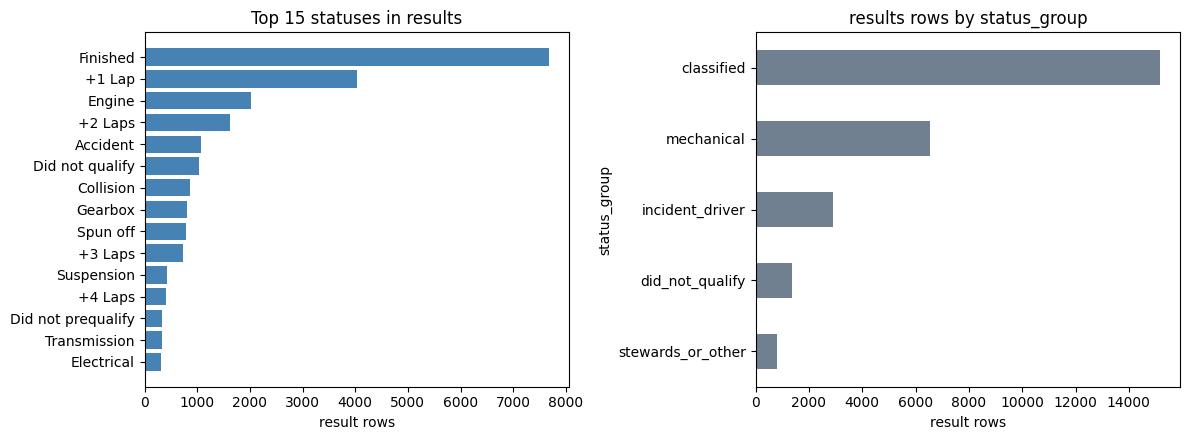

In [21]:
usage = results[["statusId"]].merge(status_eda, on="statusId", how="left")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

top = usage["status"].value_counts().head(15)
axes[0].barh(top.index, top.values, color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Top 15 statuses in results")
axes[0].set_xlabel("result rows")

usage["status_group"].value_counts().sort_values().plot(kind="barh", ax=axes[1], color="slategray")
axes[1].set_title("results rows by status_group")
axes[1].set_xlabel("result rows")

plt.tight_layout()
plt.show()

In [22]:
status_clean = status_eda[["statusId", "status", "status_group"]].copy()
assert status_clean["statusId"].is_unique

status_clean.to_csv(CLEAN_DIR / "status_clean.csv", index=False)
print("saved:", CLEAN_DIR / "status_clean.csv", status_clean.shape)

log_audit("status", status, status_clean)

saved: /kaggle/working/cleaned/status_clean.csv (139, 3)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
status,139,139,2,3,0,0,0,1,2


**Status — conclusion**
- 139 unique labels, no `\N`, and every `statusId` used in `results` exists here.
- Hand taxonomy for DEQ3: `mechanical` = a **car component failed**. Labels that are not failed parts go elsewhere (`Stalled` / `Puncture` / `Tyre puncture` → `incident_driver`; `Underweight` / `Out of fuel` / `Fuel rig` / `Refuelling` → `stewards_or_other`). The `mechanical` fallback is only components (engine, gearbox, hydraulics, brakes, …).
- Usage in `results`: classified 15,161 (57%), mechanical 6,556, incident 2,890, did not qualify 1,365, stewards/other 787.
- `status_clean` (139 × 3) is a lookup table only. It is never a model feature.

## 1.3 `circuits`
Lookup table of tracks, one row per circuit. Used in **DEQ1** (front-row conversion by circuit) and **DEQ2** (home race = driver nationality matches the circuit's `country`).

**Checks:** keys unique, `\N` sentinels, link to `races`, value ranges, spelling of `country`.
**Leakage:** none. Circuit attributes are fixed before the race.

In [23]:
circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [24]:
circuits.head()

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [25]:
print("duplicate circuitId:", circuits["circuitId"].duplicated().sum())
print("duplicate circuitRef:", circuits["circuitRef"].duplicated().sum())
print("literal \\N cells:", count_literal_N(circuits))

used, known = set(races["circuitId"]), set(circuits["circuitId"])
print("circuits never raced on:", len(known - used))
print("races with unknown circuitId (FK orphans):", len(used - known))
print("alt range:", circuits["alt"].min(), "→", circuits["alt"].max(), "m")


duplicate circuitId: 0
duplicate circuitRef: 0
literal \N cells: 0
circuits never raced on: 0
races with unknown circuitId (FK orphans): 0
alt range: -7 → 2227 m


**Issue found:** the US is spelled two ways. Las Vegas Strip (id 80, added in 2023) is `"United States"`, while the other 11 US circuits are `"USA"`. Left as is, DEQ2 would split American home races into two countries. **Fix:** map it to `"USA"`.

**Other decisions:** drop `url` (no signal). Keep `circuitRef`, `name` and `location` for readable plots and merges, and `lat`/`lng`/`alt` as static track descriptors. Altitude runs from −7 m (Baku, really below sea level) to 2227 m (Mexico City). Both are real, so there are no outliers to fix.

In [26]:
circuits.loc[circuits["country"].isin(["USA", "United States"]), ["circuitId", "name", "location", "country"]]

,circuitId,name,location,country
18,19,Indianapolis Motor Speedway,Indianapolis,USA
22,80,Las Vegas Strip Street Circuit,Las Vegas,United States
32,33,Phoenix street circuit,Phoenix,USA
36,37,Detroit Street Circuit,Detroit,USA
41,42,Fair Park,Dallas,USA
42,43,Long Beach,California,USA
43,44,Las Vegas Street Circuit,Nevada,USA
45,46,Watkins Glen,New York State,USA
59,60,Riverside International Raceway,California,USA
62,63,Sebring International Raceway,Florida,USA


In [27]:
lv = circuits.loc[
    circuits["circuitRef"].isin(["vegas", "las_vegas"]),
    ["circuitId", "circuitRef", "name", "location", "country", "lat", "lng", "alt"],
]
display(lv)

a, b = lv.iloc[0], lv.iloc[1]
print("delta lat:", round(a.lat - b.lat, 6))
print("delta lng:", round(a.lng - b.lng, 6))
print("delta alt (m):", a.alt - b.alt)

,circuitId,circuitRef,name,location,country,lat,lng,alt
22,80,vegas,Las Vegas Strip Street Circuit,Las Vegas,United States,36.1147,-115.173,642
43,44,las_vegas,Las Vegas Street Circuit,Nevada,USA,36.1162,-115.174,639


delta lat: -0.0015
delta lng: 0.001
delta alt (m): 3


In [28]:
lv_ids = circuits.loc[circuits["circuitRef"].isin(["vegas", "las_vegas"]), "circuitId"]
races.loc[races["circuitId"].isin(lv_ids), ["raceId", "year", "name", "circuitId", "date"]].sort_values("year")

,raceId,year,name,circuitId,date
496,497,1981,Caesars Palace Grand Prix,44,1981-10-17
481,482,1982,Caesars Palace Grand Prix,44,1982-09-25
1099,1119,2023,Las Vegas Grand Prix,80,2023-11-19
1122,1142,2024,Las Vegas Grand Prix,80,2024-11-23


In [29]:
COUNTRY_FIX = {"United States": "USA"}

circuits_clean = (
    circuits
    .drop(columns=["url"])
    .assign(country=lambda d: d["country"].str.strip().replace(COUNTRY_FIX))
)

assert circuits_clean["circuitId"].is_unique
print("countries before:", circuits["country"].nunique(), "| after:", circuits_clean["country"].nunique())

countries before: 35 | after: 34


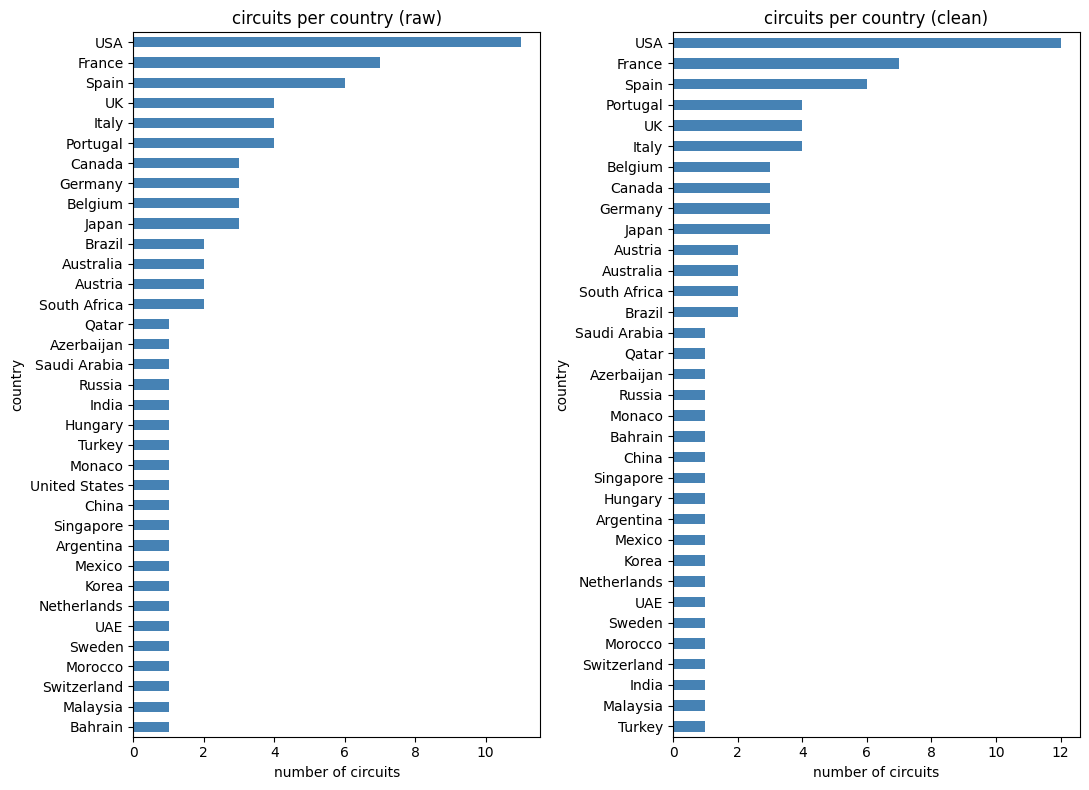

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 8))
for ax, df, label in [(axes[0], circuits, "raw"), (axes[1], circuits_clean, "clean")]:
    df["country"].value_counts().sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"circuits per country ({label})")
    ax.set_xlabel("number of circuits")
plt.tight_layout()
plt.show()

count    77.000000
mean     14.610390
std      16.833672
min       1.000000
25%       3.000000
50%       8.000000
75%      20.000000
max      74.000000
dtype: float64
circuits with < 5 races: 29


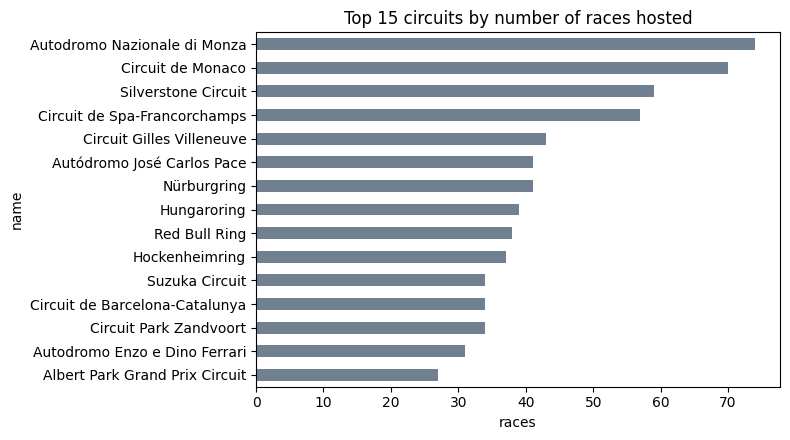

In [31]:
races_per_circuit = (
    races[["raceId", "circuitId"]].merge(circuits_clean[["circuitId", "name"]], on="circuitId")
    .groupby("name").size()
    .sort_values()
)
print(races_per_circuit.describe())
print("circuits with < 5 races:", (races_per_circuit < 5).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
races_per_circuit.tail(15).plot(kind="barh", ax=ax, color="slategray")
ax.set_title("Top 15 circuits by number of races hosted")
ax.set_xlabel("races")
plt.tight_layout()
plt.show()

In [32]:
circuits_clean.to_csv(CLEAN_DIR / "circuits_clean.csv", index=False)
print("saved:", CLEAN_DIR / "circuits_clean.csv", circuits_clean.shape)
log_audit("circuits", circuits, circuits_clean)

saved: /kaggle/working/cleaned/circuits_clean.csv (77, 8)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
circuits,77,77,9,8,0,0,0,5,4


**Circuits - conclusion**
- 77 circuits, no `\N`, `circuitId` and `circuitRef` unique, every circuit used by `races`, and no race points to a missing circuit.
- One real fix: `"United States"` → `"USA"` (35 → 34 countries), which DEQ2 needs. `url` dropped → `circuits_clean` is 77 × 8.
- Usage is very skewed: median 8 races per circuit, max 74 (Monza), and **29 circuits hosted fewer than 5 races**. In **DEQ1** we only rank circuits with enough front-row starts, because a rate from 1–4 races is noise.
- The Indianapolis Motor Speedway (id 19) hosted both the Indy 500 (1950–60) and the normal US GP (2000–07). So the Indy 500 is flagged **on `races` by race name** (1.6), not by `circuitId`.

## 1.4 `constructors`
Lookup table of teams, one row per `constructorId`. Used in **DEQ3** (retirement rate per team) and as the key for constructor form and standings features.

**Leakage:** none (static attributes).

In [33]:
constructors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


In [34]:
constructors.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [35]:
print("duplicate constructorId:", constructors["constructorId"].duplicated().sum())
print("duplicate constructorRef:", constructors["constructorRef"].duplicated().sum())
print("duplicate name:", constructors["name"].duplicated().sum())
print("literal \\N cells:", count_literal_N(constructors))
print("constructors never in results:",
      constructors.loc[~constructors["constructorId"].isin(results["constructorId"]), ["constructorId", "name"]].values.tolist())
print("results with unknown constructorId (FK orphans):",
      (~results["constructorId"].isin(constructors["constructorId"])).sum())

duplicate constructorId: 0
duplicate constructorRef: 0
duplicate name: 0
literal \N cells: 0
constructors never in results: [[88, 'Eagle']]
results with unknown constructorId (FK orphans): 0


**Team identity drift (F1 primer):** when a team is sold or renamed it gets a **new** `constructorId`. For example, one Enstone team appears as Toleman → Benetton → Renault → Lotus F1 → Alpine:

In [36]:
# one team, five names: each rename is a new constructorId
constructors[constructors["constructorRef"].isin(["toleman", "benetton", "renault", "lotus_f1", "alpine"])][
    ["constructorId", "constructorRef", "name", "nationality"]
]

,constructorId,constructorRef,name,nationality
3,4,renault,Renault,French
21,22,benetton,Benetton,Italian
51,53,toleman,Toleman,British
205,208,lotus_f1,Lotus F1,British
210,214,alpine,Alpine F1 Team,French


**Decision:** we do **not** merge renamed teams by hand. There is no reliable rule for when a rename is "the same team" (ownership, staff and factory change at different times), and the primer says to accept that renames reset history. Constructor form and standings therefore follow `constructorId`. Limitation: the first races after a rename start with no team history.

Drop `url` and `constructorRef` (`constructorId` is the key, `name` is kept for readability), keep `nationality`.

In [37]:
constructors_clean = constructors.drop(columns=["url", "constructorRef"])
assert constructors_clean["constructorId"].is_unique
constructors_clean.head()

,constructorId,name,nationality
0,1,McLaren,British
1,2,BMW Sauber,German
2,3,Williams,British
3,4,Renault,French
4,5,Toro Rosso,Italian


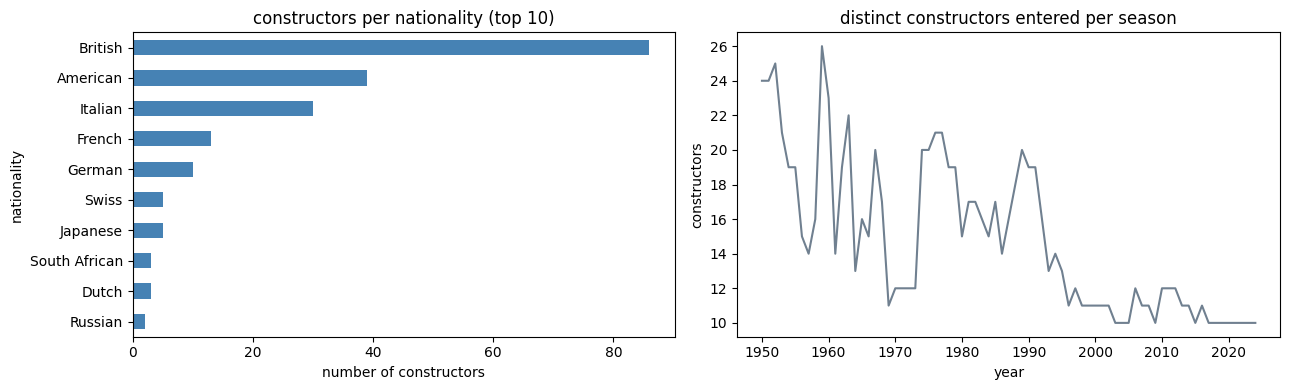

constructors active in only 1 season: 70 / 211
teams per season: min 10 | max 26 | 2024: 10


In [38]:
entries = results[["raceId", "constructorId"]].merge(races[["raceId", "year"]], on="raceId")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
constructors_clean["nationality"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("constructors per nationality (top 10)")
axes[0].set_xlabel("number of constructors")

entries.groupby("year")["constructorId"].nunique().plot(ax=axes[1], color="slategray")
axes[1].set_title("distinct constructors entered per season")
axes[1].set_ylabel("constructors")
plt.tight_layout()
plt.show()

seasons_active = entries.groupby("constructorId")["year"].nunique()
print("constructors active in only 1 season:", (seasons_active == 1).sum(), "/", len(seasons_active))
print("teams per season: min", entries.groupby("year")["constructorId"].nunique().min(),
      "| max", entries.groupby("year")["constructorId"].nunique().max(),
      "| 2024:", entries.loc[entries["year"] == 2024, "constructorId"].nunique())

In [39]:
constructors_clean.to_csv(CLEAN_DIR / "constructors_clean.csv", index=False)
print("saved:", CLEAN_DIR / "constructors_clean.csv", constructors_clean.shape)
log_audit("constructors", constructors, constructors_clean)

saved: /kaggle/working/cleaned/constructors_clean.csv (212, 3)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
constructors,212,212,5,3,0,0,0,4,2


**Constructors — conclusion**
- 212 constructors, no `\N`, `constructorId`, `constructorRef` and `name` all unique, and every `results.constructorId` exists here. One constructor (id 88, "Eagle") has no results rows. It is harmless, so we keep it.
- British teams make up 41% of all constructors (86 / 212).
- The field was large and unstable: up to 26 teams in a season, and **70 of 211 constructors raced in only one season** (privateers and one-off entries). Today it is 10 teams. This is the primer's "oversized, uneven fields" effect. It lowers the podium base rate in older eras, and it means many constructors have almost no history for form features.
- Renames create new ids, so team history resets. This is accepted and documented, not patched.
- `constructors_clean`: 212 × 3 (`constructorId`, `name`, `nationality`)

## 1.5 `drivers`
Lookup table of drivers, one row per `driverId`. Used in **DEQ2** (nationality → home country) and for pre-race driver attributes (e.g. age at the race, from `dob`).

**Leakage:** none. Date of birth and nationality are known before the race.

In [40]:
drivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   driverId     861 non-null    int64 
 1   driverRef    861 non-null    object
 2   number       861 non-null    object
 3   code         861 non-null    object
 4   forename     861 non-null    object
 5   surname      861 non-null    object
 6   dob          861 non-null    object
 7   nationality  861 non-null    object
 8   url          861 non-null    object
dtypes: int64(1), object(8)
memory usage: 60.7+ KB


In [41]:
drivers.head()

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


In [42]:
print("duplicate driverId:", drivers["driverId"].duplicated().sum())
print("duplicate driverRef:", drivers["driverRef"].duplicated().sum())
print("duplicate forename+surname:", drivers.duplicated(["forename", "surname"]).sum())
print("\\N per column:", {c: int((drivers[c] == r"\N").sum()) for c in drivers.columns if (drivers[c] == r"\N").any()})
print("reused numbers:", drivers.loc[drivers["number"] != r"\N", "number"].duplicated().sum(),
      "| reused codes:", drivers.loc[drivers["code"] != r"\N", "code"].duplicated().sum())
print("nationalities with stray spaces:", [n for n in drivers["nationality"].unique() if n != n.strip()])
print("results with unknown driverId (FK orphans):", (~results["driverId"].isin(drivers["driverId"])).sum())

duplicate driverId: 0
duplicate driverRef: 0
duplicate forename+surname: 0
\N per column: {'number': 802, 'code': 757}
reused numbers: 11 | reused codes: 7
nationalities with stray spaces: ['Argentinian ']
results with unknown driverId (FK orphans): 0


In [43]:
# number / code are not keys: the same value is reused by drivers of different eras
reused = drivers[(drivers["code"] != r"\N") & drivers["code"].duplicated(keep=False)]
reused.sort_values("code")[["driverId", "code", "number", "forename", "surname", "dob"]].head(8)

,driverId,code,number,forename,surname,dob
26,27,ALB,\N,Christijan,Albers,1979-04-16
846,848,ALB,23,Alexander,Albon,1996-03-23
375,376,BIA,\N,Lucien,Bianchi,1934-11-10
823,824,BIA,17,Jules,Bianchi,1989-08-03
37,38,DOO,\N,Robert,Doornbos,1981-09-23
860,862,DOO,61,Jack,Doohan,2003-01-20
836,837,HAR,88,Rio,Haryanto,1993-01-22
841,843,HAR,28,Brendon,Hartley,1989-11-10


**Findings**
- `\N` in `number` (802 of 861) and `code` (757). Permanent race numbers (2014+) and 3-letter codes are modern practice, so this is **structurally missing**, not an error (plot below).
- `number` and `code` are **not** keys: 11 numbers and 7 codes are reused (e.g. `ALB` = Christijan Albers *and* Alexander Albon). Only `driverId` and `driverRef` are unique.
- `dob` is stored as text → convert to a datetime (needed for age at the race).
- `nationality` contains `"Argentinian "` (trailing space), while other Argentine drivers are `"Argentine"`. One country, two spellings.

**Decisions:** `\N` → NA, `number` → nullable integer, `dob` → datetime, strip and unify `nationality`, add `full_name` for plots, drop `url`. `number` and `code` stay in the table for readability, but they are not features.


In [44]:
NATIONALITY_FIX = {"Argentinian": "Argentine"}

drivers_clean = strip_sentinels(drivers).drop(columns=["url"])
drivers_clean = to_numeric_checked(drivers_clean, ["number"])
drivers_clean["number"] = drivers_clean["number"].astype("Int64")
drivers_clean["dob"] = pd.to_datetime(drivers_clean["dob"], format="%Y-%m-%d")
drivers_clean["nationality"] = drivers_clean["nationality"].str.strip().replace(NATIONALITY_FIX)
drivers_clean["full_name"] = drivers_clean["forename"] + " " + drivers_clean["surname"]

assert drivers_clean["driverId"].is_unique
print("dob range:", drivers_clean["dob"].min().date(), "→", drivers_clean["dob"].max().date())
print("nationalities:", drivers["nationality"].nunique(), "→", drivers_clean["nationality"].nunique())
drivers_clean.dtypes

dob range: 1896-12-28 → 2005-05-08
nationalities: 43 → 42


driverId                int64
driverRef              object
number                  Int64
code                   object
forename               object
surname                object
dob            datetime64[ns]
nationality            object
full_name              object
dtype: object

**Home countries for DEQ2.** Driver nationality is an adjective ("British") and circuit country is a noun ("UK"), so we map one to the other by hand. Dual tags (e.g. `American-Italian`) keep **both** countries. Stored as one column `home_countries`: pipe-separated (`UK`, `Italy|USA`), never a Python `frozenset` and not a second `home_country` column. Only nationalities whose country hosted a race are mapped.


In [45]:
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia",
    "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chinese": "China",
    "Dutch": "Netherlands", "East German": "Germany", "French": "France",
    "German": "Germany", "Hungarian": "Hungary", "Indian": "India",
    "Italian": "Italy", "Japanese": "Japan", "Malaysian": "Malaysia",
    "Mexican": "Mexico", "Monegasque": "Monaco", "Portuguese": "Portugal",
    "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain",
    "Swedish": "Sweden", "Swiss": "Switzerland",
}

def home_countries(nationality: str) -> str:
    """Map nationality (incl. dual tags like American-Italian) to circuit countries.
    Returns a pipe-separated string for CSV (e.g. 'UK', 'Italy|USA'). Empty if none.
    """
    parts = [p.strip() for p in str(nationality).split("-")]
    countries = sorted(
        {NATIONALITY_TO_COUNTRY[p] for p in parts if p in NATIONALITY_TO_COUNTRY}
    )
    return "|".join(countries)

drivers_clean = drivers_clean.drop(columns=["home_country", "home_countries"], errors="ignore")
drivers_clean["home_countries"] = drivers_clean["nationality"].map(home_countries)

circuit_countries = set(circuits_clean["country"])
mapped = set()
for s in drivers_clean["home_countries"]:
    if s:
        mapped.update(s.split("|"))
assert mapped <= circuit_countries, f"mapped to a country with no circuit: {mapped - circuit_countries}"

no_home = sorted(
    drivers_clean.loc[drivers_clean["home_countries"] == "", "nationality"].unique()
)
print("nationalities with no home circuit (never a home race):", no_home)
print(
    "drivers with a possible home race:",
    (drivers_clean["home_countries"] != "").sum(), "/", len(drivers_clean),
)

# dual-nationality drivers and races where either home country can match
dual = drivers_clean[drivers_clean["nationality"].str.contains("-", na=False)]
dual_races = (
    results[results["driverId"].isin(dual["driverId"])][["raceId", "driverId"]]
    .merge(races[["raceId", "year", "name", "circuitId"]], on="raceId")
    .merge(circuits_clean[["circuitId", "country"]], on="circuitId")
    .merge(dual[["driverId", "full_name", "nationality", "home_countries"]], on="driverId")
)
dual_races["is_home"] = [
    c in h.split("|") for c, h in zip(dual_races["country"], dual_races["home_countries"])
]
display(dual_races[["full_name", "nationality", "home_countries", "year", "name", "country", "is_home"]])


nationalities with no home circuit (never a home race): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
drivers with a possible home race: 811 / 861


,full_name,nationality,home_countries,year,name,country,is_home
0,Alfonso Thiele,American-Italian,Italy|USA,1961,Italian Grand Prix,Italy,True
1,Alfonso Thiele,American-Italian,Italy|USA,1960,Italian Grand Prix,Italy,True
2,Alessandro de Tomaso,Argentine-Italian,Argentina|Italy,1959,United States Grand Prix,USA,False
3,Alessandro de Tomaso,Argentine-Italian,Argentina|Italy,1957,Argentine Grand Prix,Argentina,True


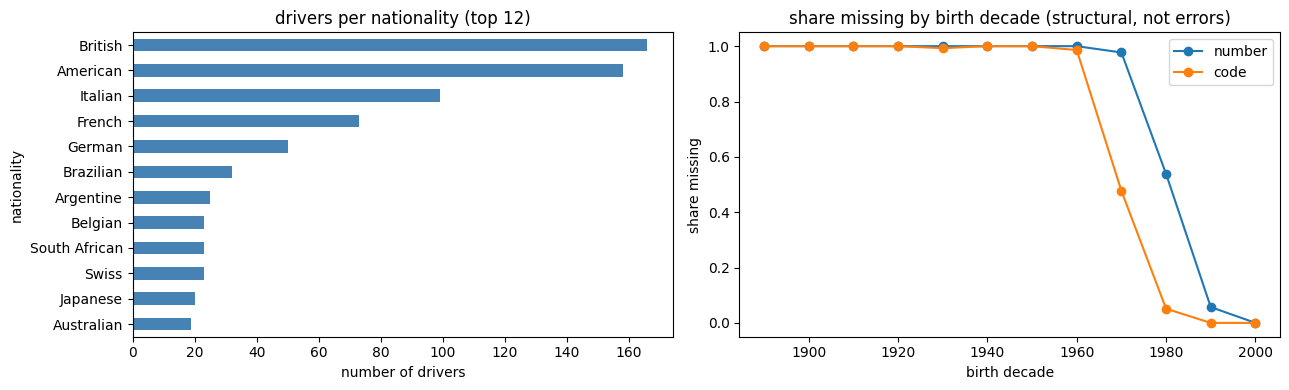

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

drivers_clean["nationality"].value_counts().head(12).sort_values().plot(
    kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("drivers per nationality (top 12)")
axes[0].set_xlabel("number of drivers")

birth_decade = (drivers_clean["dob"].dt.year // 10 * 10).rename("birth decade")
drivers_clean[["number", "code"]].isna().groupby(birth_decade).mean().plot(ax=axes[1], marker="o")
axes[1].set_title("share missing by birth decade (structural, not errors)")
axes[1].set_ylabel("share missing")
plt.tight_layout()
plt.show()

In [47]:
# one column only: pipe-separated home_countries (no frozenset, no duplicate home_country)
drivers_clean = drivers_clean.drop(columns=["home_country"], errors="ignore")
drivers_clean.to_csv(CLEAN_DIR / "drivers_clean.csv", index=False)
print("saved:", CLEAN_DIR / "drivers_clean.csv", drivers_clean.shape)
print("home_countries sample:", drivers_clean.loc[
    drivers_clean["nationality"].str.contains("-", na=False),
    ["full_name", "nationality", "home_countries"],
].to_string(index=False))
log_audit("drivers", drivers, drivers_clean)


saved: /kaggle/working/cleaned/drivers_clean.csv (861, 10)
home_countries sample:            full_name       nationality  home_countries
      Alfonso Thiele  American-Italian       Italy|USA
Alessandro de Tomaso Argentine-Italian Argentina|Italy


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
drivers,861,861,9,10,1559,0,1559,8,7


**Drivers - conclusion**
- `drivers_clean`: 861 rows, typed (`number` Int64, `dob` datetime), cleaned nationality, plus `full_name` and a single `home_countries` column (pipe-separated; dual tags keep both, e.g. `Italy|USA`).
- Missing `number`/`code` is structural (older eras). Do **not** impute; neither is a model feature.
- Dual tags keep **both** countries as home (Thiele → `Italy|USA`, de Tomaso → `Argentina|Italy`). 810/861 drivers can have a home race; the rest (e.g. Finnish, New Zealander) only appear as away in DEQ2. For modeling later, derive `is_home_race` from this column — do not feed the string raw to a model.


## 1.6 `races`
The race calendar, one row per Grand Prix. It is the **hub table**: it gives every result its `year`, `round`, `circuitId` and `date`, and it defines the season order that every lagged (leakage-safe) feature depends on.

**Leakage:** none. The calendar is known before the season.

In [48]:
races.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   raceId       1125 non-null   int64 
 1   year         1125 non-null   int64 
 2   round        1125 non-null   int64 
 3   circuitId    1125 non-null   int64 
 4   name         1125 non-null   object
 5   date         1125 non-null   object
 6   time         1125 non-null   object
 7   url          1125 non-null   object
 8   fp1_date     1125 non-null   object
 9   fp1_time     1125 non-null   object
 10  fp2_date     1125 non-null   object
 11  fp2_time     1125 non-null   object
 12  fp3_date     1125 non-null   object
 13  fp3_time     1125 non-null   object
 14  quali_date   1125 non-null   object
 15  quali_time   1125 non-null   object
 16  sprint_date  1125 non-null   object
 17  sprint_time  1125 non-null   object
dtypes: int64(4), object(14)
memory usage: 158.3+ KB


In [49]:
races.head()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


In [50]:
print("year range:", races["year"].min(), "→", races["year"].max(), "| round range:", races["round"].min(), "→", races["round"].max())
print("duplicate raceId:", races["raceId"].duplicated().sum())
print("duplicate (year, round):", races.duplicated(["year", "round"]).sum())
print("rounds contiguous 1..n every season:",
      races.groupby("year")["round"].apply(lambda r: sorted(r) == list(range(1, len(r) + 1))).all())
print("\\N per column:", {c: int((races[c] == r"\N").sum()) for c in races.columns if (races[c] == r"\N").any()})


year range: 1950 → 2024 | round range: 1 → 24
duplicate raceId: 0
duplicate (year, round): 0
rounds contiguous 1..n every season: True
\N per column: {'time': 731, 'fp1_date': 1035, 'fp1_time': 1057, 'fp2_date': 1035, 'fp2_time': 1057, 'fp3_date': 1053, 'fp3_time': 1072, 'quali_date': 1035, 'quali_time': 1057, 'sprint_date': 1107, 'sprint_time': 1110}


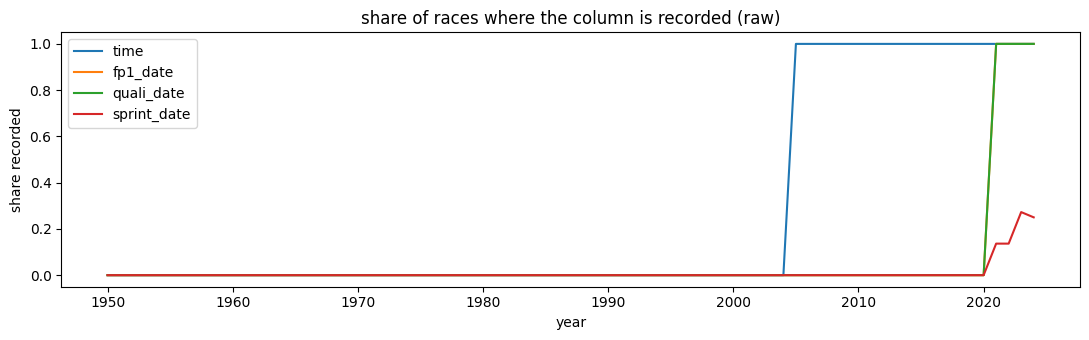

first year recorded: {'time': 2005, 'fp1_date': 2021, 'quali_date': 2021, 'sprint_date': 2021}


In [51]:
recorded = (races[["time", "fp1_date", "quali_date", "sprint_date"]] != r"\N").groupby(races["year"]).mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
recorded.plot(ax=ax)
ax.set_title("share of races where the column is recorded (raw)")
ax.set_ylabel("share recorded")
plt.tight_layout()
plt.show()
print("first year recorded:", {c: int(races.loc[races[c] != r"\N", "year"].min()) for c in recorded.columns})

**Missingness is structural:** the start `time` only exists from 2005, and all practice, qualifying and sprint session dates and times only from 2021. Before that, Ergast simply did not record them. They carry no pre-race signal for 95%+ of races, so they are **dropped, not imputed**.

In [52]:
# sprint_date vs sprint_time: which one defines a sprint weekend?
xor = races[(races["sprint_date"] == r"\N") ^ (races["sprint_time"] == r"\N")]
print("rows where only one of sprint_date / sprint_time is set:", len(xor))
display(xor[["raceId", "year", "name", "sprint_date", "sprint_time"]])

sprint_weekends_from_date = set(races.loc[races["sprint_date"] != r"\N", "raceId"])
sprint_weekends_actual = set(sprint_results["raceId"])
print("sprint weekends by sprint_date:", len(sprint_weekends_from_date),
      "| races with sprint_results:", len(sprint_weekends_actual),
      "| identical sets:", sprint_weekends_from_date == sprint_weekends_actual)

rows where only one of sprint_date / sprint_time is set: 3


,raceId,year,name,sprint_date,sprint_time
1046,1061,2021,British Grand Prix,2021-07-17,\N
1050,1065,2021,Italian Grand Prix,2021-09-11,\N
1055,1071,2021,São Paulo Grand Prix,2021-11-13,\N


sprint weekends by sprint_date: 18 | races with sprint_results: 18 | identical sets: True


**Sprint flag:** 3 races have a `sprint_date` but no `sprint_time`. They are the three 2021 sprint weekends (Britain, Italy, São Paulo), where only the start time is missing. So `sprint_date` is the reliable column, and its 18 races are **exactly** the 18 races that have `sprint_results`. We flag `is_sprint_weekend` from the races that have sprint results, which is the same set.

**Decisions**
- `date` → datetime and a `date`/`year` consistency check; `month` from `date`.
- `is_indy500` = race name is "Indianapolis 500". It is flagged **by name, not by circuit**, because the same track also hosted the normal US GP in 2000–07 (shown below). It is excluded later from the modeling table and from DEQ2 (F1 primer: a separate series in practice).
- `era`: the technical eras from the F1 primer, used for EDA and to check how results change across eras.
- `prev_raceId`: the previous round of the **same season**. Standings are published *after* each race, so "standings before race r" = the standings row of `prev_raceId`. This is how standings stay leakage-safe in 1.10 and 1.11. Round 1 has no previous race (NA).
- Drop `url`, `time` and the 10 session columns.

In [53]:
ERA_BINS = [1949, 1957, 1965, 1976, 1988, 1994, 2008, 2013, 2021, 2024]
ERA_LABELS = ["1950-57 front-engine", "1958-65 rear-engine", "1966-76 3-litre", "1977-88 turbo",
              "1989-94 post-turbo", "1995-2008 V10/V8", "2009-13 late V8", "2014-21 hybrid",
              "2022-24 ground-effect"]
SESSION_COLS = ["fp1_date", "fp1_time", "fp2_date", "fp2_time", "fp3_date", "fp3_time",
                "quali_date", "quali_time", "sprint_date", "sprint_time"]

races_typed = strip_sentinels(races)
races_typed["date"] = pd.to_datetime(races_typed["date"], format="%Y-%m-%d")
print("date/year mismatches:", (races_typed["date"].dt.year != races_typed["year"]).sum())

races_clean = races_typed.assign(
    month=races_typed["date"].dt.month,
    is_sprint_weekend=races_typed["raceId"].isin(sprint_results["raceId"]).astype(int),
    is_indy500=(races_typed["name"] == "Indianapolis 500").astype(int),
    era=pd.cut(races_typed["year"], bins=ERA_BINS, labels=ERA_LABELS).astype(str),
).drop(columns=["url", "time"] + SESSION_COLS)

# previous round of the same season -> used to lag standings (no leakage)
prev = races_clean[["raceId", "year", "round"]].assign(round=lambda d: d["round"] + 1)
races_clean = races_clean.merge(prev.rename(columns={"raceId": "prev_raceId"}), on=["year", "round"], how="left")
races_clean["prev_raceId"] = races_clean["prev_raceId"].astype("Int64")

assert races_clean["raceId"].is_unique
print("sprint weekends:", races_clean["is_sprint_weekend"].sum(), "| Indy 500 races:", races_clean["is_indy500"].sum(),
      "| round-1 races (no prev_raceId):", races_clean["prev_raceId"].isna().sum())
races_clean.head()


date/year mismatches: 0
sprint weekends: 18 | Indy 500 races: 11 | round-1 races (no prev_raceId): 75


,raceId,year,round,circuitId,name,date,month,is_sprint_weekend,is_indy500,era,prev_raceId
0,1,2009,1,1,Australian Grand Prix,2009-03-29,3,0,0,2009-13 late V8,<NA>
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,4,0,0,2009-13 late V8,1
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,4,0,0,2009-13 late V8,2
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,4,0,0,2009-13 late V8,3
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,5,0,0,2009-13 late V8,4


In [54]:
# why Indy is flagged by name: circuit 19 hosted two different events
races_clean[races_clean["circuitId"] == 19].groupby("name")["year"].agg(["min", "max", "count"])

,min,max,count
name,,,
Indianapolis 500,1950,1960,11
United States Grand Prix,2000,2007,8


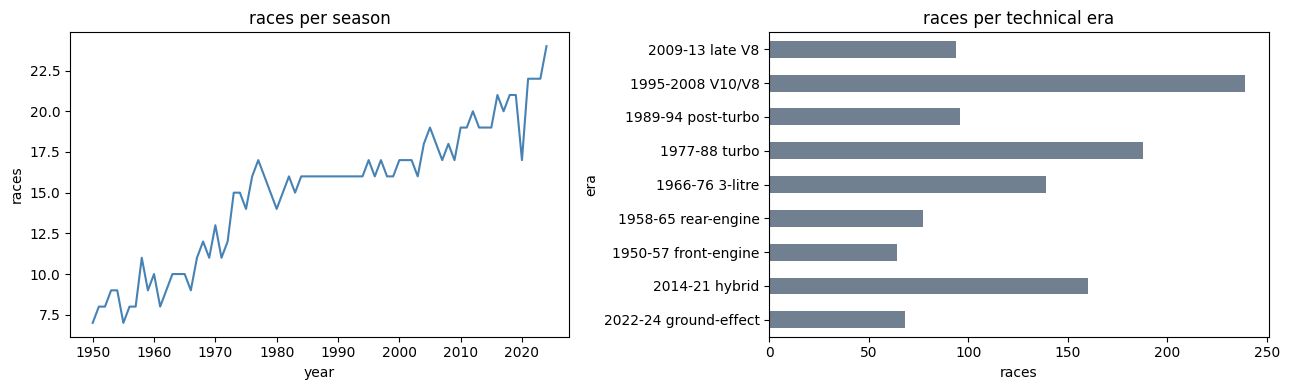

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

races_clean.groupby("year").size().plot(ax=axes[0], color="steelblue")
axes[0].set_title("races per season")
axes[0].set_ylabel("races")

races_clean.groupby("era", sort=False).size().plot(kind="barh", ax=axes[1], color="slategray")
axes[1].invert_yaxis()
axes[1].set_title("races per technical era")
axes[1].set_xlabel("races")
plt.tight_layout()
plt.show()

In [56]:
races_clean.to_csv(CLEAN_DIR / "races_clean.csv", index=False)
print("saved:", CLEAN_DIR / "races_clean.csv", races_clean.shape)
log_audit("races", races, races_clean)

saved: /kaggle/working/cleaned/races_clean.csv (1125, 11)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
races,1125,1125,18,11,11349,0,75,14,2


**Races — conclusion**
- 1,125 races, 1950–2024. `raceId` and `(year, round)` unique, rounds contiguous in every season, 0 date/year mismatches.
- All 11,349 `\N` cells are gone: they were all in `time` and the session columns, which are dropped because they are only recorded from 2005 / 2021.
- 18 sprint weekends (2021–24), and the flag matches `sprint_results` exactly. 11 Indy 500 races are flagged by name; circuit 19 also hosted 8 regular US GPs, which stay.
- Season length grew from 7 races (1950) to 24 (2024). So "races so far" means different things in different eras, and form features will use **rates or rolling windows**, not raw counts.
- `prev_raceId` exists for every race except the 75 season openers. It is the key that makes the lagged standings leakage-safe.

## 1.7 `results` (target table)
One row per driver per car per race. This is where the **target** comes from (`podium = positionOrder <= 3`), and where the only starting-order field available for all years (`grid`) lives.

**Column roles**
| Role | Columns |
|---|---|
| Keys | `resultId` (PK), `raceId`, `driverId`, `constructorId`, `statusId` |
| Pre-race (allowed) | `grid` (starting slot after penalties, `0` = no grid slot), `number` |
| Target source | `positionOrder`, always filled (`position` is `\N` for every non-classified driver, so it cannot be the target) |
| **Post-race (leakage)** | `position`, `positionText`, `points`, `laps`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`, `statusId` |

The post-race columns stay in `results_clean`: DEQ3 needs them, and they are the input for *lagged* form features (previous races only). They are **never** used as features for the race being predicted.

In [57]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [58]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [59]:
print("duplicate resultId:", results["resultId"].duplicated().sum())
print("duplicate (raceId, driverId):", results.duplicated(["raceId", "driverId"]).sum())
print("positionOrder missing:", results["positionOrder"].isna().sum())
for col, parent in [("raceId", races), ("driverId", drivers), ("constructorId", constructors), ("statusId", status)]:
    print(f"{col} not in parent table (FK orphans):", (~results[col].isin(parent[col])).sum())

duplicate resultId: 0
duplicate (raceId, driverId): 91
positionOrder missing: 0
raceId not in parent table (FK orphans): 0
driverId not in parent table (FK orphans): 0
constructorId not in parent table (FK orphans): 0
statusId not in parent table (FK orphans): 0


In [60]:
is_sentinel = results.astype(str) == r"\N"
col_counts = is_sentinel.sum()
col_counts = col_counts[col_counts > 0].sort_values(ascending=False)
sentinel_table = pd.DataFrame({"n": col_counts, "rate_%": (col_counts / len(results) * 100).round(1)})
display(sentinel_table)
print("total \\N cells:", int(col_counts.sum()))

,n,rate_%
milliseconds,19079,71.3
time,19079,71.3
fastestLapTime,18507,69.2
fastestLap,18507,69.2
fastestLapSpeed,18507,69.2
rank,18249,68.2
position,10953,40.9
number,6,0.0


total \N cells: 122887


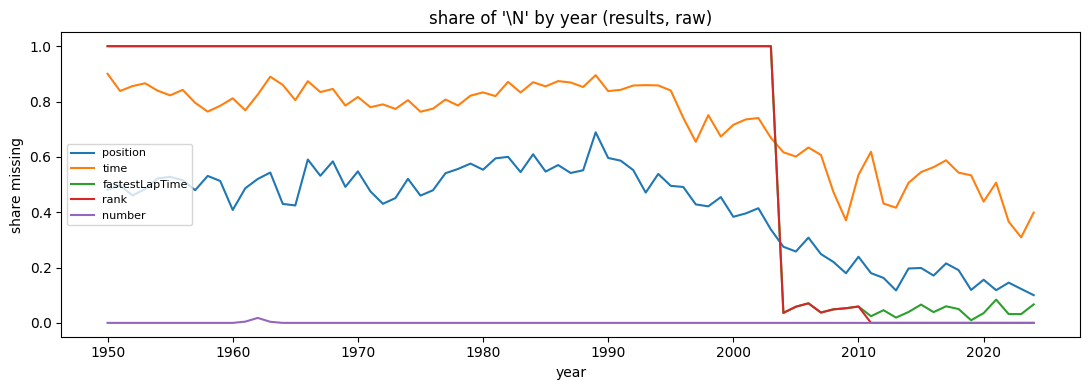

first year with a fastest-lap time: 2004


In [61]:
r = results.merge(races[["raceId", "year"]], on="raceId", how="left")
focus = ["position", "time", "fastestLapTime", "rank", "number"]
yearly = pd.concat([(r[c].astype(str) == r"\N").groupby(r["year"]).mean().rename(c) for c in focus], axis=1)

fig, ax = plt.subplots(figsize=(11, 4))
yearly.plot(ax=ax)
ax.set_title(r"share of '\N' by year (results, raw)")
ax.set_ylabel("share missing")
ax.legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()
print("first year with a fastest-lap time:", int(r.loc[r["fastestLapTime"] != r"\N", "year"].min()))

In [62]:
cols = ["position", "time", "milliseconds", "fastestLapTime", "rank"]
flags = pd.DataFrame({c: results[c].astype(str) == r"\N" for c in cols})
# which columns are missing together (True = \N)
flags.groupby(cols).size().sort_values(ascending=False).head(8).reset_index(name="n")

,position,time,milliseconds,fastestLapTime,rank,n
0,True,True,True,True,True,9501
1,False,True,True,True,True,5366
2,False,False,False,False,False,4265
3,False,False,False,True,True,3382
4,False,True,True,False,False,2756
5,True,True,True,False,False,1228
6,True,True,True,True,False,219
7,False,False,False,True,False,28


In [63]:
tmp = results.merge(status_clean, on="statusId", how="left")
tmp["position_missing"] = tmp["position"] == r"\N"
tmp["time_missing"] = tmp["time"] == r"\N"
(
    tmp.groupby("status")
    .agg(n=("statusId", "size"), position_missing=("position_missing", "mean"), time_missing=("time_missing", "mean"))
    .sort_values("n", ascending=False)
    .head(12)
    .round(3)
)

,n,position_missing,time_missing
status,,,
Finished,7674,0.000,0.0
+1 Lap,4037,0.000,1.0
Engine,2026,0.931,1.0
+2 Laps,1613,0.001,1.0
Accident,1062,0.929,1.0
Did not qualify,1025,1.000,1.0
Collision,854,0.944,1.0
Gearbox,810,0.956,1.0
Spun off,795,0.948,1.0


**Missingness is structural, not random**
- **`position` (41%)** is `\N` exactly when the driver was **not classified**: Engine 93%, Accident 93%, Did not qualify 100%, and 0% for `Finished` / `+N Laps`. It means "no official position", so it must not be imputed. This is also why the target uses `positionOrder`.
- **`time` / `milliseconds` (71%)** exist only for drivers who finished **on the lead lap**: 0% missing for `Finished`, 100% for every `+N Laps` and every retirement. We do **not** invent times for lapped cars.
- **Fastest-lap columns (~69%)** only exist from **2004**, when Ergast started recording them (see the plot), so they are missing for every earlier row.
- The column combinations confirm this: the 4 most common patterns are "nothing recorded" (non-classified, pre-2004: 9,501), "classified but lapped, pre-2004" (5,366), "everything recorded" (4,265) and "lead lap, pre-2004" (3,382).
- All of these columns are post-race, so their missingness never reaches the model. It matters only for EDA and DEQ3.

rows with grid == 0: 1638


grid0_type,did not start (F/W),pit-lane start,All
result_code,,,
D,0,6,6
E,0,7,7
F,1348,0,1348
R,0,14,14
W,203,0,203
numeric (classified),0,60,60
All,1551,87,1638


,count,mean,50%,max
grid0_type,,,,
did not start (F/W),1551.0,0.000000,0.0,0.0
pit-lane start,87.0,43.724138,52.0,78.0


rows
grid0_type          status                  
did not start (F/W) Did not qualify     1013
                    Did not prequalify   331
                    Withdrew             164
                    Accident              18
pit-lane start      +1 Lap                27
                    Finished              22
                    +2 Laps                7
                    Disqualified           6

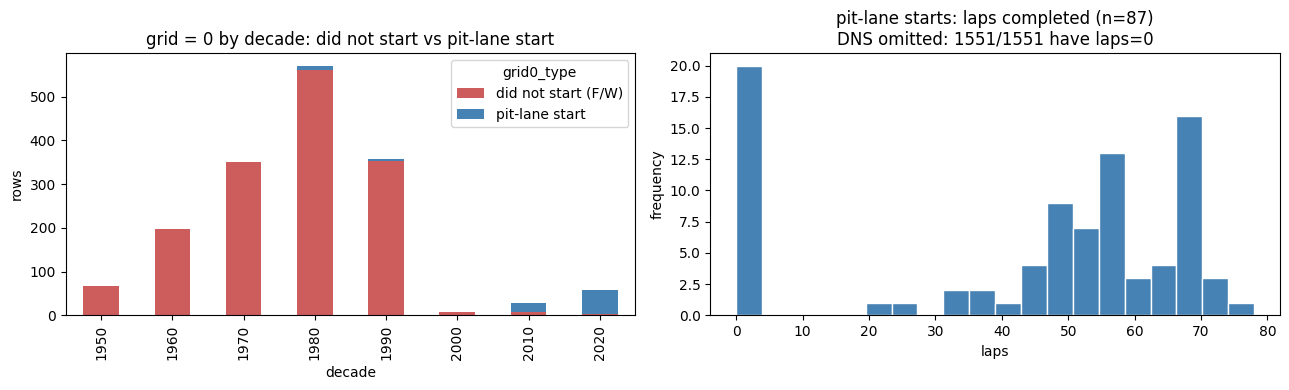

In [64]:
g0_raw = (
    results[results["grid"] == 0]
    .merge(status, on="statusId", how="left")
    .merge(races[["raceId", "year", "name"]], on="raceId", how="left")
)
g0_raw["grid0_type"] = np.where(
    g0_raw["positionText"].isin(["F", "W"]),
    "did not start (F/W)",
    "pit-lane start",
)
g0_raw["result_code"] = np.where(
    g0_raw["positionText"].str.isdigit(),
    "numeric (classified)",
    g0_raw["positionText"],
)

print("rows with grid == 0:", len(g0_raw))
display(pd.crosstab(g0_raw["result_code"], g0_raw["grid0_type"], margins=True))
display(g0_raw.groupby("grid0_type")["laps"].describe()[["count", "mean", "50%", "max"]])
display(
    g0_raw.groupby("grid0_type")["status"].value_counts().groupby(level=0).head(4).to_frame("rows")
)

# DNS are almost all laps==0 (~1500), so an overlay hist hides pit-lane starters.
# Left: decade mix. Right: laps hist for pit-lane only; DNS summarised in the title.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(
    g0_raw.groupby([g0_raw["year"] // 10 * 10, "grid0_type"]).size()
    .unstack(fill_value=0)
    .plot(kind="bar", stacked=True, ax=axes[0], color=["indianred", "steelblue"])
)
axes[0].set_title("grid = 0 by decade: did not start vs pit-lane start")
axes[0].set_xlabel("decade")
axes[0].set_ylabel("rows")

dns = g0_raw[g0_raw["grid0_type"] == "did not start (F/W)"]
pit = g0_raw.loc[g0_raw["grid0_type"] == "pit-lane start", "laps"]
dns_at_zero = int((dns["laps"] == 0).sum())
pit.plot(kind="hist", bins=20, ax=axes[1], color="steelblue", edgecolor="white")
axes[1].set_title(
    f"pit-lane starts: laps completed (n={len(pit)})\n"
    f"DNS omitted: {dns_at_zero}/{len(dns)} have laps=0"
)
axes[1].set_xlabel("laps")
axes[1].set_ylabel("frequency")

plt.tight_layout()
plt.show()


`\N` → NA, then numbers become numbers and durations become seconds:
- `milliseconds` already holds each lead-lap finisher's **total** race time → `race_time_s`. The text `time` column mixes two formats (`1:34:50.616` for the winner, `+5.478` gaps for the rest), so it is dropped.
- `fastestLapTime` (`M:SS.mmm`) → `fastestLapTime_s`.

**Data error found (2024 Belgian GP, raceId 1134):** George Russell crossed the line first and was disqualified after the race. Ergast left every other driver's `milliseconds` as the **gap to Russell** (Hamilton: 526 ms = +0.526 s) instead of a total time. A general check flags it: any time below 50% of the slowest classified time in the same race cannot be a total. It finds 18 rows, all in this race. **Fix:** add Russell's total (4,797,566 ms) back. Hamilton becomes 1:19:58.092, the official winning time. The target is unaffected, because `positionOrder` already has Hamilton P1.

In [65]:
results_typed = strip_sentinels(results)
results_typed = to_numeric_checked(
    results_typed, ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapSpeed"]
)
for c in ["number", "position", "fastestLap", "rank"]:
    results_typed[c] = results_typed[c].astype("Int64")

# a total race time far below the slowest classified time in the same race is a gap, not a total
race_max = results_typed.groupby("raceId")["milliseconds"].transform("max")
suspect = results_typed["milliseconds"] < 0.5 * race_max
print("suspect race times:", suspect.sum(), "in races", sorted(results_typed.loc[suspect, "raceId"].unique()))

# 2024 Belgian GP (raceId 1134): road winner Russell was disqualified; the others hold their gap to him
BELGIUM_2024 = 1134
ref_ms = results_typed.loc[(results_typed["raceId"] == BELGIUM_2024) & (results_typed["positionText"] == "D"),
                           "milliseconds"].iloc[0]
results_typed.loc[suspect & (results_typed["raceId"] == BELGIUM_2024), "milliseconds"] += ref_ms
race_max = results_typed.groupby("raceId")["milliseconds"].transform("max")
assert not (results_typed["milliseconds"] < 0.5 * race_max).any()

results_typed["race_time_s"] = results_typed["milliseconds"] / 1000
results_typed["fastestLapTime_s"] = results_typed["fastestLapTime"].map(parse_lap_time_to_seconds)

# every non-missing fastest lap parsed, and milliseconds present exactly where time is
assert results_typed["fastestLapTime_s"].notna().sum() == (results["fastestLapTime"] != r"\N").sum()
assert (results_typed["milliseconds"].isna() == results_typed["time"].isna()).all()
results_typed = results_typed.drop(columns=["time", "milliseconds", "fastestLapTime"])

print(results_typed[["race_time_s", "fastestLapTime_s", "fastestLapSpeed"]].describe().round(1))


suspect race times: 18 in races [np.int64(1134)]
       race_time_s  fastestLapTime_s  fastestLapSpeed
count       7680.0            8252.0           8252.0
mean        6197.1              90.8            204.1
std         1643.9              12.3             21.4
min          207.1              55.4             89.5
25%         5378.5              80.8            193.3
50%         5788.2              90.3            204.9
75%         6402.7              99.5            217.3
max        15090.5             202.3            257.3


In [66]:
results_typed = results_typed.merge(status_clean, on="statusId", how="left")
results_typed["podium"] = (results_typed["positionOrder"] <= 3).astype(int)
results_typed["did_not_start"] = results_typed["positionText"].isin(["F", "W"])   # failed to qualify / withdrew
results_typed["is_pit_start"] = (results_typed["grid"] == 0) & ~results_typed["did_not_start"]

print("podium rate (raw rows):", round(results_typed["podium"].mean(), 4))
print("did_not_start:", results_typed["did_not_start"].sum(), "| is_pit_start:", results_typed["is_pit_start"].sum())

podium rate (raw rows): 0.1269
did_not_start: 1704 | is_pit_start: 87


### Shared drives (duplicate `(raceId, driverId)` rows)

In [67]:
dups = results_typed[results_typed.duplicated(["raceId", "driverId"], keep=False)]
print("rows in duplicated pairs:", len(dups), "| pairs:", dups[["raceId", "driverId"]].drop_duplicates().shape[0],
      "| extra rows:", results_typed.duplicated(["raceId", "driverId"]).sum())
dup_years = dups.merge(races_clean[["raceId", "year"]], on="raceId")["year"]
print("years:", dup_years.min(), "→", dup_years.max(), "| pairs with a different constructor:",
      (dups.groupby(["raceId", "driverId"])["constructorId"].nunique() > 1).sum())
dups.sort_values(["raceId", "driverId"])[
    ["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "laps", "points"]].head(8)

rows in duplicated pairs: 176 | pairs: 85 | extra rows: 91
years: 1950 → 1978 | pairs with a different constructor: 16


,resultId,raceId,driverId,constructorId,grid,positionOrder,laps,points
13188,13189,540,229,54,0,26,0,0.0
13191,13192,540,229,57,0,29,0,0.0
17362,17363,717,373,172,1,7,102,0.0
24298,24304,717,373,172,1,12,54,0.0
17740,17741,733,465,172,0,22,0,0.0
17743,17744,733,465,97,0,25,0,0.0
17961,17962,742,475,102,20,19,56,0.0
17963,17964,742,475,172,5,21,44,0.0


**Shared drives:** 85 `(raceId, driverId)` pairs have 2 rows (91 extra rows), 1950–1978. One driver drove two cars in one race, in 16 cases for two different constructors (F1 primer: until 1957 drivers could hand over or take over a car mid-race).

**Rule: keep one row per `(raceId, driverId)`:**
1. the **lowest `positionOrder`**: the best result the driver achieved in that race, which is exactly what the podium label asks about
2. then **more `laps`**: the car the driver drove longer
3. then the **lowest `resultId`**: a deterministic last tie-break

The primer's alternative, "the car the driver started in (non-zero grid)", is not decisive here: in most pairs both rows have a grid slot, or both have none. Best result is defined for every pair.

In [68]:
results_clean = (
    results_typed
    .sort_values(["raceId", "driverId", "positionOrder", "laps", "resultId"],
                 ascending=[True, True, True, False, True])
    .drop_duplicates(["raceId", "driverId"], keep="first")
    .sort_values("resultId")
    .reset_index(drop=True)
)
assert not results_clean.duplicated(["raceId", "driverId"]).any()
print("rows:", len(results_typed), "→", len(results_clean))

podiums_per_race = pd.DataFrame({
    "before dedup": results_typed.groupby("raceId")["podium"].sum().value_counts(),
    "after dedup": results_clean.groupby("raceId")["podium"].sum().value_counts(),
}).fillna(0).astype(int)
podiums_per_race.index.name = "podium rows per race"
podiums_per_race

rows: 26759 → 26668


,before dedup,after dedup
podium rows per race,,
3,1107,1107
4,16,16
5,1,2
7,1,0


In [69]:
# 1956 British GP: drivers 606 and 581 shared car #4 -> both P2
(results_clean.loc[results_clean["raceId"] == 789, ["driverId", "constructorId", "number", "grid", "positionOrder", "points"]].sort_values("positionOrder").head(5))

,driverId,constructorId,number,grid,positionOrder,points
18959,579,6,1,2,1,8.0
18960,606,6,4,12,2,3.0
20188,581,6,4,12,2,3.0
18961,554,105,8,13,3,4.0
18962,486,125,21,21,4,3.0


After the dedup, 18 races (all 1950–1960) still have 4–5 podium rows. This is **correct**: when two drivers *shared one car*, Ergast gives both the same `positionOrder`. In the 1956 British GP, drivers 606 and 581 are both P2 with car #4 and split the points. Both really earned that podium, so both keep `podium = 1`.

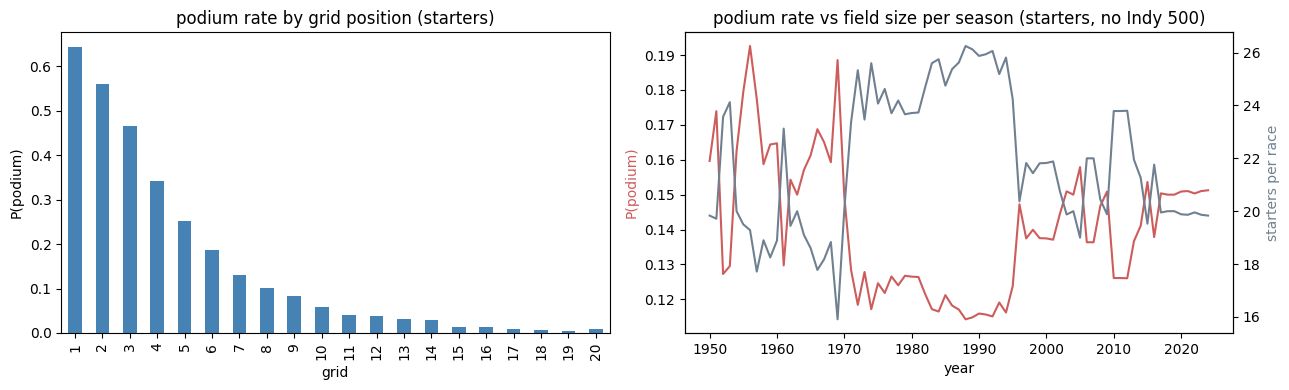

{1: 0.644, 2: 0.56, 3: 0.466, 4: 0.343, 5: 0.252, 6: 0.187, 7: 0.131, 8: 0.1, 9: 0.083, 10: 0.059}


In [70]:
starters = results_clean[~results_clean["did_not_start"] & results_clean["grid"].between(1, 20)]
rate_by_grid = starters.groupby("grid")["podium"].mean()

eras = results_clean[~results_clean["did_not_start"]].merge(races_clean[["raceId", "year", "is_indy500"]], on="raceId")
eras = eras[eras["is_indy500"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rate_by_grid.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("podium rate by grid position (starters)")
axes[0].set_ylabel("P(podium)")

field = eras.groupby("raceId").agg(year=("year", "first"), starters=("driverId", "size"))
ax2 = axes[1]
eras.groupby("year")["podium"].mean().plot(ax=ax2, color="indianred", label="podium rate")
ax2.set_ylabel("P(podium)", color="indianred")
ax3 = ax2.twinx()
field.groupby("year")["starters"].mean().plot(ax=ax3, color="slategray", label="starters per race")
ax3.set_ylabel("starters per race", color="slategray")
ax2.set_title("podium rate vs field size per season (starters, no Indy 500)")
plt.tight_layout()
plt.show()
print(rate_by_grid.head(10).round(3).to_dict())

In [71]:
results_clean.to_csv(CLEAN_DIR / "results_clean.csv", index=False)
print("saved:", CLEAN_DIR / "results_clean.csv", results_clean.shape)
log_audit("results", results, results_clean)

saved: /kaggle/working/cleaned/results_clean.csv (26668, 22)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
results,26759,26668,18,22,122887,0,103272,9,3


**Results — conclusion**
- Keys: `resultId` unique, `positionOrder` never missing, every FK (`raceId`, `driverId`, `constructorId`, `statusId`) exists in its parent table.
- **Sentinels and types:** all 122,887 `\N` cells → NA. Numbers are numeric, race and fastest-lap times are in seconds, and the text `time` is dropped. The missing values that remain are **structural** (not classified, lapped, or before 2004), and all of them are in post-race columns.
- **Data error fixed:** 2024 Belgian GP times were stored as gaps to the disqualified Russell. 18 rows were repaired and checked against the official winning time.
- **Grain:** 85 shared-drive pairs → 91 rows removed (26,759 → 26,668) with the documented best-result rule, and `(raceId, driverId)` is now unique. The 4–5 podiums in 18 early races come from genuinely shared cars.
- **`grid = 0`:** 1,551 non-starters vs 87 pit-lane starters, split into `did_not_start` (1,704 rows in total, including 153 F/W rows that had a grid slot but did not start) and `is_pit_start`.
- **Evidence for features:** the podium rate falls steeply with grid position: pole 64%, P2 56%, P3 47%, P5 25%, P10 6%. That makes `grid` the strongest single pre-race signal. The per-season podium rate moves *against* field size (fewer starters → higher rate), which is why the base rate drifts by era.

## 1.8 `qualifying`
One row per driver per qualifying session: qualifying `position` (**before** grid penalties) and q1/q2/q3 lap times.

**Leakage:** allowed. Qualifying finishes before the race. For **DEQ1** we use `qualifying.position` when the question is about qualifying, and `results.grid` when it is about where the car actually started.

In [72]:
qualifying.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10494 non-null  object
 7   q2             10472 non-null  object
 8   q3             10448 non-null  object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [73]:
qualifying.head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [74]:
print("duplicate qualifyId:", qualifying["qualifyId"].duplicated().sum())
print("duplicate (raceId, driverId):", qualifying.duplicated(["raceId", "driverId"]).sum())
for col, parent in [("raceId", races), ("driverId", drivers), ("constructorId", constructors)]:
    print(f"{col} not in parent table (FK orphans):", (~qualifying[col].isin(parent[col])).sum())
q_keys = qualifying.set_index(["raceId", "driverId"]).index
print("qualifying rows without a results row:", (~q_keys.isin(results.set_index(["raceId", "driverId"]).index)).sum())

duplicate qualifyId: 0
duplicate (raceId, driverId): 0
raceId not in parent table (FK orphans): 0
driverId not in parent table (FK orphans): 0
constructorId not in parent table (FK orphans): 0
qualifying rows without a results row: 0


In [75]:
miss = pd.DataFrame({
    "\\N": [(qualifying[c] == r"\N").sum() for c in ["q1", "q2", "q3"]],
    "empty (read as NaN)": [qualifying[c].isna().sum() for c in ["q1", "q2", "q3"]],
}, index=["q1", "q2", "q3"])
miss["total_missing_%"] = ((miss.sum(axis=1)) / len(qualifying) * 100).round(1)
display(miss)

flags = pd.DataFrame({f"{c}_missing": (qualifying[c] == r"\N") | qualifying[c].isna() for c in ["q1", "q2", "q3"]})
display(flags.value_counts().reset_index(name="n"))

times = qualifying[["q1", "q2", "q3"]].stack()
bad = times[(times != r"\N") & ~times.str.match(r"^\d+:\d{2}\.\d{3}$")]
print("time strings that are not M:SS.mmm:", len(bad))

,\N,empty (read as NaN),total_missing_%
q1,156,0,1.5
q2,4625,22,44.3
q3,6819,46,65.4


,q1_missing,q2_missing,q3_missing,n
0,False,True,True,4491
1,False,False,False,3629
2,False,False,True,2218
3,True,True,True,156


time strings that are not M:SS.mmm: 0


**Missingness = qualifying format, not errors**
- Only 4 patterns exist: q1 only (4,491), all three (3,629), q1 + q2 (2,218), none (156). This is the **knockout format** (F1 primer): drivers knocked out in Q1 never set a Q2/Q3 time, and before 2006 only one session was recorded. A missing q2/q3 means "did not reach that session", so we do not impute it.
- **Two missing markers:** besides `\N`, `q2`/`q3` have 22/46 **empty** cells, which pandas already reads as NaN. That is why `info()` shows 10,472 / 10,448 non-null instead of 10,494. Both kinds are treated as missing.
- Every present time has the `M:SS.mmm` format, so the conversion to seconds loses nothing.

year range: 1994 → 2024 | races covered: 494 of 1125


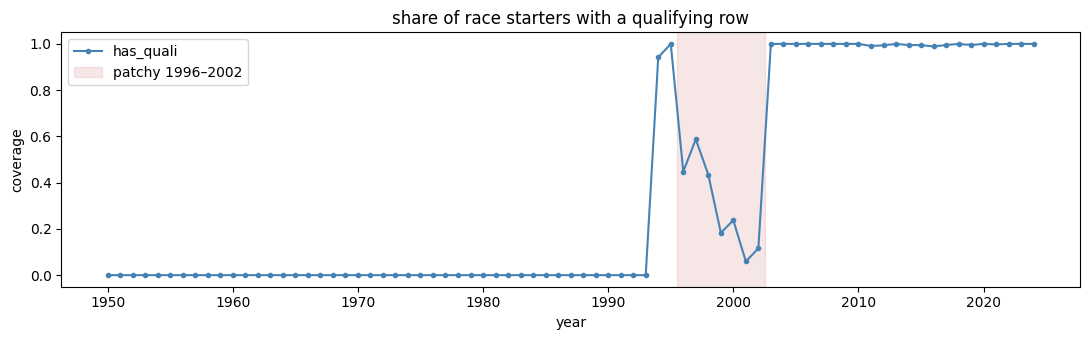

{1994: 0.94, 1995: 1.0, 1996: 0.45, 1997: 0.59, 1998: 0.43, 1999: 0.18, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0, 2005: 1.0, 2006: 1.0, 2007: 1.0, 2008: 1.0, 2009: 1.0, 2010: 1.0, 2011: 0.99, 2012: 0.99, 2013: 1.0, 2014: 1.0, 2015: 0.99, 2016: 0.99, 2017: 0.99, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0}


In [76]:
q_years = qualifying.merge(races[["raceId", "year"]], on="raceId")
print("year range:", q_years["year"].min(), "→", q_years["year"].max(),
      "| races covered:", q_years["raceId"].nunique(), "of", len(races))

starters_y = (results_clean.loc[~results_clean["did_not_start"], ["raceId", "driverId"]]
              .merge(races_clean[["raceId", "year"]], on="raceId"))
starters_y["has_quali"] = starters_y.set_index(["raceId", "driverId"]).index.isin(q_keys)
coverage = starters_y.groupby("year")["has_quali"].mean()

fig, ax = plt.subplots(figsize=(11, 3.5))
coverage.plot(ax=ax, color="steelblue", marker=".")
ax.axvspan(1995.5, 2002.5, alpha=0.15, color="indianred", label="patchy 1996–2002")
ax.set_title("share of race starters with a qualifying row")
ax.set_ylabel("coverage")
ax.legend()
plt.tight_layout()
plt.show()
print(coverage[coverage.index >= 1994].round(2).to_dict())

**Qualifying-coverage drift (the brief's named limitation):** the table covers only 494 of 1,125 races. Nothing before **1994**, almost complete in 1994–95, then **patchy 1996–2002** (6–59% of starters), and ~100% from **2003**. So any qualifying-based feature is missing for most of history. `grid` (in `results`, all years) is the only starting-order field with full coverage. The modeling section has to choose between grid plus quali features with a "has qualifying" flag, or training only from 2003. That choice is one of the preprocessing experiments.

In [77]:
qualifying_clean = strip_sentinels(qualifying)
for q in ["q1", "q2", "q3"]:
    qualifying_clean[f"{q}_s"] = qualifying_clean[q].map(parse_lap_time_to_seconds)
qualifying_clean = qualifying_clean.drop(columns=["q1", "q2", "q3"])

qualifying_clean["best_q_s"] = qualifying_clean[["q1_s", "q2_s", "q3_s"]].min(axis=1)
pole_time = qualifying_clean.groupby("raceId")["best_q_s"].transform("min")
qualifying_clean["q_gap_to_pole_pct"] = (qualifying_clean["best_q_s"] / pole_time - 1) * 100

print(qualifying_clean[["q1_s", "q2_s", "q3_s", "best_q_s", "q_gap_to_pole_pct"]].describe().round(2))

           q1_s     q2_s     q3_s  best_q_s  q_gap_to_pole_pct
count  10338.00  5847.00  3629.00  10338.00           10338.00
mean      88.53    87.77    87.41     87.95               2.49
std       15.39    12.11    12.26     15.22               9.41
min       53.90    53.65    53.38     53.38               0.00
25%       78.77    77.94    77.24     78.54               0.91
50%       87.14    87.12    87.04     86.69               1.84
75%       95.91    95.96    95.63     95.35               3.07
max     1002.64   132.47   129.78   1002.64             922.86


In [78]:
m = (
    qualifying_clean[["raceId", "driverId", "position"]].rename(columns={"position": "qual_pos"})
    .merge(results_clean[["raceId", "driverId", "grid", "podium", "status", "is_pit_start"]], on=["raceId", "driverId"])
)
m["grid_delta"] = m["grid"] - m["qual_pos"]            # > 0 = started further back than qualified
m["start_vs_quali"] = np.select([m["grid_delta"] == 0, m["grid"] == 0, m["grid_delta"] < 0],
                                ["same", "pit lane", "better start"], default="worse start")

print("rows matched:", len(m), "| grid != qualifying position:", f"{(m['grid_delta'] != 0).mean():.1%}")
display(m.groupby("start_vs_quali").agg(n=("podium", "size"), podium_rate=("podium", "mean"),
                                        mean_delta=("grid_delta", "mean")).round(3))

fin = m[(m["status"] == "Finished") & (m["grid"] > 0)]
display(fin.groupby("start_vs_quali").agg(n=("podium", "size"), podium_rate=("podium", "mean")).round(3)
        .rename(columns=lambda c: f"finished_{c}"))

rows matched: 10494 | grid != qualifying position: 23.9%


,n,podium_rate,mean_delta
start_vs_quali,,,
better start,1894,0.062,-1.389
pit lane,87,0.000,-16.218
same,7985,0.167,0.000
worse start,528,0.062,4.562


,finished_n,finished_podium_rate
start_vs_quali,,
better start,742,0.158
same,3701,0.357
worse start,242,0.136


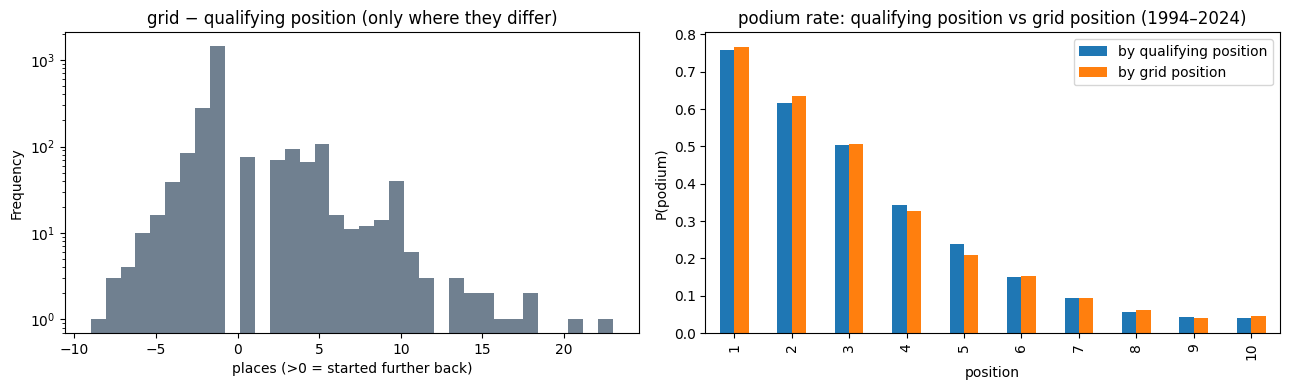

delta among changed rows: {'mean': -0.09124690338563171, '50%': -1.0, 'min': -9.0, 'max': 23.0}
share 'better start' with delta == -1: 60.0%


In [79]:
changed = m[(m["grid_delta"] != 0) & (m["grid"] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
changed["grid_delta"].clip(-10, 25).plot(kind="hist", bins=35, ax=axes[0], color="slategray")
axes[0].set_yscale("log")
axes[0].set_title("grid − qualifying position (only where they differ)")
axes[0].set_xlabel("places (>0 = started further back)")

pq = m[m["qual_pos"].between(1, 10)]
pd.DataFrame({
    "by qualifying position": pq.groupby("qual_pos")["podium"].mean(),
    "by grid position": m[m["grid"].between(1, 10)].groupby("grid")["podium"].mean(),
}).plot(kind="bar", ax=axes[1])
axes[1].set_title("podium rate: qualifying position vs grid position (1994–2024)")
axes[1].set_xlabel("position")
axes[1].set_ylabel("P(podium)")
plt.tight_layout()
plt.show()
print("delta among changed rows:", changed["grid_delta"].describe()[["mean", "50%", "min", "max"]].to_dict())
print("share 'better start' with delta == -1:", f"{(changed['grid_delta'] == -1).mean():.1%}")


In [80]:
qualifying_clean.to_csv(CLEAN_DIR / "qualifying_clean.csv", index=False)
print("saved:", CLEAN_DIR / "qualifying_clean.csv", qualifying_clean.shape)
log_audit("qualifying", qualifying, qualifying_clean)

saved: /kaggle/working/cleaned/qualifying_clean.csv (10494, 11)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
qualifying,10494,10494,9,11,11600,0,11980,3,0


**Qualifying - conclusion**
- 10,494 rows, keys unique, every FK reconciles, and every qualifying row has a `results` row.
- **Typing:** q1–q3 → seconds, and both kinds of missing marker (`\N` and empty cells) → NA. Added `best_q_s` and `q_gap_to_pole_pct` (median 1.8% off pole).
- **Coverage drift:** qualifying exists only from 1994, is patchy in 1996–2002, and is complete from 2003. This is a key limitation, and the reason `grid` stays the universal starting-order feature.
- **Grid ≠ qualifying for 23.9% of drivers.** 78% of the changed slots are **better** starts (60% exactly one place up: someone ahead got a penalty or started from the pit lane), and 22% are **worse** starts (penalties, median +5 places).
- Drivers whose grid matched qualifying podium 16.7% of the time, vs 6.2% for both moved groups. Among finishers: same 35.7%, better 15.8%, worse 13.6%. Being moved happens mostly to midfield cars, so a grid change is linked to podium odds, not just a reshuffle.
- For the front positions, qualifying and grid are similarly predictive (P1: 76% vs 77%; P3: 50% vs 51%). DEQ1 reports both definitions.
- `qualifying_clean`: 10,494 × 11, saved to `data/cleaned/qualifying_clean.csv`.

## 1.9 `sprint_results`
Saturday sprint races, 2021–2024 (18 weekends), with the same columns as `results`.

**Leakage judgement (F1 primer):** the sprint runs **before** the Sunday race, so its result is technically pre-race information for the Sunday podium. In 2021–22 it even set the Sunday grid.

In [81]:
sprint_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   resultId        360 non-null    int64 
 1   raceId          360 non-null    int64 
 2   driverId        360 non-null    int64 
 3   constructorId   360 non-null    int64 
 4   number          360 non-null    int64 
 5   grid            360 non-null    int64 
 6   position        360 non-null    object
 7   positionText    360 non-null    object
 8   positionOrder   360 non-null    int64 
 9   points          360 non-null    int64 
 10  laps            360 non-null    int64 
 11  time            360 non-null    object
 12  milliseconds    360 non-null    object
 13  fastestLap      360 non-null    object
 14  fastestLapTime  360 non-null    object
 15  statusId        360 non-null    int64 
dtypes: int64(10), object(6)
memory usage: 45.1+ KB


In [82]:
sprint_results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


In [83]:
print("duplicate resultId:", sprint_results["resultId"].duplicated().sum())
print("duplicate (raceId, driverId):", sprint_results.duplicated(["raceId", "driverId"]).sum())
for col, parent in [("raceId", races), ("driverId", drivers), ("constructorId", constructors), ("statusId", status)]:
    print(f"{col} not in parent table (FK orphans):", (~sprint_results[col].isin(parent[col])).sum())
print("\\N:", {c: int((sprint_results[c] == r"\N").sum()) for c in sprint_results.columns
               if (sprint_results[c] == r"\N").any()})
sp_years = sprint_results.merge(races[["raceId", "year"]], on="raceId")
print("sprint weekends per year:", sp_years.groupby("year")["raceId"].nunique().to_dict())

duplicate resultId: 0
duplicate (raceId, driverId): 0
raceId not in parent table (FK orphans): 0
driverId not in parent table (FK orphans): 0
constructorId not in parent table (FK orphans): 0
statusId not in parent table (FK orphans): 0
\N: {'position': 15, 'time': 20, 'milliseconds': 20, 'fastestLap': 9, 'fastestLapTime': 9}
sprint weekends per year: {2021: 3, 2022: 3, 2023: 6, 2024: 6}


In [84]:
sprint_results_clean = strip_sentinels(sprint_results)
sprint_results_clean = to_numeric_checked(sprint_results_clean, ["position", "milliseconds", "fastestLap"])
for c in ["position", "fastestLap"]:
    sprint_results_clean[c] = sprint_results_clean[c].astype("Int64")
sprint_results_clean["sprint_time_s"] = sprint_results_clean["milliseconds"] / 1000
sprint_results_clean["fastestLapTime_s"] = sprint_results_clean["fastestLapTime"].map(parse_lap_time_to_seconds)
sprint_results_clean = sprint_results_clean.drop(columns=["time", "milliseconds", "fastestLapTime"])
sprint_results_clean = sprint_results_clean.merge(status_clean[["statusId", "status"]], on="statusId", how="left")
sprint_results_clean["sprint_podium"] = (sprint_results_clean["positionOrder"] <= 3).astype(int)

assert not sprint_results_clean.duplicated(["raceId", "driverId"]).any()
print("sprint podium rate:", round(sprint_results_clean["sprint_podium"].mean(), 3))
print(sprint_results_clean["status"].value_counts().head(5).to_dict())

sprint podium rate: 0.15
{'Finished': 340, 'Retired': 10, 'Accident': 3, 'Collision damage': 3, 'Vibrations': 1}


,sunday_podium_rate,n
sprint_podium,,
0,0.069,306
1,0.611,54


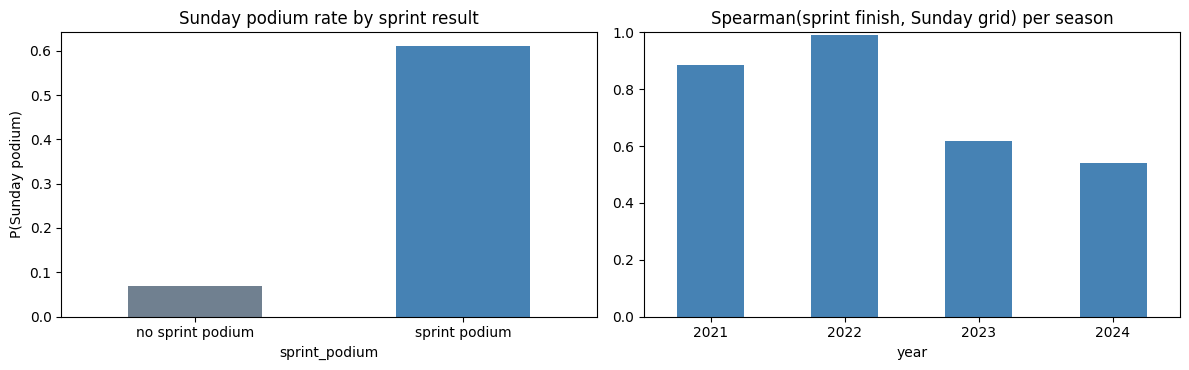

rank correlation: {2021: 0.89, 2022: 0.99, 2023: 0.62, 2024: 0.54}
sprint weekends per split → train (≤2019): 0 | val (2020–21): 3 | test (≥2022): 15


In [85]:
sx = (sprint_results_clean[["raceId", "driverId", "positionOrder", "sprint_podium"]]
      .merge(results_clean[["raceId", "driverId", "grid", "podium"]], on=["raceId", "driverId"])
      .merge(races_clean[["raceId", "year"]], on="raceId"))

display(sx.groupby("sprint_podium")["podium"].agg(sunday_podium_rate="mean", n="size").round(3))

rho = sx[sx["grid"] > 0].groupby("year").apply(
    lambda d: d["positionOrder"].corr(d["grid"], method="spearman"), include_groups=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sx.groupby("sprint_podium")["podium"].mean().rename({0: "no sprint podium", 1: "sprint podium"}).plot(
    kind="bar", ax=axes[0], color=["slategray", "steelblue"], rot=0)
axes[0].set_title("Sunday podium rate by sprint result")
axes[0].set_ylabel("P(Sunday podium)")
rho.plot(kind="bar", ax=axes[1], color="steelblue", rot=0)
axes[1].set_title("Spearman(sprint finish, Sunday grid) per season")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()
print("rank correlation:", rho.round(2).to_dict())
print("sprint weekends per split → train (≤2019): 0 | val (2020–21):",
      races_clean.query("2020 <= year <= 2021")["is_sprint_weekend"].sum(),
      "| test (≥2022):", races_clean.query("year >= 2022")["is_sprint_weekend"].sum())

In [86]:
sprint_results_clean.to_csv(CLEAN_DIR / "sprint_results_clean.csv", index=False)
print("saved:", CLEAN_DIR / "sprint_results_clean.csv", sprint_results_clean.shape)
log_audit("sprint_results", sprint_results, sprint_results_clean)

saved: /kaggle/working/cleaned/sprint_results_clean.csv (360, 17)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
sprint_results,360,360,16,17,73,0,53,6,2


**Sprint — conclusion**
- 360 rows (3, 3, 6, 6 weekends per season), keys unique, FKs reconcile. The 73 `\N` cells → NA (non-classified positions, lapped times, missing fastest laps: the same patterns as `results`), and times → seconds. 340 of 360 finished.
- **Strong pre-race signal:** a sprint podium is followed by a Sunday podium **61%** of the time, vs **6.9%** otherwise.
- But it overlaps heavily with `grid`. Sprint finish and Sunday grid have a rank correlation of 0.89 (2021) and 0.99 (2022), when the sprint *set* the grid, and still 0.62 / 0.54 in 2023–24 with separate qualifying.
- **Decision: not a model feature.** With the time split (train ≤ 2019 / val 2020–21 / test ≥ 2022), the training set has **0 sprint weekends** (val 3, test 15), so a model cannot learn a weight for it. Its information reaches the model largely through `grid`. This is a deliberate, documented choice and a limitation for the report (sprint information is unused for 2023–24).

## 1.10 `driver_standings`
Drivers' championship table **after** each race: cumulative `points`, `position` and `wins` per driver.

**Leakage:** the row for race *r* already **includes the points scored in race *r***, so using it directly would leak the result. The fix is to give race *r* the standings row of the **previous round of the same season** (`prev_raceId`, built in 1.6). That is exactly what was known before lights out.

In [87]:
driver_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


In [88]:
driver_standings.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [89]:
print("duplicate driverStandingsId:", driver_standings["driverStandingsId"].duplicated().sum())
print("duplicate (raceId, driverId):", driver_standings.duplicated(["raceId", "driverId"]).sum())
print("literal \\N cells:", count_literal_N(driver_standings))
for col, parent in [("raceId", races), ("driverId", drivers)]:
    print(f"{col} not in parent table (FK orphans):", (~driver_standings[col].isin(parent[col])).sum())
print("positionText letter codes:",
      driver_standings.loc[~driver_standings["positionText"].str.isdigit(), "positionText"].value_counts().to_dict())
display(driver_standings[driver_standings["positionText"] == "D"]
        .merge(races[["raceId", "year", "round"]], on="raceId")
        .merge(drivers[["driverId", "forename", "surname"]], on="driverId"))

duplicate driverStandingsId: 0
duplicate (raceId, driverId): 0
literal \N cells: 0
raceId not in parent table (FK orphans): 0
driverId not in parent table (FK orphans): 0
positionText letter codes: {'D': 1}


,driverStandingsId,raceId,driverId,points,position,positionText,wins,year,round,forename,surname
0,11031,223,30,78.0,26,D,5,1997,17,Michael,Schumacher


In [90]:
# standings are cumulative AFTER each race: race-1 standings = points scored in race 1
ds_y = driver_standings.merge(races[["raceId", "year", "round"]], on="raceId")
r1 = ds_y[ds_y["round"] == 1].merge(results[["raceId", "driverId", "points"]], on=["raceId", "driverId"],
                                    suffixes=("_standings", "_race"))
print("round 1: standings points == points scored in that race:",
      f"{(r1['points_standings'] == r1['points_race']).mean():.1%}", f"({len(r1)} rows)")

round 1: standings points == points scored in that race: 99.5% (1538 rows)


**Findings**
- Keys unique, no `\N`, FKs reconcile.
- One letter code: `D` = **Michael Schumacher, 1997**, disqualified from that championship (his numeric `position` is 26). `position` is always numeric, so `positionText` is redundant → dropped.
- **Proof that the table is post-race:** in round 1, the standings points equal the points scored *in that same race* for 99.5% of rows (the rest are early shared drives, where points were split). So the raw row for race *r* contains race *r*'s result.

**Lag rule.** We add three columns to the same table: `pre_driver_points`, `pre_driver_position` and `pre_driver_wins`. They hold this driver's standings at `prev_raceId` (the previous round of the same season), i.e. what was known before race *r*. The official post-race columns (`points`, `position`, `wins`) stay for reference and for the DEQs, but **only the `pre_*` columns may be used as features**.
- season opener (no previous round) → NA (= no points yet; filled with 0 in feature engineering)
- driver with no standings row at the previous round (debut or one-off entry) → NA (= 0 points so far)

In [91]:
driver_standings_clean = driver_standings.drop(columns=["positionText"])

# pre-race standings = this driver's row at the previous round of the same season
prev_ds = driver_standings_clean.rename(columns={
    "raceId": "prev_raceId", "points": "pre_driver_points",
    "position": "pre_driver_position", "wins": "pre_driver_wins",
})[["prev_raceId", "driverId", "pre_driver_points", "pre_driver_position", "pre_driver_wins"]]

driver_standings_clean = (
    driver_standings_clean
    .merge(races_clean[["raceId", "prev_raceId"]], on="raceId", how="left")
    .merge(prev_ds, on=["prev_raceId", "driverId"], how="left")
    .drop(columns=["prev_raceId"])
)
assert not driver_standings_clean.duplicated(["raceId", "driverId"]).any()

# sanity: pre-race points can never exceed post-race points
print("rows where pre-race points > post-race points:",
      (driver_standings_clean["pre_driver_points"].fillna(0) > driver_standings_clean["points"]).sum())

# coverage for the modeling grain: every result row that had standings before the race keeps them
cover = results_clean[["raceId", "driverId"]].merge(driver_standings_clean, on=["raceId", "driverId"], how="left")
print("result rows without pre-race standings:", cover["pre_driver_points"].isna().sum(), "/", len(cover))
driver_standings_clean.head()

rows where pre-race points > post-race points: 0
result rows without pre-race standings: 3661 / 26668


,driverStandingsId,raceId,driverId,points,position,wins,pre_driver_points,pre_driver_position,pre_driver_wins
0,1,18,1,10.0,1,1,NaN,NaN,NaN
1,2,18,2,8.0,2,0,NaN,NaN,NaN
2,3,18,3,6.0,3,0,NaN,NaN,NaN
3,4,18,4,5.0,4,0,NaN,NaN,NaN
4,5,18,5,4.0,5,0,NaN,NaN,NaN


In [92]:
# one driver, one season: pre-race points of round r = post-race points of round r-1
(driver_standings_clean.merge(races_clean[["raceId", "year", "round"]], on="raceId")
 .query("driverId == 1 and year == 2008").sort_values("round")
 [["round", "pre_driver_points", "points"]].rename(columns={"points": "post_race_points"}).head(6))

,round,pre_driver_points,post_race_points
0,1,NaN,10.0
8,2,10.0,14.0
26,3,14.0,14.0
47,4,14.0,20.0
68,5,20.0,28.0
90,6,28.0,38.0


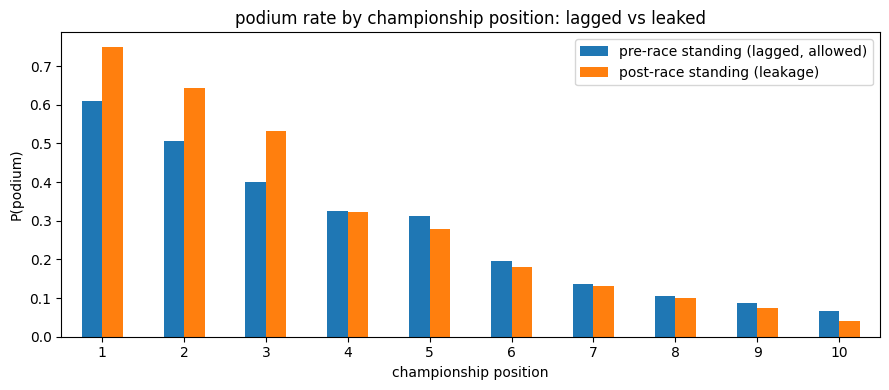

,1,2,3,4,5,6,7,8,9,10
"pre-race standing (lagged, allowed)",0.61,0.51,0.40,0.32,0.31,0.20,0.14,0.1,0.09,0.07
post-race standing (leakage),0.75,0.64,0.53,0.32,0.28,0.18,0.13,0.1,0.07,0.04


In [93]:
ev = (results_clean.loc[~results_clean["did_not_start"], ["raceId", "driverId", "podium"]]
      .merge(driver_standings_clean, on=["raceId", "driverId"], how="left"))

compare = pd.DataFrame({
    "pre-race standing (lagged, allowed)": ev[ev["pre_driver_position"] <= 10].groupby("pre_driver_position")["podium"].mean(),
    "post-race standing (leakage)": ev[ev["position"] <= 10].groupby("position")["podium"].mean(),
})
compare.index = compare.index.astype(int)

fig, ax = plt.subplots(figsize=(9, 4))
compare.plot(kind="bar", ax=ax, rot=0)
ax.set_title("podium rate by championship position: lagged vs leaked")
ax.set_xlabel("championship position")
ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()
display(compare.round(2).T)

In [94]:
driver_standings_clean.to_csv(CLEAN_DIR / "driver_standings_clean.csv", index=False)
print("saved:", CLEAN_DIR / "driver_standings_clean.csv", driver_standings_clean.shape)
log_audit("driver_standings", driver_standings, driver_standings_clean)

saved: /kaggle/working/cleaned/driver_standings_clean.csv (34863, 9)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
driver_standings,34863,34863,7,9,0,0,9576,1,0


**Driver standings — conclusion**
- 34,863 rows, keys unique, no `\N`. `positionText` dropped (its only letter, Schumacher's 1997 `D`, is redundant with the numeric `position`).
- **Leakage proven and fixed.** The raw table is post-race (round-1 standings = that race's points for 99.5% of rows). The `pre_*` columns hold the standings **before** each race. Example: Hamilton 2008 enters round 2 with 10 points, which is exactly his total after round 1.
- Check: pre-race points never exceed post-race points.
- Joined to `results_clean`, **3,661 of 26,668 result rows have no pre-race standings**, all structural: season openers, plus drivers with no standings row at the previous round. They are filled as "0 points so far" in feature engineering, not dropped. Keeping the lag inside this one table loses nothing: every result row that had pre-race standings keeps them.
- **Why the lag matters (plot):** at the top of the table the leaked post-race standing looks much stronger (leader: 75% podium vs 61% for the pre-race leader; P3: 53% vs 40%), because it already contains the race's own points. A model trained on it would score well in evaluation but could not be used before a race.
- Saved: `driver_standings_clean.csv` (34,863 × 9: official post-race columns + `pre_*` columns).

## 1.11 `constructor_standings`
Constructors' championship table **after** each race: cumulative `points`, `position` and `wins` per team. It has the same leakage problem as driver standings, and the same fix (lag to `prev_raceId`, stored as `pre_*` columns in the same table).

In [95]:
constructor_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


In [96]:
constructor_standings.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [97]:
cs_y = constructor_standings.merge(races[["raceId", "year", "round"]], on="raceId")
print("years:", cs_y["year"].min(), "→", cs_y["year"].max())
print("duplicate constructorStandingsId:", constructor_standings["constructorStandingsId"].duplicated().sum())
print("duplicate (raceId, constructorId):", constructor_standings.duplicated(["raceId", "constructorId"]).sum())
print("literal \\N cells:", count_literal_N(constructor_standings))
for col, parent in [("raceId", races), ("constructorId", constructors)]:
    print(f"{col} not in parent table (FK orphans):", (~constructor_standings[col].isin(parent[col])).sum())
print("positionText letter codes:",
      constructor_standings.loc[~constructor_standings["positionText"].str.isdigit(), "positionText"].value_counts().to_dict())

years: 1958 → 2024
duplicate constructorStandingsId: 0
duplicate (raceId, constructorId): 0
literal \N cells: 0
raceId not in parent table (FK orphans): 0
constructorId not in parent table (FK orphans): 0
positionText letter codes: {'E': 17}


#### 2007 Spygate
**Spygate:** McLaren was excluded from the 2007 Constructors' Championship, and Ergast applies this **retroactively to all 17 rounds**: `positionText = "E"` and `position = 11`, even though McLaren had more points than leader Ferrari in every round and won 8 races.
**Decision:** do **not** rewrite the official standings and do **not** drop 2007. This only matters for constructor standings. McLaren's *race results* (and so their drivers' podium labels) are untouched. **Limitation:** in 2007, McLaren's lagged `pre_constructor_position` (11) badly understates the car's real pace, so expect the model to under-predict McLaren podiums that season.


In [98]:
# 2007 Spygate: McLaren has more points than Ferrari but is listed 'E' at position 11 all season
ferrari_id = constructors.loc[constructors["name"] == "Ferrari", "constructorId"].iloc[0]
mclaren_id = constructors.loc[constructors["name"] == "McLaren", "constructorId"].iloc[0]
s07 = cs_y[cs_y["year"] == 2007]
spygate = (
    s07[s07["constructorId"] == mclaren_id][["round", "raceId", "points", "position", "positionText", "wins"]]
    .merge(s07[s07["constructorId"] == ferrari_id][["raceId", "points", "position"]]
           .rename(columns={"points": "ferrari_points", "position": "ferrari_position"}), on="raceId")
    .drop(columns="raceId").rename(columns={"points": "mclaren_points", "position": "mclaren_position",
                                            "positionText": "mclaren_positionText", "wins": "mclaren_wins"})
    .sort_values("round").reset_index(drop=True)
)
print("2007 rounds where McLaren has more points than Ferrari but is not P1:",
      ((spygate["mclaren_points"] > spygate["ferrari_points"]) & (spygate["mclaren_position"] != 1)).sum(), "of", len(spygate))
spygate


2007 rounds where McLaren has more points than Ferrari but is not P1: 17 of 17


,round,mclaren_points,mclaren_position,mclaren_positionText,mclaren_wins,ferrari_points,ferrari_position
0,1,14.0,11,E,0,13.0,1
1,2,32.0,11,E,1,23.0,1
2,3,44.0,11,E,1,39.0,1
3,4,58.0,11,E,1,49.0,1
4,5,76.0,11,E,2,56.0,1
5,6,88.0,11,E,3,60.0,1
6,7,106.0,11,E,4,71.0,1
7,8,114.0,11,E,4,89.0,1
8,9,128.0,11,E,5,103.0,1
9,10,138.0,11,E,5,111.0,1


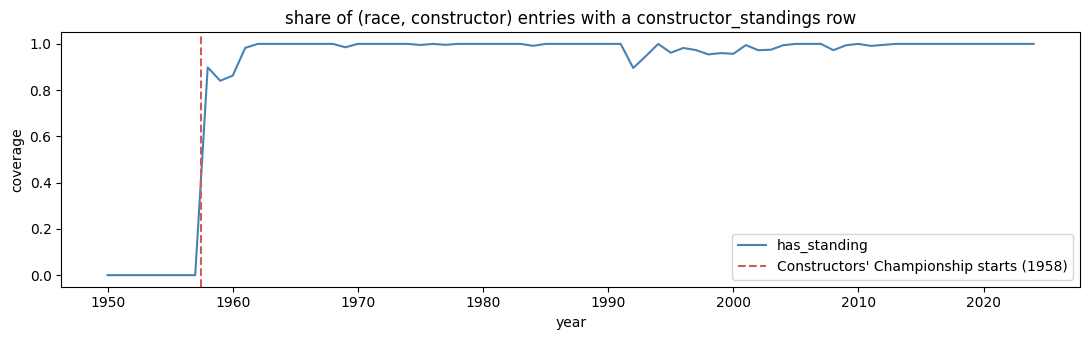

entries from 1958 without a standings row: 129


In [99]:
cs_keys = constructor_standings.set_index(["raceId", "constructorId"]).index
entries = (results_clean[["raceId", "constructorId"]].drop_duplicates()
           .merge(races_clean[["raceId", "year"]], on="raceId"))
entries["has_standing"] = entries.set_index(["raceId", "constructorId"]).index.isin(cs_keys)

fig, ax = plt.subplots(figsize=(11, 3.5))
entries.groupby("year")["has_standing"].mean().plot(ax=ax, color="steelblue")
ax.axvline(1957.5, ls="--", color="indianred", label="Constructors' Championship starts (1958)")
ax.set_title("share of (race, constructor) entries with a constructor_standings row")
ax.set_ylabel("coverage")
ax.legend()
plt.tight_layout()
plt.show()
print("entries from 1958 without a standings row:", (~entries.loc[entries["year"] >= 1958, "has_standing"]).sum())

In [100]:
constructor_standings_clean = constructor_standings.drop(columns=["positionText"])

# pre-race standings = this constructor's row at the previous round of the same season
prev_cs = constructor_standings_clean.rename(columns={
    "raceId": "prev_raceId", "points": "pre_constructor_points",
    "position": "pre_constructor_position", "wins": "pre_constructor_wins",
})[["prev_raceId", "constructorId", "pre_constructor_points", "pre_constructor_position", "pre_constructor_wins"]]

constructor_standings_clean = (
    constructor_standings_clean
    .merge(races_clean[["raceId", "prev_raceId"]], on="raceId", how="left")
    .merge(prev_cs, on=["prev_raceId", "constructorId"], how="left")
    .drop(columns=["prev_raceId"])
)
assert not constructor_standings_clean.duplicated(["raceId", "constructorId"]).any()

drops = constructor_standings_clean[constructor_standings_clean["pre_constructor_points"].fillna(0)
                                    > constructor_standings_clean["points"]]
print("rows where pre-race points > post-race points:", len(drops))
display(drops.merge(races_clean[["raceId", "year", "round", "name"]], on="raceId")
        .merge(constructors_clean[["constructorId", "name"]], on="constructorId", suffixes=("_race", "_constructor"))
        [["year", "round", "name_race", "name_constructor", "pre_constructor_points", "points"]])

cover_c = (results_clean[["raceId", "constructorId"]].drop_duplicates()
           .merge(constructor_standings_clean, on=["raceId", "constructorId"], how="left"))
print("(race, constructor) entries without pre-race standings:", cover_c["pre_constructor_points"].isna().sum(),
      "/", len(cover_c))
constructor_standings_clean.head()

rows where pre-race points > post-race points: 2


,year,round,name_race,name_constructor,pre_constructor_points,points
0,2018,13,Belgian Grand Prix,Force India,59.0,18.0
1,2020,5,70th Anniversary Grand Prix,Racing Point,42.0,41.0


(race, constructor) entries without pre-race standings: 1444 / 13024


,constructorStandingsId,raceId,constructorId,points,position,wins,pre_constructor_points,pre_constructor_position,pre_constructor_wins
0,1,18,1,14.0,1,1,NaN,NaN,NaN
1,2,18,2,8.0,3,0,NaN,NaN,NaN
2,3,18,3,9.0,2,0,NaN,NaN,NaN
3,4,18,4,5.0,4,0,NaN,NaN,NaN
4,5,18,5,2.0,5,0,NaN,NaN,NaN


**Two points drops, both real events:** Force India, 2018 Belgian GP (59 → 18): the team went into administration and was re-entered mid-season, which reset its points. Racing Point, 2020 70th Anniversary GP (42 → 41): 15 points were deducted in the brake-duct case. Both are kept as recorded. The lag correctly carries the *official* pre-race total.

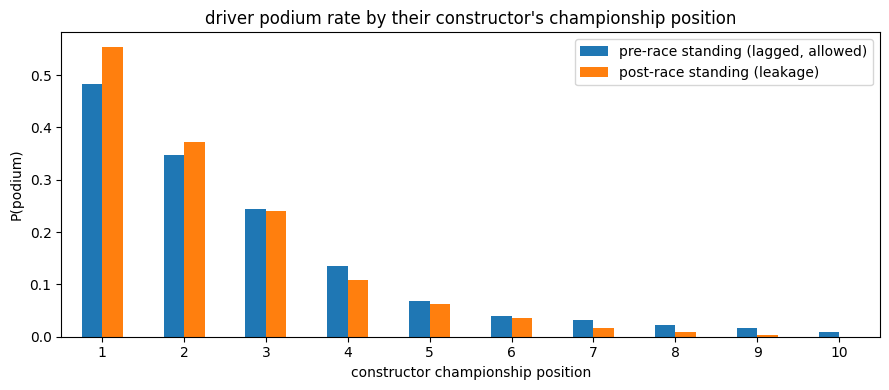

,1,2,3,4,5,6,7,8,9,10
"pre-race standing (lagged, allowed)",0.48,0.35,0.24,0.13,0.07,0.04,0.03,0.02,0.02,0.01
post-race standing (leakage),0.55,0.37,0.24,0.11,0.06,0.04,0.02,0.01,0.00,0.00


In [101]:
ev_c = (results_clean.loc[~results_clean["did_not_start"], ["raceId", "constructorId", "podium"]]
        .merge(constructor_standings_clean, on=["raceId", "constructorId"], how="left"))

compare_c = pd.DataFrame({
    "pre-race standing (lagged, allowed)":
        ev_c[ev_c["pre_constructor_position"] <= 10].groupby("pre_constructor_position")["podium"].mean(),
    "post-race standing (leakage)": ev_c[ev_c["position"] <= 10].groupby("position")["podium"].mean(),
})
compare_c.index = compare_c.index.astype(int)

fig, ax = plt.subplots(figsize=(9, 4))
compare_c.plot(kind="bar", ax=ax, rot=0)
ax.set_title("driver podium rate by their constructor's championship position")
ax.set_xlabel("constructor championship position")
ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()
display(compare_c.round(2).T)

In [102]:
constructor_standings_clean.to_csv(CLEAN_DIR / "constructor_standings_clean.csv", index=False)
print("saved:", CLEAN_DIR / "constructor_standings_clean.csv", constructor_standings_clean.shape)
log_audit("constructor_standings", constructor_standings, constructor_standings_clean)

saved: /kaggle/working/cleaned/constructor_standings_clean.csv (13391, 9)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
constructor_standings,13391,13391,7,9,0,0,2760,1,0


**Constructor standings — conclusion**
- 13,391 rows, 1958–2024, keys unique, no `\N`, FKs reconcile. The only letter code is Spygate (`E`, McLaren 2007, all 17 rounds). `positionText` dropped.
- **Coverage starts in 1958** because the Constructors' Championship did not exist before (F1 primer). So constructor standings are missing **by design** for 1950–57. From 1958 on, 129 entries have no standings row (teams that never appear in the table).
- The `pre_constructor_*` columns hold each team's standings **before** the race (same `prev_raceId` lag). Joined to the results entries, 1,444 of 13,024 `(race, constructor)` pairs have none (pre-1958, season openers, unlisted teams). They are filled as "0 points so far" later. Only the `pre_*` columns may be used as features.
- **Evidence for a constructor feature group:** a driver's podium rate falls steeply with their team's pre-race position: leader 48%, 2nd 35%, 3rd 24%, 5th 7%, 8th 2%. This supports the primer's point that **the car dominates**. The leaked post-race version is again inflated at the top (leader 55% vs 48%).
- Documented limitations: Spygate 2007, the Force India 2018 points reset, the Racing Point 2020 deduction.
- Saved: `constructor_standings_clean.csv` (13,391 × 9: official post-race columns + `pre_*` columns).

## 1.12 `constructor_results`
Points scored by each constructor **in** each race (not cumulative), 1958–2024.

**Leakage:** these are the points of the race being predicted → post-race. The table is **not a model input**: lagged team strength already comes from `constructor_standings_clean.pre_*`, and rolling form will be computed from `results_clean` using previous races only.

In [103]:
constructor_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [104]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


In [105]:
print("duplicate constructorResultsId:", constructor_results["constructorResultsId"].duplicated().sum())
print("duplicate (raceId, constructorId):", constructor_results.duplicated(["raceId", "constructorId"]).sum())
for col, parent in [("raceId", races), ("constructorId", constructors)]:
    print(f"{col} not in parent table (FK orphans):", (~constructor_results[col].isin(parent[col])).sum())
print("status values:", constructor_results["status"].value_counts().to_dict())
cr_y = constructor_results.merge(races[["raceId", "year", "name"]], on="raceId")
print("years:", cr_y["year"].min(), "→", cr_y["year"].max())
(cr_y[cr_y["status"] == "D"].merge(constructors[["constructorId", "name"]], on="constructorId",
                                   suffixes=("_race", "_constructor"))
 .groupby(["year", "name_constructor"]).size().rename("disqualified_races").reset_index())

duplicate constructorResultsId: 0
duplicate (raceId, constructorId): 0
raceId not in parent table (FK orphans): 0
constructorId not in parent table (FK orphans): 0
status values: {'\\N': 12608, 'D': 17}
years: 1958 → 2024


,year,name_constructor,disqualified_races
0,2007,McLaren,17


In [106]:
# do constructor race points equal the sum of the team's drivers' points in results?
team_pts = results_clean.groupby(["raceId", "constructorId"])["points"].sum().rename("drivers_points")
cmp = constructor_results.join(team_pts, on=["raceId", "constructorId"]).merge(races[["raceId", "year"]], on="raceId")
cmp["match"] = (cmp["points"] - cmp["drivers_points"]).abs() < 1e-9
print("constructor points == sum of its drivers' points:", f"{cmp['match'].mean():.1%}")
mismatch_by_decade = (~cmp["match"]).groupby(cmp["year"] // 10 * 10).mean().round(3)
print("share of mismatches by decade:", mismatch_by_decade.to_dict())

constructor points == sum of its drivers' points: 96.9%
share of mismatches by decade: {1950: 0.223, 1960: 0.155, 1970: 0.072, 1980: 0.0, 1990: 0.0, 2000: 0.001, 2010: 0.002, 2020: 0.077}


**Findings**
- Keys unique, FKs reconcile. `status` is `\N` in 12,608 rows and `D` in 17. The 17 are **McLaren 2007 (Spygate)**, the same exclusion seen in 1.11.
- **Cross-table consistency check:** constructor points equal the sum of the team's drivers' points in `results` for 96.9% of rows. Every mismatch has a known rule behind it:
  - **1958–1979:** the team scored *less* than its drivers combined in all 302 mismatches. Under the old rules only the team's **best-placed car** scored constructor points.
  - **2021–2024:** all 82 mismatches are sprint weekends and disappear once sprint points are added. Constructor race points include the sprint, while `results` holds only the Grand Prix.

**Decision:** keep the table and turn `status` into a 0/1 `is_disqualified` flag. Dropping `status` entirely would lose this information; the flag keeps it.


In [107]:
constructor_results_clean = strip_sentinels(constructor_results)
constructor_results_clean["is_disqualified"] = (constructor_results_clean["status"] == "D").astype(int)
constructor_results_clean = constructor_results_clean.drop(columns=["status"])
assert not constructor_results_clean.duplicated(["raceId", "constructorId"]).any()
constructor_results_clean.head()

,constructorResultsId,raceId,constructorId,points,is_disqualified
0,1,18,1,14.0,0
1,2,18,2,8.0,0
2,3,18,3,9.0,0
3,4,18,4,5.0,0
4,5,18,5,2.0,0


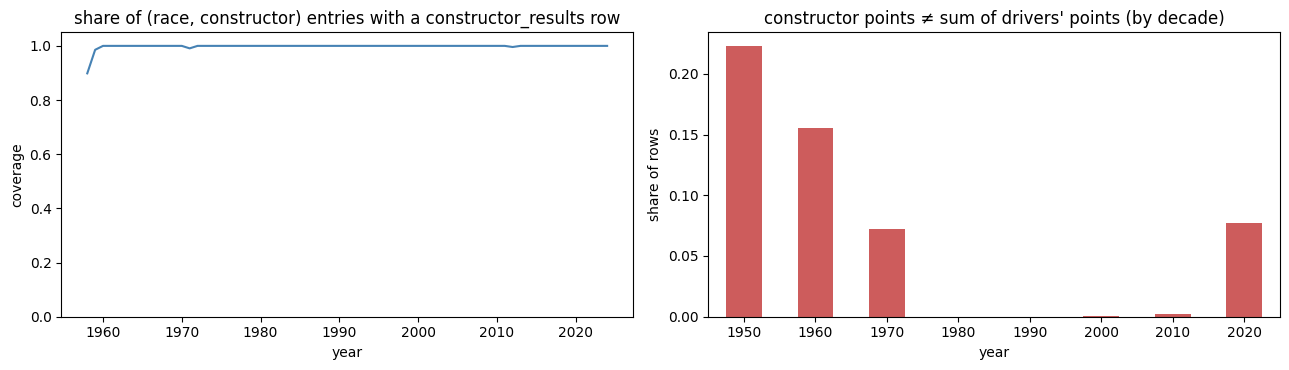

In [108]:
pairs_y = (results_clean[["raceId", "constructorId"]].drop_duplicates()
           .merge(races_clean[["raceId", "year"]], on="raceId").query("year >= 1958"))
pairs_y["in_cr"] = pairs_y.set_index(["raceId", "constructorId"]).index.isin(
    constructor_results_clean.set_index(["raceId", "constructorId"]).index)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
pairs_y.groupby("year")["in_cr"].mean().plot(ax=axes[0], color="steelblue")
axes[0].set_title("share of (race, constructor) entries with a constructor_results row")
axes[0].set_ylabel("coverage")
axes[0].set_ylim(0, 1.05)
mismatch_by_decade.plot(kind="bar", ax=axes[1], color="indianred", rot=0)
axes[1].set_title("constructor points ≠ sum of drivers' points (by decade)")
axes[1].set_ylabel("share of rows")
plt.tight_layout()
plt.show()

In [109]:
constructor_results_clean.to_csv(CLEAN_DIR / "constructor_results_clean.csv", index=False)
print("saved:", CLEAN_DIR / "constructor_results_clean.csv", constructor_results_clean.shape)
log_audit("constructor_results", constructor_results, constructor_results_clean)

saved: /kaggle/working/cleaned/constructor_results_clean.csv (12625, 5)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
constructor_results,12625,12625,5,5,12608,0,0,1,0


**Constructor results — conclusion**
- 12,625 rows, 1958–2024, keys unique, FKs reconcile. All 12,608 `\N` cells are gone: `status` became `is_disqualified` (17 = McLaren 2007).
- Coverage is ~100% of race entries from 1960 on (~94% in 1958–59).
- The points agree with `results` except where a documented scoring rule applies (best car only before 1980; sprint points from 2021). This confirms that both tables are internally consistent.
- Post-race and redundant with the lagged constructor standings → **not used for modeling**.
- `constructor_results_clean`: 12,625 × 5, saved to `data/cleaned/constructor_results_clean.csv`.

## 1.13 `lap_times`
One row per driver per lap, 1996–2024 only.

**Leakage:** lap times of the race being predicted are **post-race**, so they are never a feature. Lagged pace from *earlier* races would be allowed in principle, but it only exists from 1996, and grid and qualifying already capture pace before the race. So the table is cleaned and explored but **not used in the model**.

In [110]:
lap_times.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [111]:
lap_times.head()

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


In [112]:
print("duplicate (raceId, driverId, lap):", lap_times.duplicated(["raceId", "driverId", "lap"]).sum())
print("literal \\N cells:", count_literal_N(lap_times))
lt_keys = lap_times[["raceId", "driverId"]].drop_duplicates().set_index(["raceId", "driverId"]).index
print("(raceId, driverId) pairs without a results row:",
      (~lt_keys.isin(results.set_index(["raceId", "driverId"]).index)).sum())
lt_y = lap_times[["raceId"]].drop_duplicates().merge(races[["raceId", "year"]], on="raceId")
print("years:", lt_y["year"].min(), "→", lt_y["year"].max(), "| races with lap data:", len(lt_y), "of", len(races))

duplicate (raceId, driverId, lap): 0
literal \N cells: 0
(raceId, driverId) pairs without a results row: 0
years: 1996 → 2024 | races with lap data: 544 of 1125


**Typing:** `time` (`M:SS.mmm` text) and `milliseconds` hold the same value, so we keep seconds (`lap_s`) and drop the text, after checking that they agree. Some laps take up to ~2 hours (red-flag suspensions), so `is_slow_lap` marks laps slower than 1.5 × the race's median (safety car, pit in/out laps, red flags) instead of deleting them.

In [113]:
lap_times_clean = lap_times.copy()
lap_times_clean["lap_s"] = lap_times_clean["milliseconds"] / 1000
parsed = lap_times_clean["time"].map(parse_lap_time_to_seconds)
print("max |parsed time − milliseconds|:", round((parsed - lap_times_clean["lap_s"]).abs().max(), 4), "s")
lap_times_clean = lap_times_clean.drop(columns=["time", "milliseconds"])

race_median = lap_times_clean.groupby("raceId")["lap_s"].transform("median")
lap_times_clean["is_slow_lap"] = (lap_times_clean["lap_s"] > 1.5 * race_median).astype(int)
print("slow laps (> 1.5 × race median):", lap_times_clean["is_slow_lap"].sum(),
      f"({lap_times_clean['is_slow_lap'].mean():.1%})")
print(lap_times_clean["lap_s"].describe().round(1))

max |parsed time − milliseconds|: 0.0 s
slow laps (> 1.5 × race median): 11709 (2.0%)
count    589081.0
mean         95.8
std          76.4
min          55.4
25%          82.0
50%          90.6
75%         101.9
max        7507.5
Name: lap_s, dtype: float64


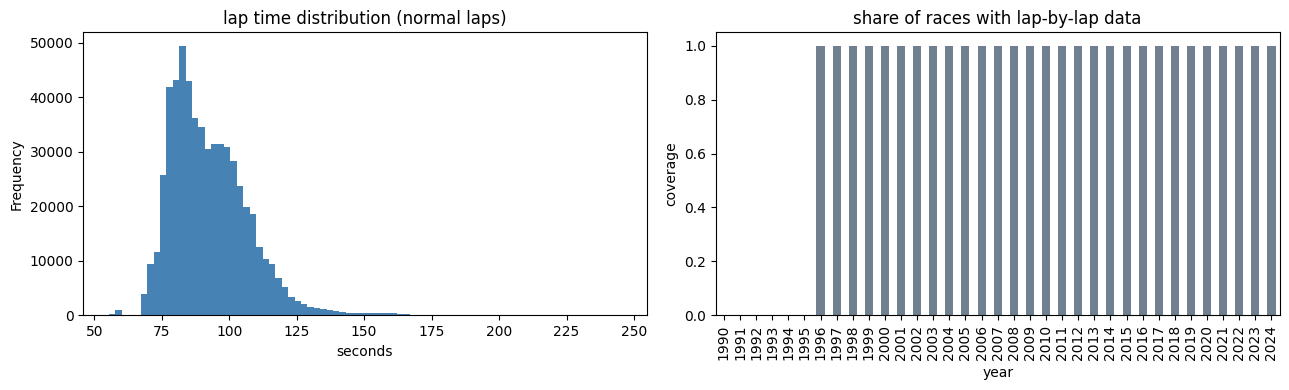

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lap_times_clean.loc[lap_times_clean["is_slow_lap"] == 0, "lap_s"].plot(
    kind="hist", bins=80, ax=axes[0], color="steelblue")
axes[0].set_title("lap time distribution (normal laps)")
axes[0].set_xlabel("seconds")

lt_cov = (races_clean.assign(has_laps=races_clean["raceId"].isin(lap_times_clean["raceId"]))
          .query("year >= 1990").groupby("year")["has_laps"].mean())
lt_cov.plot(kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("share of races with lap-by-lap data")
axes[1].set_ylabel("coverage")
plt.tight_layout()
plt.show()

In [115]:
lap_times_clean.to_csv(CLEAN_DIR / "lap_times_clean.csv", index=False)
print("saved:", CLEAN_DIR / "lap_times_clean.csv", lap_times_clean.shape)
log_audit("lap_times", lap_times, lap_times_clean)

saved: /kaggle/working/cleaned/lap_times_clean.csv (589081, 6)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
lap_times,589081,589081,6,6,0,0,0,1,0


**Lap times — conclusion**
- 589,081 rows, `(raceId, driverId, lap)` unique, no `\N`, and every driver-race exists in `results`. Data covers 544 of 1,125 races (1996–2024).
- `time` and `milliseconds` agree exactly (max difference 0.0 s) → `lap_s` in seconds. 11,709 laps (2.0%) flagged `is_slow_lap` (red flags up to 7,508 s, safety cars, pit laps).
- Normal laps: median 90.6 s, middle 50% between 82 and 102 s, depending on the circuit.
- Post-race and only from 1996 → **not used for modeling**.
- `lap_times_clean`: 589,081 × 6, saved to `data/cleaned/lap_times_clean.csv`.

## 1.14 `pit_stops`
One row per pit stop, 2011–2024 only. The grain is one row per **stop**, not per driver-race.

**Leakage:** pit stops happen during the race → **never** a feature (the brief names them explicitly).

In [116]:
pit_stops.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [117]:
pit_stops.head()

,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


In [118]:
print("duplicate (raceId, driverId, stop):", pit_stops.duplicated(["raceId", "driverId", "stop"]).sum())
print("literal \\N cells:", count_literal_N(pit_stops))
ps_keys = pit_stops[["raceId", "driverId"]].drop_duplicates().set_index(["raceId", "driverId"]).index
print("(raceId, driverId) pairs without a results row:",
      (~ps_keys.isin(results.set_index(["raceId", "driverId"]).index)).sum())
ps_y = pit_stops.merge(races[["raceId", "year"]], on="raceId")
print("years:", ps_y["year"].min(), "→", ps_y["year"].max(), "| races with pit data:", ps_y["raceId"].nunique())
print("durations with a minutes part (M:SS.mmm):", pit_stops["duration"].str.contains(":").sum())

stops_per_driver = pit_stops.groupby(["raceId", "driverId"])["stop"].max()
print("max stop number per driver-race:", stops_per_driver.value_counts().sort_index().to_dict())

duplicate (raceId, driverId, stop): 0
literal \N cells: 0
(raceId, driverId) pairs without a results row: 0
years: 2011 → 2024 | races with pit data: 285
durations with a minutes part (M:SS.mmm): 517
max stop number per driver-race: {1: 1853, 2: 2220, 3: 1069, 4: 307, 5: 91, 6: 26, 7: 3, 15: 1, 48: 1, 51: 1, 52: 1, 57: 1, 70: 1}


**Impossible stop numbers:** normal drivers stop 1–7 times, but some rows claim stop number **15, 48, 51, 52, 57 and 70**. Monaco has only 78 laps. We check the order of the stops: in time order, `stop` should go 1, 2, 3, … within each driver-race.

In [119]:
# stop numbers should be 1, 2, 3, ... in time order within each (race, driver)
ps_seq = pit_stops.sort_values(["raceId", "driverId", "time", "milliseconds"]).copy()
ps_seq["stop_seq"] = ps_seq.groupby(["raceId", "driverId"]).cumcount() + 1
anom = ps_seq[ps_seq["stop"] != ps_seq["stop_seq"]]
display(anom.merge(races[["raceId", "year", "name"]], on="raceId")
        .merge(drivers[["driverId", "code"]], on="driverId")
        [["year", "name", "code", "stop", "stop_seq", "lap", "time", "duration"]])

,year,name,code,stop,stop_seq,lap,time,duration
0,2014,British Grand Prix,CHI,2,1,2,14:09:26,23.154
1,2014,British Grand Prix,CHI,3,2,29,14:56:02,29.737
2,2019,Singapore Grand Prix,SAI,2,1,35,21:20:33,30.623
3,2024,Monaco Grand Prix,HAM,51,2,2,16:52:10,24.232
4,2024,Monaco Grand Prix,BOT,15,2,2,16:04:57,24.239
5,2024,Monaco Grand Prix,VER,52,2,2,16:53:26,23.813
6,2024,Monaco Grand Prix,STR,42,2,2,16:41:05,24.132
7,2024,Monaco Grand Prix,STR,48,3,3,16:49:27,28.211
8,2024,Monaco Grand Prix,ZHO,70,2,2,17:19:04,24.367
9,2024,Monaco Grand Prix,SAR,57,2,2,17:01:43,24.384


In [120]:
# Monaco 2024: is the slow (pit) lap at the 'stop' value or at the 'lap' value?
MONACO_2024 = 1128
rows = []
for _, r in anom[anom["raceId"] == MONACO_2024].iterrows():
    laps = lap_times[(lap_times["raceId"] == MONACO_2024) & (lap_times["driverId"] == r["driverId"])].set_index("lap")["milliseconds"]
    rows.append({"driverId": r["driverId"], "stop_col": r["stop"], "lap_col": r["lap"],
                 "lap_time_at_stop_col_s": laps.get(r["stop"]) / 1000,
                 "lap_time_at_lap_col_s": laps.get(r["lap"]) / 1000,
                 "driver_median_lap_s": laps.median() / 1000})
pd.DataFrame(rows).round(1)

,driverId,stop_col,lap_col,lap_time_at_stop_col_s,lap_time_at_lap_col_s,driver_median_lap_s
0,1,51,2,95.2,152.8,78.6
1,822,15,2,97.9,116.4,80.5
2,830,52,2,93.9,157.4,78.6
3,840,42,2,97.1,134.8,80.0
4,840,48,3,109.1,88.3,80.0
5,855,70,2,100.9,112.1,81.0
6,858,57,2,97.7,121.2,80.9


**Diagnosis**
- **Monaco 2024 (7 rows): `stop` and `lap` are swapped.** Every driver's first stop was during the lap-1 red flag, so their second stop is "stop 2". But the rows say e.g. Hamilton "stop 51, lap 2". The lap times prove it: his lap 51 is a pit lap (95.2 s vs a 78.6 s median), and the same holds for all 7 rows (lap at the `stop` value is 15–30 s slower than normal). Lap 2 is slow for everyone because it is the restart lap. **Fix:** `lap ← stop`, then renumber the stop (2 or 3).
- **Britain 2014 (Chilton) and Singapore 2019 (Sainz):** the numbering starts at stop 2, because the first stop is missing from the source. Both races had a lap-1 incident or red flag. **Fix:** renumber the recorded stops in time order (1, 2, …). The lap and duration values are kept.

**Typing:** `duration` is text in two formats (`SS.mmm` and, 517 times, `M:SS.mmm` up to ~51 min). We use `milliseconds` → `duration_s`, after checking it matches the parsed text. Stops over 60 s are **red-flag periods** (cars waiting in the pit lane, e.g. every car at Monaco 2024 for ~39 min), so they are flagged `is_long_stop` rather than deleted. `time` (the time of day of the stop) is dropped.

In [121]:
pit_stops_clean = pit_stops.sort_values(["raceId", "driverId", "time", "milliseconds"]).copy()
stop_seq = pit_stops_clean.groupby(["raceId", "driverId"]).cumcount() + 1
bad = pit_stops_clean["stop"] != stop_seq

# Monaco 2024: 'stop' holds the real lap and 'lap' the real stop number -> swap back
monaco_fix = bad & (pit_stops_clean["raceId"] == MONACO_2024)
pit_stops_clean.loc[monaco_fix, "lap"] = pit_stops_clean.loc[monaco_fix, "stop"]
# all anomalies: renumber stops in time order (Britain 2014 / Singapore 2019 start at stop 2 in the source)
pit_stops_clean.loc[bad, "stop"] = stop_seq[bad]
print("Monaco rows fixed:", monaco_fix.sum(), "| stops renumbered:", bad.sum(),
      "| max stop now:", pit_stops_clean["stop"].max())

pit_stops_clean["duration_s"] = pit_stops_clean["milliseconds"] / 1000
parsed = pit_stops_clean["duration"].map(parse_lap_time_to_seconds)
print("max |parsed duration − milliseconds|:", round((parsed - pit_stops_clean["duration_s"]).abs().max(), 4), "s")
pit_stops_clean["is_long_stop"] = (pit_stops_clean["duration_s"] > 60).astype(int)
pit_stops_clean = pit_stops_clean.drop(columns=["time", "duration", "milliseconds"]).sort_index()

assert not pit_stops_clean.duplicated(["raceId", "driverId", "stop"]).any()
assert (pit_stops_clean.groupby(["raceId", "driverId"])["stop"]
        .apply(lambda s: sorted(s) == list(range(1, len(s) + 1))).all())
print("long stops (> 60 s, red-flag periods):", pit_stops_clean["is_long_stop"].sum())

Monaco rows fixed: 7 | stops renumbered: 10 | max stop now: 7
max |parsed duration − milliseconds|: 0.0 s
long stops (> 60 s, red-flag periods): 517


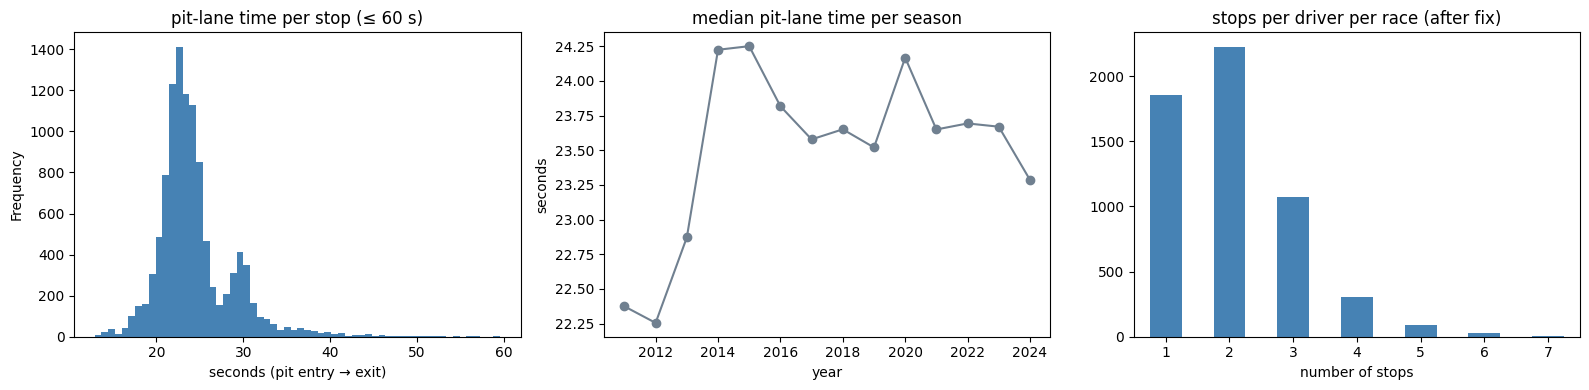

In [122]:
ps_yc = pit_stops_clean.merge(races_clean[["raceId", "year"]], on="raceId")
normal = ps_yc[ps_yc["is_long_stop"] == 0]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
normal["duration_s"].plot(kind="hist", bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("pit-lane time per stop (≤ 60 s)")
axes[0].set_xlabel("seconds (pit entry → exit)")

normal.groupby("year")["duration_s"].median().plot(ax=axes[1], marker="o", color="slategray")
axes[1].set_title("median pit-lane time per season")
axes[1].set_ylabel("seconds")

pit_stops_clean.groupby(["raceId", "driverId"])["stop"].max().value_counts().sort_index().plot(
    kind="bar", ax=axes[2], color="steelblue", rot=0)
axes[2].set_title("stops per driver per race (after fix)")
axes[2].set_xlabel("number of stops")
plt.tight_layout()
plt.show()

In [123]:
pit_stops_clean.to_csv(CLEAN_DIR / "pit_stops_clean.csv", index=False)
print("saved:", CLEAN_DIR / "pit_stops_clean.csv", pit_stops_clean.shape)
log_audit("pit_stops", pit_stops, pit_stops_clean)

saved: /kaggle/working/cleaned/pit_stops_clean.csv (11371, 6)


,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
pit_stops,11371,11371,7,6,0,0,0,2,0


**Pit stops — conclusion**
- 11,371 stops in 285 races (2011–2024), keys unique, no `\N`, and every driver-race exists in `results`.
- **Data errors fixed:** Monaco 2024 had `stop` and `lap` swapped in 7 rows (proven with lap times), and Britain 2014 / Singapore 2019 had stop numbering starting at 2. After renumbering, every driver-race has stops 1…n, and the maximum is 7 instead of 70.
- `duration_s` from `milliseconds` (matches the text exactly). 517 red-flag "stops" over 60 s are flagged `is_long_stop`, not deleted.
- `duration` is total **pit-lane** time (entry to exit, median ~23.5 s), not the stationary tyre change, so it varies with pit-lane length per circuit.
- Post-race → **never a feature**.
- `pit_stops_clean`: 11,371 × 6, saved to `data/cleaned/pit_stops_clean.csv`.

# 2. Integrity audit
All 14 tables are cleaned. This section checks the whole set together:
1. the raw CSVs were never modified (immutability)
2. every primary key is unique and non-null
3. every foreign key exists in its parent table, including composite `(raceId, driverId)` links
4. the overall effect of cleaning (before vs after)

## 2.1 Raw data unchanged
Right after loading we stored a hash of every raw table (`RAW_FINGERPRINT`). Here each raw table is hashed again, **in memory and re-read from disk**. Equal hashes prove that no cleaning step changed the raw data and that nothing was written back to the raw CSVs.

In [124]:
# re-read every raw CSV from disk and compare with the fingerprint taken right after loading
raw_check = pd.DataFrame([
    {"table": name,
     "unchanged_in_memory": pd.util.hash_pandas_object(globals()[name], index=False).sum() == fp,
     "unchanged_on_disk": pd.util.hash_pandas_object(pd.read_csv(DATA / f"{name}.csv"), index=False).sum() == fp}
    for name, fp in RAW_FINGERPRINT.items()
]).set_index("table")
assert raw_check.all().all(), "a raw table was modified"
raw_check

,unchanged_in_memory,unchanged_on_disk
table,,
circuits,True,True
constructors,True,True
constructor_results,True,True
constructor_standings,True,True
drivers,True,True
driver_standings,True,True
lap_times,True,True
pit_stops,True,True
qualifying,True,True


## 2.2 Primary keys
Each clean table must have a key that is **unique** and **non-null**. Composite keys are used where Ergast has no single id (`lap_times`, `pit_stops`) and for the grain of the per-race tables (`results`, `qualifying`, `sprint_results`, standings, `constructor_results`).

In [125]:
PRIMARY_KEYS = {
    "status": (status_clean, ["statusId"]),
    "circuits": (circuits_clean, ["circuitId"]),
    "constructors": (constructors_clean, ["constructorId"]),
    "drivers": (drivers_clean, ["driverId"]),
    "races": (races_clean, ["raceId"]),
    "results": (results_clean, ["raceId", "driverId"]),
    "qualifying": (qualifying_clean, ["raceId", "driverId"]),
    "sprint_results": (sprint_results_clean, ["raceId", "driverId"]),
    "driver_standings": (driver_standings_clean, ["raceId", "driverId"]),
    "constructor_standings": (constructor_standings_clean, ["raceId", "constructorId"]),
    "constructor_results": (constructor_results_clean, ["raceId", "constructorId"]),
    "lap_times": (lap_times_clean, ["raceId", "driverId", "lap"]),
    "pit_stops": (pit_stops_clean, ["raceId", "driverId", "stop"]),
}

pk_report = pd.DataFrame([
    {"table": t, "key": ", ".join(k), "rows": len(df),
     "null_keys": int(df[k].isna().any(axis=1).sum()), "duplicate_keys": int(df.duplicated(k).sum())}
    for t, (df, k) in PRIMARY_KEYS.items()
]).set_index("table")
assert (pk_report[["null_keys", "duplicate_keys"]] == 0).all().all()
pk_report

,key,rows,null_keys,duplicate_keys
table,,,,
status,statusId,139,0,0
circuits,circuitId,77,0,0
constructors,constructorId,212,0,0
drivers,driverId,861,0,0
races,raceId,1125,0,0
results,"raceId, driverId",26668,0,0
qualifying,"raceId, driverId",10494,0,0
sprint_results,"raceId, driverId",360,0,0
driver_standings,"raceId, driverId",34863,0,0


## 2.3 Foreign keys
Every foreign key must exist in the table it points to. Besides the single-column ids, we check **composite** links: every `(raceId, driverId)` in `qualifying`, `sprint_results`, `lap_times` and `pit_stops` must have a `results` row. Otherwise there would be laps or stops for a driver who was never entered in that race.

In [126]:
FOREIGN_KEYS = [
    ("races", races_clean, ["circuitId"], "circuits", circuits_clean),
    ("results", results_clean, ["raceId"], "races", races_clean),
    ("results", results_clean, ["driverId"], "drivers", drivers_clean),
    ("results", results_clean, ["constructorId"], "constructors", constructors_clean),
    ("results", results_clean, ["statusId"], "status", status_clean),
    ("qualifying", qualifying_clean, ["raceId", "driverId"], "results", results_clean),
    ("qualifying", qualifying_clean, ["constructorId"], "constructors", constructors_clean),
    ("sprint_results", sprint_results_clean, ["raceId", "driverId"], "results", results_clean),
    ("sprint_results", sprint_results_clean, ["statusId"], "status", status_clean),
    ("driver_standings", driver_standings_clean, ["raceId"], "races", races_clean),
    ("driver_standings", driver_standings_clean, ["driverId"], "drivers", drivers_clean),
    ("constructor_standings", constructor_standings_clean, ["raceId"], "races", races_clean),
    ("constructor_standings", constructor_standings_clean, ["constructorId"], "constructors", constructors_clean),
    ("constructor_results", constructor_results_clean, ["raceId"], "races", races_clean),
    ("constructor_results", constructor_results_clean, ["constructorId"], "constructors", constructors_clean),
    ("lap_times", lap_times_clean, ["raceId", "driverId"], "results", results_clean),
    ("pit_stops", pit_stops_clean, ["raceId", "driverId"], "results", results_clean),
]

def orphans(child, cols, parent):
    keys = child[cols].drop_duplicates()
    return int((~keys.set_index(cols).index.isin(parent.set_index(cols).index)).sum())

fk_report = pd.DataFrame([
    {"child": c, "key": ", ".join(k), "parent": p, "orphan_keys": orphans(cdf, k, pdf)}
    for c, cdf, k, p, pdf in FOREIGN_KEYS
])
assert (fk_report["orphan_keys"] == 0).all()
fk_report

,child,key,parent,orphan_keys
0,races,circuitId,circuits,0
1,results,raceId,races,0
2,results,driverId,drivers,0
3,results,constructorId,constructors,0
4,results,statusId,status,0
5,qualifying,"raceId, driverId",results,0
6,qualifying,constructorId,constructors,0
7,sprint_results,"raceId, driverId",results,0
8,sprint_results,statusId,status,0
9,driver_standings,raceId,races,0


## 2.4 Cleaning impact (before vs after)
Each table section logged its raw and clean shape with `log_audit`. Together they show what cleaning changed across the dataset.

,rows_raw,rows_clean,cols_raw,cols_clean,sentinel_cells_raw,sentinel_cells_clean,na_cells_clean,text_cols_raw,text_cols_clean
status,139,139,2,3,0,0,0,1,2
circuits,77,77,9,8,0,0,0,5,4
constructors,212,212,5,3,0,0,0,4,2
drivers,861,861,9,10,1559,0,1559,8,7
races,1125,1125,18,11,11349,0,75,14,2
results,26759,26668,18,22,122887,0,103272,9,3
qualifying,10494,10494,9,11,11600,0,11980,3,0
sprint_results,360,360,16,17,73,0,53,6,2
driver_standings,34863,34863,7,9,0,0,9576,1,0
constructor_standings,13391,13391,7,9,0,0,2760,1,0


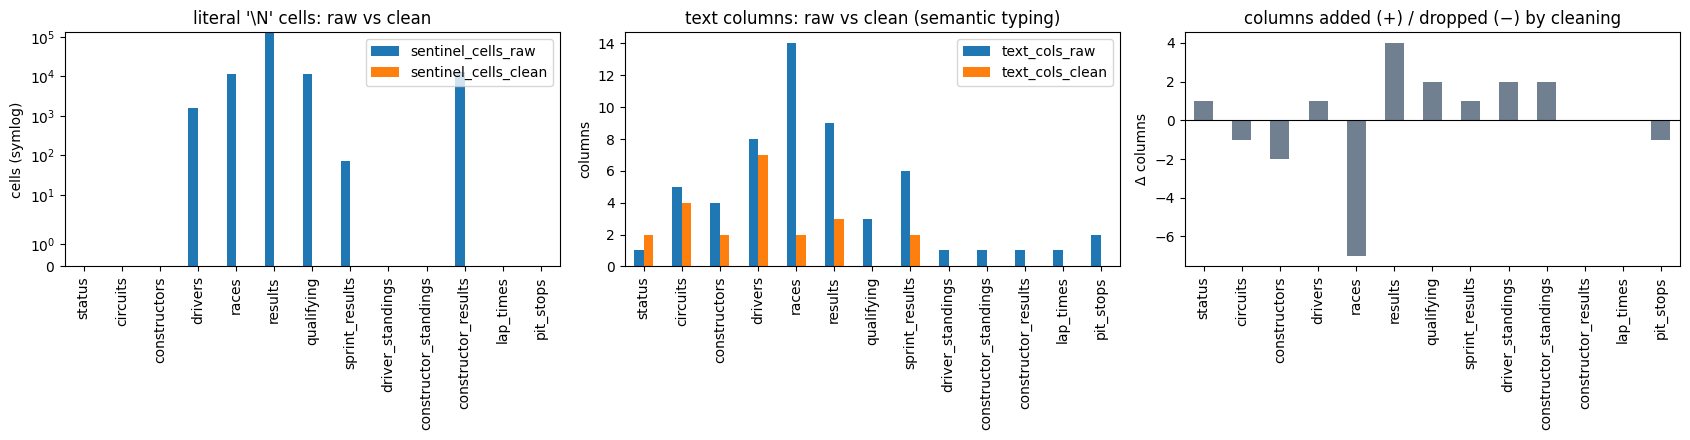

In [127]:
audit_df = pd.DataFrame(AUDIT).T.astype(int)
display(audit_df)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
audit_df[["sentinel_cells_raw", "sentinel_cells_clean"]].plot(kind="bar", ax=axes[0])
axes[0].set_yscale("symlog")
axes[0].set_title(r"literal '\N' cells: raw vs clean")
axes[0].set_ylabel("cells (symlog)")

audit_df[["text_cols_raw", "text_cols_clean"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("text columns: raw vs clean (semantic typing)")
axes[1].set_ylabel("columns")

(audit_df["cols_clean"] - audit_df["cols_raw"]).plot(kind="bar", ax=axes[2], color="slategray")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("columns added (+) / dropped (−) by cleaning")
axes[2].set_ylabel("Δ columns")
plt.tight_layout()
plt.show()

**Cleaning impact**
- **Sentinels:** every literal `\N` is gone (raw → 0 in every table). The missing values that remain are real NA, and each table section explains them as structural (era coverage, knockout qualifying, non-classified finishers, pre-2004 fastest laps).
- **Semantic typing:** text columns dropped sharply. Dates are datetimes, and lap, race, qualifying and pit times are seconds. What stays as text are true labels (names, refs, nationality, era, status).
- **Rows:** only `results` loses rows (−91 shared-drive duplicates). Every other table keeps all its rows: problems were fixed (Belgium 2024 times, Monaco 2024 pit stops) or flagged (`is_slow_lap`, `is_long_stop`, `is_disqualified`) instead of deleted.
- **Columns:** URLs and redundant text were dropped. Flags and lagged `pre_*` standings columns were added.

## 2.5 Saved outputs

In [128]:
written = sorted(p.name for p in CLEAN_DIR.glob("*.csv"))
expected = [f"{t}_clean.csv" for t in PRIMARY_KEYS]
print("missing outputs:", sorted(set(expected) - set(written)) or "none")
print(f"{len(written)} files in {CLEAN_DIR}:", written)
print("dropped tables (no clean file):", DROPPED_TABLES)

missing outputs: none
13 files in /kaggle/working/cleaned: ['circuits_clean.csv', 'constructor_results_clean.csv', 'constructor_standings_clean.csv', 'constructors_clean.csv', 'driver_standings_clean.csv', 'drivers_clean.csv', 'lap_times_clean.csv', 'pit_stops_clean.csv', 'qualifying_clean.csv', 'races_clean.csv', 'results_clean.csv', 'sprint_results_clean.csv', 'status_clean.csv']
dropped tables (no clean file): ['seasons']


# 3. Data-engineering questions
Each question is answered with a multi-hop join across the cleaned tables, a plot, and a short note on **grain**, **missingness** and the **pre-race cutoff**.

**Shared base table (`starts`):** one row per `(raceId, driverId)` from `results_clean` (grain already fixed in 1.7), joined to `races_clean` for `year`, `circuitId` and `era`. Two exclusions, the same ones the modeling table uses:
- **Indianapolis 500 (1950–60):** flagged by name in 1.6. A separate series in practice, with its own grid structure and almost no F1 regulars.
- **Drivers who did not start** (`did_not_start`, i.e. `positionText` F/W, built in 1.7): they have no grid slot, so they cannot convert a start and cannot retire from a race.

Rates are reported with **Wilson 95% confidence intervals**, because many circuit and constructor groups are small, and a normal-approximation interval misbehaves near 0 or 1.

In [129]:
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.contingency_tables import StratifiedTable
import statsmodels.formula.api as smf
from scipy.stats import spearmanr

FIG_DIR = CLEAN_DIR.parent / "figures"          # plots reused in the report
FIG_DIR.mkdir(parents=True, exist_ok=True)

def add_wilson(df, k="podiums", n="n", prefix=""):
    lo, hi = proportion_confint(df[k], df[n], alpha=0.05, method="wilson")
    df[f"{prefix}ci_lo"], df[f"{prefix}ci_hi"] = lo, hi
    return df

starts = (
    results_clean.loc[~results_clean["did_not_start"]]
    .merge(races_clean[["raceId", "year", "round", "circuitId", "era", "is_indy500"]], on="raceId", how="left")
    .query("is_indy500 == 0")
    .merge(circuits_clean[["circuitId", "name", "country"]].rename(columns={"name": "circuit"}), on="circuitId", how="left")
)
assert not starts.duplicated(["raceId", "driverId"]).any()
print("result rows:", len(results_clean),
      "| minus did-not-start:", int(results_clean["did_not_start"].sum()),
      "| minus Indy 500 starters:", int((~results_clean["did_not_start"]).sum() - len(starts)),
      "| starts:", len(starts))

result rows: 26668 | minus did-not-start: 1701 | minus Indy 500 starters: 381 | starts: 24586


## 3.1 DEQ1: Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Definitions**
- **Front row by grid:** `results.grid ∈ {1, 2}`, the slot the car actually started from **after penalties**. Available for every year, so this is the main ranking.
- **Front row by qualifying:** `qualifying.position ∈ {1, 2}`, the session result **before penalties**. `qualifying` only covers 1994+ and is patchy in 1996–2002 (section 1.8), so this view is limited to **2003–2024**, where coverage is ~100%.
- **Conversion rate** = podiums / front-row starters at that circuit. Grain: one row per front-row driver per race (2 per race).
- **Periods:** *pre-hybrid* (1950–2013) vs *hybrid onward* (2014–2024, which includes the 2022+ ground-effect cars).
- **Minimum sample:** a circuit is ranked in a period only if it hosted **≥ 7 races** there (≥ 14 front-row starts). The 2014–2024 window has at most 11 seasons (~22 front-row starts per circuit), so a stricter cut would leave almost nothing to rank. Smaller circuits are still shown in the full table.

**Pre-race cutoff:** both grid and qualifying position are fixed before lights out. The podium is only the outcome being counted.

In [130]:
FR_MIN_STARTS = 14   # = 7 races x 2 front-row cars

fr = starts.loc[starts["grid"].isin([1, 2])].copy()
fr["period"] = np.where(fr["year"] >= 2014, "2014-2024", "1950-2013")
print("front-row starts per race:", fr.groupby("raceId").size().value_counts().to_dict())

period_base = fr.groupby("period")["podium"].agg(n="size", podiums="sum", rate="mean")
display(period_base.round(3))

deq1 = (fr.groupby(["circuitId", "circuit", "period"])["podium"]
        .agg(n="size", podiums="sum", rate="mean").reset_index())
deq1 = add_wilson(deq1)
deq1["lift_vs_period"] = deq1["rate"] - deq1["period"].map(period_base["rate"])
deq1["ranked"] = deq1["n"] >= FR_MIN_STARTS
deq1["rank"] = (deq1[deq1["ranked"]].groupby("period")["rate"]
                .rank(ascending=False, method="min"))
print("circuits ranked:", deq1[deq1["ranked"]].groupby("period").size().to_dict())

front-row starts per race: {2: 1089, 1: 18, 3: 3, 4: 2}


,n,podiums,rate
period,,,
1950-2013,1760,994,0.565
2014-2024,453,345,0.762


circuits ranked: {'1950-2013': 37, '2014-2024': 19}


In [131]:
# top / bottom of each period's ranking
for p in ["1950-2013", "2014-2024"]:
    t = (deq1[(deq1["period"] == p) & deq1["ranked"]].sort_values(["rate", "n"], ascending=[False, False])
         [["rank", "circuit", "n", "podiums", "rate", "ci_lo", "ci_hi", "lift_vs_period"]])
    print(f"\n{p}: top 8 and bottom 3 of {len(t)} ranked circuits")
    display(pd.concat([t.head(8), t.tail(3)]).round(3))


1950-2013: top 8 and bottom 3 of 37 ranked circuits


,rank,circuit,n,podiums,rate,ci_lo,ci_hi,lift_vs_period
14,1.0,Circuit de Nevers Magny-Cours,35,29,0.829,0.673,0.919,0.264
8,2.0,Istanbul Park,14,11,0.786,0.524,0.924,0.221
33,2.0,Indianapolis Motor Speedway,14,11,0.786,0.524,0.924,0.221
38,4.0,Suzuka Circuit,50,35,0.700,0.562,0.809,0.135
2,4.0,Sepang International Circuit,30,21,0.700,0.521,0.833,0.135
19,6.0,Hungaroring,56,38,0.679,0.548,0.786,0.114
6,7.0,Circuit de Barcelona-Catalunya,45,30,0.667,0.521,0.786,0.102
4,7.0,Bahrain International Circuit,18,12,0.667,0.437,0.837,0.102
57,35.0,Brands Hatch,28,11,0.393,0.236,0.576,-0.172
55,36.0,Autódromo Internacional Nelson Piquet,20,7,0.350,0.181,0.567,-0.215



2014-2024: top 8 and bottom 3 of 19 ranked circuits


,rank,circuit,n,podiums,rate,ci_lo,ci_hi,lift_vs_period
11,1.0,Circuit de Monaco,19,17,0.895,0.686,0.971,0.133
39,2.0,Suzuka Circuit,18,16,0.889,0.672,0.969,0.127
41,3.0,Yas Marina Circuit,22,19,0.864,0.667,0.953,0.102
7,4.0,Circuit de Barcelona-Catalunya,22,18,0.818,0.615,0.927,0.057
23,4.0,Circuit de Spa-Francorchamps,22,18,0.818,0.615,0.927,0.057
93,6.0,Sochi Autodrom,16,13,0.812,0.570,0.934,0.051
90,7.0,Circuit of the Americas,20,16,0.800,0.584,0.919,0.038
32,8.0,Autódromo José Carlos Pace,19,15,0.789,0.567,0.915,0.028
94,17.0,Baku City Circuit,16,10,0.625,0.386,0.815,-0.137
50,18.0,Autódromo Hermanos Rodríguez,18,11,0.611,0.386,0.797,-0.150


In [132]:
# ranking change for circuits ranked in BOTH periods
wide = deq1[deq1["ranked"]].pivot_table(index="circuit", columns="period",
                                        values=["rate", "rank", "n", "ci_lo", "ci_hi"])
both = wide.dropna().copy()
both.columns = [f"{a}_{b}" for a, b in both.columns]
both["rank_change"] = both["rank_1950-2013"] - both["rank_2014-2024"]   # > 0 = moved up
# re-rank inside the common set so ranks are comparable
both["rank_pre_common"] = both["rate_1950-2013"].rank(ascending=False, method="min")
both["rank_post_common"] = both["rate_2014-2024"].rank(ascending=False, method="min")
rho, p_rho = spearmanr(both["rate_1950-2013"], both["rate_2014-2024"])
print(f"circuits ranked in both periods: {len(both)} | Spearman rho(pre, post) = {rho:.2f} (p = {p_rho:.2f})")
display(both.sort_values("rate_2014-2024", ascending=False)
        [["n_1950-2013", "rate_1950-2013", "rank_pre_common", "n_2014-2024", "rate_2014-2024", "rank_post_common"]]
        .round(3))


circuits ranked in both periods: 14 | Spearman rho(pre, post) = -0.11 (p = 0.72)


,n_1950-2013,rate_1950-2013,rank_pre_common,n_2014-2024,rate_2014-2024,rank_post_common
circuit,,,,,,
Circuit de Monaco,120.0,0.492,13.0,19.0,0.895,1.0
Suzuka Circuit,50.0,0.700,1.0,18.0,0.889,2.0
Circuit de Barcelona-Catalunya,45.0,0.667,3.0,22.0,0.818,3.0
Circuit de Spa-Francorchamps,89.0,0.551,10.0,22.0,0.818,3.0
Autódromo José Carlos Pace,62.0,0.597,7.0,19.0,0.789,5.0
Shanghai International Circuit,20.0,0.650,5.0,14.0,0.786,6.0
Circuit Gilles Villeneuve,68.0,0.529,11.0,18.0,0.778,7.0
Silverstone Circuit,94.0,0.564,8.0,24.0,0.750,8.0
Red Bull Ring,50.0,0.520,12.0,26.0,0.731,9.0


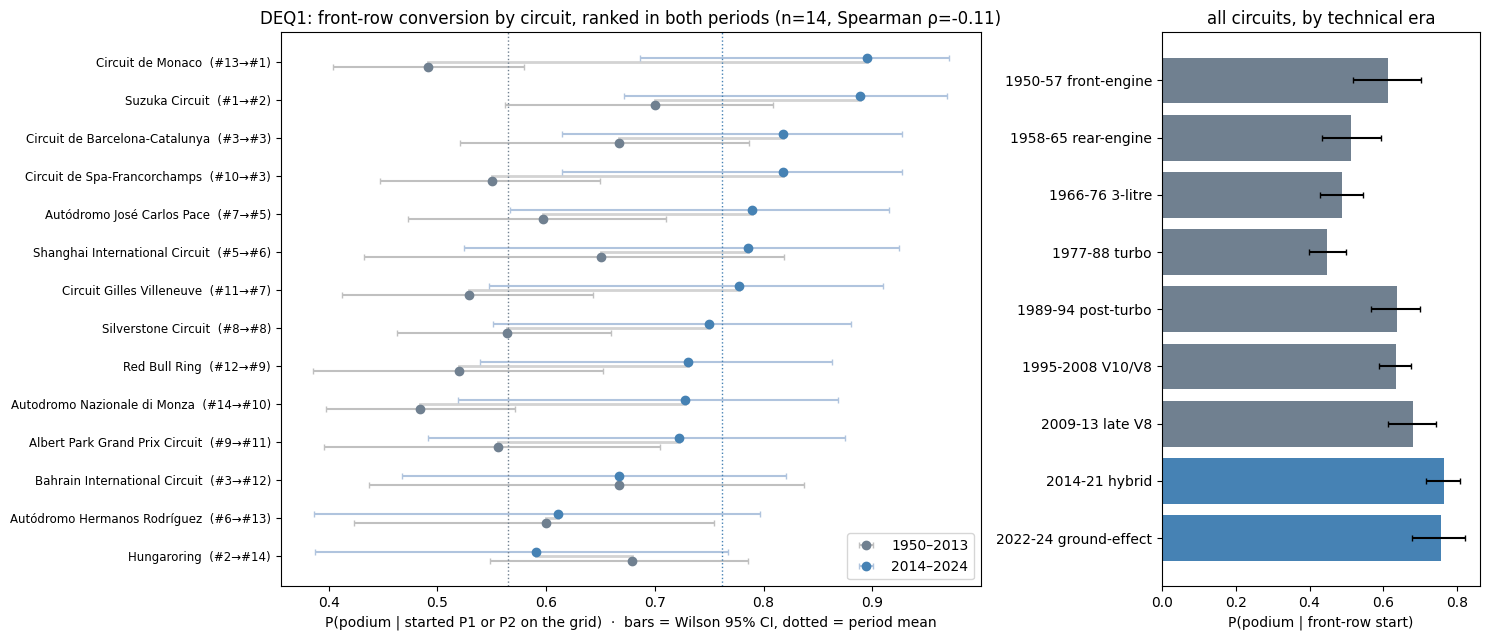

era,1950-57 front-engine,1958-65 rear-engine,1966-76 3-litre,1977-88 turbo,1989-94 post-turbo,1995-2008 V10/V8,2009-13 late V8,2014-21 hybrid,2022-24 ground-effect
n,106.000,148.000,277.000,375.000,192.000,474.000,188.000,318.000,135.000
rate,0.613,0.514,0.487,0.448,0.635,0.633,0.681,0.764,0.756


In [133]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [2.2, 1]})

b = both.sort_values("rate_2014-2024")
y = np.arange(len(b))
ax = axes[0]
for i, (_, row) in enumerate(b.iterrows()):
    ax.plot([row["rate_1950-2013"], row["rate_2014-2024"]], [i, i], color="lightgray", lw=2, zorder=1)
ax.errorbar(b["rate_1950-2013"], y - 0.12,
            xerr=[b["rate_1950-2013"] - b["ci_lo_1950-2013"], b["ci_hi_1950-2013"] - b["rate_1950-2013"]],
            fmt="o", color="slategray", ecolor="silver", capsize=2, label="1950–2013")
ax.errorbar(b["rate_2014-2024"], y + 0.12,
            xerr=[b["rate_2014-2024"] - b["ci_lo_2014-2024"], b["ci_hi_2014-2024"] - b["rate_2014-2024"]],
            fmt="o", color="steelblue", ecolor="lightsteelblue", capsize=2, label="2014–2024")
ax.set_yticks(y)
ax.set_yticklabels([f"{c}  (#{int(r1)}→#{int(r2)})" for c, r1, r2 in
                    zip(b.index, b["rank_pre_common"], b["rank_post_common"])], fontsize=8.5)
ax.axvline(period_base.loc["1950-2013", "rate"], color="slategray", ls=":", lw=1)
ax.axvline(period_base.loc["2014-2024", "rate"], color="steelblue", ls=":", lw=1)
ax.set_xlabel("P(podium | started P1 or P2 on the grid)  ·  bars = Wilson 95% CI, dotted = period mean")
ax.set_title(f"DEQ1: front-row conversion by circuit, ranked in both periods (n={len(b)}, Spearman ρ={rho:.2f})")
ax.legend(loc="lower right")

ax = axes[1]
era_rate = (fr.groupby("era", sort=False)["podium"].agg(n="size", podiums="sum", rate="mean"))
era_rate = add_wilson(era_rate)
era_rate = era_rate.loc[[e for e in ERA_LABELS if e in era_rate.index]]
ax.barh(era_rate.index, era_rate["rate"], xerr=[era_rate["rate"] - era_rate["ci_lo"], era_rate["ci_hi"] - era_rate["rate"]],
        color=["steelblue" if e.startswith(("2014", "2022")) else "slategray" for e in era_rate.index], capsize=2)
ax.invert_yaxis()
ax.set_xlabel("P(podium | front-row start)")
ax.set_title("all circuits, by technical era")
plt.tight_layout()
plt.savefig(FIG_DIR / "deq1_front_row_by_circuit.png", dpi=150, bbox_inches="tight")
plt.show()
display(era_rate[["n", "rate"]].round(3).T)

### 3.1.1 Qualifying position vs grid position (2003–2024)
The brief asks us to keep the two apart. A driver can **qualify** on the front row and **start** further back (grid penalty, pit-lane start), or be **promoted** to the front row when someone ahead is penalised. Here both definitions are computed on the same window (2003–2024, full qualifying coverage), so any difference comes only from grid changes, not from different years.

For the qualifying definition we keep every front-row qualifier, **including** the rare one who then did not start: they qualified there and failed to convert it.

In [134]:
q_fr = (qualifying_clean[["raceId", "driverId", "position"]].rename(columns={"position": "qual_pos"})
        .merge(results_clean[["raceId", "driverId", "grid", "podium", "did_not_start"]], on=["raceId", "driverId"], how="inner")
        .merge(races_clean[["raceId", "year", "circuitId", "is_indy500"]], on="raceId")
        .query("year >= 2003 and is_indy500 == 0"))
q_fr["quali_front_row"] = q_fr["qual_pos"].isin([1, 2])
q_fr["grid_front_row"] = q_fr["grid"].isin([1, 2]) & ~q_fr["did_not_start"]

# where the two definitions disagree
cross = pd.crosstab(q_fr["quali_front_row"], q_fr["grid_front_row"], margins=True)
cross.index.name, cross.columns.name = "qualified P1/P2", "started P1/P2"
display(cross)

groups = {
    "qualified AND started on front row": q_fr["quali_front_row"] & q_fr["grid_front_row"],
    "qualified front row, started further back (penalty / pit lane)": q_fr["quali_front_row"] & ~q_fr["grid_front_row"],
    "promoted to front row (qualified P3+)": ~q_fr["quali_front_row"] & q_fr["grid_front_row"],
}
moved = pd.DataFrame({k: q_fr.loc[m, "podium"].agg(["size", "sum", "mean"]) for k, m in groups.items()}).T
moved.columns = ["n", "podiums", "rate"]
display(moved.round(3))
display(q_fr.loc[q_fr["quali_front_row"] & ~q_fr["grid_front_row"], "grid"].describe()[["count", "mean", "50%", "max"]].round(1)
        .rename("grid slot of demoted front-row qualifiers"))

started P1/P2,False,True,All
qualified P1/P2,,,
False,8054,36,8090
True,41,815,856
All,8095,851,8946


,n,podiums,rate
qualified AND started on front row,815.0,594.0,0.729
"qualified front row, started further back (penalty / pit lane)",41.0,11.0,0.268
promoted to front row (qualified P3+),36.0,23.0,0.639


count    41.0
mean      7.9
50%       7.0
max      24.0
Name: grid slot of demoted front-row qualifiers, dtype: float64

In [135]:
q_fr["period"] = np.where(q_fr["year"] >= 2014, "2014-2024", "2003-2013")
q_fr = q_fr.merge(circuits_clean[["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId")

def conv(df, flag):
    t = df[df[flag]].groupby(["circuit", "period"])["podium"].agg(n="size", podiums="sum", rate="mean").reset_index()
    t["def"] = flag
    return t

modern = pd.concat([conv(q_fr, "quali_front_row"), conv(q_fr, "grid_front_row")])
modern = modern[modern["n"] >= FR_MIN_STARTS]
mw = modern.pivot_table(index=["circuit", "period"], columns="def", values="rate").dropna()
mw["diff_grid_minus_quali"] = mw["grid_front_row"] - mw["quali_front_row"]
print("circuit-periods ranked under both definitions:", len(mw))
print("mean |grid − quali| rate difference:", round(mw["diff_grid_minus_quali"].abs().mean(), 3),
      "| largest:", mw["diff_grid_minus_quali"].abs().idxmax(), round(mw["diff_grid_minus_quali"].abs().max(), 3))
for p in ["2003-2013", "2014-2024"]:
    sub = mw.xs(p, level="period")
    rho_d, _ = spearmanr(sub["grid_front_row"], sub["quali_front_row"])
    print(f"{p}: Spearman rho between the two definitions' circuit rankings = {rho_d:.2f} ({len(sub)} circuits)")

# modern-only ranking change (removes the 1950s reliability effect from the comparison)
mq = modern[modern["def"] == "grid_front_row"].pivot_table(index="circuit", columns="period", values="rate").dropna()
rho_m, p_m = spearmanr(mq["2003-2013"], mq["2014-2024"])
print(f"\ngrid definition, 2003–2013 vs 2014–2024: {len(mq)} circuits, Spearman rho = {rho_m:.2f} (p = {p_m:.2f})")
display(mq.assign(change=mq["2014-2024"] - mq["2003-2013"]).sort_values("2014-2024", ascending=False).round(3))

circuit-periods ranked under both definitions: 35
mean |grid − quali| rate difference: 0.023 | largest: ('Autódromo José Carlos Pace', '2014-2024') 0.139
2003-2013: Spearman rho between the two definitions' circuit rankings = 0.91 (16 circuits)
2014-2024: Spearman rho between the two definitions' circuit rankings = 0.88 (19 circuits)

grid definition, 2003–2013 vs 2014–2024: 12 circuits, Spearman rho = 0.38 (p = 0.23)


period,2003-2013,2014-2024,change
circuit,,,
Circuit de Monaco,0.773,0.895,0.122
Suzuka Circuit,0.722,0.889,0.167
Circuit de Barcelona-Catalunya,0.682,0.818,0.136
Circuit de Spa-Francorchamps,0.722,0.818,0.096
Autódromo José Carlos Pace,0.591,0.789,0.199
Shanghai International Circuit,0.650,0.786,0.136
Circuit Gilles Villeneuve,0.600,0.778,0.178
Silverstone Circuit,0.727,0.750,0.023
Autodromo Nazionale di Monza,0.773,0.727,-0.045


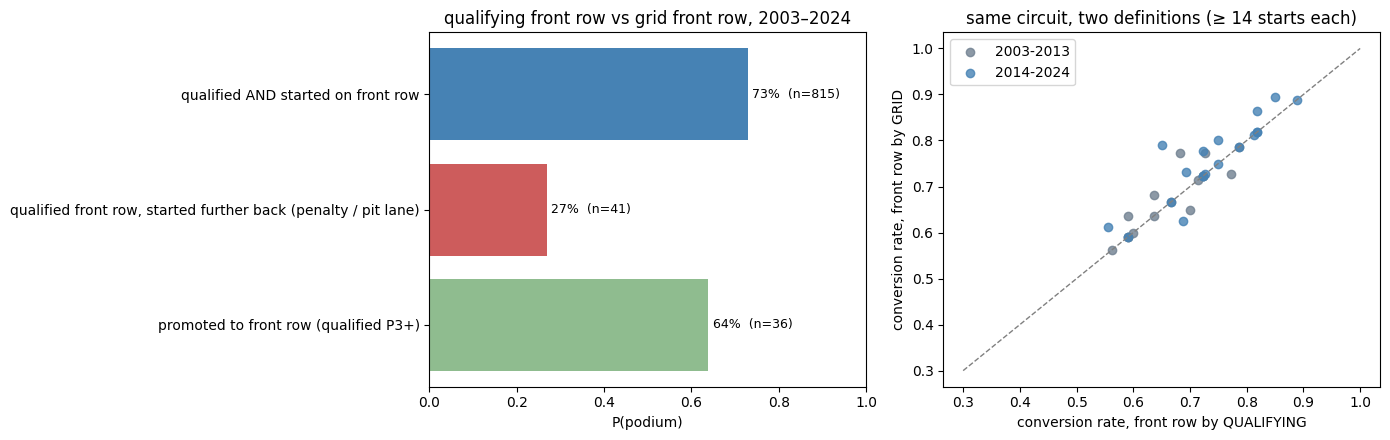

In [136]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ax.barh(moved.index, moved["rate"], color=["steelblue", "indianred", "darkseagreen"])
for i, (n, r_) in enumerate(zip(moved["n"], moved["rate"])):
    ax.text(r_ + 0.01, i, f"{r_:.0%}  (n={int(n)})", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("P(podium)")
ax.set_title("qualifying front row vs grid front row, 2003–2024")

ax = axes[1]
for p, c in [("2003-2013", "slategray"), ("2014-2024", "steelblue")]:
    sub = mw.xs(p, level="period")
    ax.scatter(sub["quali_front_row"], sub["grid_front_row"], color=c, label=p, alpha=0.8)
ax.plot([0.3, 1], [0.3, 1], color="gray", ls="--", lw=1)
ax.set_xlabel("conversion rate, front row by QUALIFYING")
ax.set_ylabel("conversion rate, front row by GRID")
ax.set_title("same circuit, two definitions (≥ 14 starts each)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "deq1_quali_vs_grid.png", dpi=150, bbox_inches="tight")
plt.show()

### DEQ1 — Answer
**Which circuits convert a front row best?** In the hybrid era onward (2014–2024), **Monaco (89.5%, 17/19), Suzuka (88.9%, 16/18) and Yas Marina (86.4%, 19/22)** convert a front-row start into a podium most often, followed by Barcelona and Spa (81.8% each). The weakest are **Hungaroring (59.1%, 13/22), Mexico City (61.1%) and Baku (62.5%)**. Before 2014 (1950–2013), the top circuits were **Magny-Cours (82.9%, 29/35), Istanbul Park and Indianapolis (US GP 2000–07; 78.6% each), then Suzuka and Sepang (70.0%)**, and the bottom were Detroit (28.6%), Jacarepaguá (35.0%) and Brands Hatch (39.3%).

**Does the ranking change after 2014? Yes, substantially.**
- The 14 circuits ranked in both periods have a rank correlation of **ρ = −0.11 (p = 0.72)**, i.e. the pre-2014 order says almost nothing about the post-2014 order. **Monaco moves #13 → #1** (49.2% → 89.5%, non-overlapping CIs), Spa #10 → #3 and Canada #11 → #7, while **Hungaroring falls #2 → #14** and Bahrain #3 → #12. Suzuka and Barcelona stay near the top in both periods.
- Part of the shift is an **era-wide level change**: front-row conversion rose from **56.5% (1,760 starts) to 76.2% (453 starts)**. It was 45% in the 1977–88 turbo era and is 76% in both the 2014–21 and 2022–24 eras (era plot). More reliable cars and dominant teams make a front-row start safer everywhere, so rankings are compared **within** each period, not on raw rates.
- A modern-only check (2003–2013 vs 2014–2024, both with full qualifying coverage) still shows only weak persistence: **ρ = 0.38 (p = 0.23)** across 12 circuits. Monaco was already 77% in 2003–13, so the big Monaco jump against the full 1950–2013 window is partly the low-reliability early decades.

**Qualifying vs grid (2003–2024).** 856 drivers qualified P1/P2. **41 of them (4.8%) started further back** (median grid slot 7, after a penalty or a pit-lane start) and converted only **26.8%**. 36 drivers were **promoted** onto the front row from P3+ and converted **63.9%**, close to the 72.9% of drivers who both qualified and started there. So the **starting slot, not the qualifying result, carries the podium signal**. At circuit level the two definitions rank circuits almost the same way (ρ = 0.91 for 2003–13, 0.88 for 2014–24; mean gap 2.3 pp, largest Interlagos 2014–24 at 13.9 pp), because penalties hit the front row rarely.

**Grain, missingness, cutoff**
- Grain: one row per front-row starter per race. 1,089 races have exactly 2. 18 races have 1: in 5 the other front-row driver did not start (excluded), and in 13 no second car is recorded with grid 1–2, e.g. it started from the pit lane (`grid = 0`). 5 races from 1952–64 have 3–4, because early records repeat grid numbers.
- Missingness: `grid` is complete for every year, so the grid ranking uses 1950–2024. The qualifying view is restricted to 2003+, because `qualifying` is patchy before then (1.8).
- Cutoff: grid and qualifying are both fixed before the start. Only the podium is post-race, and it is the outcome counted.

**Limitations:** post-2014 circuit samples are small (14–26 front-row starts), so the 95% intervals are about ±0.15–0.25 wide, and only large moves (Monaco up, Hungaroring down) are clearly beyond noise. Circuit layouts changed over time (e.g. Barcelona chicane, Yas Marina 2021 redesign) under the same `circuitId`.

**For feature engineering:** grid position is a stronger podium signal than qualifying position when the two differ, which supports **`grid` as the primary start feature**. A `grid − qualifying` delta (penalty indicator, 2003+) is also a candidate. Circuit identity changes meaning across eras, so a static circuit effect learned on ≤ 2019 data may not transfer.

## 3.2 DEQ2: Do drivers podium more often at home, after controlling for starting position?

**Join path:** `results_clean` → `races_clean` (circuit) → `circuits_clean.country` and `results_clean` → `drivers_clean.home_countries` (nationality mapped to a country in 1.5; dual nationalities count both). `is_home` = the circuit's country is one of the driver's home countries.

**Grain and filters:** one row per `(raceId, driverId)` start, Indy 500 excluded. We also drop the 87 **pit-lane starts** (`grid = 0`): they have no comparable grid slot to control for.

**Why a control is needed:** home and away drivers do not start from the same places. In the 1950s–60s, home races drew many local one-off entrants who started at the back, so a raw home-vs-away comparison mixes "home" with "slow car". We compare like with like in three ways:
1. **Stratified rates** inside grid bands (P1, P2–3, P4–6, P7–10, P11+)
2. **Cochran–Mantel–Haenszel (CMH)** pooled odds ratio across grid strata (one stratum per grid slot 1–20, 21+ pooled)
3. **Logistic regression** `podium ~ is_home + C(grid)`, with standard errors **clustered by driver** (the same driver appears many times). A second model also controls for **era** and the team's **pre-race** constructor standing (lagged, from 1.11), so a home driver in a strong car is not counted as home advantage.

**Pre-race cutoff:** nationality, circuit, grid and the lagged standings are all known before the start.

In [137]:
h = (starts.loc[starts["grid"] >= 1]
     .merge(drivers_clean[["driverId", "nationality", "home_countries"]], on="driverId", how="left"))
h["is_home"] = [c in str(hc).split("|") for c, hc in zip(h["country"], h["home_countries"])]
h["can_be_home"] = h["home_countries"].fillna("") != ""
h["grid_band"] = pd.cut(h["grid"], [0, 1, 3, 6, 10, 99], labels=["P1", "P2-3", "P4-6", "P7-10", "P11+"])
h["grid_c"] = h["grid"].clip(upper=21)      # 21 = 21st or further back

# lagged constructor strength (pre-race) -> band; 'none' = season opener / pre-1958 / no row
h = h.merge(constructor_standings_clean[["raceId", "constructorId", "pre_constructor_position"]],
            on=["raceId", "constructorId"], how="left")
h["team_band"] = pd.cut(h["pre_constructor_position"], [0, 1, 3, 6, 99], labels=["1", "2-3", "4-6", "7+"]).astype(str)
h.loc[h["pre_constructor_position"].isna(), "team_band"] = "none"
h["home_i"] = h["is_home"].astype(int)

print("starts:", len(h), "| home starts:", int(h["is_home"].sum()), f"({h['is_home'].mean():.1%})",
      "| pit-lane starts dropped:", int((starts['grid'] == 0).sum()))
raw = h.groupby("is_home")["podium"].agg(n="size", podiums="sum", rate="mean")
display(add_wilson(raw).round(3))
display(h.groupby("is_home")["grid"].describe()[["mean", "25%", "50%", "75%"]].round(1)
        .rename(index={False: "away", True: "home"}))

starts: 24499 | home starts: 1928 (7.9%) | pit-lane starts dropped: 87


,n,podiums,rate,ci_lo,ci_hi
is_home,,,,,
False,22571,3129,0.139,0.134,0.143
True,1928,230,0.119,0.106,0.135


,mean,25%,50%,75%
is_home,,,,
away,11.7,6.0,11.0,17.0
home,12.7,7.0,13.0,18.0


In [138]:
strat = h.groupby(["grid_band", "is_home"], observed=True)["podium"].agg(n="size", podiums="sum", rate="mean").reset_index()
strat = add_wilson(strat)
display(strat.pivot(index="grid_band", columns="is_home", values=["n", "rate"]).round(3))

# CMH across individual grid slots
tables = []
for g_, d in h.groupby("grid_c"):
    t = pd.crosstab(d["is_home"], d["podium"]).reindex(index=[True, False], columns=[1, 0], fill_value=0).values
    if (t.sum(axis=1) > 0).all() and t[:, 0].sum() > 0:     # need both groups and at least one podium
        tables.append(t)
cmh = StratifiedTable(tables)
cmh_lo, cmh_hi = cmh.oddsratio_pooled_confint()
cmh_test = cmh.test_null_odds()
print(f"CMH pooled OR (home vs away, within grid slot): {cmh.oddsratio_pooled:.2f} "
      f"[{cmh_lo:.2f}, {cmh_hi:.2f}], p = {cmh_test.pvalue:.3f}, strata = {len(tables)}")
print(f"Breslow-Day homogeneity p = {cmh.test_equal_odds().pvalue:.3f}  (low p = the OR differs across grid slots)")

n           rate       
is_home      False   True   False  True 
grid_band                               
P1          1028.0    80.0  0.650  0.612
P2-3        2067.0   148.0  0.511  0.554
P4-6        3102.0   224.0  0.262  0.272
P7-10       4101.0   336.0  0.094  0.074
P11+       12273.0  1140.0  0.017  0.011

CMH pooled OR (home vs away, within grid slot): 0.97 [0.81, 1.15], p = 0.724, strata = 21
Breslow-Day homogeneity p = 0.162  (low p = the OR differs across grid slots)


In [139]:
def home_or(df, formula, label):
    m = smf.logit(formula, data=df).fit(disp=0, cov_type="cluster", cov_kwds={"groups": df["driverId"]})
    b, se = m.params["home_i"], m.bse["home_i"]
    return {"model": label, "rows": int(m.nobs), "OR_home": np.exp(b),
            "ci_lo": np.exp(b - 1.96 * se), "ci_hi": np.exp(b + 1.96 * se), "p": m.pvalues["home_i"]}

specs = [
    (h, "podium ~ home_i", "1 raw (no control)"),
    (h, "podium ~ home_i + C(grid_c)", "2 grid slot"),
    (h, "podium ~ home_i + C(grid_c) + C(era) + C(team_band)", "3 grid + era + team strength"),
    (h[h["year"] >= 2003], "podium ~ home_i + C(grid_c)", "4 grid, 2003–2024 only"),
    (h[h["year"] >= 2003], "podium ~ home_i + C(grid_c) + C(team_band)", "5 grid + team, 2003–2024"),
    (h[h["can_be_home"]], "podium ~ home_i + C(grid_c)", "6 grid, drivers with a home circuit only"),
]
or_table = pd.DataFrame([home_or(*s) for s in specs]).set_index("model")
display(or_table.round(3))

,rows,OR_home,ci_lo,ci_hi,p
model,,,,,
1 raw (no control),24499,0.842,0.708,1.001,0.051
2 grid slot,24499,0.970,0.799,1.177,0.754
3 grid + era + team strength,24499,0.977,0.797,1.197,0.822
"4 grid, 2003–2024 only",8837,0.776,0.415,1.450,0.427
"5 grid + team, 2003–2024",8837,0.811,0.439,1.498,0.503
"6 grid, drivers with a home circuit only",22175,0.975,0.805,1.181,0.795


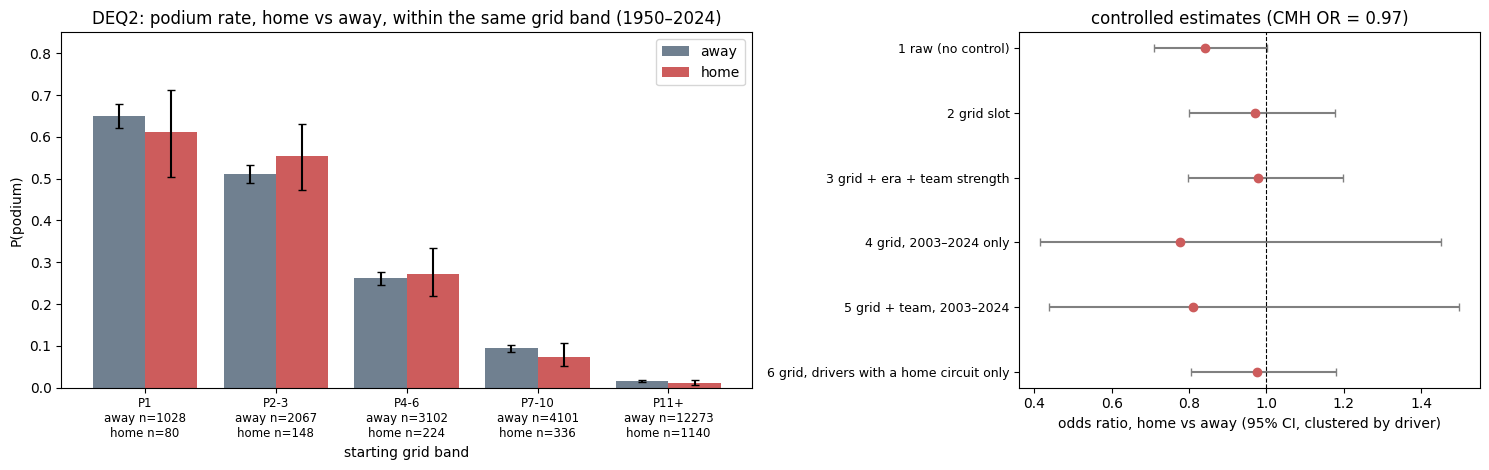

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
bands = list(strat["grid_band"].cat.categories) if hasattr(strat["grid_band"], "cat") else ["P1", "P2-3", "P4-6", "P7-10", "P11+"]
x = np.arange(len(bands))
for off, home_flag, color, lab in [(-0.2, False, "slategray", "away"), (0.2, True, "indianred", "home")]:
    s_ = strat[strat["is_home"] == home_flag].set_index("grid_band").reindex(bands)
    ax.bar(x + off, s_["rate"], width=0.4, color=color, label=lab,
           yerr=[s_["rate"] - s_["ci_lo"], s_["ci_hi"] - s_["rate"]], capsize=3)
ns = {f: strat[strat["is_home"] == f].set_index("grid_band").reindex(bands)["n"] for f in (False, True)}
ax.set_xticks(x)
ax.set_xticklabels([f"{b_}\naway n={int(ns[False][b_])}\nhome n={int(ns[True][b_])}" for b_ in bands], fontsize=8.5)
ax.set_xlabel("starting grid band")
ax.set_ylabel("P(podium)")
ax.set_ylim(0, 0.85)
ax.set_title("DEQ2: podium rate, home vs away, within the same grid band (1950–2024)")
ax.legend()

ax = axes[1]
ot = or_table.iloc[::-1]
ax.errorbar(ot["OR_home"], np.arange(len(ot)), xerr=[ot["OR_home"] - ot["ci_lo"], ot["ci_hi"] - ot["OR_home"]],
            fmt="o", color="indianred", ecolor="gray", capsize=3)
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_yticks(np.arange(len(ot)))
ax.set_yticklabels(ot.index, fontsize=9)
ax.set_xlabel("odds ratio, home vs away (95% CI, clustered by driver)")
ax.set_title(f"controlled estimates (CMH OR = {cmh.oddsratio_pooled:.2f})")
plt.tight_layout()
plt.savefig(FIG_DIR / "deq2_home_advantage.png", dpi=150, bbox_inches="tight")
plt.show()

### DEQ2 — Answer
**No. Once starting position is controlled for, drivers do not podium more often at home.**
- **Raw comparison:** home 11.9% (230/1,928) vs away 13.9% (3,129/22,571), so home drivers look *worse* (OR 0.84, p = 0.051). But home drivers also **start further back** (median grid 13 vs 11), mostly local one-off entrants at their home race in the big-field decades. So the raw gap is about grid position, not about being at home.
- **Same grid band, home vs away:** P1 61.2% vs 65.0%, P2–3 55.4% vs 51.1%, P4–6 27.2% vs 26.2%, P7–10 7.4% vs 9.4%, P11+ 1.1% vs 1.7%. There is no consistent direction, and every pair of confidence intervals overlaps.
- **Pooled across grid slots:** CMH odds ratio **0.97 [0.81, 1.15], p = 0.72**. Breslow–Day p = 0.16, so no evidence that the home effect differs by grid slot.
- **Logistic regression (SE clustered by driver):** grid slot only, OR **0.97 [0.80, 1.18]**. Adding era and the team's pre-race championship position gives **0.98 [0.80, 1.20]**. Restricting to 2003–2024 gives 0.78 [0.42, 1.45]. Keeping only drivers whose country hosted a race gives 0.98 [0.81, 1.18]. Every interval contains 1.
- The data therefore rule out a home advantage larger than roughly **+15–20% in the odds of a podium** for the same starting position.

**Grain, missingness, cutoff**
- Grain: one row per `(raceId, driverId)` start (24,499 starts; 1,928 = 7.9% at home). Excluded: Indy 500, drivers who did not start, and 87 pit-lane starts (no comparable grid slot).
- Missingness: home status depends on the nationality → country map (1.5). 50 drivers come from nationalities with no F1 circuit (e.g. Finnish, New Zealander) and are always "away". Spec 6 shows that excluding them changes nothing. Lagged constructor standings are missing for season openers and pre-1958 races (coded as their own level `none`, not dropped).
- Cutoff: nationality, circuit, grid slot and the lagged standings are all known before the start.

**Limitations:** nationality is not the same as where a driver lives or which team's home it is (an Italian driver at Monza for a British team is "home"; a Ferrari driver of another nationality is not). This is an association, not a causal effect: a null result means the data show no home effect at the same grid slot, not that a crowd has no influence. The 2003+ estimate is imprecise (only 363 home starts).

**For feature engineering:** `is_home_race` is a low-priority candidate. It is valid at the cutoff, but this analysis predicts little added value once grid is in the model. The feature-group ablation can confirm or reject that.

## 3.3 DEQ3: Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Join path:** `results_clean` → `status_clean.status_group` (hand taxonomy from 1.2) → `constructors_clean` (team name), with `races_clean.year` for the period.

**Definition (from the brief):** a mechanical retirement is a **race start** that ended early because **a car component failed**. Crashes, driver errors and regulation decisions are excluded. In our taxonomy that is `status_group == "mechanical"` (Engine, Power Unit, Gearbox, Hydraulics, Brakes, …). `Puncture` / `Collision damage` go to incidents, and `Disqualified` / `Withdrew` / `Retired` (no cause given) go to other.

- **Rate** = mechanical retirements / race starts, per constructor and period. Grain: one row per `(raceId, driverId)` start, so each car counts once per race.
- **Denominator:** starts only. Drivers who did not start are excluded (no race start). Pit-lane starters are included (they started the race).
- **Sprints are not counted:** `results` holds the Grand Prix only.
- **Minimum sample:** ≥ 40 starts in the period (≈ one full season for two cars), so one-season teams with a couple of failures do not top the list.
- **Constructor identity:** by `constructorId`, as decided in 1.4, so renamed teams are separate rows. A second view groups each of today's 10 teams with its earlier names, to make the two periods comparable.

**Pre-race cutoff:** not a modeling question. Status is post-race and is used here only as the outcome being counted, never as a feature.

In [141]:
MECH_MIN_STARTS = 40
m3 = (starts.loc[starts["year"].between(2014, 2024)]
      .merge(constructors_clean[["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId"))
m3["period"] = np.where(m3["year"] >= 2022, "2022-2024", "2014-2021")
m3["mech"] = (m3["status_group"] == "mechanical").astype(int)
m3["unknown_retired"] = (m3["status"] == "Retired").astype(int)

field = m3.groupby("period").agg(starts=("mech", "size"), mech=("mech", "sum"), rate=("mech", "mean"),
                                 retired_no_cause=("unknown_retired", "sum"))
display(field.round(4))
z, p_z = proportions_ztest(field["mech"].values, field["starts"].values)
print(f"field-wide mechanical rate 2014–21 vs 2022–24: z = {z:.2f}, p = {p_z:.2g}")
display(m3.groupby("period")["status_group"].value_counts(normalize=True).unstack().round(3))

,starts,mech,rate,retired_no_cause
period,,,,
2014-2021,3246,311,0.0958,37
2022-2024,1352,80,0.0592,12


field-wide mechanical rate 2014–21 vs 2022–24: z = 4.06, p = 4.9e-05


status_group,classified,incident_driver,mechanical,stewards_or_other
period,,,,
2014-2021,0.819,0.070,0.096,0.015
2022-2024,0.862,0.067,0.059,0.013


In [142]:
deq3 = (m3.groupby(["period", "constructorId", "constructor"])
        .agg(starts=("mech", "size"), mech=("mech", "sum"), seasons=("year", lambda y: f"{y.min()}–{y.max()}"))
        .reset_index())
deq3["rate"] = deq3["mech"] / deq3["starts"]
deq3 = add_wilson(deq3, k="mech", n="starts")
deq3["ranked"] = deq3["starts"] >= MECH_MIN_STARTS
deq3["rank"] = deq3[deq3["ranked"]].groupby("period")["rate"].rank(ascending=False, method="min")
for p in ["2014-2021", "2022-2024"]:
    t = deq3[deq3["period"] == p].sort_values("rate", ascending=False)
    print(f"\n{p}  (field mean {field.loc[p, 'rate']:.1%}; ranked = ≥ {MECH_MIN_STARTS} starts)")
    display(t[["rank", "constructor", "seasons", "starts", "mech", "rate", "ci_lo", "ci_hi", "ranked"]].round(3))


2014-2021  (field mean 9.6%; ranked = ≥ 40 starts)


,rank,constructor,seasons,starts,mech,rate,ci_lo,ci_hi,ranked
12,NaN,Caterham,2014–2014,33,7,0.212,0.107,0.378,False
13,1.0,Lotus F1,2014–2015,75,15,0.200,0.125,0.304,True
3,2.0,Toro Rosso,2014–2019,242,39,0.161,0.120,0.213,True
2,3.0,Renault,2016–2020,199,28,0.141,0.099,0.196,True
0,4.0,McLaren,2014–2021,316,43,0.136,0.103,0.178,True
7,5.0,Sauber,2014–2018,199,22,0.111,0.074,0.162,True
5,6.0,Red Bull,2014–2021,318,34,0.107,0.078,0.146,True
11,NaN,Marussia,2014–2014,31,3,0.097,0.033,0.249,False
15,7.0,Haas F1 Team,2016–2021,241,23,0.095,0.064,0.139,True
17,8.0,AlphaTauri,2020–2021,77,7,0.091,0.045,0.176,True



2022-2024  (field mean 5.9%; ranked = ≥ 40 starts)


,rank,constructor,seasons,starts,mech,rate,ci_lo,ci_hi,ranked
24,1.0,Alfa Romeo,2022–2023,88,11,0.125,0.071,0.210,True
29,2.0,Alpine F1 Team,2022–2024,135,14,0.104,0.063,0.167,True
28,3.0,AlphaTauri,2022–2023,88,7,0.080,0.039,0.155,True
20,4.0,Williams,2022–2024,134,8,0.060,0.031,0.113,True
21,5.0,Ferrari,2022–2024,134,7,0.052,0.026,0.104,True
25,5.0,Aston Martin,2022–2024,134,7,0.052,0.026,0.104,True
27,7.0,Haas F1 Team,2022–2024,135,7,0.052,0.025,0.103,True
26,8.0,Mercedes,2022–2024,136,6,0.044,0.020,0.093,True
30,9.0,RB F1 Team,2024–2024,48,2,0.042,0.012,0.140,True
19,10.0,McLaren,2022–2024,136,5,0.037,0.016,0.083,True


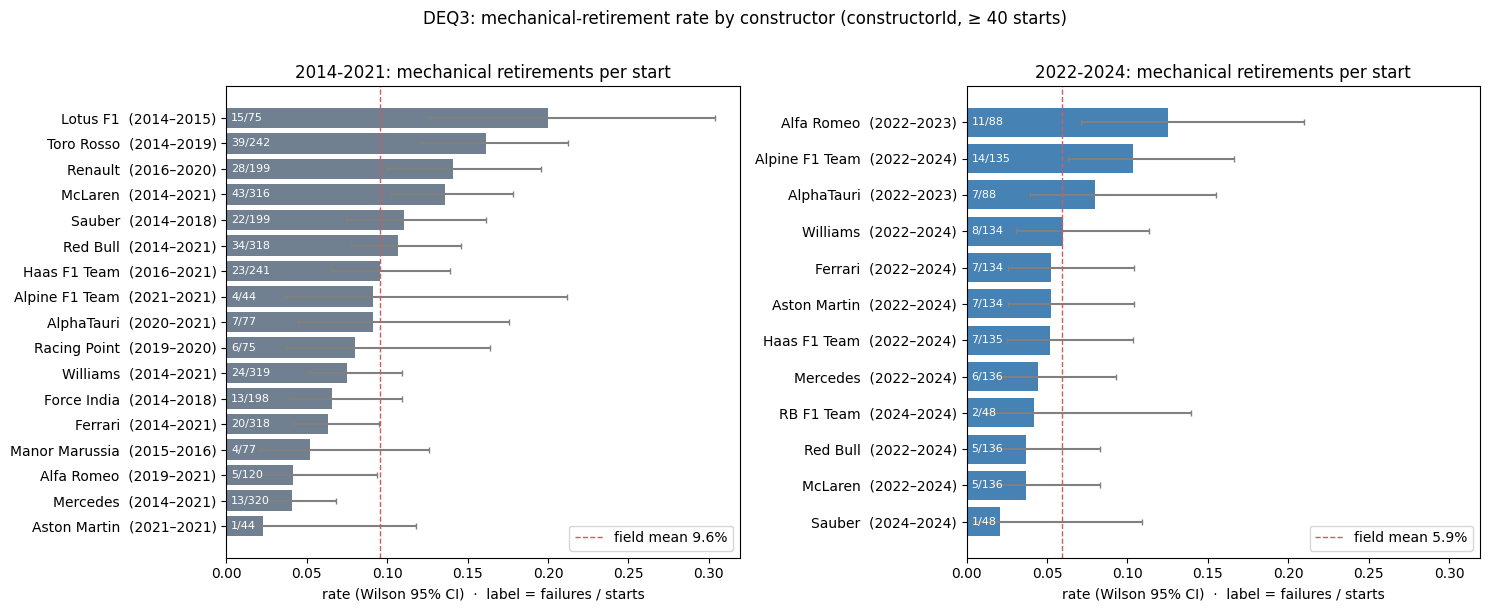

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, p, color in [(axes[0], "2014-2021", "slategray"), (axes[1], "2022-2024", "steelblue")]:
    t = deq3[(deq3["period"] == p) & deq3["ranked"]].sort_values("rate")
    ax.barh(t["constructor"] + "  (" + t["seasons"] + ")", t["rate"],
            xerr=[t["rate"] - t["ci_lo"], t["ci_hi"] - t["rate"]], color=color, capsize=2, ecolor="gray")
    for i, (k, n_) in enumerate(zip(t["mech"], t["starts"])):
        ax.text(0.003, i, f"{int(k)}/{int(n_)}", va="center", fontsize=8, color="white")
    ax.axvline(field.loc[p, "rate"], color="indianred", ls="--", lw=1, label=f"field mean {field.loc[p, 'rate']:.1%}")
    ax.set_title(f"{p}: mechanical retirements per start")
    ax.set_xlabel("rate (Wilson 95% CI)  ·  label = failures / starts")
    ax.legend(loc="lower right")
plt.suptitle("DEQ3: mechanical-retirement rate by constructor (constructorId, ≥ 40 starts)", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "deq3_mechanical_by_constructor.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3.1 Same question, grouped by today's teams
Renames split one factory across several ids (e.g. Toro Rosso → AlphaTauri → RB). For a like-for-like period comparison we group each of the 10 teams on the 2024 grid with its earlier names. This is a **reporting view only**: the cleaned tables and the modeling features still follow `constructorId` (decision 1.4). Teams that left F1 (Caterham, Marussia / Manor) have no 2022–24 counterpart and are not part of this view.

In [144]:
LINEAGE = {   # 2024 team <- names used 2014–2024 (constructors_clean.name)
    "Mercedes": ["Mercedes"], "Red Bull": ["Red Bull"], "Ferrari": ["Ferrari"], "McLaren": ["McLaren"],
    "Williams": ["Williams"], "Haas": ["Haas F1 Team"],
    "Alpine (Enstone)": ["Lotus F1", "Renault", "Alpine F1 Team"],
    "Aston Martin (Silverstone)": ["Force India", "Racing Point", "Aston Martin"],
    "RB (Faenza)": ["Toro Rosso", "AlphaTauri", "RB F1 Team"],
    "Sauber (Hinwil)": ["Sauber", "Alfa Romeo"],
}
name_to_team = {n: t for t, ns in LINEAGE.items() for n in ns}
unmapped = sorted(set(m3["constructor"]) - set(name_to_team))
print("names not in a current lineage (left F1):", unmapped)

lin = (m3.assign(team=m3["constructor"].map(name_to_team)).dropna(subset=["team"])
       .groupby(["team", "period"]).agg(starts=("mech", "size"), mech=("mech", "sum")).reset_index())
lin["rate"] = lin["mech"] / lin["starts"]
lin = add_wilson(lin, k="mech", n="starts")
lw = lin.pivot(index="team", columns="period", values=["rate", "ci_lo", "ci_hi", "starts", "mech"])
lw.columns = [f"{a}_{b}" for a, b in lw.columns]
lw["change_pp"] = (lw["rate_2022-2024"] - lw["rate_2014-2021"]) * 100
rho3, p3 = spearmanr(lw["rate_2014-2021"], lw["rate_2022-2024"])
print(f"Spearman rho between the two periods' team rankings: {rho3:.2f} (p = {p3:.2f})")
display(lw.sort_values("rate_2022-2024", ascending=False)
        [["starts_2014-2021", "mech_2014-2021", "rate_2014-2021", "starts_2022-2024", "mech_2022-2024", "rate_2022-2024", "change_pp"]]
        .round(3))

names not in a current lineage (left F1): ['Caterham', 'Manor Marussia', 'Marussia']
Spearman rho between the two periods' team rankings: 0.24 (p = 0.51)


,starts_2014-2021,mech_2014-2021,rate_2014-2021,starts_2022-2024,mech_2022-2024,rate_2022-2024,change_pp
team,,,,,,,
Alpine (Enstone),318.0,47.0,0.148,135.0,14.0,0.104,-4.410
Sauber (Hinwil),319.0,27.0,0.085,136.0,12.0,0.088,0.360
RB (Faenza),319.0,46.0,0.144,136.0,9.0,0.066,-7.802
Williams,319.0,24.0,0.075,134.0,8.0,0.060,-1.553
Aston Martin (Silverstone),317.0,20.0,0.063,134.0,7.0,0.052,-1.085
Ferrari,318.0,20.0,0.063,134.0,7.0,0.052,-1.065
Haas,241.0,23.0,0.095,135.0,7.0,0.052,-4.358
Mercedes,320.0,13.0,0.041,136.0,6.0,0.044,0.349
McLaren,316.0,43.0,0.136,136.0,5.0,0.037,-9.931


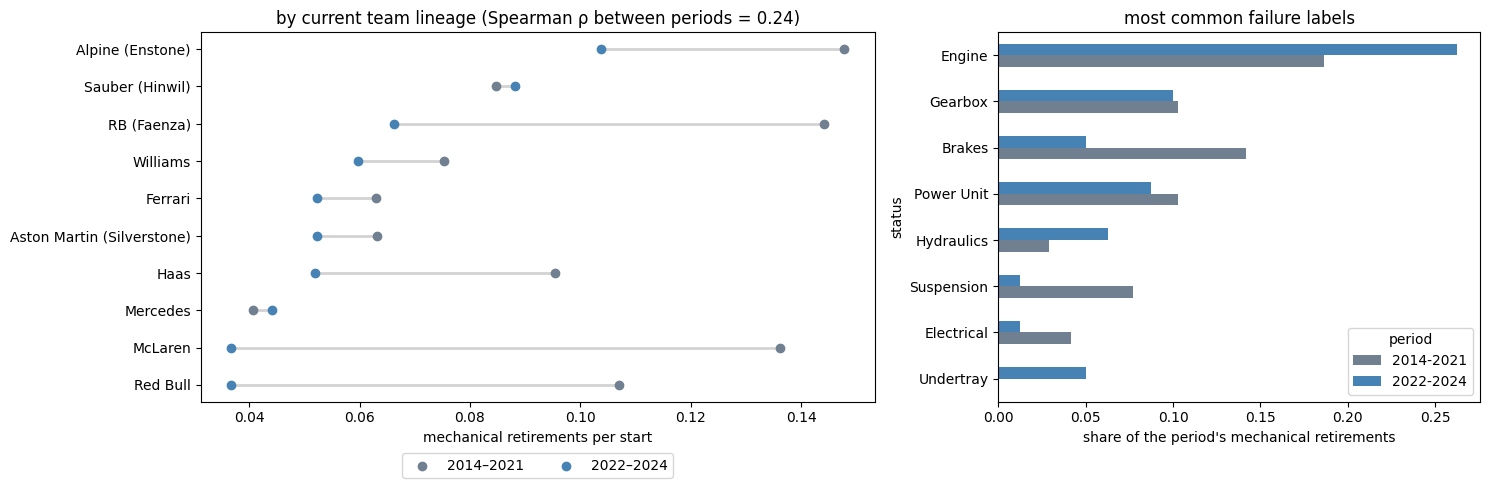

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
b = lw.sort_values("rate_2022-2024")
y = np.arange(len(b))
for i, (_, row) in enumerate(b.iterrows()):
    ax.plot([row["rate_2014-2021"], row["rate_2022-2024"]], [i, i], color="lightgray", lw=2, zorder=1)
ax.scatter(b["rate_2014-2021"], y, color="slategray", label="2014–2021", zorder=2)
ax.scatter(b["rate_2022-2024"], y, color="steelblue", label="2022–2024", zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(b.index)
ax.set_xlabel("mechanical retirements per start")
ax.set_title(f"by current team lineage (Spearman ρ between periods = {rho3:.2f})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

ax = axes[1]
top_causes = (m3[m3["mech"] == 1].groupby("period")["status"].value_counts(normalize=True)
              .rename("share").reset_index())
keep = top_causes.groupby("status")["share"].max().sort_values(ascending=False).head(8).index
tc = top_causes[top_causes["status"].isin(keep)].pivot(index="status", columns="period", values="share").fillna(0)
tc = tc.loc[tc.sum(axis=1).sort_values().index]
tc.plot(kind="barh", ax=ax, color=["slategray", "steelblue"])
ax.set_xlabel("share of the period's mechanical retirements")
ax.set_title("most common failure labels")
plt.tight_layout()
plt.savefig(FIG_DIR / "deq3_lineage_and_causes.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3.2 Sensitivity: retirements recorded without a cause
Some retirements carry the generic label `Retired`, with no component named. The taxonomy files them under `stewards_or_other`, so the rates above are a **lower bound**. Upper bound: count every `Retired` as mechanical and check whether the ranking moves.

In [146]:
m3["mech_upper"] = m3["mech"] | m3["unknown_retired"]
sens = (m3.groupby(["period", "constructor"]).agg(starts=("mech", "size"), lower=("mech", "mean"), upper=("mech_upper", "mean"),
                                                 retired_no_cause=("unknown_retired", "sum")).reset_index())
sens = sens[sens["starts"] >= MECH_MIN_STARTS]
for p in ["2014-2021", "2022-2024"]:
    s_ = sens[sens["period"] == p]
    rho_s, _ = spearmanr(s_["lower"], s_["upper"])
    top_l = s_.nlargest(3, "lower")["constructor"].tolist()
    top_u = s_.nlargest(3, "upper")["constructor"].tolist()
    print(f"{p}: 'Retired' rows = {int(s_['retired_no_cause'].sum())} | Spearman(lower, upper) = {rho_s:.2f} | "
          f"top-3 lower = {top_l} | top-3 upper = {top_u}")
print("\n'Retired' (no cause) by season:", m3.groupby("year")["unknown_retired"].sum().to_dict())

2014-2021: 'Retired' rows = 34 | Spearman(lower, upper) = 0.97 | top-3 lower = ['Lotus F1', 'Toro Rosso', 'Renault'] | top-3 upper = ['Lotus F1', 'Toro Rosso', 'McLaren']
2022-2024: 'Retired' rows = 12 | Spearman(lower, upper) = 0.66 | top-3 lower = ['Alfa Romeo', 'Alpine F1 Team', 'AlphaTauri'] | top-3 upper = ['Alfa Romeo', 'RB F1 Team', 'Alpine F1 Team']

'Retired' (no cause) by season: {2014: 8, 2015: 12, 2016: 9, 2017: 0, 2018: 2, 2019: 2, 2020: 1, 2021: 3, 2022: 0, 2023: 3, 2024: 9}


### DEQ3 — Answer
**Highest mechanical-retirement rates (≥ 40 starts):**

| Period | Highest | Lowest | Field mean |
|---|---|---|---|
| **2014–2021** | **Lotus F1 20.0%** (15/75, 2014–15), **Toro Rosso 16.1%** (39/242), **Renault 14.1%** (28/199), McLaren 13.6% (43/316) | Aston Martin 2.3% (1/44, 2021 only), **Mercedes 4.1%** (13/320), Alfa Romeo 4.2% (5/120), Ferrari 6.3% | **9.6%** (311 / 3,246 starts) |
| **2022–2024** | **Alfa Romeo 12.5%** (11/88, 2022–23), **Alpine 10.4%** (14/135), **AlphaTauri 8.0%** (7/88) | Sauber 2.1% (1/48, 2024 only), **McLaren and Red Bull 3.7%** (5/136 each), RB 4.2%, Mercedes 4.4% | **5.9%** (80 / 1,352 starts) |

Caterham (21.2%, 7/33) and Marussia (2014) are below the 40-start minimum and are not ranked.

**What changed between the periods**
- **Reliability improved across the field:** the mechanical-retirement rate fell from 9.6% to 5.9% per start (two-proportion z = 4.06, p < 0.001).
- **Grouped by today's teams** (3.3.1), the ranking only weakly carries over (ρ = 0.24). **Enstone (Lotus F1 → Renault → Alpine) is the least reliable lineage in both periods** (14.8% → 10.4%). The biggest improvements are **McLaren (13.6% → 3.7%, −9.9 pp)**, **Faenza (Toro Rosso / AlphaTauri / RB, −7.8 pp)** and **Red Bull (−7.0 pp)**. Mercedes stays among the most reliable in both periods (4.1% → 4.4%), and Sauber / Alfa Romeo is flat (8.5% → 8.8%).
- **Failure mix:** `Engine` is the most common label in both periods and its share grows (18.6% → 26.2% of mechanical retirements). `Brakes` shrinks (14.1% → 5.0%), and `Hydraulics` and `Undertray` (the ground-effect floor) appear more often after 2022.

**Grain, missingness, cutoff**
- Grain: one row per `(raceId, driverId)` race start, so each car counts once per Grand Prix. Sprint retirements are not included (`results` holds the Grand Prix only). Drivers who did not start are excluded from the denominator.
- Constructor identity follows `constructorId` (1.4), so renamed teams are separate rows. The lineage view is a reporting aid only.
- Missingness / sensitivity (3.3.2): **49 retirements in 2014–2024 carry the generic label `Retired`** with no cause (37 in 2014–21, 12 in 2022–24, 9 of them in 2024). They are excluded, so the rates above are **lower bounds**. Counting them all as mechanical leaves the 2014–21 ranking intact (ρ = 0.97), but reshuffles the lower 2022–24 places (ρ = 0.66; RB F1 Team enters the top 3). The 2022–24 top two (Alfa Romeo, Alpine) hold under both rules.
- Cutoff: status is post-race. It is the **outcome** counted here and is never a model feature.

**Limitations:** the 2022–24 counts are small (5–14 failures per team), so most intervals overlap. Only Alfa Romeo and Alpine sit clearly above the most reliable teams. The mechanical / non-mechanical split depends on our hand taxonomy (1.2; e.g. `Puncture` → incident, `Broken wing` → mechanical) and on how Ergast labelled each retirement.

**For feature engineering:** reliability differs by team and changes over time, which suggests a **lagged reliability feature** (e.g. the constructor's mechanical-DNF rate over its previous N races, using only races before the one being predicted). Season-level averages would leak the current race, so the window must end before it.

# 4. Feature engineering and final model table
Each subsection builds one **feature group**, shows the evidence for it (train seasons only, so validation/test never influence feature choices), and ends with findings. The groups match the feature-group ablation in section 7.1. Missing values are handled in 4.9, and the final table and the train/validation/test split are built in 4.10.

**Rules every feature follows**
1. **Pre-race only:** known after qualifying, before the race starts.
2. **History = previous races only:** form uses `shift(1)` before averaging, and standings use the `pre_*` columns (previous round). A race's own result never enters its own features.
3. **Missing values get a documented meaning.** During feature building a gap stays NA (4.1–4.8). In 4.9 every gap is filled with real pre-race information where it exists (e.g. last season's final standing at a season opener); only the qualifying gap, which has no pre-race substitute, is imputed inside the model pipeline (grid-band median, fitted on train).

## 4.0 Base table
**Rows:** one row per driver who **started** a race, unique on `(raceId, driverId)`. Built from `results_clean` (shared drives already deduplicated in 1.7), with two filters:
1. **Indianapolis 500 removed** (1950–60): a separate series in practice, with almost no F1 regulars (flagged in 1.6).
2. **Non-starters removed** (`did_not_start`: failed to qualify / withdrew). They can never podium, and it is known before lights out that they won't start (1.7).

**Columns:** `results_clean` still carries every post-race column. They are handled in three ways:
- **Dropped now:** never needed for a feature (ids, car number, times, laps, points, fastest lap, raw status text) or already used as filters (`did_not_start`, `is_indy500`).
- **Kept for history features only:** `positionOrder` (→ form, circuit history) and `status_group` (→ reliability). They are post-race for *this* race, so they are only used through `shift(1)`, and they are dropped from the final table with an assert.
- **Kept:** keys, the target `podium`, and pre-race fields (`grid`, `is_pit_start`, calendar context).

In [147]:
TRAIN_END = 2019   # last training season; evidence plots use train seasons only (split justified in 4.10)
VAL_END = 2021     # last validation season; test = later seasons

DROP_NOW = ["resultId", "number", "position", "positionText", "points", "laps", "fastestLap", "rank",
            "fastestLapSpeed", "statusId", "race_time_s", "fastestLapTime_s", "status"]
HISTORY_ONLY = ["positionOrder", "status_group"]   # post-race: only usable via shift(1), never as features

base = results_clean.merge(
    races_clean[["raceId", "year", "round", "circuitId", "date", "era", "is_indy500", "prev_raceId"]],
    on="raceId", how="left", validate="many_to_one",
)
base = base[(base["is_indy500"] == 0) & (~base["did_not_start"])]
base = (base.drop(columns=DROP_NOW + ["did_not_start", "is_indy500"])
            .sort_values(["date", "raceId", "grid"])   # date order matters for the form features
            .reset_index(drop=True))

assert base.set_index(["raceId", "driverId"]).index.is_unique
assert len(base) == 24586

print(base.shape)
print("missing values:", base.isna().sum()[lambda s: s > 0].to_dict())
base.head()

(24586, 14)
missing values: {'prev_raceId': 1595}


,raceId,driverId,constructorId,grid,positionOrder,status_group,podium,is_pit_start,year,round,circuitId,date,era,prev_raceId
0,833,642,51,1,1,classified,1,False,1950,1,9,1950-05-13,1950-57 front-engine,<NA>
1,833,786,51,2,2,classified,1,False,1950,1,9,1950-05-13,1950-57 front-engine,<NA>
2,833,579,51,3,12,mechanical,0,False,1950,1,9,1950-05-13,1950-57 front-engine,<NA>
3,833,686,51,4,3,classified,1,False,1950,1,9,1950-05-13,1950-57 front-engine,<NA>
4,833,669,105,5,14,stewards_or_other,0,False,1950,1,9,1950-05-13,1950-57 front-engine,<NA>


## 4.1 Grid
The strongest single signal (1.7: pole converts 64%, P10 6%).
- `grid_rank`: starting slot among the **starters** of that race, with pit-lane starters (`grid = 0`, 1.7) at the back. Raw `grid` has two problems: a pit starter's 0 looks *better* than pole, and in 153 rows `grid` is larger than the number of starters, because slots of cars that did not start are skipped.
- `grid_pct` = `grid_rank / field_size`. Fields range from 6 to 34 starters, so P10 means something different in a 34-car field than in a 20-car one.
- `field_size`: more cars → lower podium chance for everyone.
- `front_row` (P1–P2, the DEQ1 definition) and `is_pit_start`.

All are known once the grid is set, before the race starts.

In [148]:
base["field_size"] = base.groupby("raceId")["driverId"].transform("size")
# pit starters (grid 0) go to the back; ties among several pit starters share the same rank
base["grid_rank"] = base["grid"].replace(0, 999).groupby(base["raceId"]).rank(method="min").astype(int)
base["grid_pct"] = base["grid_rank"] / base["field_size"]
base["front_row"] = (base["grid_rank"] <= 2).astype(int)
base["is_pit_start"] = base["is_pit_start"].astype(int)

GRID_FEATURES = ["grid_rank", "grid_pct", "field_size", "front_row", "is_pit_start"]

assert (base["grid_rank"] <= base["field_size"]).all()
assert (base.groupby("raceId")["grid_rank"].min() == 1).all()
print("rows with raw grid > field size:", int((base["grid"] > base["field_size"]).sum()), "→ after ranking: 0")
base[["grid", *GRID_FEATURES]].describe().round(2)

rows with raw grid > field size: 153 → after ranking: 0


,grid,grid_rank,grid_pct,field_size,front_row,is_pit_start
count,24586.00,24586.00,24586.00,24586.00,24586.00,24586.00
mean,11.73,11.74,0.52,22.50,0.09,0.00
std,6.76,6.72,0.29,3.02,0.29,0.06
min,0.00,1.00,0.03,6.00,0.00,0.00
25%,6.00,6.00,0.27,20.00,0.00,0.00
50%,12.00,12.00,0.52,22.00,0.00,0.00
75%,17.00,17.00,0.77,25.00,0.00,0.00
max,34.00,34.00,1.00,34.00,1.00,1.00


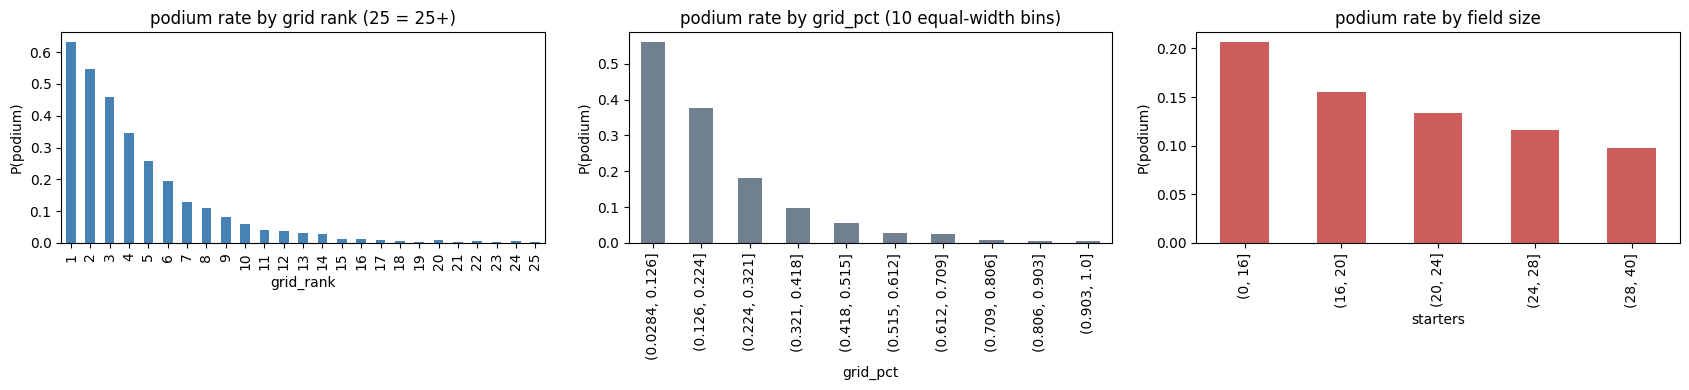

Spearman ρ with podium (train):


grid_rank      -0.455
grid_pct       -0.449
field_size     -0.055
front_row       0.417
is_pit_start   -0.015
Name: podium, dtype: float64

binary flags (train):


rows  podium_rate
             front_row                    
front_row    0          20442        0.090
             1           2017        0.589
is_pit_start 0          22425        0.135
             1             34        0.000

redundancy among grid features (Spearman, train):


,grid_rank,grid_pct,front_row
grid_rank,1.00,0.97,-0.50
grid_pct,0.97,1.00,-0.49
front_row,-0.50,-0.49,1.00


In [149]:
train = base[base["year"] <= TRAIN_END]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
train.groupby(train["grid_rank"].clip(upper=25))["podium"].mean().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("podium rate by grid rank (25 = 25+)")
axes[0].set_xlabel("grid_rank")

train.groupby(pd.cut(train["grid_pct"], 10), observed=True)["podium"].mean().plot(kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("podium rate by grid_pct (10 equal-width bins)")
axes[1].set_xlabel("grid_pct")

train.groupby(pd.cut(train["field_size"], [0, 16, 20, 24, 28, 40]), observed=True)["podium"].mean().plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("podium rate by field size")
axes[2].set_xlabel("starters")
for ax in axes:
    ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

print("Spearman ρ with podium (train):")
display(train[GRID_FEATURES + ["podium"]].corr(method="spearman")["podium"].drop("podium").round(3))

print("binary flags (train):")
display(pd.concat({f: train.groupby(f)["podium"].agg(rows="size", podium_rate="mean") for f in ["front_row", "is_pit_start"]}).round(3))

print("redundancy among grid features (Spearman, train):")
display(train[["grid_rank", "grid_pct", "front_row"]].corr(method="spearman").round(2))

**Grid — findings (train)**
- Starting position is a very strong signal: `grid_rank` ρ = −0.46, `grid_pct` −0.45. The front tenth of the grid podiums 56% of the time; every bin in the back half is under 3%.
- The front row podiums **58.9%** of the time vs 9.0% for the rest (ρ = +0.42).
- Field size matters on its own: 20.6% podium rate in fields of ≤ 16 cars vs 9.7% in fields of 29+ (ρ = −0.06). With exactly 3 podium places, more cars means a lower base rate for everyone.
- Pit-lane starters never podiumed in train. The flag is rare, so the ablation will show whether it adds anything beyond `grid_rank`.
- **Redundancy:** `grid_rank` and `grid_pct` are almost the same feature, and `front_row` is computed from `grid_rank`. Tree models handle this; for logistic regression and the XAI plots it means importance gets split between them, which we keep in mind when reading importances.

## 4.2 Qualifying
Grid says **where** a driver starts; qualifying adds **how fast** the car was relative to the field, and whether the grid was changed by a penalty.
- `quali_gap_pct`: % slower than pole (`q_gap_to_pole_pct` from 1.8). A percentage, not seconds, so tracks of different length are comparable. Capped at 7% (see findings).
- `grid_minus_quali`: `grid_rank` minus the qualifying order among the same starters. Positive = lost places (penalty), negative = gained places (someone ahead was penalised or started from the pit lane).
- `has_quali`: 0 where there is no qualifying record. The two other features stay NA there; imputation is done inside the model pipeline, learned on training rows only.

Qualifying *position* is **not** a feature: it is almost the same number as `grid_rank`. It is only used to compute `grid_minus_quali`.

All three are known after qualifying and before the race (the grid, including penalties, is published before the start).

In [150]:
quali = qualifying_clean[["raceId", "driverId", "position", "q_gap_to_pole_pct"]].rename(
    columns={"position": "quali_pos", "q_gap_to_pole_pct": "quali_gap_pct"})
base = base.merge(quali, on=["raceId", "driverId"], how="left", validate="one_to_one")

print("rows more than 7% off pole (raw):", int((base["quali_gap_pct"] > 7).sum()), "| max:", round(base["quali_gap_pct"].max(), 1))
base["quali_gap_pct"] = base["quali_gap_pct"].clip(upper=7)   # beyond 7% off pole the podium chance is ~0; tames the long tail

base["has_quali"] = base["quali_pos"].notna().astype(int)
# qualifying order among the same starters, so it is comparable with grid_rank
quali_rank = base.groupby("raceId")["quali_pos"].rank(method="min")
base["grid_minus_quali"] = base["grid_rank"] - quali_rank
base = base.drop(columns="quali_pos")

QUALI_FEATURES = ["quali_gap_pct", "grid_minus_quali", "has_quali"]

assert len(base) == 24586
period = pd.cut(base["year"], [0, TRAIN_END, VAL_END, 9999], labels=["train seasons", "val seasons", "test seasons"])
print("has qualifying, by period:", base.groupby(period, observed=True)["has_quali"].mean().round(3).to_dict())
print("has a position but no lap time:", int((base["has_quali"].eq(1) & base["quali_gap_pct"].isna()).sum()))
base[QUALI_FEATURES].describe().round(2)

rows more than 7% off pole (raw): 378 | max: 922.9
has qualifying, by period: {'train seasons': 0.369, 'val seasons': 0.999, 'test seasons': 1.0}
has a position but no lap time: 151


,quali_gap_pct,grid_minus_quali,has_quali
count,10267.00,10418.00,24586.00
mean,2.23,-0.00,0.42
std,1.78,1.52,0.49
min,0.00,-9.00,0.00
25%,0.90,0.00,0.00
50%,1.84,0.00,0.00
75%,3.06,0.00,1.00
max,7.00,23.00,1.00


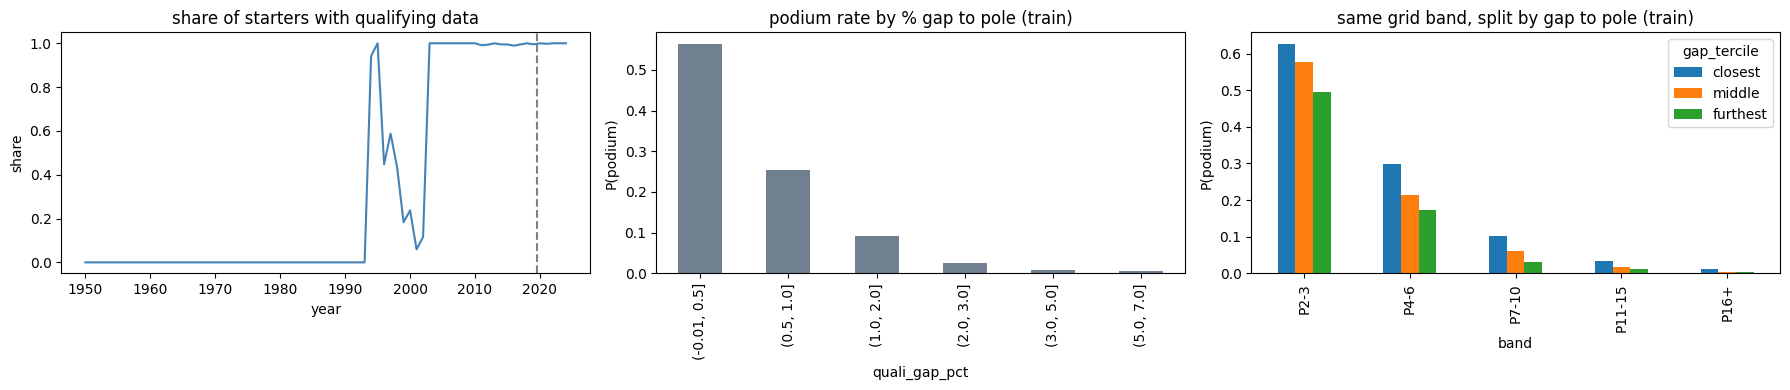

podium rate by gap to pole (train):


,rows,podium_rate
quali_gap_pct,,
"(-0.01, 0.5]",1166,0.564
"(0.5, 1.0]",994,0.255
"(1.0, 2.0]",1985,0.092
"(2.0, 3.0]",1679,0.025
"(3.0, 5.0]",1461,0.008
"(5.0, 7.0]",877,0.006


podium rate within grid bands, by gap tercile (train):


gap_tercile,closest,middle,furthest
band,,,
P2-3,0.626,0.576,0.496
P4-6,0.298,0.215,0.174
P7-10,0.101,0.060,0.031
P11-15,0.034,0.017,0.011
P16+,0.011,0.004,0.004


podium rate by grid move (train):


,rows,podium_rate
grid_minus_quali,,
gained places,1437,0.056
penalty,398,0.048
same as quali,6457,0.164


podium rate by grid band and grid move (train):


mean                                size                      
move   gained places penalty same as quali gained places penalty same as quali
band                                                                          
P1             0.800     NaN         0.767           5.0     NaN         382.0
P2-3           0.519     NaN         0.568          54.0     NaN         720.0
P4-6           0.167   0.083         0.240         156.0    12.0         993.0
P7-10          0.068   0.159         0.060         263.0    44.0        1237.0
P11-15         0.007   0.079         0.024         434.0    63.0        1433.0
P16+           0.004   0.022         0.008         525.0   279.0        1692.0

Spearman ρ with podium (train rows with qualifying):


quali_gap_pct      -0.467
grid_minus_quali    0.071
grid_rank          -0.487
Name: podium, dtype: float64

In [151]:
GRID_BANDS = [0, 1, 3, 6, 10, 15, np.inf]
GRID_BAND_LABELS = ["P1", "P2-3", "P4-6", "P7-10", "P11-15", "P16+"]

train = base[base["year"] <= TRAIN_END]
tq = train[train["has_quali"] == 1]
band = pd.cut(tq["grid_rank"], GRID_BANDS, labels=GRID_BAND_LABELS)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
base.groupby("year")["has_quali"].mean().plot(ax=axes[0], color="steelblue")
axes[0].axvline(TRAIN_END + 0.5, ls="--", color="gray")
axes[0].set_title("share of starters with qualifying data")
axes[0].set_ylabel("share")

gap_bins = pd.cut(tq["quali_gap_pct"], [-0.01, 0.5, 1, 2, 3, 5, 7])
tq.groupby(gap_bins, observed=True)["podium"].mean().plot(kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("podium rate by % gap to pole (train)")
axes[1].set_xlabel("quali_gap_pct")
axes[1].set_ylabel("P(podium)")

# does the gap add anything beyond grid? compare drivers in the same grid band (P1 left out: its gap is 0 by definition)
tercile = tq.groupby(band, observed=True)["quali_gap_pct"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 3, labels=["closest", "middle", "furthest"]))
within = (tq.assign(band=band, gap_tercile=tercile)
            .loc[lambda d: d["band"] != "P1"].dropna(subset=["gap_tercile"])
            .pivot_table(index="band", columns="gap_tercile", values="podium", aggfunc="mean", observed=True))
within.plot(kind="bar", ax=axes[2])
axes[2].set_title("same grid band, split by gap to pole (train)")
axes[2].set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

print("podium rate by gap to pole (train):")
display(tq.groupby(gap_bins, observed=True)["podium"].agg(rows="size", podium_rate="mean").round(3))
print("podium rate within grid bands, by gap tercile (train):")
display(within.round(3))

moved = np.sign(tq["grid_minus_quali"]).map({-1: "gained places", 0: "same as quali", 1: "penalty"})
print("podium rate by grid move (train):")
display(tq.groupby(moved)["podium"].agg(rows="size", podium_rate="mean").round(3))
print("podium rate by grid band and grid move (train):")
display(tq.assign(move=moved, band=band).pivot_table(
    index="band", columns="move", values="podium", aggfunc=["mean", "size"], observed=True).round(3))

print("Spearman ρ with podium (train rows with qualifying):")
tq[["quali_gap_pct", "grid_minus_quali", "grid_rank", "podium"]].corr(method="spearman")["podium"].drop("podium").round(3)

In [152]:
train_band = pd.cut(train["grid_rank"], GRID_BANDS, labels=GRID_BAND_LABELS)
print("qualifying gap and missingness by grid band (train):")
display(train.groupby(train_band, observed=True).agg(
    median_gap=("quali_gap_pct", "median"),
    share_missing=("quali_gap_pct", lambda s: s.isna().mean()),
    podium_rate=("podium", "mean"),
).round(3))

global_fill = train["quali_gap_pct"].fillna(train["quali_gap_pct"].median())
grid_fill = train["quali_gap_pct"].fillna(train.groupby(train_band, observed=True)["quali_gap_pct"].transform("median"))
print("Spearman ρ of quali_gap_pct with podium (train):")
pd.Series({
    "real values only": train["quali_gap_pct"].corr(train["podium"], method="spearman"),
    "missing → global median": global_fill.corr(train["podium"], method="spearman"),
    "missing → median of its grid band": grid_fill.corr(train["podium"], method="spearman"),
}).round(3)

qualifying gap and missingness by grid band (train):


,median_gap,share_missing,podium_rate
grid_rank,,,
P1,0.000,0.619,0.631
P2-3,0.370,0.616,0.503
P4-6,0.932,0.617,0.266
P7-10,1.582,0.618,0.095
P11-15,2.414,0.616,0.031
P16+,4.109,0.677,0.006


Spearman ρ of quali_gap_pct with podium (train):


real values only                    -0.467
missing → global median             -0.244
missing → median of its grid band   -0.443
dtype: float64

**Qualifying - findings**
- **Coverage drift:** only **36.9%** of training starters have qualifying data (none before 1994, patchy until 2002), but **99.9%** of validation and **100%** of test starters do. The model is evaluated and used entirely in the era where qualifying exists, which is why we keep it despite the gaps in train. A further 151 rows have a qualifying position but no lap time, so `quali_gap_pct` is NA there while `grid_minus_quali` exists.
- **Definition caveats:** (1) the gap compares a driver's best lap in *any* session with the fastest lap of the weekend. In knockout qualifying (2006+) a driver knocked out in Q1 is compared with a Q3 time set on a faster, rubbered-in track, so their gap is slightly inflated. This is still pre-race information, so it is not leakage, but the gap mixes pace with how far the driver progressed. (2) In 19 races (2011–2021) some starters have no qualifying row; there `grid_minus_quali` compares the grid with the qualifying order of the drivers who do.
- **Gap to pole is strong on its own** (ρ = −0.47, almost as strong as `grid_rank` at −0.49): within 0.5% of pole → 56.4% podium rate, 1–2% → 9.2%, more than 3% → under 1%.
- **The gap adds information beyond grid.** Within the same grid band, drivers closest to pole podium far more often than those furthest from it: P4–6 29.8% vs 17.4%, P7–10 10.1% vs 3.1%. Grid gives the position; the gap gives the car's pace.
- **`grid_minus_quali` only makes sense together with the grid.** On its own it looks weak (ρ = +0.07): drivers moved in either direction podium less (gained 5.6%, penalty 4.8%) than unmoved ones (16.4%), because moves mostly happen in the midfield. Within the same grid band the pattern is clear: drivers starting there **because of a penalty** podium 2–3× more often than those who qualified there (P7–10: 15.9% vs 6.0%; P11–15: 7.9% vs 2.4%; P16+: 2.2% vs 0.8%), because they are fast cars out of position. Drivers promoted into P4–6 by others' penalties do worse (16.7% vs 24.0%). Kept, signed. Tree models combine it with `grid_rank` on their own; a linear model sees only the weak overall effect.
- **Long tail capped at 7%:** 378 rows were more than 7% off pole (e.g. no representative lap in wet sessions, the 1995 Japan time kept in 1.8), and above 5% the podium rate is already 0.6%. Capping at 7 loses no information and keeps the scale manageable for logistic regression and the NN. It is a fixed domain threshold applied to every row, so no row is removed and nothing is learned from validation/test.
- **Imputation must be grid-aware.** About 62% of the gap is missing in *every* grid band, but the real gap rises steeply with grid position (P1 median 0.00%, P7–10 1.58%, P16+ 4.11%). Filling every missing value with one global median (1.96%) would tell a pole sitter and a last-placed car they had the same pace, and weakens the correlation with podium from ρ = −0.47 to −0.24. Filling with the median of the driver's **grid band** keeps it at −0.44. The pipeline therefore uses a grid-band imputer learned on training rows only. Global median vs grid band vs native NaN (trees), and training only on seasons with qualifying, are compared in the preprocessing experiments.
- **Nothing is dropped:** all 24,586 starters stay; rows without qualifying keep NaN + `has_quali = 0`.


## 4.3 Championship standings before the race
Only the **pre-race** standings from 1.10 / 1.11 are used: the `pre_*` columns hold the standings after the previous round of the same season, which is everything known before this race.
- `drv_points_share`, `con_points_share`: points **as a share of the championship leader's points** (0–1). Raw points are not comparable across eras: the points for a win went from 8 to 10 to 25, and the champion's total from 30 (1950) to 575 (2023).
- `drv_champ_pos`, `con_champ_pos`: championship position before the race.

**Missing standings, by meaning:**
- No standings entry before the race (season opener, debut, or a 0-point driver that Ergast does not list in some seasons) → **0 points**, which is the true pre-race state. Position: behind everyone ranked (`ranked + 1`).
- **Season opener** → position NA: nobody is ranked yet, so there is no meaningful value to give.
- **Constructors before 1958** → NA: there was no constructors' championship, which is not the same as 0 points.

In [153]:
pre_drv = driver_standings_clean[["raceId", "driverId", "pre_driver_points", "pre_driver_position"]]
pre_con = constructor_standings_clean[["raceId", "constructorId", "pre_constructor_points", "pre_constructor_position"]]
base = (base.merge(pre_drv, on=["raceId", "driverId"], how="left", validate="one_to_one")
            .merge(pre_con, on=["raceId", "constructorId"], how="left", validate="many_to_one"))

is_opener = base["prev_raceId"].isna()
has_con_champ = base["year"] >= 1958   # no constructors' championship before 1958

# standings after the previous round: the leader's points and how many entries were ranked
drv_prev = driver_standings_clean.groupby("raceId")["points"].agg(leader="max", ranked="size")
con_prev = constructor_standings_clean.groupby("raceId")["points"].agg(leader="max", ranked="size")
d = drv_prev.reindex(base["prev_raceId"]).set_axis(base.index)
c = con_prev.reindex(base["prev_raceId"]).set_axis(base.index)

print("rows without a pre-race standings entry:")
print("  driver     :", int(base["pre_driver_points"].isna().sum()), "| of which season openers:", int((base["pre_driver_points"].isna() & is_opener).sum()))
print("  constructor:", int(base["pre_constructor_points"].isna().sum()), "| of which before 1958:", int((~has_con_champ).sum()),
      "| openers from 1958:", int((base["pre_constructor_points"].isna() & is_opener & has_con_champ).sum()))

# no standings entry before the race = no points yet (opener, debut, or a 0-point driver Ergast does not list)
base["drv_points_share"] = (base["pre_driver_points"].fillna(0) / d["leader"]).fillna(0)
base["con_points_share"] = (base["pre_constructor_points"].fillna(0) / c["leader"]).fillna(0).where(has_con_champ)
# unranked mid-season = behind everyone ranked; at the season opener nobody is ranked yet → NA
base["drv_champ_pos"] = base["pre_driver_position"].fillna(d["ranked"] + 1).where(~is_opener).clip(upper=20)
base["con_champ_pos"] = base["pre_constructor_position"].fillna(c["ranked"] + 1).where(~is_opener & has_con_champ)
base = base.drop(columns=["pre_driver_points", "pre_driver_position", "pre_constructor_points", "pre_constructor_position"])

STANDINGS_FEATURES = ["drv_points_share", "con_points_share", "drv_champ_pos", "con_champ_pos"]

assert len(base) == 24586
assert base["drv_points_share"].between(0, 1).all() and base["con_points_share"].dropna().between(0, 1).all()
print("missing values:", base[STANDINGS_FEATURES].isna().sum().to_dict())
base[STANDINGS_FEATURES].describe().round(2)

rows without a pre-race standings entry:
  driver     : 2892 | of which season openers: 1595
  constructor: 2894 | of which before 1958: 1151 | openers from 1958: 1446
missing values: {'drv_points_share': 0, 'con_points_share': 1151, 'drv_champ_pos': 1595, 'con_champ_pos': 2597}


,drv_points_share,con_points_share,drv_champ_pos,con_champ_pos
count,24586.00,23435.00,22991.00,21989.00
mean,0.19,0.27,12.05,6.17
std,0.28,0.33,6.46,3.68
min,0.00,0.00,1.00,1.00
25%,0.00,0.00,6.00,3.00
50%,0.05,0.12,12.00,6.00
75%,0.27,0.45,19.00,9.00
max,1.00,1.00,20.00,21.00


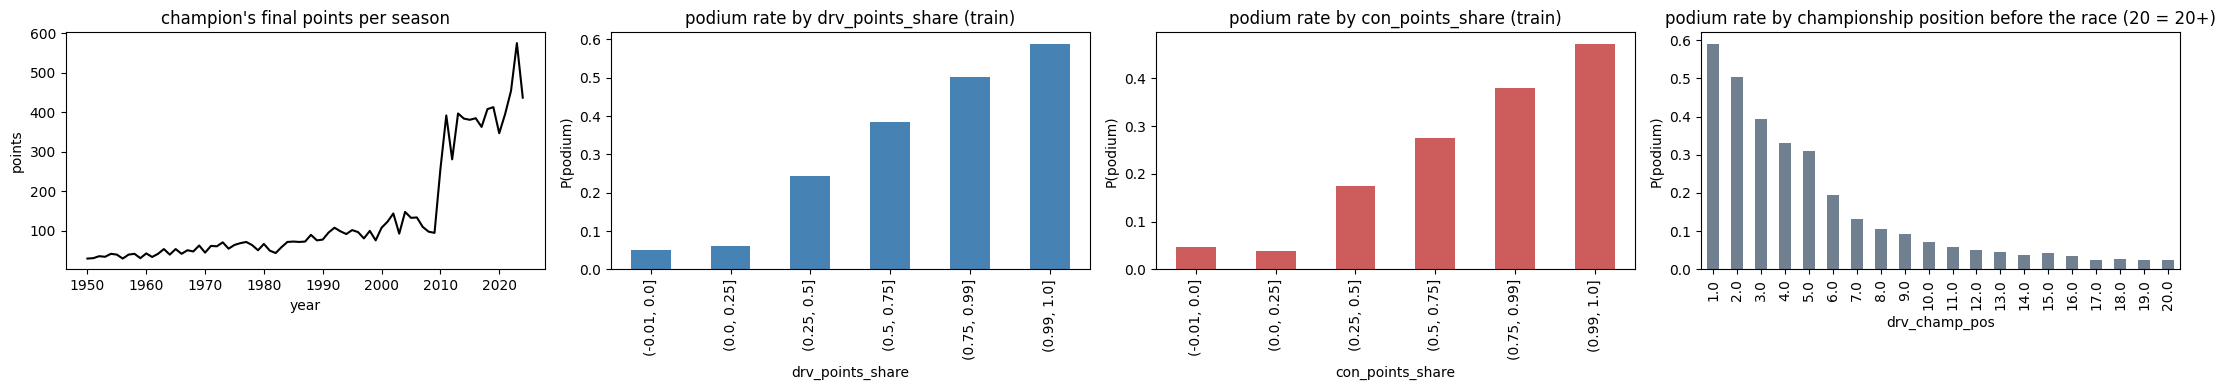

podium rate by drv_points_share (train):


,rows,podium_rate
drv_points_share,,
"(-0.01, 0.0]",9281,0.050
"(0.0, 0.25]",7495,0.061
"(0.25, 0.5]",2543,0.244
"(0.5, 0.75]",1428,0.386
"(0.75, 0.99]",753,0.503
"(0.99, 1.0]",959,0.589


podium rate by con_points_share (train):


,rows,podium_rate
con_points_share,,
"(-0.01, 0.0]",5696,0.046
"(0.0, 0.25]",8164,0.038
"(0.25, 0.5]",2621,0.175
"(0.5, 0.75]",1879,0.275
"(0.75, 0.99]",984,0.379
"(0.99, 1.0]",1964,0.473


Spearman ρ with podium (train):


drv_points_share    0.362
con_points_share    0.359
drv_champ_pos      -0.402
con_champ_pos      -0.391
Name: podium, dtype: float64

redundancy among standings features (Spearman, train):


,drv_points_share,con_points_share,drv_champ_pos,con_champ_pos
drv_points_share,1.00,0.81,-0.92,-0.73
con_points_share,0.81,1.00,-0.73,-0.92
drv_champ_pos,-0.92,-0.73,1.00,0.75
con_champ_pos,-0.73,-0.92,0.75,1.00


redundancy with the grid (Spearman, train):


drv_points_share   -0.59
con_points_share   -0.57
drv_champ_pos       0.66
con_champ_pos       0.64
Name: grid_rank, dtype: float64

In [154]:
train = base[base["year"] <= TRAIN_END]
share_bins = [-0.01, 0, 0.25, 0.5, 0.75, 0.99, 1]
season_leader = (driver_standings_clean.merge(races_clean[["raceId", "year"]], on="raceId")
                 .groupby("year")["points"].max())

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
season_leader.plot(ax=axes[0], color="black")
axes[0].set_title("champion's final points per season")
axes[0].set_ylabel("points")

for ax, col, color in [(axes[1], "drv_points_share", "steelblue"), (axes[2], "con_points_share", "indianred")]:
    train.groupby(pd.cut(train[col], share_bins), observed=True)["podium"].mean().plot(kind="bar", ax=ax, color=color)
    ax.set_title(f"podium rate by {col} (train)")
    ax.set_ylabel("P(podium)")

train.groupby("drv_champ_pos")["podium"].mean().plot(kind="bar", ax=axes[3], color="slategray")
axes[3].set_title("podium rate by championship position before the race (20 = 20+)")
axes[3].set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

for col in ["drv_points_share", "con_points_share"]:
    print(f"podium rate by {col} (train):")
    display(train.groupby(pd.cut(train[col], share_bins), observed=True)["podium"].agg(rows="size", podium_rate="mean").round(3))

print("Spearman ρ with podium (train):")
display(train[STANDINGS_FEATURES + ["podium"]].corr(method="spearman")["podium"].drop("podium").round(3))
print("redundancy among standings features (Spearman, train):")
display(train[STANDINGS_FEATURES].corr(method="spearman").round(2))
print("redundancy with the grid (Spearman, train):")
train[STANDINGS_FEATURES + ["grid_rank"]].corr(method="spearman")["grid_rank"].drop("grid_rank").round(2)

**Standings — findings (train)**
- **Raw points are not comparable across eras:** the champion's final total grew from 30 (1950) to 95 (2009), then jumped to 256 (2010, new points system) and 575 (2023). A share of the leader's points puts every season on the same 0–1 scale.
- **Points share is a clear, monotonic signal.** Driver: leading the championship → 58.9% podium rate, 50–75% of the leader's points → 38.6%, no points yet → 5.0% (ρ = +0.36). Constructor: leader 47.3%, no points 4.6% (ρ = +0.36).
- **Championship position is slightly stronger** (driver ρ = −0.40, constructor −0.39): 1st before the race → 59.1%, 3rd → 39.3%, 10th → 7.1%.
- **Unranked and the tail:** 2,892 driver rows have no standings entry before the race (1,595 are season openers). Mid-season, an unranked driver is placed behind everyone ranked. In the 1950s the driver standings list up to ~100 names (Indy 500 drivers counted in the championship), so this created positions up to 104. Beyond 20th the podium rate is flat (about 2–3%, and slightly *higher* for 30+ because of small 1950s fields), so `drv_champ_pos` is capped at 20. Constructor positions stay as they are (max 21).
- **Missing values are structural:** openers have no position (1,595 driver, 2,597 constructor rows including pre-1958), and constructor values are NA for the 1,151 rows before 1958. These are imputed in the pipeline (train only), not here.
- **Redundancy:** points share and position of the same entity correlate at −0.92; driver and constructor share at 0.81. Standings also overlap with the grid (|ρ| 0.57–0.66): good cars qualify well *and* lead the championship. The ablation will show what standings add beyond the grid.
- **Pre-race only:** every value comes from the standings after the previous round. Sprint points of the same weekend (2021+) are not included, so the features never use anything from the race weekend's results.

## 4.4 Recent form (previous races only)
The brief requires a **leakage-safe form feature built from past races only**. The car dominates F1 results (primer), so form is measured for both the driver and the team.
- `drv_podium_ewm`: the driver's recent podium rate.
- `drv_finish_frac_ewm`: the driver's recent finishing position as a share of the field (lower = better), so a P10 in a 30-car field and in a 20-car field are comparable.
- `con_podium_ewm`: how often the team put at least one car on the podium recently. Built **per team-race**, not per car, so a two-car team is not counted twice.
- `con_finish_frac_ewm`: the team's best-placed car, as a share of the field.

**How past races are averaged.** Rows are in race-date order. For each driver (or team), `shift(1)` first drops the current race, then an exponentially weighted average (EWM) combines all earlier races, with recent ones counting more: a race 5 starts ago counts half as much as the last one (half-life 5). The weighting crosses season boundaries, because form does not reset in winter. The choice of EWM and its half-life is tested below against fixed windows.

The first start of a driver (or first race of a team) has no history → NA.

In [155]:
FORM_HALFLIFE = 5   # races; chosen in the comparison below


def past_ewm(values, groups, halflife=FORM_HALFLIFE):
    """Weighted average of each group's PREVIOUS values: shift(1) drops the current race. Rows must be in date order."""
    return values.groupby(groups).transform(lambda s: s.shift(1).ewm(halflife=halflife).mean())


def build_form(df):
    """Driver and team form from past races only. df must be sorted by race date."""
    out = pd.DataFrame(index=df.index)
    # finishing position among the starters (positionOrder also counts non-starters in a few races)
    finish_frac = df.groupby("raceId")["positionOrder"].rank(method="first") / df["field_size"]   # 1/field = won, 1.0 = last
    out["drv_podium_ewm"] = past_ewm(df["podium"], df["driverId"])
    out["drv_finish_frac_ewm"] = past_ewm(finish_frac, df["driverId"])

    # team form is built per team-race (not per car), so a two-car team is not counted twice
    team = (df.assign(finish_frac=finish_frac)
              .groupby(["raceId", "constructorId"], sort=False)
              .agg(date=("date", "first"), team_podium=("podium", "max"), team_best_finish=("finish_frac", "min"))
              .reset_index()
              .sort_values(["date", "raceId"], kind="stable"))
    team["con_podium_ewm"] = past_ewm(team["team_podium"], team["constructorId"])
    team["con_finish_frac_ewm"] = past_ewm(team["team_best_finish"], team["constructorId"])
    team_form = df[["raceId", "constructorId"]].merge(
        team[["raceId", "constructorId", "con_podium_ewm", "con_finish_frac_ewm"]],
        on=["raceId", "constructorId"], how="left", validate="many_to_one")
    out["con_podium_ewm"] = team_form["con_podium_ewm"].to_numpy()
    out["con_finish_frac_ewm"] = team_form["con_finish_frac_ewm"].to_numpy()
    return out


FORM_FEATURES = ["drv_podium_ewm", "drv_finish_frac_ewm", "con_podium_ewm", "con_finish_frac_ewm"]
assert base["date"].is_monotonic_increasing
base[FORM_FEATURES] = build_form(base)

assert len(base) == 24586
print("missing values (first start of a driver / first race of a team):", base[FORM_FEATURES].isna().sum().to_dict())
base[FORM_FEATURES].describe().round(3)

missing values (first start of a driver / first race of a team): {'drv_podium_ewm': 683, 'drv_finish_frac_ewm': 683, 'con_podium_ewm': 262, 'con_finish_frac_ewm': 262}


,drv_podium_ewm,drv_finish_frac_ewm,con_podium_ewm,con_finish_frac_ewm
count,23903.000,23903.000,24324.000,24324.000
mean,0.138,0.520,0.247,0.382
std,0.207,0.162,0.298,0.178
min,0.000,0.038,0.000,0.043
25%,0.000,0.410,0.000,0.234
50%,0.016,0.531,0.098,0.382
75%,0.212,0.633,0.463,0.509
max,1.000,1.000,1.000,1.000


In [156]:
# Leakage check 1: a driver's first start has no form (there is nothing before it)
first_start = base.groupby("driverId").cumcount() == 0
assert base.loc[first_start, "drv_podium_ewm"].isna().all()

# Leakage check 2: for 10 races spread over the years, keep only the data up to that race, scramble that race's
# results (podiums flipped, finishing order reversed) and rebuild. Its form must equal the value in the full table:
# then the form uses neither the race's own result nor anything after it.
check_races = base.drop_duplicates("raceId")["raceId"].iloc[np.linspace(50, base["raceId"].nunique() - 1, 10).astype(int)]
for race in check_races:
    upto = base[base["date"] <= base.loc[base["raceId"] == race, "date"].iloc[0]].copy()
    this = upto["raceId"] == race
    upto.loc[this, "podium"] = 1 - upto.loc[this, "podium"]
    upto.loc[this, "positionOrder"] = upto.loc[this, "positionOrder"].max() + 1 - upto.loc[this, "positionOrder"]
    rebuilt = build_form(upto).loc[this]
    assert np.allclose(rebuilt.to_numpy(), base.loc[rebuilt.index, FORM_FEATURES].to_numpy(), equal_nan=True), race
print(f"{len(check_races)} races rebuilt without their own result and without later races: form identical ✓")

# Leakage check 3: one driver by hand. A podium only shows up in the NEXT race's form value
hamilton = drivers_clean.loc[drivers_clean["driverRef"] == "hamilton", "driverId"].item()
h = base.loc[base["driverId"] == hamilton, ["date", "podium", "drv_podium_ewm"]].head(17).reset_index(drop=True)
w = 0.5 ** (1 / FORM_HALFLIFE)   # weight decay per race
h["by_hand"] = [np.nan] + [
    sum(w ** (i - 1 - j) * h.loc[j, "podium"] for j in range(i)) / sum(w ** (i - 1 - j) for j in range(i))
    for i in range(1, len(h))]
assert np.allclose(h["drv_podium_ewm"], h["by_hand"], equal_nan=True)
# shown from his 8th start (2007): podiums in races 1–9, then mixed results
h.iloc[7:].round(3)


10 races rebuilt without their own result and without later races: form identical ✓


,date,podium,drv_podium_ewm,by_hand
7,2007-07-01,1,1.000,1.000
8,2007-07-08,1,1.000,1.000
9,2007-07-22,0,1.000,1.000
10,2007-08-05,1,0.827,0.827
11,2007-08-26,0,0.856,0.856
12,2007-09-09,1,0.719,0.719
13,2007-09-16,0,0.763,0.763
14,2007-09-30,1,0.647,0.647
15,2007-10-07,0,0.700,0.700
16,2007-10-21,0,0.598,0.598


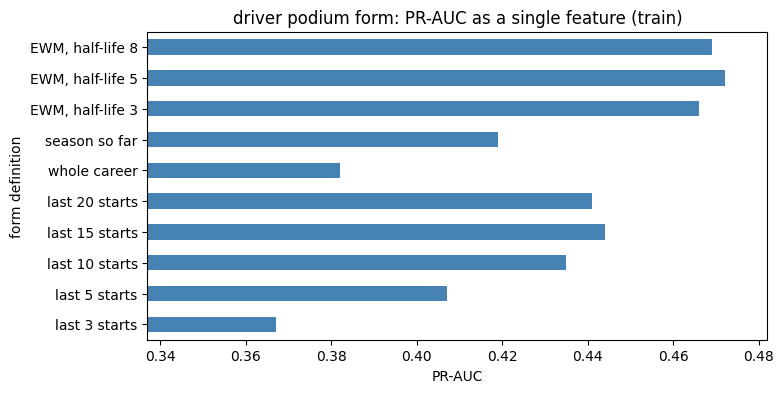

,coverage,ROC-AUC,PR-AUC
form definition,,,
last 3 starts,0.970,0.777,0.367
last 5 starts,0.970,0.812,0.407
last 10 starts,0.970,0.834,0.435
last 15 starts,0.970,0.840,0.444
last 20 starts,0.970,0.839,0.441
whole career,0.970,0.808,0.382
season so far,0.887,0.813,0.419
"EWM, half-life 3",0.970,0.847,0.466
"EWM, half-life 5",0.970,0.849,0.472


In [157]:
from sklearn.metrics import average_precision_score, roc_auc_score

# which form definition? compare candidates as single features on the training seasons
podium_by_driver = base.groupby("driverId")["podium"]
candidates = {f"last {n} starts": podium_by_driver.transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
              for n in [3, 5, 10, 15, 20]}
candidates["whole career"] = podium_by_driver.transform(lambda s: s.shift(1).expanding().mean())
candidates["season so far"] = base.groupby(["driverId", "year"])["podium"].transform(lambda s: s.shift(1).expanding().mean())
for hl in [3, 5, 8]:
    candidates[f"EWM, half-life {hl}"] = past_ewm(base["podium"], base["driverId"], halflife=hl)

is_train = base["year"] <= TRAIN_END
rows = []
for name, values in candidates.items():
    ok = is_train & values.notna()
    rows.append({"form definition": name, "coverage": ok.sum() / is_train.sum(),
                 "ROC-AUC": roc_auc_score(base.loc[ok, "podium"], values[ok]),
                 "PR-AUC": average_precision_score(base.loc[ok, "podium"], values[ok])})
form_choice = pd.DataFrame(rows).set_index("form definition").round(3)

form_choice["PR-AUC"].plot(kind="barh", figsize=(8, 4), color="steelblue",
                           xlim=(form_choice["PR-AUC"].min() - 0.03, form_choice["PR-AUC"].max() + 0.01))
plt.title("driver podium form: PR-AUC as a single feature (train)")
plt.xlabel("PR-AUC")
plt.show()
form_choice

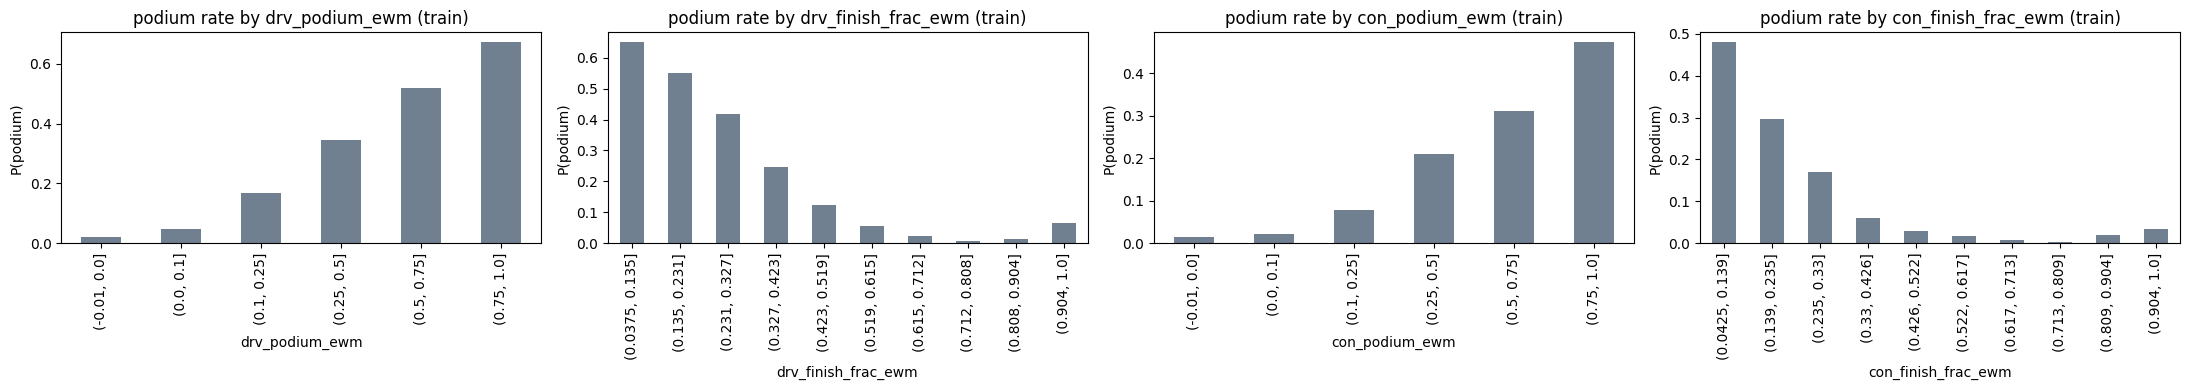

podium rate by drv_podium_ewm (train):


,rows,podium_rate
drv_podium_ewm,,
"(-0.01, 0.0]",7987,0.021
"(0.0, 0.1]",5818,0.046
"(0.1, 0.25]",3163,0.169
"(0.25, 0.5]",2934,0.346
"(0.5, 0.75]",1540,0.519
"(0.75, 1.0]",348,0.672


podium rate by con_podium_ewm (train):


,rows,podium_rate
con_podium_ewm,,
"(-0.01, 0.0]",4393,0.014
"(0.0, 0.1]",6661,0.023
"(0.1, 0.25]",2826,0.079
"(0.25, 0.5]",3233,0.210
"(0.5, 0.75]",3054,0.311
"(0.75, 1.0]",2036,0.472


Spearman ρ with podium (train):


drv_podium_ewm         0.428
drv_finish_frac_ewm   -0.383
con_podium_ewm         0.403
con_finish_frac_ewm   -0.391
Name: podium, dtype: float64

redundancy (Spearman, train):


,drv_podium_ewm,drv_finish_frac_ewm,con_podium_ewm,con_finish_frac_ewm,grid_rank,drv_points_share
drv_podium_ewm,1.00,-0.73,0.70,-0.65,-0.64,0.67
drv_finish_frac_ewm,-0.73,1.00,-0.64,0.73,0.57,-0.68
con_podium_ewm,0.70,-0.64,1.00,-0.88,-0.60,0.57
con_finish_frac_ewm,-0.65,0.73,-0.88,1.00,0.59,-0.59
grid_rank,-0.64,0.57,-0.60,0.59,1.00,-0.59
drv_points_share,0.67,-0.68,0.57,-0.59,-0.59,1.00


podium rate within grid bands, by driver form (train):


drv_podium_ewm,low (≤5%),mid,high (>30%)
grid_rank,,,
P1,0.435,0.527,0.668
P2-3,0.279,0.407,0.584
P4-6,0.114,0.234,0.396
P7-10,0.049,0.112,0.211
P11-15,0.015,0.054,0.130
P16+,0.002,0.015,0.150


In [158]:
train = base[base["year"] <= TRAIN_END]
form_bins = [-0.01, 0, 0.1, 0.25, 0.5, 0.75, 1]

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, col in zip(axes, FORM_FEATURES):
    bins = form_bins if "podium" in col else 10
    train.groupby(pd.cut(train[col], bins), observed=True)["podium"].mean().plot(kind="bar", ax=ax, color="slategray")
    ax.set_title(f"podium rate by {col} (train)")
    ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

for col in ["drv_podium_ewm", "con_podium_ewm"]:
    print(f"podium rate by {col} (train):")
    display(train.groupby(pd.cut(train[col], form_bins), observed=True)["podium"].agg(rows="size", podium_rate="mean").round(3))

print("Spearman ρ with podium (train):")
display(train[FORM_FEATURES + ["podium"]].corr(method="spearman")["podium"].drop("podium").round(3))
print("redundancy (Spearman, train):")
display(train[FORM_FEATURES + ["grid_rank", "drv_points_share"]].corr(method="spearman").round(2))

# does form add anything beyond the grid? same grid band, split by driver form
band = pd.cut(train["grid_rank"], GRID_BANDS, labels=GRID_BAND_LABELS)
form_level = pd.cut(train["drv_podium_ewm"], [-0.01, 0.05, 0.3, 1], labels=["low (≤5%)", "mid", "high (>30%)"])
print("podium rate within grid bands, by driver form (train):")
train.pivot_table(index=band, columns=form_level, values="podium", aggfunc="mean", observed=True).round(3)


**Form - findings (train)**
- **Leakage-safe, verified three ways:** (1) every driver's first start has no form value; (2) 10 races spread over the years were rebuilt with only the data up to that race and their own results scrambled, and their form values are identical to the full table, so a race's form uses neither its own result nor anything later; (3) Hamilton's values match a hand calculation, and a race's result only shows up in the *next* row: on 2007-07-22 he missed the podium, but that race's own value is still 1.000; it drops to 0.827 at the following race.
- **Why EWM with half-life 5:** compared as single features on train, the EWM beats every fixed window (PR-AUC 0.474 vs 0.459 for the best window, last 15 starts; ROC-AUC 0.849 vs 0.840). Short windows are noisy (last 3: PR-AUC 0.400), the whole career is stale (0.385), and "season so far" is empty at every opener (88.7% coverage) and repeats the standings. The half-life barely matters (3, 5, 8 → 0.468–0.474), so the choice is robust.
- **Strong, monotonic signal:** driver podium form of 0 → 2.1% podium rate, 0.25–0.5 → 34.6%, above 0.75 → 67.2% (ρ = +0.43). Team form: 1.4% → 47.2% (ρ = +0.40). Finishing-position form is almost as strong (ρ ≈ −0.38 / −0.39).
- **Form adds information beyond the grid.** In every grid band, drivers in good form podium far more often: from P4–6, 39.6% with high form vs 11.4% with low form; from P16+, 15.0% vs 0.2%. Recent results capture car and driver pace that a single grid slot does not, e.g. a top car that qualified badly.
- **Redundancy:** driver and team form correlate at 0.70, and form overlaps with grid (|ρ| ≈ 0.64) and standings (≈ 0.67): good cars are fast everywhere. Tree models handle this; for logistic regression and XAI it spreads importance across these groups. The ablation measures what form adds on top.
- **Missing:** 683 rows (a driver's first start) and 262 rows (a team's first race) have no history. Left NA for the pipeline.

## 4.5 Reliability (previous races only)
A fast car only podiums if it finishes. Reliability is a different signal from pace: it says how likely the car or driver is to drop out, not how fast they are.
- `con_mech_dnf_ewm`: the team's recent **mechanical-failure** rate, i.e. the share of its cars that retired with a technical failure in each past race, averaged with the same EWM as form (half-life 5). It uses the same `mechanical` status group as DEQ3 (crashes, driver errors and disqualifications excluded).
- `drv_incident_ewm`: the driver's recent rate of retiring in a crash, spin or collision (`incident_driver` group).

Only the status of **earlier** races is used (`status_group` is post-race for the current race), with the same `shift(1)` rule and the same leakage check as form. First start / first team race → NA.

In [159]:
def build_reliability(df):
    """Recent reliability from past races only (status of earlier races; the current race's status is never used)."""
    out = pd.DataFrame(index=df.index)
    mech = (df["status_group"] == "mechanical").astype(float)            # same definition as DEQ3
    incident = (df["status_group"] == "incident_driver").astype(float)   # crash / spin / collision

    # team: share of its cars that failed mechanically in each race, then the EWM over its past races
    team = (df.assign(mech=mech)
              .groupby(["raceId", "constructorId"], sort=False)
              .agg(date=("date", "first"), mech_share=("mech", "mean"))
              .reset_index()
              .sort_values(["date", "raceId"], kind="stable"))
    team["con_mech_dnf_ewm"] = past_ewm(team["mech_share"], team["constructorId"])
    out["con_mech_dnf_ewm"] = df[["raceId", "constructorId"]].merge(
        team[["raceId", "constructorId", "con_mech_dnf_ewm"]], on=["raceId", "constructorId"],
        how="left", validate="many_to_one")["con_mech_dnf_ewm"].to_numpy()
    out["drv_incident_ewm"] = past_ewm(incident, df["driverId"])
    return out


RELIABILITY_FEATURES = ["con_mech_dnf_ewm", "drv_incident_ewm"]
base[RELIABILITY_FEATURES] = build_reliability(base)

# same leakage check as for form: rebuild a few races without their own result and without later races
for race in check_races:
    upto = base[base["date"] <= base.loc[base["raceId"] == race, "date"].iloc[0]].copy()
    this = upto["raceId"] == race
    upto.loc[this, "status_group"] = np.where(upto.loc[this, "status_group"] == "mechanical", "classified", "mechanical")
    rebuilt = build_reliability(upto).loc[this]
    assert np.allclose(rebuilt.to_numpy(), base.loc[rebuilt.index, RELIABILITY_FEATURES].to_numpy(), equal_nan=True), race
print(f"leakage check: {len(check_races)} races rebuilt with their own status changed: values identical ✓")

assert len(base) == 24586
print("missing values:", base[RELIABILITY_FEATURES].isna().sum().to_dict())
base[RELIABILITY_FEATURES].describe().round(3)

leakage check: 10 races rebuilt with their own status changed: values identical ✓
missing values: {'con_mech_dnf_ewm': 262, 'drv_incident_ewm': 683}


,con_mech_dnf_ewm,drv_incident_ewm
count,24324.000,23903.000
mean,0.260,0.112
std,0.178,0.121
min,0.000,0.000
25%,0.112,0.016
50%,0.241,0.083
75%,0.378,0.167
max,1.000,1.000


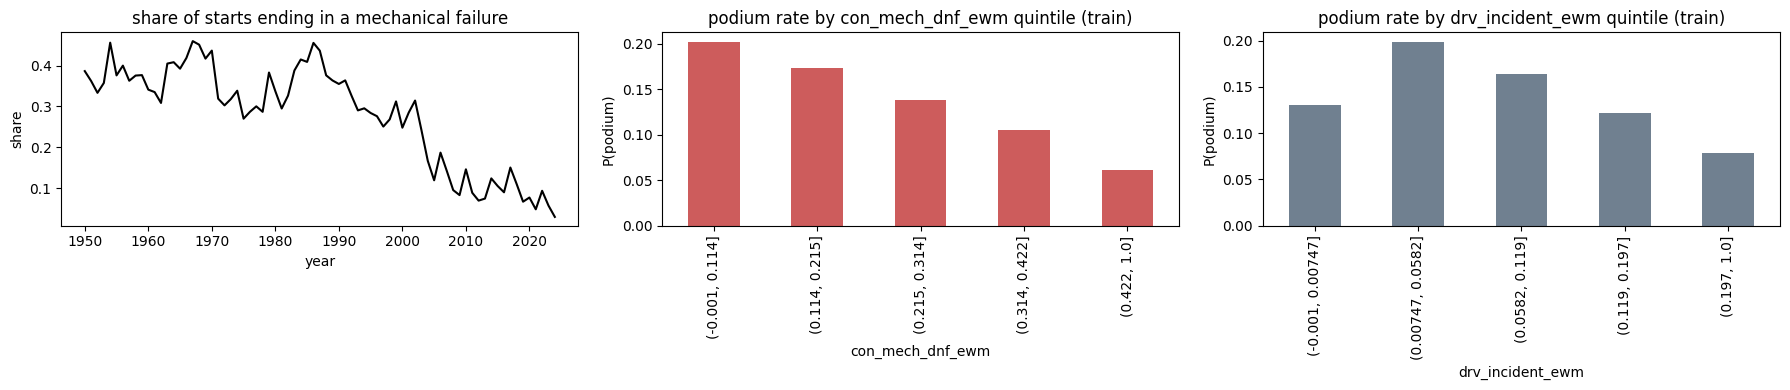

podium rate by con_mech_dnf_ewm quintile (train):


,rows,podium_rate
con_mech_dnf_ewm,,
"(-0.001, 0.114]",4441,0.202
"(0.114, 0.215]",4441,0.173
"(0.215, 0.314]",4440,0.139
"(0.314, 0.422]",4440,0.106
"(0.422, 1.0]",4441,0.061


podium rate by drv_incident_ewm quintile (train):


,rows,podium_rate
drv_incident_ewm,,
"(-0.001, 0.00747]",4358,0.130
"(0.00747, 0.0582]",4358,0.199
"(0.0582, 0.119]",4358,0.163
"(0.119, 0.197]",4358,0.121
"(0.197, 1.0]",4358,0.079


Spearman ρ with podium (train):


...

podium,con_mech_dnf_ewm,drv_incident_ewm
decade,,
1950,-0.218,0.078
1960,-0.122,-0.033
1970,-0.122,-0.027
1980,-0.185,-0.038
1990,-0.246,-0.091
2000,-0.238,-0.127
2010,-0.196,-0.116


podium rate within grid bands, by team reliability (train):


con_mech_dnf_ewm,most reliable,middle,least reliable
grid_rank,,,
P1,0.752,0.553,0.431
P2-3,0.586,0.473,0.360
P4-6,0.266,0.295,0.228
P7-10,0.085,0.113,0.087
P11-15,0.029,0.028,0.035
P16+,0.013,0.003,0.005


redundancy (Spearman, train):


,con_mech_dnf_ewm,drv_incident_ewm,con_podium_ewm,drv_podium_ewm,grid_rank
con_mech_dnf_ewm,1.00,0.02,-0.22,-0.21,0.22
drv_incident_ewm,0.02,1.00,-0.11,-0.10,0.05


In [160]:
train = base[base["year"] <= TRAIN_END]
decade = (train["year"] // 10 * 10).rename("decade")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
base.groupby("year")["status_group"].apply(lambda s: (s == "mechanical").mean()).plot(ax=axes[0], color="black")
axes[0].set_title("share of starts ending in a mechanical failure")
axes[0].set_ylabel("share")

for ax, col, color in [(axes[1], "con_mech_dnf_ewm", "indianred"), (axes[2], "drv_incident_ewm", "slategray")]:
    train.groupby(pd.qcut(train[col], 5, duplicates="drop"), observed=True)["podium"].mean().plot(kind="bar", ax=ax, color=color)
    ax.set_title(f"podium rate by {col} quintile (train)")
    ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

for col in RELIABILITY_FEATURES:
    print(f"podium rate by {col} quintile (train):")
    display(train.groupby(pd.qcut(train[col], 5, duplicates="drop"), observed=True)["podium"].agg(rows="size", podium_rate="mean").round(3))

print("Spearman ρ with podium (train):")
display(train[RELIABILITY_FEATURES + ["podium"]].corr(method="spearman")["podium"].drop("podium").round(3))

# failure rates fell from ~40% to ~8% over the decades: does the signal hold WITHIN a decade, or is it just era?
print("Spearman ρ with podium within each decade (train):")
display(train.groupby(decade)[RELIABILITY_FEATURES + ["podium"]]
        .apply(lambda g: g.corr(method="spearman")["podium"].drop("podium")).round(3))

# and beyond the grid: same grid band, most vs least reliable third of teams
band = pd.cut(train["grid_rank"], GRID_BANDS, labels=GRID_BAND_LABELS)
reliab = pd.qcut(train["con_mech_dnf_ewm"], 3, labels=["most reliable", "middle", "least reliable"])
print("podium rate within grid bands, by team reliability (train):")
display(train.pivot_table(index=band, columns=reliab, values="podium", aggfunc="mean", observed=True).round(3))

print("redundancy (Spearman, train):")
train[RELIABILITY_FEATURES + ["con_podium_ewm", "drv_podium_ewm", "grid_rank"]].corr(method="spearman").loc[RELIABILITY_FEATURES].round(2)

**Reliability - findings (train)**
- **Leakage-safe:** the same rebuild check as form (10 races, own status changed, no later data) gives identical values.
- **Team reliability is a real signal:** the most reliable fifth of teams podium 20.2% of the time, the least reliable fifth 6.1% (ρ = −0.15).
- **It is not just an era effect.** Mechanical failures fell from about 40% of starts (1960s) to 8% (2010s), so the raw rate partly tracks the decade. But the signal is *stronger within each decade* (ρ between −0.12 and −0.25) than overall, so it measures the team, not the era.
- **It matters most at the front, beyond the grid:** from pole, the most reliable third of teams podium 75.2% vs 43.1% for the least reliable; from P2–3, 58.6% vs 36.0%. A front-runner mostly loses a podium by breaking down. In the midfield there is little difference, because those cars rarely podium either way.
- **Low redundancy:** |ρ| ≤ 0.22 with form and grid, so reliability adds information the other groups do not have.
- **Driver incidents are weak and not monotonic** (ρ = −0.07): the fifth with the most incidents podiums 7.9% vs 19.9% for low-incident drivers, but drivers with **zero** recent incidents podium only 13.0% (many are newcomers with short histories). Within decades it is negative from the 1990s on (−0.09 to −0.13). It is kept as a candidate; the ablation decides whether it earns its place.
- **Missing:** 262 rows (a team's first race) and 683 rows (a driver's first start) have no history. Left NA for the pipeline.

## 4.6 Circuit history (earlier visits only)
Some drivers go well at particular tracks. This group asks whether a driver's past results **at this circuit** say more than their general form.
- `drv_circuit_visits`: earlier starts at this circuit (0 = first visit).
- `drv_circuit_last_finish`: finishing position (share of the field) at the **last** visit.
- `drv_circuit_avg_finish`: average finishing share over **all** earlier visits (less noisy than one race, but older).

Built like form: rows in date order, grouped by driver *and* circuit, `shift(1)` so the current race is never included. A first visit has no history → NA (and `drv_circuit_visits = 0` marks exactly those rows, so no separate flag is needed).

In [161]:
def build_circuit_history(df):
    """The driver's history at this circuit, from earlier visits only. df must be sorted by race date."""
    out = pd.DataFrame(index=df.index)
    finish_frac = df.groupby("raceId")["positionOrder"].rank(method="first") / df["field_size"]
    by_driver_circuit = finish_frac.groupby([df["driverId"], df["circuitId"]])
    out["drv_circuit_visits"] = by_driver_circuit.cumcount()                    # earlier starts at this circuit
    out["drv_circuit_last_finish"] = by_driver_circuit.shift(1)                 # finish share at the last visit
    out["drv_circuit_avg_finish"] = by_driver_circuit.transform(lambda s: s.shift(1).expanding().mean())
    return out


CIRCUIT_FEATURES = ["drv_circuit_visits", "drv_circuit_last_finish", "drv_circuit_avg_finish"]
base[CIRCUIT_FEATURES] = build_circuit_history(base)

for race in check_races:
    upto = base[base["date"] <= base.loc[base["raceId"] == race, "date"].iloc[0]].copy()
    this = upto["raceId"] == race
    upto.loc[this, "positionOrder"] = upto.loc[this, "positionOrder"].max() + 1 - upto.loc[this, "positionOrder"]
    rebuilt = build_circuit_history(upto).loc[this]
    assert np.allclose(rebuilt.to_numpy(), base.loc[rebuilt.index, CIRCUIT_FEATURES].to_numpy(), equal_nan=True), race
print(f"leakage check: {len(check_races)} races rebuilt with their own result reversed: values identical ✓")

assert len(base) == 24586
assert (base["drv_circuit_last_finish"].isna() == (base["drv_circuit_visits"] == 0)).all()
period = pd.cut(base["year"], [0, TRAIN_END, VAL_END, 9999], labels=["train seasons", "val seasons", "test seasons"])
print("share of starters with an earlier visit, by period:",
      base.groupby(period, observed=True)["drv_circuit_visits"].apply(lambda s: (s > 0).mean()).round(3).to_dict())
base[CIRCUIT_FEATURES].describe().round(3)

leakage check: 10 races rebuilt with their own result reversed: values identical ✓
share of starters with an earlier visit, by period: {'train seasons': 0.686, 'val seasons': 0.719, 'test seasons': 0.876}


,drv_circuit_visits,drv_circuit_last_finish,drv_circuit_avg_finish
count,24586.000,17138.000,17138.000
mean,2.700,0.495,0.507
std,3.212,0.293,0.208
min,0.000,0.031,0.037
25%,0.000,0.231,0.362
50%,2.000,0.478,0.500
75%,4.000,0.750,0.640
max,20.000,1.000,1.000


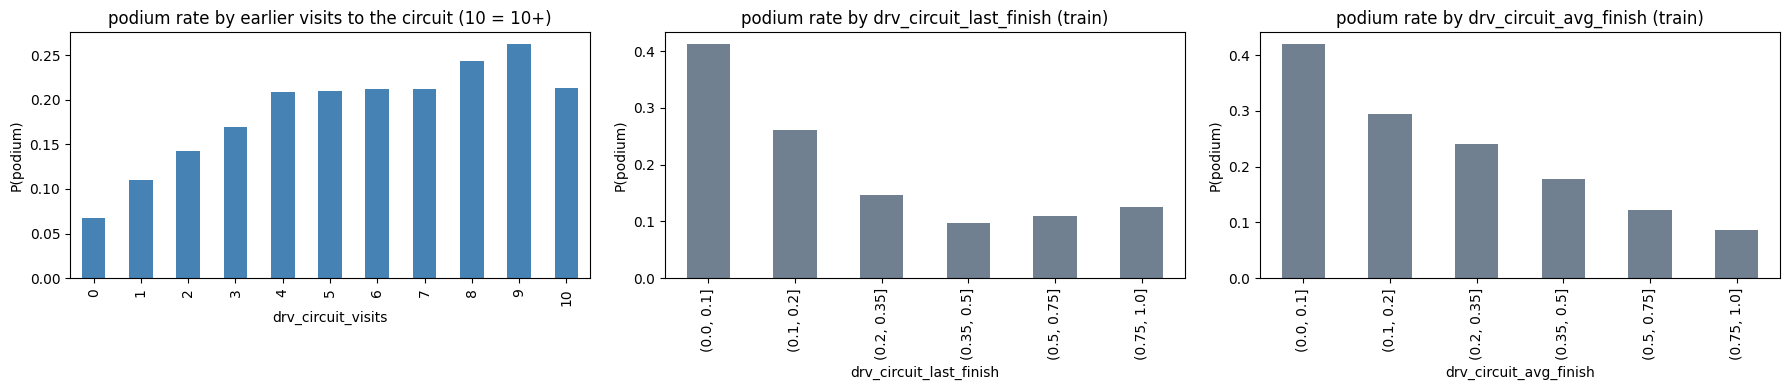

podium rate by finish share at the last visit (train):


,rows,podium_rate
drv_circuit_last_finish,,
"(0.0, 0.1]",1557,0.412
"(0.1, 0.2]",1845,0.262
"(0.2, 0.35]",2464,0.147
"(0.35, 0.5]",2391,0.097
"(0.5, 0.75]",3381,0.110
"(0.75, 1.0]",3759,0.126


Spearman ρ with podium (train rows with an earlier visit):


drv_circuit_visits         0.117
drv_circuit_last_finish   -0.186
drv_circuit_avg_finish    -0.183
Name: podium, dtype: float64

redundancy with form (Spearman, train rows with an earlier visit):


,drv_circuit_last_finish,drv_circuit_avg_finish,drv_finish_frac_ewm,drv_podium_ewm,grid_rank
drv_circuit_last_finish,1.00,0.72,0.40,-0.38,0.27
drv_circuit_avg_finish,0.72,1.00,0.39,-0.38,0.26


podium rate by grid band × form, split by the result at the last visit (train):


drv_circuit_last_finish   last visit: front  middle   back
grid_rank drv_podium_ewm                                  
P1-3      low form                    0.400   0.292  0.330
          mid form                    0.448   0.400  0.457
          high form                   0.646   0.607  0.591
P4-6      low form                    0.083   0.126  0.125
          mid form                    0.270   0.243  0.201
          high form                   0.418   0.372  0.385
P7-10     low form                    0.049   0.043  0.053
          mid form                    0.172   0.121  0.094
          high form                   0.225   0.230  0.203
P11+      low form                    0.000   0.005  0.008
          mid form                    0.043   0.047  0.036
          high form                   0.129   0.170  0.133

In [162]:
train = base[base["year"] <= TRAIN_END]
th = train[train["drv_circuit_visits"] > 0]
finish_bins = [0, 0.1, 0.2, 0.35, 0.5, 0.75, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
train.groupby(train["drv_circuit_visits"].clip(upper=10))["podium"].mean().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("podium rate by earlier visits to the circuit (10 = 10+)")
for ax, col in [(axes[1], "drv_circuit_last_finish"), (axes[2], "drv_circuit_avg_finish")]:
    th.groupby(pd.cut(th[col], finish_bins), observed=True)["podium"].mean().plot(kind="bar", ax=ax, color="slategray")
    ax.set_title(f"podium rate by {col} (train)")
for ax in axes:
    ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

print("podium rate by finish share at the last visit (train):")
display(th.groupby(pd.cut(th["drv_circuit_last_finish"], finish_bins), observed=True)["podium"].agg(rows="size", podium_rate="mean").round(3))
print("Spearman ρ with podium (train rows with an earlier visit):")
display(th[CIRCUIT_FEATURES + ["podium"]].corr(method="spearman")["podium"].drop("podium").round(3))
print("redundancy with form (Spearman, train rows with an earlier visit):")
display(th[["drv_circuit_last_finish", "drv_circuit_avg_finish", "drv_finish_frac_ewm", "drv_podium_ewm", "grid_rank"]]
        .corr(method="spearman").loc[["drv_circuit_last_finish", "drv_circuit_avg_finish"]].round(2))

# does track history add anything beyond grid AND form? same grid band and same form level, split by the last visit
band = pd.cut(th["grid_rank"], [0, 3, 6, 10, np.inf], labels=["P1-3", "P4-6", "P7-10", "P11+"])
form_level = pd.cut(th["drv_podium_ewm"], [-0.01, 0.05, 0.3, 1], labels=["low form", "mid form", "high form"])
last_visit = pd.cut(th["drv_circuit_last_finish"], [0, 0.15, 0.4, 1], labels=["last visit: front", "middle", "back"])
print("podium rate by grid band × form, split by the result at the last visit (train):")
th.pivot_table(index=[band, form_level], columns=last_visit, values="podium", aggfunc="mean", observed=True).round(3)

**Circuit history — findings (train)**
- **Leakage-safe:** the rebuild check (10 races, own result reversed, no later data) gives identical values.
- **Coverage:** 68.6% of training starters have raced at the circuit before (71.9% validation, 87.6% test).
- **On its own there is a signal:** a top-10% finish at the last visit → 41.2% podium rate, a finish in the 35–50% band → 9.7% (ρ = −0.19). More earlier visits → more podiums (ρ = +0.12), but that is mostly experience.
- **It is not monotonic:** a finish in the back quarter last time (12.6%) podiums more often than one in the middle (9.7%). Finishing position counts retirements as last, so a fast car that broke down last year looks like a back-marker. The feature mixes pace and reliability.
- **Beyond grid and form it adds almost nothing.** Comparing drivers in the same grid band *and* with the same recent form, the result at the last visit barely changes the podium rate, with no consistent direction (e.g. P1–3, high form: 64.6% front vs 59.1% back; P11+, high form: 12.9% vs 13.3%). Track history mostly repeats what form and grid already say. The overlap is moderate (|ρ| with form and grid up to ≈ 0.3), so the overlap alone doesn't explain it: the extra track-specific information is just small.
- **Decision:** kept as its own ablation group, because the brief asks to measure each group after training. The evidence here predicts a small contribution. `drv_circuit_last_finish` and `drv_circuit_avg_finish` correlate at 0.72; if the ablation shows no gain, the group is a candidate for removal.
- **Missing:** first visits (31.4% of train) are NA; `drv_circuit_visits = 0` identifies them.

## 4.7 Driver attributes
- `drv_starts_before`: number of earlier F1 starts (experience).
- `age`: age on race day, from `dob` (typed in 1.5).
- `teammate_grid_gap`: own grid slot minus the average grid slot of the team's other cars in the same race. Teammates drive the same car, so this compares drivers on equal machinery. Negative = ahead of the teammate. NA for single-car entries.

All three are known before the race: earlier starts and date of birth from history, the teammate's grid slot from the published grid.

In [163]:
dob = base["driverId"].map(drivers_clean.set_index("driverId")["dob"])
base["age"] = (base["date"] - dob).dt.days / 365.25
base["drv_starts_before"] = base.groupby("driverId").cumcount()

# teammate comparison: own grid slot minus the average grid slot of the team's other cars (same car → isolates the driver)
team_sum = base.groupby(["raceId", "constructorId"])["grid_rank"].transform("sum")
team_cars = base.groupby(["raceId", "constructorId"])["grid_rank"].transform("size")
base["teammate_grid_gap"] = (base["grid_rank"] - (team_sum - base["grid_rank"]) / (team_cars - 1)).where(team_cars > 1)

DRIVER_FEATURES = ["drv_starts_before", "age", "teammate_grid_gap"]

assert len(base) == 24586
print("missing values:", base[DRIVER_FEATURES].isna().sum().to_dict(), "| single-car entries:", int((team_cars == 1).sum()))
base[DRIVER_FEATURES].describe().round(2)

missing values: {'drv_starts_before': 0, 'age': 0, 'teammate_grid_gap': 1697} | single-car entries: 1697


,drv_starts_before,age,teammate_grid_gap
count,24586.00,24586.00,22889.00
mean,67.96,29.91,-0.00
std,68.83,5.24,5.67
min,0.00,17.45,-26.00
25%,15.00,26.07,-3.00
50%,45.00,29.36,0.00
75%,99.00,33.24,3.00
max,401.00,55.80,26.00


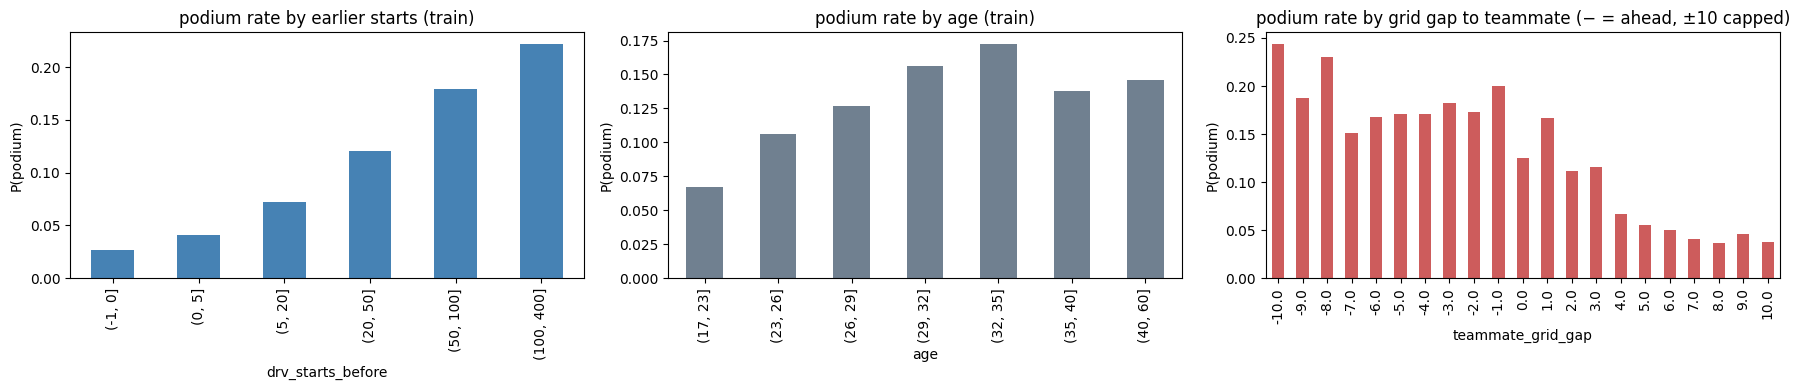

podium rate by earlier starts (train):


,rows,podium_rate
drv_starts_before,,
"(-1, 0]",669,0.027
"(0, 5]",2214,0.041
"(5, 20]",4386,0.072
"(20, 50]",5360,0.121
"(50, 100]",4999,0.179
"(100, 400]",4831,0.222


Spearman ρ with podium (train):


drv_starts_before    0.191
age                  0.066
teammate_grid_gap   -0.151
Name: podium, dtype: float64

podium rate within grid bands, ahead of vs behind the teammate (train):


teammate_grid_gap,ahead of teammate,behind teammate
grid_rank,,
P1,0.634,NaN
P2-3,0.469,0.591
P4-6,0.240,0.313
P7-10,0.083,0.111
P11-15,0.024,0.037
P16+,0.003,0.009


redundancy (Spearman, train):


,drv_starts_before,age,teammate_grid_gap,grid_rank,drv_podium_ewm
drv_starts_before,1.00,0.44,-0.12,-0.35,0.52
age,0.44,1.00,0.02,-0.10,0.27
teammate_grid_gap,-0.12,0.02,1.00,0.45,-0.19


In [164]:
train = base[base["year"] <= TRAIN_END]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
train.groupby(pd.cut(train["drv_starts_before"], [-1, 0, 5, 20, 50, 100, 400]), observed=True)["podium"].mean().plot(
    kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("podium rate by earlier starts (train)")
train.groupby(pd.cut(train["age"], [17, 23, 26, 29, 32, 35, 40, 60]), observed=True)["podium"].mean().plot(
    kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("podium rate by age (train)")
train.groupby(train["teammate_grid_gap"].clip(-10, 10).round())["podium"].mean().plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("podium rate by grid gap to teammate (− = ahead, ±10 capped)")
for ax in axes:
    ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

print("podium rate by earlier starts (train):")
display(train.groupby(pd.cut(train["drv_starts_before"], [-1, 0, 5, 20, 50, 100, 400]), observed=True)["podium"]
        .agg(rows="size", podium_rate="mean").round(3))
print("Spearman ρ with podium (train):")
display(train[DRIVER_FEATURES + ["podium"]].corr(method="spearman")["podium"].drop("podium").round(3))

# teammate gap beyond the grid: same grid band, ahead of vs behind the teammate
band = pd.cut(train["grid_rank"], GRID_BANDS, labels=GRID_BAND_LABELS)
vs_mate = np.sign(train["teammate_grid_gap"]).map({-1: "ahead of teammate", 1: "behind teammate"})
print("podium rate within grid bands, ahead of vs behind the teammate (train):")
display(train.pivot_table(index=band, columns=vs_mate, values="podium", aggfunc="mean", observed=True).round(3))

print("redundancy (Spearman, train):")
train[DRIVER_FEATURES + ["grid_rank", "drv_podium_ewm"]].corr(method="spearman").loc[DRIVER_FEATURES].round(2)

**Driver — findings (train)**
- **Experience is a clear, monotonic signal:** first start → 2.7% podium rate, 6–20 earlier starts → 7.2%, more than 100 → 22.2% (ρ = +0.19). Part of this is selection: drivers who do well keep their seats and pile up starts. It overlaps with form (ρ = 0.52), so the ablation shows what it adds.
- **Age is weak on its own** (ρ = +0.07) and largely a stand-in for experience (ρ = 0.44 between them). Kept as a cheap candidate; the ablation decides.
- **`teammate_grid_gap` measures the car more than the driver.** Overall, being ahead of the teammate goes with more podiums (ρ = −0.15), but that mostly reflects grid position. Within the same grid band it reverses: drivers *behind* their teammate podium more (P2–3: 59.1% vs 46.9%; P4–6: 31.3% vs 24.0%), because a teammate even further up means the car is strong. Combined with `grid_rank`, it tells the model how strong the team is this weekend, not only how good the driver is. Tree models can use this combination; for a linear model it mostly repeats the grid.
- **Missing:** `teammate_grid_gap` is NA for 1,697 single-car entries (mostly 1950s–80s privateers). Age and experience are complete.

## 4.8 Race context
- `is_home_race`: the race is in one of the driver's home countries (1.5; dual nationalities count both). This is the DEQ2 variable.
- `season_progress`: `round / rounds in the season` (0–1). Raw `round` is not comparable: seasons had 7 to 24 rounds. The calendar is published before the season, so this is pre-race information.

**`era` is not a feature.** It stays in the table as an identifier for analysis (e.g. errors per era), for the reason shown in the last table below.

In [165]:
home = base["driverId"].map(drivers_clean.set_index("driverId")["home_countries"]).fillna("")
country = base["circuitId"].map(circuits_clean.set_index("circuitId")["country"])
base["is_home_race"] = [int(c in h.split("|")) for c, h in zip(country, home)]   # dual nationalities count both (1.5)

# share of the season done: the calendar (number of rounds) is published before the season
base["season_progress"] = base["round"] / base["year"].map(races_clean.groupby("year")["round"].max())

CONTEXT_FEATURES = ["is_home_race", "season_progress"]

assert len(base) == 24586
assert base["season_progress"].between(0, 1).all()
print("home-race starts:", int(base["is_home_race"].sum()), f"({base['is_home_race'].mean():.1%} of starts)")
base[CONTEXT_FEATURES].describe().round(3)

home-race starts: 1932 (7.9% of starts)


,is_home_race,season_progress
count,24586.000,24586.000
mean,0.079,0.539
std,0.269,0.288
min,0.000,0.042
25%,0.000,0.294
50%,0.000,0.545
75%,0.000,0.789
max,1.000,1.000


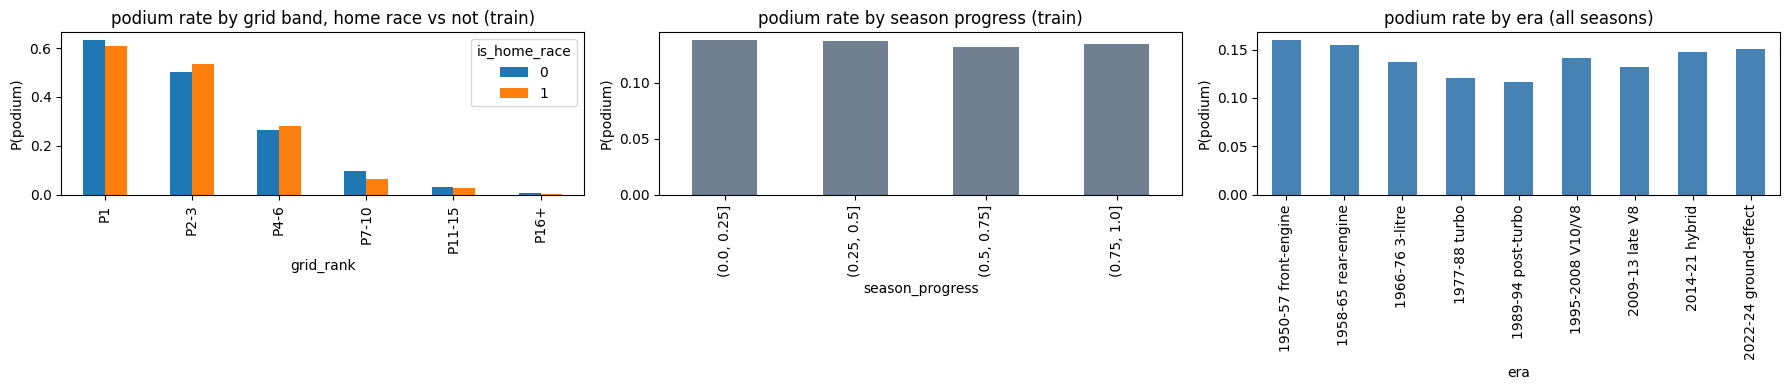

home race vs not (train):


,rows,podium_rate,avg_grid_rank
is_home_race,,,
0,20594,0.137,11.787
1,1865,0.115,12.769


podium rate by grid band, home race vs not (train):


mean         size     
is_home_race      0      1     0    1
grid_rank                            
P1            0.633  0.608   939   74
P2-3          0.501  0.536  1872  140
P4-6          0.265  0.282  2807  216
P7-10         0.097  0.065  3704  323
P11-15        0.031  0.027  4607  405
P16+          0.007  0.003  6665  707

Spearman ρ of drv_points_share with podium, by season quarter (train):


season_progress
(0.0, 0.25]    0.237
(0.25, 0.5]    0.384
(0.5, 0.75]    0.437
(0.75, 1.0]    0.435
dtype: float64

era by split (which eras the model can learn from):


year,train,val,test
era,,,
1950-57 front-engine,1151,0,0
1958-65 rear-engine,1442,0,0
1966-76 3-litre,3050,0,0
1977-88 turbo,4656,0,0
1989-94 post-turbo,2480,0,0
1995-2008 V10/V8,5074,0,0
2009-13 late V8,2135,0,0
2014-21 hybrid,2471,775,0
2022-24 ground-effect,0,0,1352


In [166]:
train = base[base["year"] <= TRAIN_END]
band = pd.cut(train["grid_rank"], GRID_BANDS, labels=GRID_BAND_LABELS)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
train.pivot_table(index=band, columns="is_home_race", values="podium", aggfunc="mean", observed=True).plot(kind="bar", ax=axes[0])
axes[0].set_title("podium rate by grid band, home race vs not (train)")
train.groupby(pd.cut(train["season_progress"], [0, 0.25, 0.5, 0.75, 1]), observed=True)["podium"].mean().plot(
    kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("podium rate by season progress (train)")
base.groupby("era", sort=False)["podium"].mean().plot(kind="bar", ax=axes[2], color="steelblue")
axes[2].set_title("podium rate by era (all seasons)")
for ax in axes:
    ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

print("home race vs not (train):")
display(train.groupby("is_home_race")["podium"].agg(rows="size", podium_rate="mean", avg_grid_rank=lambda s: np.nan)
        .assign(avg_grid_rank=train.groupby("is_home_race")["grid_rank"].mean()).round(3))
print("podium rate by grid band, home race vs not (train):")
display(train.pivot_table(index=band, columns="is_home_race", values="podium", aggfunc=["mean", "size"], observed=True).round(3))

# does the meaning of the standings change during the season? correlation of points share with podium per season quarter
quarter = pd.cut(train["season_progress"], [0, 0.25, 0.5, 0.75, 1])
print("Spearman ρ of drv_points_share with podium, by season quarter (train):")
display(train.groupby(quarter, observed=True)[["drv_points_share", "podium"]]
        .apply(lambda g: g["drv_points_share"].corr(g["podium"], method="spearman")).round(3))

print("era by split (which eras the model can learn from):")
period = pd.cut(base["year"], [0, TRAIN_END, VAL_END, 9999], labels=["train", "val", "test"])
pd.crosstab(base["era"], period).loc[base["era"].unique()]

**Context — findings (train)**
- **Home races, raw:** 7.9% of starts are home races, and they podium *less* often (11.5% vs 13.7%), because home starters start further back on average (grid rank 12.8 vs 11.8): many are local one-off entries.
- **Home races, same grid band:** no consistent effect (P2–3: 53.6% home vs 50.1% away; P7–10: 6.5% vs 9.7%), and the samples at the front are small (74 home starts from pole). On its own `is_home_race` is a weak feature (ρ = −0.02). DEQ2 answers the home-advantage question properly with grid controlled; here it stays a candidate for the ablation.
- **Season progress matters through the standings, not on its own** (ρ = −0.005). The standings get more meaningful as the season goes on: the correlation of `drv_points_share` with podium is 0.24 in the first quarter of a season and 0.44 in the second half. Tree models can use this combination (a big points share late in the season is a stronger signal).
- **Why `era` is not a feature:** the test seasons (2022–24) are a regulation era that never appears in training, and validation (2014–21 hybrid) is only partly covered. A one-hot `era` would give every test row a category the model never learned. The differences between eras that matter (field size, reliability, points systems) are already captured by `field_size`, the points shares and the reliability rates. `era` is kept as an identifier column for analysis only.

## 4.9 Missing values
Every gap left after 4.1–4.8 has a known cause (season opener, debut, first visit, no qualifying record, no constructors' championship before 1958). So instead of filling them with a statistic, each one is filled with **real pre-race information** wherever it exists. Everything used is from earlier races, or from teammates' pre-race values in the same race, so no leakage is added (checked below).

| Feature(s) | Why missing | Filled with |
|---|---|---|
| `grid_minus_quali` | no qualifying record | 0 = no known grid change (`has_quali = 0` marks these rows) |
| `con_points_share`, `con_champ_pos` (1950–57) | no constructors' championship yet | **rebuilt from race results**: a team's points = the sum of its drivers' points so far that season, ranked like the official table |
| `drv_champ_pos`, `con_champ_pos` (season openers) | nobody ranked yet this season | **last season's final position**; not ranked last season → behind everyone ranked; 1950 opener → 20 (nobody ranked anywhere) |
| driver form (first start) | no earlier start | teammates' form in the same race (same car) → team form → base rate |
| team form (first race) | no earlier race | its best driver's form → base rate |
| reliability (no history) | no earlier start / race | the **whole field's** recent rate (earlier races only) |
| circuit last / average finish (first visit) | never raced here | the driver's general finishing form: no track history → expect their usual result (`drv_circuit_visits = 0` marks these rows) |
| `teammate_grid_gap` | single-car entry | 0, plus a new flag `has_teammate` so "no teammate" is not read as "level with the teammate" |

Base rate: `3 / field_size` for podium rates (every car's share of the three podium places), 0.5 (middle of the field) for finishing shares.

**Not filled here:** `quali_gap_pct` has no pre-race substitute. It is imputed inside the model pipeline by grid band, learned on training rows only (evidence in 4.2). Keeping this one learned step in the pipeline is also what the preprocessing-order experiments compare. Championship positions are capped at 20 (as in 4.3).

In [167]:
CHAMP_POS_CAP = 20   # beyond 20th the podium rate is flat (4.3)


def final_standings(table, key, years):
    """Final championship position of each entry per season, plus how many entries were ranked."""
    last_round = races_clean.loc[races_clean.groupby("year")["round"].idxmax()].set_index("year")["raceId"]
    fin = table[table["raceId"].isin(last_round.loc[years])].merge(races_clean[["raceId", "year"]], on="raceId")
    fin["ranked"] = fin.groupby("year")["position"].transform("size")
    return fin[["year", key, "position", "ranked"]]


def early_constructor_standings(results):
    """Constructors' standings for 1950-57 (no official championship), rebuilt from race results:
    a team's points = the sum of its drivers' points. Returns pre-race share/position per (race, team)
    and the final table of each season."""
    early = results.merge(races_clean[["raceId", "year", "round", "is_indy500"]], on="raceId")
    early = early[(early["year"] < 1958) & (early["is_indy500"] == 0)]
    pts = early.groupby(["year", "round", "raceId", "constructorId"])["points"].sum().unstack("constructorId")
    raced = pts.notna()
    pts = pts.fillna(0)
    before = pts.groupby(level="year").cumsum() - pts                          # points before this round
    raced_before = raced.groupby(level="year").cummax().groupby(level="year").shift(1, fill_value=False)
    before = before.where(raced_before)                                       # teams not yet seen are unranked
    leader = before.max(axis=1)
    share = before.div(leader.where(leader > 0), axis=0)
    pos = before.rank(axis=1, ascending=False, method="min")
    pre = pd.DataFrame({"share": share.stack(), "pos": pos.stack()}).reset_index()
    pre["ranked"] = pre.groupby("raceId")["pos"].transform("size")

    totals = early.groupby(["year", "constructorId"])["points"].sum().reset_index()
    totals["position"] = totals.groupby("year")["points"].rank(ascending=False, method="min")
    totals["ranked"] = totals.groupby("year")["position"].transform("size")
    return pre[["raceId", "constructorId", "share", "pos", "ranked"]], totals[["year", "constructorId", "position", "ranked"]]


def fill_missing(df, results):
    """Fill every gap with real pre-race information where it exists. Uses only earlier races
    (or same-race pre-race values of teammates), so it adds no leakage."""
    df = df.copy()
    opener = df["prev_raceId"].isna()

    # 1. no qualifying record → no known grid change (has_quali = 0 marks these rows)
    df["grid_minus_quali"] = df["grid_minus_quali"].fillna(0)

    # 2. constructors' standings 1950-57, rebuilt from results
    early_pre, early_final = early_constructor_standings(results)
    e = df[["raceId", "constructorId"]].merge(early_pre, on=["raceId", "constructorId"], how="left")
    pre58 = (df["year"] < 1958).to_numpy()
    first_race_of_team = pre58 & e["pos"].isna().to_numpy() & ~opener.to_numpy()   # first race this season
    ranked_now = df["raceId"].map(early_pre.groupby("raceId")["ranked"].first())
    df.loc[pre58, "con_points_share"] = e["share"].fillna(0).to_numpy()[pre58]
    df.loc[pre58, "con_champ_pos"] = np.where(first_race_of_team, ranked_now.to_numpy() + 1, e["pos"].to_numpy())[pre58]

    # 3. season openers: last season's final position; not ranked last season → behind everyone ranked
    official_years = range(1958, races_clean["year"].max() + 1)
    con_final = pd.concat([early_final, final_standings(constructor_standings_clean, "constructorId", official_years)])
    drv_final = final_standings(driver_standings_clean, "driverId", range(1950, races_clean["year"].max() + 1))
    for col, final, key in [("drv_champ_pos", drv_final, "driverId"), ("con_champ_pos", con_final, "constructorId")]:
        last = df[["year", key]].assign(year=df["year"] - 1).merge(final, on=["year", key], how="left")
        ranked_last = (df["year"] - 1).map(final.groupby("year")["ranked"].first())
        last_pos = np.where(last["position"].isna(), ranked_last.to_numpy() + 1, last["position"].to_numpy())  # NaN only in 1950
        df.loc[opener, col] = last_pos[opener.to_numpy()]
        df[col] = df[col].fillna(CHAMP_POS_CAP).clip(upper=CHAMP_POS_CAP)      # 1950 opener: nobody ranked yet

    # 4. form: a driver's first start → teammates' form (same car) → team form → base rate;
    #    a team's first race → its best driver's form → base rate
    team = ["raceId", "constructorId"]
    drv_podium, drv_finish = df["drv_podium_ewm"].copy(), df["drv_finish_frac_ewm"].copy()
    df["con_podium_ewm"] = df["con_podium_ewm"].fillna(drv_podium.groupby([df[k] for k in team]).transform("max"))
    df["con_finish_frac_ewm"] = df["con_finish_frac_ewm"].fillna(drv_finish.groupby([df[k] for k in team]).transform("min"))
    df["drv_podium_ewm"] = (drv_podium.fillna(drv_podium.groupby([df[k] for k in team]).transform("mean"))
                            .fillna(df["con_podium_ewm"]))
    df["drv_finish_frac_ewm"] = (drv_finish.fillna(drv_finish.groupby([df[k] for k in team]).transform("mean"))
                                 .fillna(df["con_finish_frac_ewm"]))
    base_rate = 3 / df["field_size"]                                          # every car's share of 3 podium places
    for col in ["drv_podium_ewm", "con_podium_ewm"]:
        df[col] = df[col].fillna(base_rate)
    for col in ["drv_finish_frac_ewm", "con_finish_frac_ewm"]:
        df[col] = df[col].fillna(0.5)                                          # middle of the field

    # 5. reliability: no own history → the whole field's recent rate (earlier races only)
    field = (df.assign(mech=(df["status_group"] == "mechanical").astype(float),
                       incident=(df["status_group"] == "incident_driver").astype(float))
               .groupby("raceId", sort=False).agg(date=("date", "first"), mech=("mech", "mean"), incident=("incident", "mean"))
               .sort_values("date", kind="stable"))
    field_recent = field[["mech", "incident"]].shift(1).ewm(halflife=FORM_HALFLIFE).mean()
    df["con_mech_dnf_ewm"] = df["con_mech_dnf_ewm"].fillna(df["raceId"].map(field_recent["mech"]))
    df["drv_incident_ewm"] = df["drv_incident_ewm"].fillna(df["raceId"].map(field_recent["incident"]))

    # 6. first visit to a circuit → expect the driver's usual result (drv_circuit_visits = 0 marks these rows)
    for col in ["drv_circuit_last_finish", "drv_circuit_avg_finish"]:
        df[col] = df[col].fillna(df["drv_finish_frac_ewm"])

    # 7. single-car entry → no teammate gap, flagged so it is not read as "level with the teammate"
    df["has_teammate"] = df["teammate_grid_gap"].notna().astype(int)
    df["teammate_grid_gap"] = df["teammate_grid_gap"].fillna(0)
    return df


DRIVER_FEATURES = ["drv_starts_before", "age", "teammate_grid_gap", "has_teammate"]
ALL_FEATURES = (GRID_FEATURES + QUALI_FEATURES + STANDINGS_FEATURES + FORM_FEATURES + RELIABILITY_FEATURES
                + CIRCUIT_FEATURES + DRIVER_FEATURES + CONTEXT_FEATURES)

assert "has_teammate" not in base.columns, "4.9 already ran on this base: rerun section 4 from 4.0"
base_before_fill = base.reindex(columns=ALL_FEATURES).copy()
missing_before = base_before_fill.isna().sum()
base = fill_missing(base, results_clean)
missing_after = base[ALL_FEATURES].isna().sum()

assert len(base) == 24586
assert base["drv_points_share"].between(0, 1).all() and base["con_points_share"].between(0, 1).all()
missing_report = pd.DataFrame({"missing before": missing_before, "missing after": missing_after}).drop(index="has_teammate")
print("still missing after the fills:", missing_after[missing_after > 0].to_dict())
print("  reliability: the", base.loc[base["con_mech_dnf_ewm"].isna(), "raceId"].nunique(),
      "race(s) with no earlier race at all:", base.loc[base["con_mech_dnf_ewm"].isna(), "date"].dt.date.unique())
missing_report[missing_report.max(axis=1) > 0]

still missing after the fills: {'quali_gap_pct': 14319, 'con_mech_dnf_ewm': 23, 'drv_incident_ewm': 23}
  reliability: the 1 race(s) with no earlier race at all: [datetime.date(1950, 5, 13)]


,missing before,missing after
quali_gap_pct,14319,14319
grid_minus_quali,14168,0
con_points_share,1151,0
drv_champ_pos,1595,0
con_champ_pos,2597,0
drv_podium_ewm,683,0
drv_finish_frac_ewm,683,0
con_podium_ewm,262,0
con_finish_frac_ewm,262,0
con_mech_dnf_ewm,262,23


In [168]:
# leakage check: rebuild the fills for 10 races with only the data up to that race, after scrambling that race's
# results (points, finishing order, status). The filled values must not move.
FILLED = ["grid_minus_quali", "con_points_share", "con_champ_pos", "drv_champ_pos", "drv_podium_ewm",
          "drv_finish_frac_ewm", "con_podium_ewm", "con_finish_frac_ewm", "con_mech_dnf_ewm", "drv_incident_ewm",
          "drv_circuit_last_finish", "drv_circuit_avg_finish", "teammate_grid_gap", "has_teammate"]
unfilled = base.copy()
unfilled[FILLED[:-1]] = base_before_fill[FILLED[:-1]]
for race in check_races:
    cutoff = base.loc[base["raceId"] == race, "date"].iloc[0]
    upto = unfilled[unfilled["date"] <= cutoff].copy()
    this = upto["raceId"] == race
    upto.loc[this, "status_group"] = np.where(upto.loc[this, "status_group"] == "mechanical", "classified", "mechanical")
    res = results_clean.copy()
    res.loc[res["raceId"] == race, "points"] = res.loc[res["raceId"] == race, "points"][::-1].to_numpy()
    rebuilt = fill_missing(upto, res).loc[this, FILLED]
    assert np.allclose(rebuilt.to_numpy(float), base.loc[rebuilt.index, FILLED].to_numpy(float), equal_nan=True), race
print(f"leakage check: {len(check_races)} races rebuilt with their own result scrambled and no later data: fills identical ✓")

leakage check: 10 races rebuilt with their own result scrambled and no later data: fills identical ✓


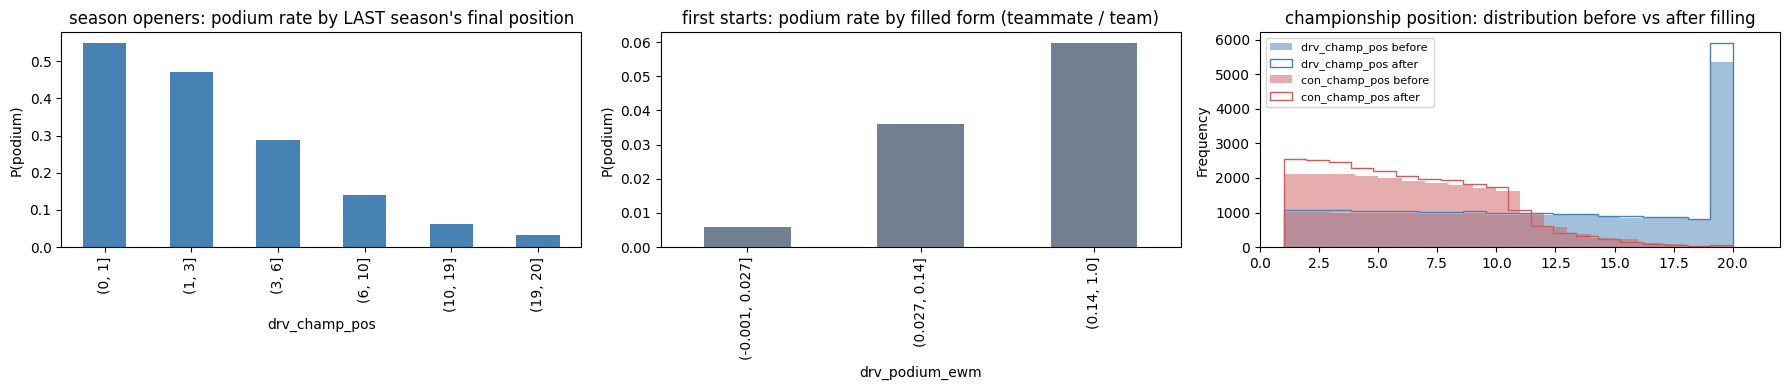

season openers (train): podium rate by last season's final position


,rows,podium_rate
drv_champ_pos,,
"(0, 1]",60,0.550
"(1, 3]",125,0.472
"(3, 6]",177,0.288
"(6, 10]",220,0.141
"(10, 19]",354,0.062
"(19, 20]",559,0.032


Spearman ρ with podium (train), only on rows that WERE missing — does the fill carry signal?


,filled rows,rho on filled rows
drv_champ_pos,1495.0,-0.381
con_champ_pos,2497.0,-0.313
con_points_share,1151.0,0.261
drv_podium_ewm,669.0,0.162
con_podium_ewm,256.0,0.163
drv_circuit_last_finish,7062.0,-0.267
con_mech_dnf_ewm,256.0,0.012


In [169]:
train = base[base["year"] <= TRAIN_END]
was_missing = base_before_fill.loc[train.index]
opener_rows = train[was_missing["drv_champ_pos"].isna()]
debut_rows = train[was_missing["drv_podium_ewm"].isna()]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
opener_rows.groupby(pd.cut(opener_rows["drv_champ_pos"], [0, 1, 3, 6, 10, 19, 20]), observed=True)["podium"].mean().plot(
    kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("season openers: podium rate by LAST season's final position")
debut_rows.groupby(pd.qcut(debut_rows["drv_podium_ewm"], 4, duplicates="drop"), observed=True)["podium"].mean().plot(
    kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("first starts: podium rate by filled form (teammate / team)")
for col, color in [("drv_champ_pos", "steelblue"), ("con_champ_pos", "indianred")]:
    base_before_fill[col].plot(kind="hist", bins=20, ax=axes[2], alpha=0.5, color=color, label=f"{col} before")
    base[col].plot(kind="hist", bins=20, ax=axes[2], histtype="step", lw=2, color=color, label=f"{col} after")
axes[2].set_title("championship position: distribution before vs after filling")
axes[2].legend(fontsize=8)
for ax in axes[:2]:
    ax.set_ylabel("P(podium)")
plt.tight_layout()
plt.show()

print("season openers (train): podium rate by last season's final position")
display(opener_rows.groupby(pd.cut(opener_rows["drv_champ_pos"], [0, 1, 3, 6, 10, 19, 20]), observed=True)["podium"]
        .agg(rows="size", podium_rate="mean").round(3))
print("Spearman ρ with podium (train), only on rows that WERE missing — does the fill carry signal?")
rows = {}
for col in ["drv_champ_pos", "con_champ_pos", "con_points_share", "drv_podium_ewm", "con_podium_ewm",
            "drv_circuit_last_finish", "con_mech_dnf_ewm"]:
    m = was_missing[col].isna()
    rows[col] = {"filled rows": int(m.sum()),
                 "rho on filled rows": train.loc[m, col].corr(train.loc[m, "podium"], method="spearman")}
pd.DataFrame(rows).T.round(3)

**Missing values — findings**
- **Leakage-safe:** 10 races rebuilt with only the data up to that race and their own results scrambled (points, finishing order, status) give identical filled values.
- **What is left:** only `quali_gap_pct` (14,319 rows, 63.7% of train, ~1% of validation/test), imputed by grid band in the pipeline, and 23 rows in the two reliability features: the starters of the very first race in the data (1950 British GP), for which no earlier race exists. That race is excluded from the model table in 4.10, since no history feature can exist there. All 24,586 rows are kept.
- **The fills carry real signal**, measured only on the rows that *were* missing (train):
  - Season openers by **last season's final position:** last year's champion podiums 55.0% at the opener, 2nd–3rd 47.2%, 11th–19th 6.2%, unranked 3.2% (ρ = −0.38, as strong as the in-season position at −0.40). Before, all 1,595 openers had no position.
  - **Rebuilt 1950–57 constructors' standings:** ρ = +0.26 on 1,151 rows that had nothing.
  - **Debut form from teammates / team:** ρ = +0.16. Weaker than real form (a rookie is not their teammate), but a rookie in a strong car does podium more often.
  - **First visit filled with general form:** ρ = −0.27 on 7,062 rows. This also raises the overlap between the circuit and form groups, which the ablation has to keep in mind.
- **Neutral fills on purpose:** the field-average reliability (ρ = 0.01 on filled rows) is the same for every newcomer in a race, so it only completes the table without inventing information. Filling `grid_minus_quali` with 0 lowers its overall ρ from 0.07 to 0.04, because 63% of rows are now 0; `has_quali` keeps them apart.
- **New flag `has_teammate`** (ρ = +0.07): single-car entries are mostly privateers, who rarely podium.

## 4.10 Final model table and split
**Content:** identifiers (`raceId`, `driverId`, `constructorId`, `circuitId`, `year`, `round`, `date`, `era`; **not** features), the 27 features in 8 groups (the ablation groups), the target `podium`, and the `split` label. The first race in the data (1950 British GP, 23 rows) is excluded: with no earlier race, none of the history features can exist there. The post-race columns used to build the history features (`positionOrder`, `status_group`) are not carried over, and an assert checks that no post-race column is in the table.

**Split by season, not at random:**
- **Train 1950–2019, validation 2020–21, test 2022–24.** Each set is later in time than the one before, as in real use: the model is trained on the past and asked about races it has not seen.
- A random split would put rows of the same race (and of the same season) in both train and test. The model would then be tested on seasons it has already seen, which overstates performance.
- **The test set is a new regulation era** (2022 ground-effect cars). Its score is an honest estimate of how the model copes with a rule change.
- **Validation** is used to choose hyperparameters and the decision threshold; the test set is used once, at the end. Limitation: validation has only 39 races (775 rows), so choices tuned on it carry some variance.
- Training on all seasons from 1950 keeps the most data. Training only on seasons with qualifying data (closer to validation/test) is one of the experiments.

In [170]:
FEATURE_GROUPS = {
    "grid": GRID_FEATURES,
    "qualifying": QUALI_FEATURES,
    "standings": STANDINGS_FEATURES,
    "form": FORM_FEATURES,
    "reliability": RELIABILITY_FEATURES,
    "circuit_history": CIRCUIT_FEATURES,
    "driver": DRIVER_FEATURES,
    "context": CONTEXT_FEATURES,
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
KEYS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "era"]   # identifiers, not features
TARGET = "podium"

model_table = base[KEYS + FEATURES + [TARGET]].copy()
# the very first race in the data (1950 British GP) has no earlier race, so no history feature can exist there
first_race = model_table["date"] == model_table["date"].min()
print("excluded: first race in the data,", int(first_race.sum()), "rows")
model_table = model_table[~first_race].reset_index(drop=True)
model_table["split"] = np.select([model_table["year"] <= TRAIN_END, model_table["year"] <= VAL_END],
                                 ["train", "val"], default="test")

# checks: grain, no post-race column, every feature numeric
assert model_table.set_index(["raceId", "driverId"]).index.is_unique
assert len(model_table) == len(base) - first_race.sum() and len(FEATURES) == len(set(FEATURES))
assert model_table[FEATURES].drop(columns="quali_gap_pct").notna().all().all(), "unexpected missing values"
assert not set(HISTORY_ONLY + DROP_NOW) & set(model_table.columns), "post-race column in the model table"
assert all(pd.api.types.is_numeric_dtype(model_table[f]) for f in FEATURES)

print(f"model table: {model_table.shape[0]:,} rows × {len(FEATURES)} features in {len(FEATURE_GROUPS)} groups")
for group, cols in FEATURE_GROUPS.items():
    print(f"  {group:16s} {cols}")
model_table.groupby("split", sort=False).agg(
    rows=(TARGET, "size"), races=("raceId", "nunique"), podium_rate=(TARGET, "mean"),
    first_season=("year", "min"), last_season=("year", "max")).round(3)

excluded: first race in the data, 23 rows
model table: 24,563 rows × 27 features in 8 groups
  grid             ['grid_rank', 'grid_pct', 'field_size', 'front_row', 'is_pit_start']
  qualifying       ['quali_gap_pct', 'grid_minus_quali', 'has_quali']
  standings        ['drv_points_share', 'con_points_share', 'drv_champ_pos', 'con_champ_pos']
  form             ['drv_podium_ewm', 'drv_finish_frac_ewm', 'con_podium_ewm', 'con_finish_frac_ewm']
  reliability      ['con_mech_dnf_ewm', 'drv_incident_ewm']
  circuit_history  ['drv_circuit_visits', 'drv_circuit_last_finish', 'drv_circuit_avg_finish']
  driver           ['drv_starts_before', 'age', 'teammate_grid_gap', 'has_teammate']
  context          ['is_home_race', 'season_progress']


,rows,races,podium_rate,first_season,last_season
split,,,,,
train,22436,1006,0.135,1950,2019
val,775,39,0.151,2020,2021
test,1352,68,0.151,2022,2024


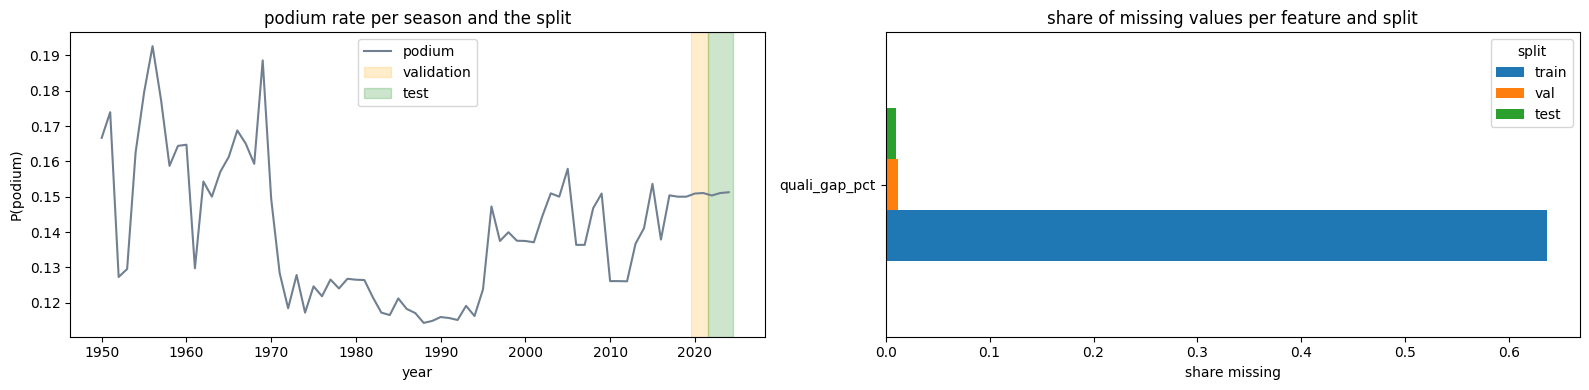

,group,rho_train,missing_train,missing_val,missing_test
grid_rank,grid,-0.455,0.000,0.000,0.00
grid_pct,grid,-0.449,0.000,0.000,0.00
field_size,grid,-0.055,0.000,0.000,0.00
front_row,grid,0.417,0.000,0.000,0.00
is_pit_start,grid,-0.015,0.000,0.000,0.00
quali_gap_pct,qualifying,-0.467,0.636,0.012,0.01
grid_minus_quali,qualifying,0.038,0.000,0.000,0.00
has_quali,qualifying,0.011,0.000,0.000,0.00
drv_points_share,standings,0.362,0.000,0.000,0.00
con_points_share,standings,0.353,0.000,0.000,0.00


In [171]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
model_table.groupby("year")[TARGET].mean().plot(ax=axes[0], color="slategray")
axes[0].axvspan(TRAIN_END + 0.5, VAL_END + 0.5, alpha=0.2, color="orange", label="validation")
axes[0].axvspan(VAL_END + 0.5, model_table["year"].max() + 0.5, alpha=0.2, color="green", label="test")
axes[0].set_title("podium rate per season and the split")
axes[0].set_ylabel("P(podium)")
axes[0].legend()

missing = model_table.groupby("split", sort=False)[FEATURES].apply(lambda g: g.isna().mean()).T
missing[missing.max(axis=1) > 0].plot(kind="barh", ax=axes[1])
axes[1].set_title("share of missing values per feature and split")
axes[1].set_xlabel("share missing")
plt.tight_layout()
plt.show()

# one overview of every feature: group, evidence on train, missingness per split
is_train = model_table["split"] == "train"
overview = pd.DataFrame({
    "group": [g for g, cols in FEATURE_GROUPS.items() for _ in cols],
    "rho_train": [model_table.loc[is_train, f].corr(model_table.loc[is_train, TARGET], method="spearman") for f in FEATURES],
}, index=FEATURES).join(missing.add_prefix("missing_"))
overview.round(3)

**Final table — findings**
- **24,563 rows**, unique on `(raceId, driverId)`, with **27 numeric features** in 8 groups and no post-race column (all checked by asserts).
- **Split:** train 22,436 rows / 1,006 races (1950–2019), validation 775 / 39 (2020–21), test 1,352 / 68 (2022–24). The podium rate is 13.5% in train and 15.1% in validation and test: modern fields are smaller (about 20 cars), so each car has a higher base rate. PR-AUC is compared against this base rate in each split.
- **Missing values (after 4.9):** only `quali_gap_pct` is still missing: 63.7% of training rows but about 1% of validation/test, because qualifying data only exists from 1994. It is imputed in the pipeline by grid band (4.2), fitted on train only. The first race in the data (1950 British GP, 23 rows) is excluded because no earlier race exists. Every other gap was filled with pre-race information in 4.9.
- **Strongest single features (train):** qualifying gap (ρ = −0.47), grid rank (−0.46), driver form (+0.43), front row (+0.42), team form (+0.40), championship position (−0.40). **Weakest:** pit-lane start, has-quali, home race, season progress (|ρ| ≤ 0.02 on their own). Some of these work through other features (e.g. season progress via the standings); the ablation measures each group's real contribution.

In [172]:
model_table.to_csv(CLEAN_DIR / "model_table.csv", index=False)
print("saved:", CLEAN_DIR / "model_table.csv", model_table.shape)

saved: /kaggle/working/cleaned/model_table.csv (24563, 37)


# 5. Preprocessing
Different models need different inputs:
- **Every model** needs complete rows. After 4.9 only `quali_gap_pct` is still missing; it is imputed by grid band. A generic median imputer follows as a safety net, so a partially-missing record (e.g. at inference) never breaks the pipeline.
- **Logistic regression and the neural network** need comparable scales: a penalty or a gradient step treats a feature in the hundreds (`drv_starts_before`) very differently from one between 0 and 1. They get a log transform of the two count features and standard scaling.
- **Tree models** split on the order of values, so scaling changes nothing for them. They only get the imputation.

Everything is a scikit-learn `Pipeline` **fitted on the training rows only** and then applied unchanged to validation, test and the inference function. Section 5.3 tests why the order and the rows used for fitting matter.

In [173]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SPLITS = {name: model_table[model_table["split"] == name] for name in ["train", "val", "test"]}
X = {name: df[FEATURES] for name, df in SPLITS.items()}
y = {name: df[TARGET] for name, df in SPLITS.items()}

pd.DataFrame({name: {"rows": len(X[name]), "podium rate": y[name].mean(),
                     "rows with a missing value": int(X[name].isna().any(axis=1).sum())}
              for name in X}).T.round(3)

,rows,podium rate,rows with a missing value
train,22436.0,0.135,14274.0
val,775.0,0.151,9.0
test,1352.0,0.151,13.0


## 5.1 Imputing the qualifying gap
`GridBandImputer` fills a missing `quali_gap_pct` with the median gap of starters from the same grid band, learned in `fit()` (evidence for grid-aware imputation in 4.2). Inside a `Pipeline`, `fit()` only ever sees the training rows.

median qualifying gap per grid band, learned on the training rows:


grid_rank
(0.0, 1.0]      0.000
(1.0, 3.0]      0.370
(3.0, 6.0]      0.932
(6.0, 10.0]     1.582
(10.0, 15.0]    2.414
(15.0, inf]     4.109
Name: median gap (%), dtype: float64

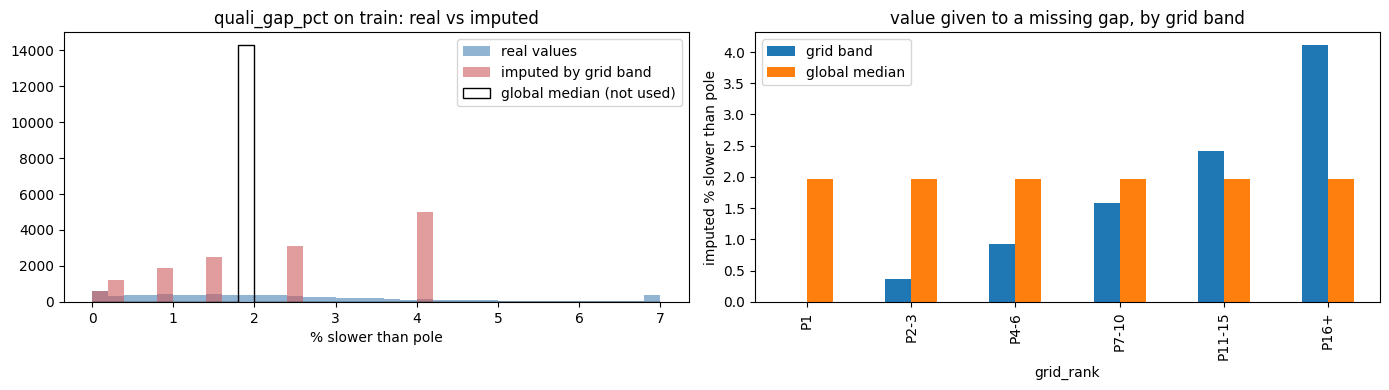

Spearman ρ of quali_gap_pct with podium (train):


real values only                 -0.467
after grid-band imputation       -0.442
after global-median imputation   -0.244
dtype: float64

In [174]:
class GridBandImputer(BaseEstimator, TransformerMixin):
    """Fill missing qualifying gaps with the median gap of starters from the same grid band (evidence in 3.2).

    The band medians are learned in fit(), so inside a Pipeline they come from the training rows only.
    """

    def __init__(self, col="quali_gap_pct", by="grid_rank", bands=(0, 1, 3, 6, 10, 15, np.inf)):
        self.col = col
        self.by = by
        self.bands = bands

    def fit(self, X, y=None):
        band = pd.cut(X[self.by], self.bands)
        self.band_median_ = X.groupby(band, observed=True)[self.col].median()
        self.fallback_ = X[self.col].median()   # for a band with no observed gap
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        band = pd.cut(X[self.by], self.bands)
        fill = band.map(self.band_median_.to_dict()).astype(float).fillna(self.fallback_)
        X[self.col] = X[self.col].fillna(fill)
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


gap_imputer = GridBandImputer().fit(X["train"])
print("median qualifying gap per grid band, learned on the training rows:")
display(gap_imputer.band_median_.round(3).rename("median gap (%)"))

was_missing = X["train"]["quali_gap_pct"].isna()
imputed = gap_imputer.transform(X["train"])["quali_gap_pct"]
global_fill = X["train"]["quali_gap_pct"].fillna(X["train"]["quali_gap_pct"].median())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.linspace(0, 7, 36)
axes[0].hist(X["train"].loc[~was_missing, "quali_gap_pct"], bins=bins, alpha=0.6, label="real values", color="steelblue")
axes[0].hist(imputed[was_missing], bins=bins, alpha=0.6, label="imputed by grid band", color="indianred")
axes[0].hist(global_fill[was_missing], bins=bins, histtype="step", lw=2, color="black", label="global median (not used)")
axes[0].set_title("quali_gap_pct on train: real vs imputed")
axes[0].set_xlabel("% slower than pole")
axes[0].legend()
pd.DataFrame({"grid band": imputed, "global median": global_fill}).loc[was_missing].groupby(
    pd.cut(X["train"].loc[was_missing, "grid_rank"], GRID_BANDS, labels=GRID_BAND_LABELS), observed=True).mean().plot(
    kind="bar", ax=axes[1])
axes[1].set_title("value given to a missing gap, by grid band")
axes[1].set_ylabel("imputed % slower than pole")
plt.tight_layout()
plt.show()

print("Spearman ρ of quali_gap_pct with podium (train):")
pd.Series({"real values only": X["train"]["quali_gap_pct"].corr(y["train"], method="spearman"),
           "after grid-band imputation": imputed.corr(y["train"], method="spearman"),
           "after global-median imputation": global_fill.corr(y["train"], method="spearman")}).round(3)

## 5.2 Log transform and scaling (for logistic regression and the neural network)
- `drv_starts_before` and `drv_circuit_visits` are counts with long right tails (a few drivers have 300+ starts). `log1p` compresses the tail so one veteran does not dominate a coefficient.
- `StandardScaler` puts every feature at mean 0 and standard deviation 1 **on the training rows**. Binary flags are scaled too: it does not change what they mean, and it keeps every input on the same scale for the penalty and the network.

In [175]:
LOG_FEATURES = ["drv_starts_before", "drv_circuit_visits"]   # long right tails (counts)


def make_preprocessor(scale=True):
    """Imputation for every model; log + standard scaling only for the scale-sensitive ones (LR, NN)."""
    steps = [("quali_gap", GridBandImputer()),                 # grid-aware fill for the one feature with no pre-race substitute
             ("median", SimpleImputer(strategy="median"))]      # safety net, e.g. a partially-missing record at inference
    if scale:
        steps += [("log", ColumnTransformer([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), LOG_FEATURES)],
                                            remainder="passthrough", verbose_feature_names_out=False)),
                  ("scale", StandardScaler())]
    return Pipeline(steps).set_output(transform="pandas")


prep_scaled = make_preprocessor(scale=True).fit(X["train"])   # fitted on the training rows only
Xs = {name: prep_scaled.transform(X[name])[FEATURES] for name in X}

assert all(not Xs[name].isna().any().any() for name in Xs)
print("skewness before → after log1p (train):",
      {c: (round(X["train"][c].skew(), 2), round(np.log1p(X["train"][c]).skew(), 2)) for c in LOG_FEATURES})

# after scaling: mean 0 / sd 1 on train by construction; validation and test keep their own shift
summary = pd.concat({name: Xs[name].agg(["mean", "std"]).T for name in Xs}, axis=1)
summary.round(2).loc[["grid_rank", "quali_gap_pct", "drv_points_share", "drv_podium_ewm", "drv_starts_before",
                      "con_mech_dnf_ewm", "season_progress"]]

skewness before → after log1p (train): {'drv_starts_before': (np.float64(1.42), np.float64(-0.74)), 'drv_circuit_visits': (np.float64(1.65), np.float64(0.28))}


train        val        test      
                   mean  std  mean   std  mean   std
grid_rank           0.0  1.0 -0.21  0.84 -0.21  0.84
quali_gap_pct      -0.0  1.0 -0.27  0.91 -0.41  0.95
drv_points_share   -0.0  1.0  0.19  1.02  0.18  1.04
drv_podium_ewm      0.0  1.0  0.07  1.20  0.08  1.13
drv_starts_before   0.0  1.0  0.65  0.84  0.86  0.78
con_mech_dnf_ewm    0.0  1.0 -1.17  0.40 -1.25  0.30
season_progress     0.0  1.0 -0.05  1.00 -0.07  1.00

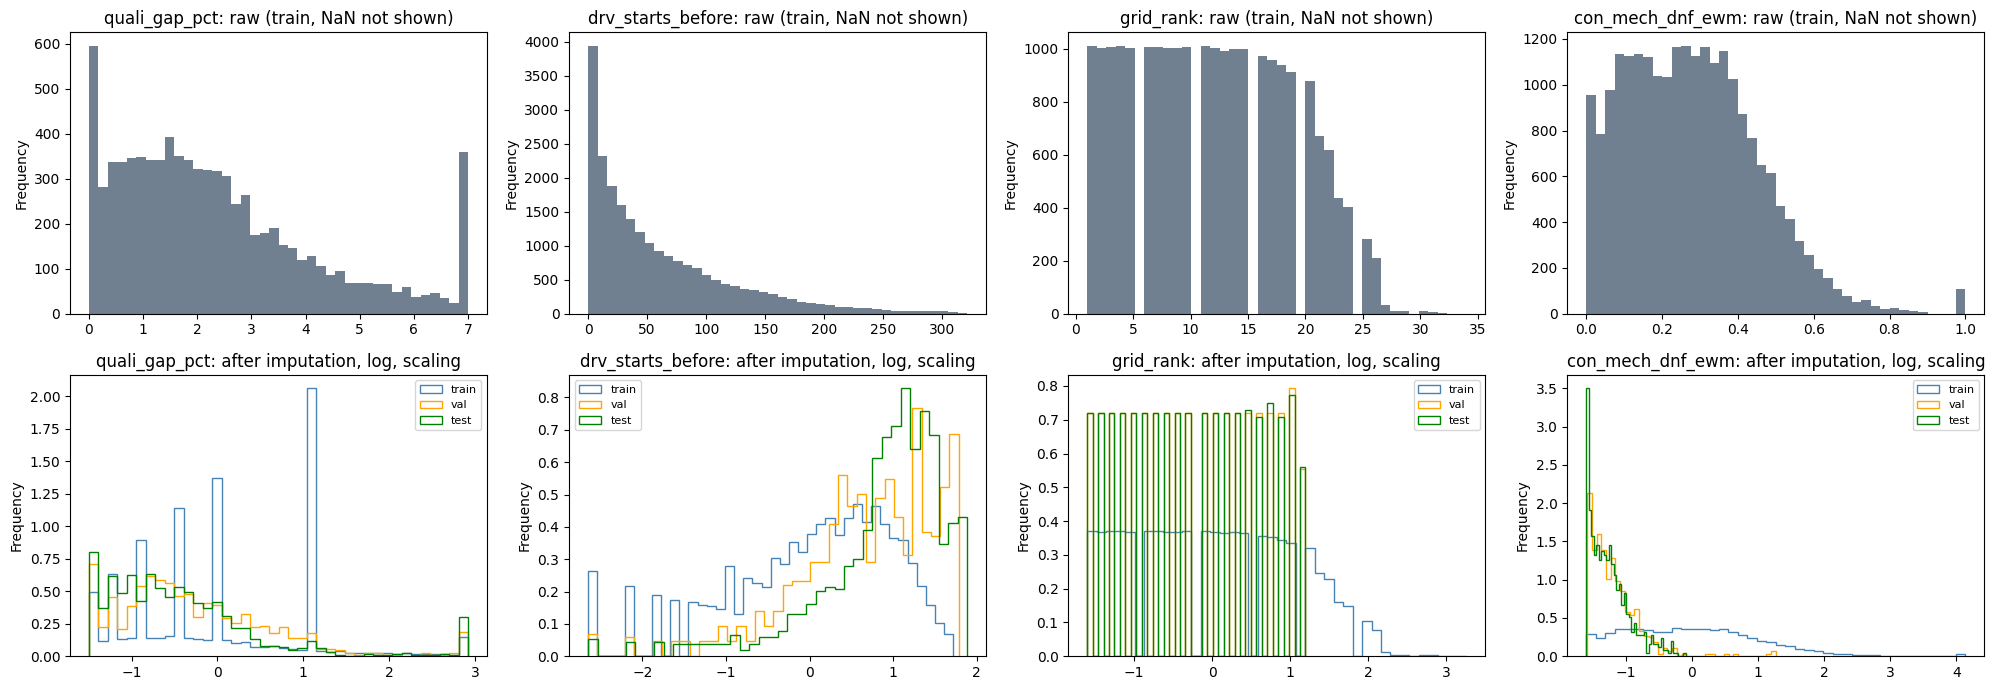

In [176]:
show_cols = ["quali_gap_pct", "drv_starts_before", "grid_rank", "con_mech_dnf_ewm"]
fig, axes = plt.subplots(2, len(show_cols), figsize=(20, 7))
for j, col in enumerate(show_cols):
    X["train"][col].plot(kind="hist", bins=40, ax=axes[0, j], color="slategray")
    axes[0, j].set_title(f"{col}: raw (train, NaN not shown)")
    for name, color in [("train", "steelblue"), ("val", "orange"), ("test", "green")]:
        Xs[name][col].plot(kind="hist", bins=40, ax=axes[1, j], density=True, histtype="step", lw=1.8, color=color, label=name)
    axes[1, j].set_title(f"{col}: after imputation, log, scaling")
    axes[1, j].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5.3 Preprocessing-order experiments
Two experiments on *how* the preprocessing is applied, with everything else fixed: the same 27 features, a plain logistic regression trained on the training rows as a probe, and the score on validation (the test set is not touched).
1. **Which rows the preprocessing is fitted on:** training rows only (correct) vs all rows before splitting (leaky: the imputers and scaler see validation and test).
2. **Order of the two imputers:** grid-band first, then median (used) vs median first, then grid-band.

Validation has only 39 races, so each difference comes with a 95% interval from a **race-level bootstrap** (whole races are resampled, because the rows of one race are not independent). If the interval contains 0, the difference is not distinguishable from noise.

what the preprocessing learns, depending on which rows it is fitted on:


,fit on train,fit on all rows
gap imputed for P16+ (%),4.109,3.844
scaler mean of drv_podium_ewm,0.135,0.137
scaler mean of con_mech_dnf_ewm,0.279,0.260


ρ of the imputed qualifying gap with podium (train): {'grid band first': np.float64(-0.442), 'median first': np.float64(-0.244)}


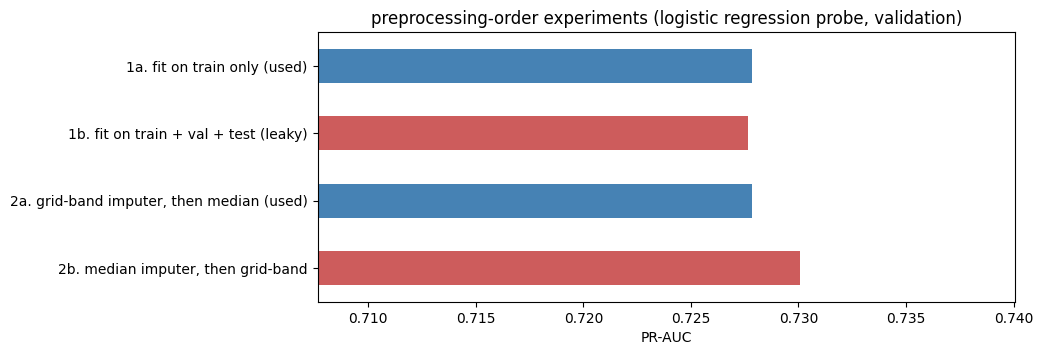

,val PR-AUC,val ROC-AUC,95% CI of difference vs used
1a. fit on train only (used),0.7278,0.9298,—
1b. fit on train + val + test (leaky),0.7276,0.9297,[-0.0024 0.0018]
"2a. grid-band imputer, then median (used)",0.7278,0.9298,—
"2b. median imputer, then grid-band",0.7301,0.9311,[-0.0041 0.0074]


In [177]:
def race_bootstrap_diff(y_true, p_a, p_b, races, n=500, seed=0):
    """95% interval of PR-AUC(a) - PR-AUC(b), resampling whole races (rows of one race are not independent)."""
    rng = np.random.default_rng(seed)
    y_true, races = np.asarray(y_true), np.asarray(races)
    rows_of = {r: np.flatnonzero(races == r) for r in np.unique(races)}
    diffs = []
    for _ in range(n):
        idx = np.concatenate([rows_of[r] for r in rng.choice(list(rows_of), size=len(rows_of))])
        diffs.append(average_precision_score(y_true[idx], p_a[idx]) - average_precision_score(y_true[idx], p_b[idx]))
    return np.percentile(diffs, [2.5, 97.5])


def probe(preprocessor, fit_rows="train"):
    """Fit a preprocessor (on `fit_rows`), train a plain logistic regression on the training rows,
    return its validation probabilities."""
    fit_X = X["train"] if fit_rows == "train" else pd.concat([X["train"], X["val"], X["test"]])
    preprocessor.fit(fit_X)
    model = LogisticRegression(max_iter=2000).fit(preprocessor.transform(X["train"]), y["train"])
    return model.predict_proba(preprocessor.transform(X["val"]))[:, 1]


def log_then_scale():
    return [("log", ColumnTransformer([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), LOG_FEATURES)],
                                      remainder="passthrough", verbose_feature_names_out=False)),
            ("scale", StandardScaler())]


# Experiment 1: fit the imputers and scaler on the training rows only (correct) vs on all rows before splitting (leaky)
correct, leaky = make_preprocessor(), make_preprocessor()
p_val = {"1a. fit on train only (used)": probe(correct, "train"),
         "1b. fit on train + val + test (leaky)": probe(leaky, "all")}
scale_idx = {c: i for i, c in enumerate(correct.named_steps["scale"].feature_names_in_)}
learned = pd.DataFrame({
    label: [pre.named_steps["quali_gap"].band_median_.iloc[-1],
            pre.named_steps["scale"].mean_[scale_idx["drv_podium_ewm"]],
            pre.named_steps["scale"].mean_[scale_idx["con_mech_dnf_ewm"]]]
    for label, pre in [("fit on train", correct), ("fit on all rows", leaky)]
}, index=["gap imputed for P16+ (%)", "scaler mean of drv_podium_ewm", "scaler mean of con_mech_dnf_ewm"])
print("what the preprocessing learns, depending on which rows it is fitted on:")
display(learned.round(3))

# Experiment 2: order of the two imputers. Generic median first fills every gap with one global value,
# so the grid-band imputer that follows has nothing left to do.
median_first = Pipeline([("median", SimpleImputer(strategy="median")), ("quali_gap", GridBandImputer())]
                        + log_then_scale()).set_output(transform="pandas")
p_val["2a. grid-band imputer, then median (used)"] = p_val["1a. fit on train only (used)"]
p_val["2b. median imputer, then grid-band"] = probe(median_first, "train")
gap_after = {"grid band first": correct[:2].transform(X["train"])["quali_gap_pct"],
             "median first": median_first[:2].transform(X["train"])["quali_gap_pct"]}
print("ρ of the imputed qualifying gap with podium (train):",
      {k: round(v.corr(y["train"], method="spearman"), 3) for k, v in gap_after.items()})

order_table = pd.DataFrame({name: {"val PR-AUC": average_precision_score(y["val"], p), "val ROC-AUC": roc_auc_score(y["val"], p)}
                            for name, p in p_val.items()}).T
races_val = SPLITS["val"]["raceId"]
order_table["95% CI of difference vs used"] = [
    "—" if "used" in name else str(np.round(race_bootstrap_diff(y["val"], p, p_val["1a. fit on train only (used)"], races_val), 4))
    for name, p in p_val.items()]

order_table["val PR-AUC"].plot(kind="barh", figsize=(9, 3.5), color=["steelblue", "indianred", "steelblue", "indianred"],
                               xlim=(order_table["val PR-AUC"].min() - 0.02, order_table["val PR-AUC"].max() + 0.01))
plt.title("preprocessing-order experiments (logistic regression probe, validation)")
plt.xlabel("PR-AUC")
plt.gca().invert_yaxis()
plt.show()
order_table.round(4)

**Preprocessing — findings**
- **Complete rows:** 14,274 training rows (63.6%), 9 validation and 13 test rows have a missing qualifying gap. After the pipeline no value is missing.
- **Grid-band imputation keeps the feature meaningful:** imputed gaps follow the grid (P1 0.00%, P7–10 1.58%, P16+ 4.11%), and the gap's correlation with podium stays at ρ = −0.44, vs −0.24 with one global median.
- **Log transform:** skewness of `drv_starts_before` 1.42 → −0.74, of `drv_circuit_visits` 1.65 → 0.28.
- **Scaling is fitted on train, so validation and test show the era shift:** in the scaled units, modern cars are far more reliable (`con_mech_dnf_ewm` mean −1.17 / −1.25), drivers are more experienced (`drv_starts_before` +0.65 / +0.86) and qualifying gaps are smaller (−0.27 / −0.41). This shift is exactly what the season split is meant to test.
- **Experiment 1 (fit on train vs all rows):** fitting on all rows changes what the preprocessing learns (the gap imputed for P16+ goes from 4.11% to 3.84%, the reliability mean from 0.279 to 0.260), but the validation score barely moves (PR-AUC 0.7276 vs 0.7272, 95% interval of the difference [−0.002, +0.001]). The training rows are 91% of the data, so adding validation and test hardly shifts the statistics. Fitting on train only is still the only valid procedure: leaky statistics would let information about the held-out seasons into the model, and the effect would be larger with a smaller training set or a stronger shift.
- **Experiment 2 (imputer order):** the order changes the data. With the median first, every missing gap gets 1.96%, and ρ falls from −0.44 to −0.24. But the score does not change significantly (PR-AUC 0.7286 vs 0.7276, interval [−0.005, +0.007]). Validation and test have real gaps for about 99% of rows, so the imputation only affects training rows, and `has_quali` lets the model treat imputed rows separately. We keep **grid band first**: it is no worse, and it gives sensible values where they matter, for a partially-missing record at inference and in the explanations (a pole-sitter without a qualifying time gets 0%, not a midfield 1.96%).
- **Noise level for later comparisons:** on 39 validation races, PR-AUC differences of a few thousandths are within the bootstrap noise. Model comparisons in section 6 are read with this in mind.
- **Reference point:** even this untuned probe reaches validation PR-AUC 0.73 (base rate 0.151) and ROC-AUC 0.93.


# 6. Models
Every model is trained on the **same rows and the same 27 features** (the training seasons), so their scores are directly comparable.

**Metrics (all reported on train, validation and test):**
- **PR-AUC: primary.** Only 13.5–15.1% of rows are podiums. PR-AUC measures how well the model ranks real podium finishers above the rest, and a random model scores the base rate (0.151 on validation/test), not 0.5. It is the metric hyperparameters are chosen on.
- **ROC-AUC: secondary.** The usual ranking measure; with a rare positive class it looks good easily (0.9+), so it is reported but not used for decisions.
- **F1, precision, recall** at one probability threshold, chosen **on validation** to maximise F1 and then applied unchanged to test.
- **Top-3 hit rate** (extra, not in the brief): in each race, take the 3 drivers with the highest probability as the predicted podium, and count how many of the real podium finishers they contain. It is how a fan would judge a podium prediction.

**Rules:** hyperparameters and thresholds are chosen on the validation seasons only. The test seasons (2022–24) are scored once per model and never used for a choice. A race-level bootstrap (5.3) tells whether a difference is larger than the noise of 39 validation / 68 test races.

## 6.1 Evaluation helpers
`tune()` fits one pipeline (preprocessing from section 5 + model) per hyperparameter setting on the training rows and keeps the best validation PR-AUC. `register()` picks the F1 threshold on validation and evaluates every split.

In [178]:
import time

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import f1_score, precision_recall_curve, precision_score, recall_score, roc_curve
from sklearn.neural_network import MLPClassifier

RACES = {name: SPLITS[name]["raceId"].to_numpy() for name in SPLITS}


def top3_hit_rate(y_true, p, races):
    """Share of real podium finishers that are among the 3 highest probabilities of their race."""
    df = pd.DataFrame({"y": np.asarray(y_true), "p": p, "race": races})
    df["rank"] = df.groupby("race")["p"].rank(ascending=False, method="first")
    return df.loc[df["rank"] <= 3, "y"].sum() / df["y"].sum()


def best_f1_threshold(y_true, p):
    """Probability threshold that maximises F1 (chosen on validation only)."""
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return thr[np.nanargmax(f1[:-1])]


def evaluate(name, model, threshold):
    rows = []
    for split in ["train", "val", "test"]:
        p = model.predict_proba(X[split])[:, 1]
        pred = (p >= threshold).astype(int)
        rows.append({"model": name, "split": split,
                     "ROC-AUC": roc_auc_score(y[split], p), "PR-AUC": average_precision_score(y[split], p),
                     "F1": f1_score(y[split], pred), "precision": precision_score(y[split], pred, zero_division=0),
                     "recall": recall_score(y[split], pred), "top-3 hit rate": top3_hit_rate(y[split], p, RACES[split]),
                     "threshold": threshold})
    return pd.DataFrame(rows)


def tune(make_model, grid, scale):
    """Fit one pipeline per hyperparameter setting on the training rows, keep the best validation PR-AUC."""
    trials, best = [], None
    for params in grid:
        start = time.time()
        pipe = Pipeline([("prep", make_preprocessor(scale=scale)), ("model", make_model(**params))]).fit(X["train"], y["train"])
        p_val = pipe.predict_proba(X["val"])[:, 1]
        trials.append({**{k: str(v) for k, v in params.items()},
                       "train PR-AUC": average_precision_score(y["train"], pipe.predict_proba(X["train"])[:, 1]),
                       "val PR-AUC": average_precision_score(y["val"], p_val), "seconds": time.time() - start})
        if best is None or trials[-1]["val PR-AUC"] > best[0]:
            best = (trials[-1]["val PR-AUC"], pipe, params)
    return best[1], best[2], pd.DataFrame(trials).round(4)


MODELS, RESULTS, VAL_PROBA = {}, [], {}


def register(name, model):
    """Store a fitted model, choose its F1 threshold on validation and evaluate it on every split."""
    VAL_PROBA[name] = model.predict_proba(X["val"])[:, 1]
    threshold = best_f1_threshold(y["val"], VAL_PROBA[name])
    MODELS[name] = (model, threshold)
    RESULTS.append(evaluate(name, model, threshold))
    return RESULTS[-1].set_index("split").drop(columns="model").round(3)


print("base rate (PR-AUC of random guessing):", {s: round(y[s].mean(), 3) for s in y})

base rate (PR-AUC of random guessing): {'train': np.float64(0.135), 'val': np.float64(0.151), 'test': np.float64(0.151)}


## 6.2 Reference rule and baseline
- **Grid rule (reference, not a model):** the probability of a podium is the podium rate of the starting slot in the training seasons. It shows how much is possible from the grid alone.
- **Baseline: logistic regression with default settings on all 27 features.** It is the simplest reasonable model. It computes a weighted sum of the (scaled) features and turns it into a probability with the logistic function; each weight says how much a feature pushes the log-odds of a podium up or down. **Limitations:** every feature acts additively and in one direction, so interactions (e.g. a penalty *combined with* a back-of-grid start, 4.2) and thresholds are not captured unless built in by hand; correlated features (grid rank and grid share) split their weight unpredictably.

In [179]:
# reference rule (not a model): P(podium) = podium rate of the grid slot in the training seasons
class GridRule:
    def fit(self, X, y):
        self.rate_ = y.groupby(X["grid_rank"].clip(upper=25)).mean()
        return self

    def predict_proba(self, X):
        p = X["grid_rank"].clip(upper=25).map(self.rate_).fillna(0).to_numpy()
        return np.column_stack([1 - p, p])


display(register("grid rule (reference)", GridRule().fit(X["train"], y["train"])))

# baseline: logistic regression with default settings on all 27 features
baseline = Pipeline([("prep", make_preprocessor(scale=True)), ("model", LogisticRegression(max_iter=2000))]).fit(X["train"], y["train"])
register("logistic regression (baseline)", baseline)

,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate,threshold
split,,,,,,,
train,0.884,0.500,0.544,0.546,0.543,0.543,0.459
val,0.912,0.649,0.701,0.701,0.701,0.701,0.459
test,0.914,0.647,0.652,0.652,0.652,0.652,0.459


,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate,threshold
split,,,,,,,
train,0.903,0.574,0.590,0.493,0.735,0.556,0.251
val,0.930,0.728,0.716,0.657,0.786,0.701,0.251
test,0.937,0.711,0.664,0.544,0.853,0.652,0.251


## 6.3 Logistic regression, tuned
Two hyperparameters: `C` (inverse strength of the L2 penalty that shrinks the weights) and `class_weight` (`balanced` weighs the rare podium rows up in training).

,C,class_weight,max_iter,train PR-AUC,val PR-AUC,seconds
0,0.01,None,2000,0.5743,0.7238,0.3657
1,0.01,balanced,2000,0.5692,0.7242,0.3427
2,0.1,None,2000,0.5743,0.7244,0.5230
3,0.1,balanced,2000,0.5692,0.7250,0.6648
4,1,None,2000,0.5744,0.7278,0.7219
5,1,balanced,2000,0.5693,0.7252,0.6017
6,10,None,2000,0.5745,0.7280,0.7473
7,10,balanced,2000,0.5693,0.7246,0.6384


chosen: {'C': 10, 'class_weight': None, 'max_iter': 2000}


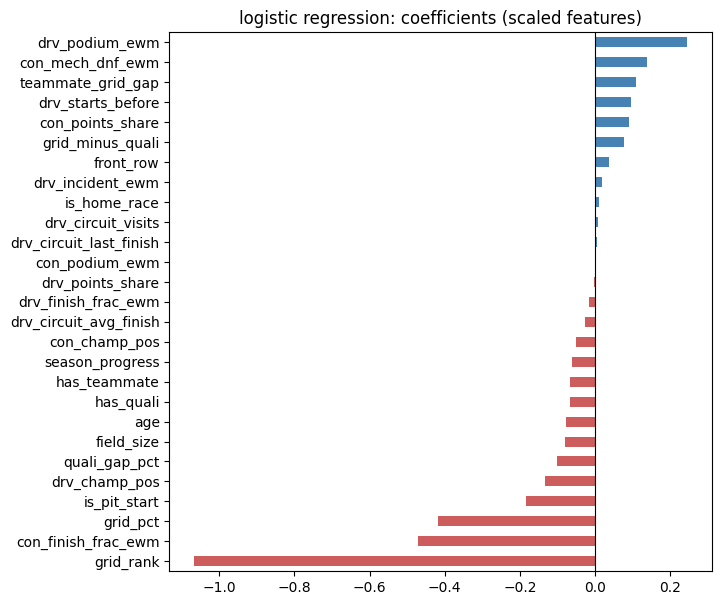

,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate,threshold
split,,,,,,,
train,0.903,0.574,0.590,0.493,0.735,0.556,0.251
val,0.930,0.728,0.719,0.662,0.786,0.701,0.251
test,0.937,0.711,0.665,0.545,0.853,0.652,0.251


In [180]:
lr_grid = [{"C": c, "class_weight": cw, "max_iter": 2000} for c in [0.01, 0.1, 1, 10] for cw in [None, "balanced"]]
lr_best, lr_params, lr_trials = tune(LogisticRegression, lr_grid, scale=True)
display(lr_trials)
print("chosen:", lr_params)

coefs = pd.Series(lr_best.named_steps["model"].coef_[0], index=lr_best.named_steps["prep"].get_feature_names_out())
coefs.sort_values().plot(kind="barh", figsize=(7, 7), color=np.where(coefs.sort_values() > 0, "steelblue", "indianred"))
plt.title("logistic regression: coefficients (scaled features)")
plt.axvline(0, color="black", lw=0.8)
plt.show()
register("logistic regression (tuned)", lr_best)

## 6.4 Random forest
**How it works:** 300 decision trees, each trained on a bootstrap sample of the rows and choosing each split from a random subset of features; the probability is the average vote of the trees. Trees capture interactions and thresholds by themselves and need no scaling. **Limitations:** deep trees memorise the training rows (overfitting), probabilities are averaged votes rather than calibrated estimates, and trees cannot extrapolate beyond values seen in training (relevant for the modern, more reliable cars, 5.2). Tuned: `min_samples_leaf` (larger = smoother trees) and `max_features`.

In [181]:
rf_grid = [{"n_estimators": 300, "min_samples_leaf": leaf, "max_features": mf, "n_jobs": -1, "random_state": 0}
           for leaf in [5, 20, 50, 100, 200] for mf in ["sqrt", 0.5]]
rf_best, rf_params, rf_trials = tune(RandomForestClassifier, rf_grid, scale=False)
display(rf_trials)
print("chosen:", rf_params)
register("random forest", rf_best)

,n_estimators,min_samples_leaf,max_features,n_jobs,random_state,train PR-AUC,val PR-AUC,seconds
0,300,5,sqrt,-1,0,0.9342,0.6948,7.5983
1,300,5,0.5,-1,0,0.9570,0.6726,17.5981
2,300,20,sqrt,-1,0,0.7286,0.7168,6.5117
3,300,20,0.5,-1,0,0.7600,0.7034,14.4356
4,300,50,sqrt,-1,0,0.6467,0.7204,5.4145
5,300,50,0.5,-1,0,0.6623,0.7114,12.2934
6,300,100,sqrt,-1,0,0.6162,0.7262,5.0492
7,300,100,0.5,-1,0,0.6238,0.7210,10.9445
8,300,200,sqrt,-1,0,0.5999,0.7257,4.2930
9,300,200,0.5,-1,0,0.6038,0.7219,9.5985


chosen: {'n_estimators': 300, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'n_jobs': -1, 'random_state': 0}


,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate,threshold
split,,,,,,,
train,0.916,0.616,0.597,0.489,0.765,0.572,0.247
val,0.934,0.726,0.720,0.653,0.803,0.684,0.247
test,0.939,0.720,0.665,0.534,0.882,0.652,0.247


## 6.5 Gradient boosting
**How it works:** trees are built one after another, each one correcting the errors of the trees so far, with a small learning rate (`HistGradientBoostingClassifier`, which bins features into histograms for speed). **Limitations:** the most flexible model here and the easiest to overfit (a first grid with 15–31 leaves per tree reached train PR-AUC 0.85–0.97 with no gain on validation), sensitive to its hyperparameters, and like every tree model it cannot extrapolate. Tuned: tree size (`max_leaf_nodes`), `min_samples_leaf` and the number of trees. The curve shows PR-AUC as trees are added. We keep 300 trees from the hyperparameter grid even though the staged validation curve peaks earlier (about 0.735 at 25 trees vs 0.720 at 300): picking 25 from the curve would tune on validation a second time, and the gap is within the race-bootstrap noise.


,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter,l2_regularization,early_stopping,random_state,train PR-AUC,val PR-AUC,seconds
0,0.05,7,20,100,1.0,False,0,0.6071,0.7054,0.4714
1,0.05,7,20,300,1.0,False,0,0.6529,0.7261,0.9906
2,0.05,7,50,100,1.0,False,0,0.6083,0.7116,0.4833
3,0.05,7,50,300,1.0,False,0,0.6509,0.7171,1.0335
4,0.05,7,200,100,1.0,False,0,0.6063,0.7106,0.4489
5,0.05,7,200,300,1.0,False,0,0.6429,0.7053,1.0437
6,0.05,15,20,100,1.0,False,0,0.6423,0.7066,0.5947
7,0.05,15,20,300,1.0,False,0,0.7395,0.7018,1.3434
8,0.05,15,50,100,1.0,False,0,0.6392,0.7047,0.5920
9,0.05,15,50,300,1.0,False,0,0.7331,0.7044,1.3522


chosen: {'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'max_iter': 300, 'l2_regularization': 1.0, 'early_stopping': False, 'random_state': 0}


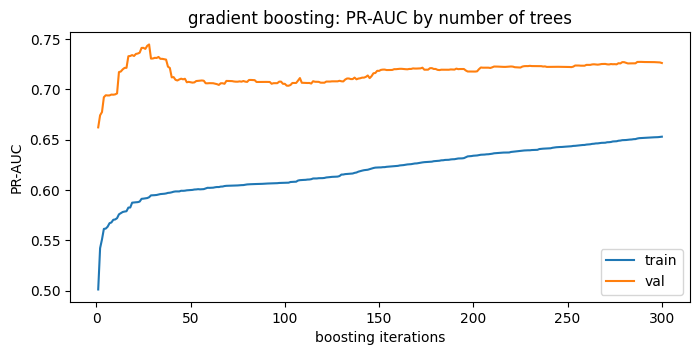

validation PR-AUC after {5: np.float64(0.694), 25: np.float64(0.741), 50: np.float64(0.707), 100: np.float64(0.705), 300: np.float64(0.726)} trees


,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate,threshold
split,,,,,,,
train,0.925,0.653,0.609,0.482,0.826,0.602,0.21
val,0.933,0.726,0.712,0.639,0.803,0.684,0.21
test,0.938,0.714,0.634,0.512,0.833,0.637,0.21


In [182]:
hgb_grid = [{"learning_rate": 0.05, "max_leaf_nodes": leaves, "min_samples_leaf": leaf, "max_iter": it,
             "l2_regularization": 1.0, "early_stopping": False, "random_state": 0}
            for leaves in [7, 15, 31] for leaf in [20, 50, 200] for it in [100, 300]]
hgb_best, hgb_params, hgb_trials = tune(HistGradientBoostingClassifier, hgb_grid, scale=False)
display(hgb_trials)
print("chosen:", hgb_params)

# training curve: PR-AUC after each boosting iteration, on train and validation
prep_t, hgb = hgb_best.named_steps["prep"], hgb_best.named_steps["model"]
curve = pd.DataFrame({split: [average_precision_score(y[split], p[:, 1])
                              for p in hgb.staged_predict_proba(prep_t.transform(X[split]))] for split in ["train", "val"]})
curve.index += 1
curve.plot(figsize=(8, 3.5), title="gradient boosting: PR-AUC by number of trees")
plt.xlabel("boosting iterations")
plt.ylabel("PR-AUC")
plt.show()
print("validation PR-AUC after", {i: round(curve["val"].iloc[i - 1], 3) for i in [5, 25, 50, 100, len(curve)]}, "trees")
register("gradient boosting", hgb_best)

## 6.6 Shallow neural network
**How it works:** a feed-forward network (scikit-learn `MLPClassifier`) with one or two hidden layers of ReLU units and a logistic output, trained with Adam on log-loss. `alpha` is an L2 penalty on the weights. Training stops when accuracy on a held-out 10% of the training rows stops improving for 15 epochs (early stopping). The same preprocessing as logistic regression (imputation, log, scaling) is used. **Limitations:** needs scaled inputs, has many more parameters than the data really supports here, the result depends on the random initialisation, and its weights cannot be read directly (it needs XAI, section 8).

,hidden_layer_sizes,alpha,learning_rate_init,max_iter,early_stopping,validation_fraction,n_iter_no_change,random_state,train PR-AUC,val PR-AUC,seconds
0,"(32,)",0.0001,0.001,300,True,0.1,15,0,0.5739,0.7202,1.9960
1,"(32,)",0.01,0.001,300,True,0.1,15,0,0.5739,0.7204,1.9058
2,"(64, 32)",0.0001,0.001,300,True,0.1,15,0,0.6161,0.6752,4.4350
3,"(64, 32)",0.01,0.001,300,True,0.1,15,0,0.5903,0.7011,2.9971


chosen: {'hidden_layer_sizes': (32,), 'alpha': 0.01, 'learning_rate_init': 0.001, 'max_iter': 300, 'early_stopping': True, 'validation_fraction': 0.1, 'n_iter_no_change': 15, 'random_state': 0}


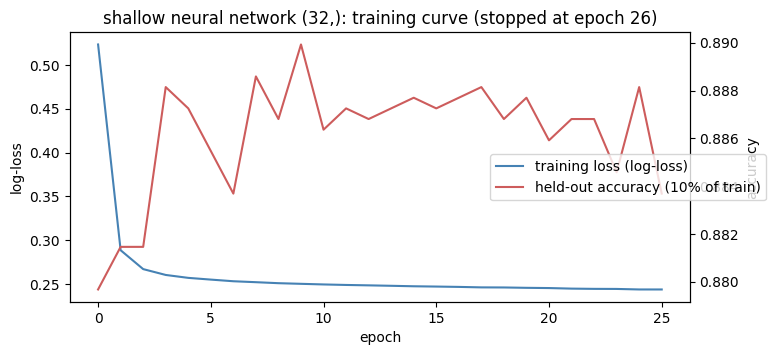

,ROC-AUC,PR-AUC,F1,precision,recall,top-3 hit rate,threshold
split,,,,,,,
train,0.903,0.574,0.583,0.514,0.674,0.553,0.341
val,0.923,0.720,0.708,0.691,0.726,0.692,0.341
test,0.932,0.694,0.654,0.617,0.696,0.652,0.341


In [183]:
nn_grid = [{"hidden_layer_sizes": h, "alpha": a, "learning_rate_init": 1e-3, "max_iter": 300, "early_stopping": True,
            "validation_fraction": 0.1, "n_iter_no_change": 15, "random_state": 0}
           for h in [(32,), (64, 32)] for a in [1e-4, 1e-2]]
nn_best, nn_params, nn_trials = tune(MLPClassifier, nn_grid, scale=True)
display(nn_trials)
print("chosen:", nn_params)

mlp = nn_best.named_steps["model"]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(mlp.loss_curve_, label="training loss (log-loss)", color="steelblue")
ax.set_xlabel("epoch")
ax.set_ylabel("log-loss")
ax2 = ax.twinx()
ax2.plot(mlp.validation_scores_, label="held-out accuracy (10% of train)", color="indianred")
ax2.set_ylabel("accuracy")
ax.set_title(f"shallow neural network {nn_params['hidden_layer_sizes']}: training curve (stopped at epoch {mlp.n_iter_})")
fig.legend(loc="center right")
plt.show()
register("shallow neural network", nn_best)

## 6.7 Comparison

PR-AUC               ROC-AUC                \
split                           train    val   test   train    val   test   
model                                                                       
grid rule (reference)           0.500  0.649  0.647   0.884  0.912  0.914   
logistic regression (baseline)  0.574  0.728  0.711   0.903  0.930  0.937   
logistic regression (tuned)     0.574  0.728  0.711   0.903  0.930  0.937   
random forest                   0.616  0.726  0.720   0.916  0.934  0.939   
gradient boosting               0.653  0.726  0.714   0.925  0.933  0.938   
shallow neural network          0.574  0.720  0.694   0.903  0.923  0.932   

                                   F1               precision                \
split                           train    val   test     train    val   test   
model                                                                         
grid rule (reference)           0.544  0.701  0.652     0.546  0.701  0.652   
logistic regression (baseline)  0.590  0.716  0.664     0.493  0.657  0.544   
logistic regression (tuned)     0.590  0.719  0.665     0.493  0.662  0.545   
random forest                   0.597  0.720  0.665     0.489  0.653  0.534   
gradient boosting               0.609  0.712  0.634     0.482  0.639  0.512   
shallow neural network          0.583  0.708  0.654     0.514  0.691  0.617   

                               recall               top-3 hit rate         \
split                           train    val   test          train    val   
model                                                                       
grid rule (reference)           0.543  0.701  0.652          0.543  0.701   
logistic regression (baseline)  0.735  0.786  0.853          0.556  0.701   
logistic regression (tuned)     0.735  0.786  0.853          0.556  0.701   
random forest                   0.765  0.803  0.882          0.572  0.684   
gradient boosting               0.826  0.803  0.833          0.602  0.684   
shallow neural network          0.674  0.726  0.696          0.553  0.692   

                                       
split                            test  
model                                  
grid rule (reference)           0.652  
logistic regression (baseline)  0.652  
logistic regression (tuned)     0.652  
random forest                   0.652  
gradient boosting               0.637  
shallow neural network          0.652

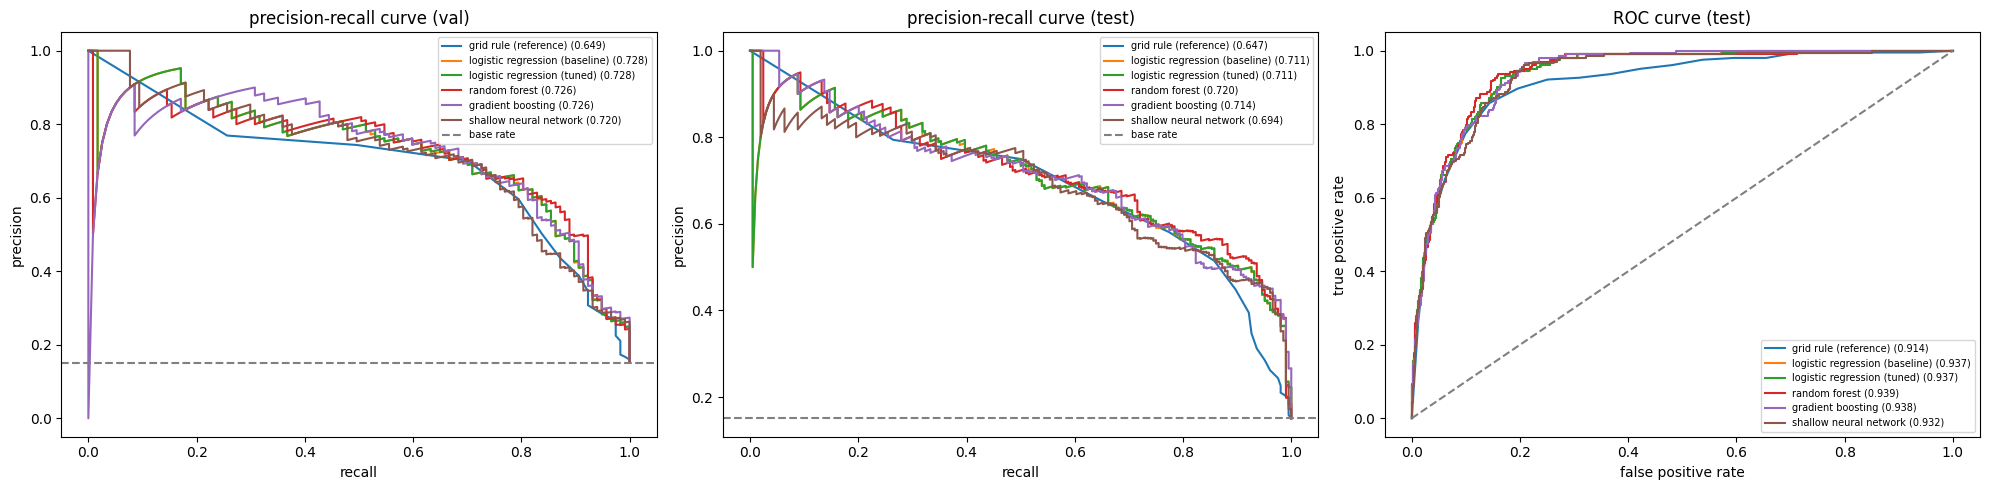

In [184]:
results = pd.concat(RESULTS)
comparison = results.pivot_table(index="model", columns="split", values=["PR-AUC", "ROC-AUC", "F1", "precision", "recall", "top-3 hit rate"],
                                 sort=False)
comparison = comparison.reindex(columns=["train", "val", "test"], level=1)
display(comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for name, (model, thr) in MODELS.items():
    for ax, split in [(axes[0], "val"), (axes[1], "test")]:
        p = model.predict_proba(X[split])[:, 1]
        prec, rec, _ = precision_recall_curve(y[split], p)
        ax.plot(rec, prec, label=f"{name} ({average_precision_score(y[split], p):.3f})")
    p = model.predict_proba(X["test"])[:, 1]
    fpr, tpr, _ = roc_curve(y["test"], p)
    axes[2].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y['test'], p):.3f})")
for ax, split in [(axes[0], "val"), (axes[1], "test")]:
    ax.axhline(y[split].mean(), ls="--", color="gray", label="base rate")
    ax.set(title=f"precision-recall curve ({split})", xlabel="recall", ylabel="precision")
    ax.legend(fontsize=7)
axes[2].plot([0, 1], [0, 1], ls="--", color="gray")
axes[2].set(title="ROC curve (test)", xlabel="false positive rate", ylabel="true positive rate")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [185]:
# is the difference to the baseline real? race-level bootstrap on validation and test
base_name = "logistic regression (baseline)"
rows = []
for name, (model, _) in MODELS.items():
    if name == base_name:
        continue
    row = {"model": name}
    for split in ["val", "test"]:
        p_m = model.predict_proba(X[split])[:, 1]
        p_b = MODELS[base_name][0].predict_proba(X[split])[:, 1]
        lo, hi = race_bootstrap_diff(y[split], p_m, p_b, RACES[split])
        row[f"{split}: PR-AUC − baseline"] = average_precision_score(y[split], p_m) - average_precision_score(y[split], p_b)
        row[f"{split}: 95% interval"] = f"[{lo:+.3f}, {hi:+.3f}]"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model").round(3))

# confusion matrix of every model on the test set at its validation-chosen threshold
cm = {}
for name, (model, thr) in MODELS.items():
    pred = model.predict_proba(X["test"])[:, 1] >= thr
    cm[name] = {"true positives": int((pred & (y["test"] == 1)).sum()), "false positives": int((pred & (y["test"] == 0)).sum()),
                "false negatives": int((~pred & (y["test"] == 1)).sum()), "threshold": round(thr, 3)}
pd.DataFrame(cm).T

,val: PR-AUC − baseline,val: 95% interval,test: PR-AUC − baseline,test: 95% interval
model,,,,
grid rule (reference),-0.079,"[-0.129, -0.024]",-0.064,"[-0.110, -0.017]"
logistic regression (tuned),0.000,"[-0.001, +0.001]",0.000,"[-0.000, +0.001]"
random forest,-0.002,"[-0.021, +0.021]",0.009,"[-0.011, +0.030]"
gradient boosting,-0.002,"[-0.031, +0.031]",0.003,"[-0.024, +0.027]"
shallow neural network,-0.007,"[-0.047, +0.027]",-0.017,"[-0.049, +0.014]"


,true positives,false positives,false negatives,threshold
grid rule (reference),133.0,71.0,71.0,0.459
logistic regression (baseline),174.0,146.0,30.0,0.251
logistic regression (tuned),174.0,145.0,30.0,0.251
random forest,180.0,157.0,24.0,0.247
gradient boosting,170.0,162.0,34.0,0.210
shallow neural network,142.0,88.0,62.0,0.341


**Models — findings**
- **The features matter beyond the grid.** Every learned model beats the grid-only rule clearly: the baseline gains +0.078 PR-AUC on validation and +0.064 on test, and both bootstrap intervals exclude 0. Interestingly the top-3 hit rate is the same for the grid rule and logistic regression (0.701 / 0.652): within a race, the grid order already names the right three in most cases; what the features add is a better ranking *across* races and drivers (who is a real contender from P5, who is a long shot from P2), which is what PR-AUC measures.
- **The learned models are tied.** Validation PR-AUC 0.720–0.728, test 0.695–0.723; ROC-AUC 0.92–0.94 everywhere. Every difference to the baseline has a bootstrap interval that contains 0 (largest: random forest on test, +0.013, interval [−0.006, +0.032]). With 39–68 races, more flexible models do not earn a measurable gain over logistic regression.
- **Overfitting was controlled by tuning.** The first, unregularised trials are kept in the tables: random forest with small leaves reached train PR-AUC 0.93 and gradient boosting with large trees 0.87–0.97, with no gain on validation. The chosen settings (forest: `min_samples_leaf` = 200; boosting: 7-leaf trees, learning rate 0.05, 300 trees) bring train and validation close (0.60 / 0.73 and 0.65 / 0.72). Logistic regression and the network score *lower* on train (0.57) than on validation: the training seasons are harder (bigger fields, more retirements, 63% without qualifying data), not a sign of underfitting.
- **Hyperparameters that did not matter:** the penalty `C` of logistic regression (0.724–0.728), and `class_weight="balanced"`, which only shifts the probabilities; the class imbalance is handled by the validation-chosen threshold instead. The two-layer network (64, 32) scores lower on validation (0.705–0.706) than one layer of 32 (0.720), so one layer of 32 is kept.
- **Threshold and F1:** the chosen thresholds are 0.21–0.34, well below 0.5 because podiums are rare. On test, F1 is 0.63–0.67, with recall 0.70–0.88 and precision 0.51–0.62. The network is the most conservative (fewest false alarms: 89, but 61 missed podiums); the forest finds the most podiums (181 of 204) at the cost of 157 false alarms.
- **The new regulation era is handled:** test (2022–24) PR-AUC is within 0.01–0.03 of validation for every model, so there is no large drop on cars the model has never seen.
- **Selected model: logistic regression (tuned).** It has the highest validation PR-AUC (0.728, the selection criterion), it is the simplest, and its weights are directly readable. The random forest is statistically tied (and best on test), so it is kept as the second model for the explanations in section 8.


## 6.8 Error analysis
Section 6.7 says *how well* each model does overall. This section looks at *where* and *why* the selected model (tuned logistic regression) gets things wrong, using four diagnostics:
1. **Performance by season**: is the model stable across the held-out seasons, including the new 2022 regulation era?
2. **Calibration**: when the model says 40%, does the driver podium about 40% of the time? This matters for the inference function, which returns a probability.
3. **Biggest misses**: the most confident wrong predictions on test, and what happened in those races.
4. **Threshold sensitivity**: how much F1, precision and recall depend on the validation-chosen threshold.

All diagnostics are **read-only**: nothing here changes the model, the hyperparameters or the threshold, so the test set is still only *reported* on.

In [186]:
FINAL = "logistic regression (tuned)"
COMPARE = ["grid rule (reference)", FINAL, "random forest", "gradient boosting", "shallow neural network"]
final_model, final_threshold = MODELS[FINAL]

# held-out rows (validation + test) with predictions from every model
held = pd.concat([SPLITS["val"], SPLITS["test"]])
X_held = held[FEATURES]
P_HELD = {name: MODELS[name][0].predict_proba(X_held)[:, 1] for name in COMPARE}
print("held-out rows:", len(held), "| races:", held["raceId"].nunique(), "| seasons:", sorted(held["year"].unique()))

held-out rows: 2127 | races: 107 | seasons: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


### 6.8.1 Performance by season
PR-AUC per held-out season, with a 95% interval from a race-level bootstrap (whole races resampled). The dashed line is each season's base rate, the PR-AUC of random guessing. Each season has only 17–23 races, so intervals are wide: this checks for a **collapse** in one season, not small differences.

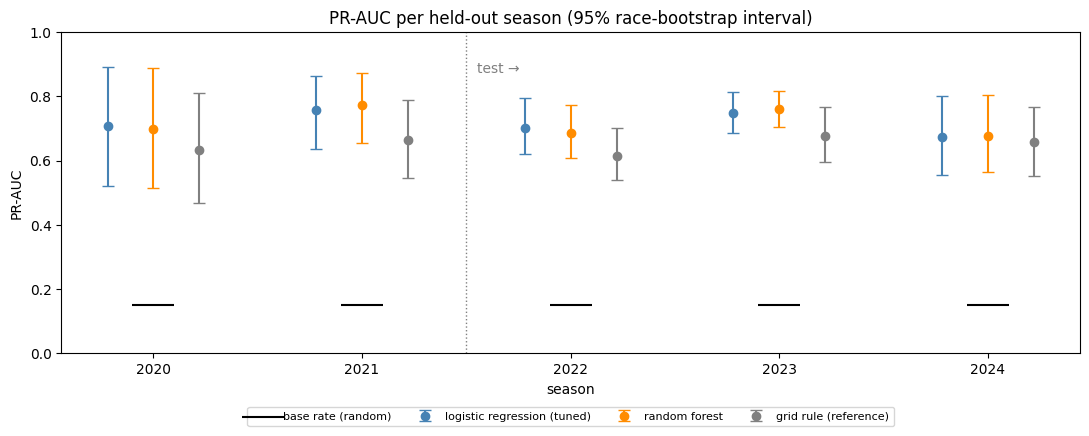

,,,model,grid rule (reference),logistic regression (tuned),random forest
season,split,races,base rate,,,
2020,val,17,0.150888,0.633,0.709,0.700
2021,val,22,0.151030,0.663,0.757,0.773
2022,test,22,0.150342,0.616,0.702,0.686
2023,test,22,0.151030,0.676,0.747,0.761
2024,test,24,0.151261,0.658,0.675,0.677


In [187]:
def race_bootstrap_ci(y_true, p, races, n=1000, seed=0):
    # 95% interval of PR-AUC, resampling whole races
    rng = np.random.default_rng(seed)
    y_true, races = np.asarray(y_true), np.asarray(races)
    rows_of = [np.flatnonzero(races == r) for r in np.unique(races)]
    scores = [average_precision_score(y_true[idx], p[idx])
              for idx in (np.concatenate([rows_of[i] for i in rng.integers(len(rows_of), size=len(rows_of))]) for _ in range(n))]
    return np.percentile(scores, [2.5, 97.5])

season_rows = []
for season, g in held.groupby("year"):
    mask = held["year"].to_numpy() == season
    for name in [FINAL, "random forest", "grid rule (reference)"]:
        p = P_HELD[name][mask]
        lo, hi = race_bootstrap_ci(g[TARGET], p, g["raceId"])
        season_rows.append({"season": season, "split": "val" if season <= VAL_END else "test", "model": name,
                            "races": g["raceId"].nunique(), "base rate": g[TARGET].mean(),
                            "PR-AUC": average_precision_score(g[TARGET], p), "CI low": lo, "CI high": hi,
                            "ROC-AUC": roc_auc_score(g[TARGET], p)})
by_season = pd.DataFrame(season_rows)

fig, ax = plt.subplots(figsize=(11, 4.5))
seasons = sorted(held["year"].unique())
for k, (name, color) in enumerate([(FINAL, "steelblue"), ("random forest", "darkorange"), ("grid rule (reference)", "gray")]):
    d = by_season[by_season["model"] == name].set_index("season").loc[seasons]
    xs = np.arange(len(seasons)) + (k - 1) * 0.22
    ax.errorbar(xs, d["PR-AUC"], yerr=[d["PR-AUC"] - d["CI low"], d["CI high"] - d["PR-AUC"]],
                fmt="o", capsize=4, color=color, label=name)
season_base = by_season.drop_duplicates("season").set_index("season").loc[seasons, "base rate"]
ax.scatter(np.arange(len(seasons)), season_base, marker="_", s=900, color="black", label="base rate (random)")
ax.axvline(VAL_END - seasons[0] + 0.5, color="gray", ls=":", lw=1)
ax.text(VAL_END - seasons[0] + 0.55, ax.get_ylim()[1] * 0.98, "test →", va="top", color="gray")
ax.set_xticks(range(len(seasons)), seasons)
ax.set(title="PR-AUC per held-out season (95% race-bootstrap interval)", ylabel="PR-AUC", xlabel="season", ylim=(0, 1))
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
plt.tight_layout()
plt.show()
by_season.pivot_table(index=["season", "split", "races", "base rate"], columns="model", values="PR-AUC").round(3)

In [188]:
# the same model over the eras of the TRAINING seasons (in-sample, so read as "where the task is hard", not as a test score)
train_df = SPLITS["train"]
p_train = final_model.predict_proba(X["train"])[:, 1]
by_era = (train_df.assign(p=p_train).groupby("era", sort=False)
          .apply(lambda g: pd.Series({"seasons": f"{g['year'].min()}–{g['year'].max()}", "rows": len(g),
                                      "base rate": g[TARGET].mean(),
                                      "has qualifying": g["has_quali"].mean(),
                                      "PR-AUC (in-sample)": average_precision_score(g[TARGET], g["p"])}), include_groups=False))
by_era.round(3)

,seasons,rows,base rate,has qualifying,PR-AUC (in-sample)
era,,,,,
1950-57 front-engine,1950–1957,1128,0.160,0.000,0.549
1958-65 rear-engine,1958–1965,1442,0.155,0.000,0.468
1966-76 3-litre,1966–1976,3050,0.137,0.000,0.452
1977-88 turbo,1977–1988,4656,0.121,0.000,0.474
1989-94 post-turbo,1989–1994,2480,0.116,0.157,0.562
1995-2008 V10/V8,1995–2008,5074,0.141,0.654,0.623
2009-13 late V8,2009–2013,2135,0.132,0.997,0.636
2014-21 hybrid,2014–2019,2471,0.147,0.995,0.735


**Reading 6.8.1:**
- **No season collapses.** Every held-out season scores far above its base rate (about 0.15): the selected model ranges from about 0.68 (2024) to 0.76 (2021), and the random forest tracks it within about 0.01 in every season. The intervals are wide (±0.06–0.18) because each season has only 17–24 races.
- **The 2022 regulation change does not break the model.** 2022, the first ground-effect season, scores about the same as the validation seasons. The features describe *relative* strength (grid slot, share of the leader's points, recent podium rate), and those keep their meaning when the cars change.
- **The weakest season is the most competitive one.** 2024 had four different teams winning races, so recent form and standings point less clearly at the podium, and its score is closest to the grid rule's.
- **By era (in-sample):** the model fits the early eras much worse (PR-AUC about 0.45–0.55) than the hybrid era (about 0.74), even though it was trained on them. Those seasons have no qualifying data, bigger fields and frequent retirements, so a podium was less predictable before the race. This is also why train PR-AUC (0.57) is *below* validation (0.73) in 6.7: the training seasons are harder, not the model underfitting.

### 6.8.2 Calibration
A model can rank drivers well (high PR-AUC) and still give wrong *probabilities*. The reliability diagram bins held-out predictions into 10 quantile bins and plots the mean predicted probability against the real podium rate in each bin. A perfectly calibrated model lies on the diagonal. The **Brier score** (mean squared error of the probability, lower is better) summarises it in one number.

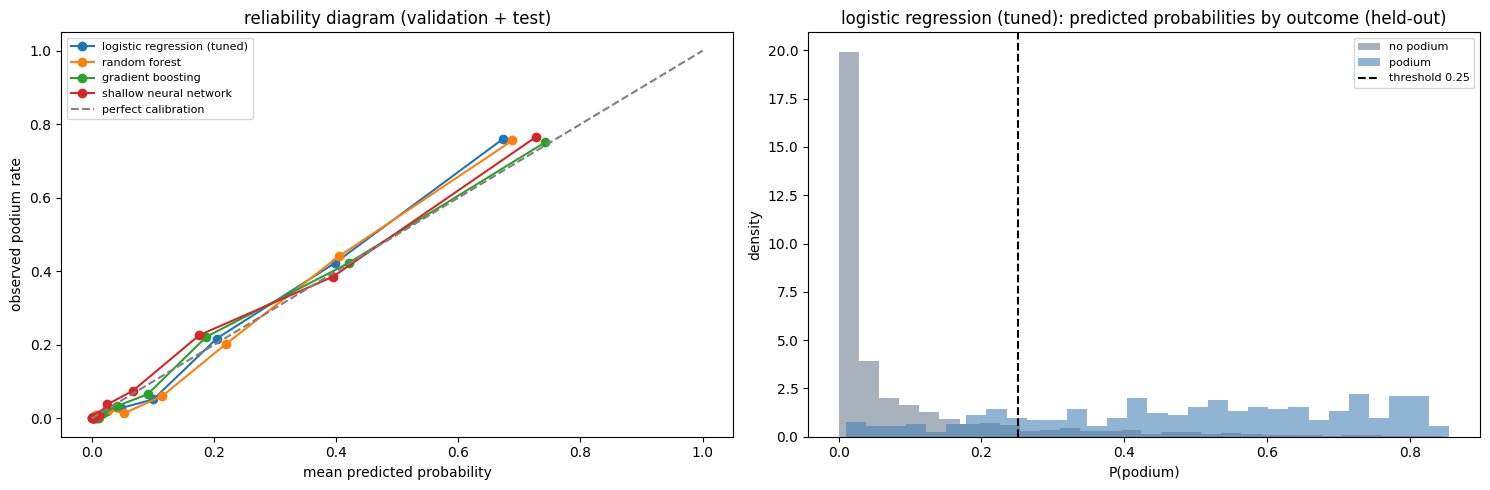

Brier score (held-out, lower is better):


,Brier
logistic regression (tuned),0.0696
random forest,0.0684
gradient boosting,0.0687
shallow neural network,0.0707
constant base rate (no skill),0.1284


sum of predicted probabilities per race: mean 2.93, range 2.10–3.42 (truth: 3)


In [189]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
brier = {}
for name in COMPARE[1:]:
    frac_pos, mean_pred = calibration_curve(held[TARGET], P_HELD[name], n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, "o-", label=name)
    brier[name] = brier_score_loss(held[TARGET], P_HELD[name])
axes[0].plot([0, 1], [0, 1], ls="--", color="gray", label="perfect calibration")
axes[0].set(title="reliability diagram (validation + test)", xlabel="mean predicted probability", ylabel="observed podium rate")
axes[0].legend(fontsize=8)

axes[1].hist(P_HELD[FINAL][held[TARGET] == 0], bins=30, alpha=0.6, label="no podium", color="slategray", density=True)
axes[1].hist(P_HELD[FINAL][held[TARGET] == 1], bins=30, alpha=0.6, label="podium", color="steelblue", density=True)
axes[1].axvline(final_threshold, color="black", ls="--", label=f"threshold {final_threshold:.2f}")
axes[1].set(title=f"{FINAL}: predicted probabilities by outcome (held-out)", xlabel="P(podium)", ylabel="density")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

base_brier = brier_score_loss(held[TARGET], np.full(len(held), y["train"].mean()))
print("Brier score (held-out, lower is better):")
display(pd.Series({**brier, "constant base rate (no skill)": base_brier}).round(4).to_frame("Brier"))

# probability sums per race: exactly 3 drivers podium in every race
race_sum = held.assign(p=P_HELD[FINAL]).groupby("raceId")["p"].sum()
print(f"sum of predicted probabilities per race: mean {race_sum.mean():.2f}, range {race_sum.min():.2f}–{race_sum.max():.2f} (truth: 3)")

**Reading 6.8.2:**
- **All four models are well calibrated** and close to each other: Brier scores of about 0.069–0.071, roughly half the no-skill score of a constant base rate (0.128). Calibration does not separate the models any more than PR-AUC does.
- **Where it deviates:** at the top end the models are slightly **under-confident**: drivers given about 0.67 podium in reality about 0.76 of the time. Below 0.1, where most drivers sit, the probabilities are accurate. So the probabilities from the inference function can be read at face value, if anything slightly conservative for favourites.
- **Sum per race:** exactly 3 drivers podium in every race. The model scores each driver separately and never sees this constraint, yet its probabilities add up to 2.93 per race on average (range 2.1–3.4). That is a direct sign the probabilities are well scaled.
- **The histogram shows what limits F1:** most non-podium drivers sit near 0, and podium finishers are spread over 0.3–0.85. But there is a band around the threshold (about 0.15–0.35) where podium and non-podium drivers look alike before the race.

### 6.8.3 Biggest misses (test seasons)
The most confident wrong predictions of the final model on test:
- **False alarms:** highest predicted probability, but no podium. The race outcome (from the post-race status, used **only here for diagnosis**, never as a feature) shows whether the driver retired.
- **Surprises:** lowest predicted probability, but a podium.

In [190]:
test_df = SPLITS["test"].copy()
test_df["p"] = final_model.predict_proba(X["test"])[:, 1]
# post-race information, joined only to EXPLAIN errors (never a model input)
outcome = base[["raceId", "driverId", "positionOrder", "status_group"]]
names = drivers_clean[["driverId", "full_name"]]
race_names = races_clean[["raceId", "name"]].rename(columns={"name": "race"})
test_df = (test_df.merge(outcome, on=["raceId", "driverId"], how="left")
                  .merge(names, on="driverId", how="left").merge(race_names, on="raceId", how="left"))
cols = ["year", "race", "full_name", "grid_rank", "quali_gap_pct", "drv_podium_ewm", "con_podium_ewm",
        "p", "positionOrder", "status_group"]

false_alarms = test_df[test_df[TARGET] == 0].nlargest(10, "p")[cols]
surprises = test_df[test_df[TARGET] == 1].nsmallest(10, "p")[cols]
print("10 most confident false alarms (predicted podium, did not podium):")
display(false_alarms.round(3))
print("10 biggest surprises (podium the model did not expect):")
display(surprises.round(3))

# how the wrong yes/no decisions at the threshold break down by what happened in the race
fp = test_df[(test_df["p"] >= final_threshold) & (test_df[TARGET] == 0)]
print(f"all {len(fp)} false alarms at the threshold, by race outcome:")
display(fp["status_group"].value_counts().rename("false alarms").to_frame()
        .assign(share=lambda d: d["false alarms"] / len(fp)).round(3))
print("false alarms that finished P4–P6 (near misses):", int(fp["positionOrder"].between(4, 6).sum()), f"of {len(fp)}")

10 most confident false alarms (predicted podium, did not podium):


,year,race,full_name,grid_rank,quali_gap_pct,drv_podium_ewm,con_podium_ewm,p,positionOrder,status_group
916,2024,Australian Grand Prix,Max Verstappen,1,0.000,0.955,0.958,0.847,19,mechanical
1075,2024,Austrian Grand Prix,Max Verstappen,1,0.000,0.838,0.839,0.800,5,classified
180,2022,British Grand Prix,Max Verstappen,2,0.000,0.864,0.925,0.795,7,classified
1234,2024,United States Grand Prix,Lando Norris,1,0.000,0.637,0.905,0.738,4,classified
1,2022,Bahrain Grand Prix,Max Verstappen,2,0.136,0.871,0.887,0.738,19,mechanical
402,2022,São Paulo Grand Prix,Max Verstappen,3,0.000,0.853,0.984,0.734,6,classified
1275,2024,São Paulo Grand Prix,Lando Norris,1,0.000,0.612,0.816,0.720,6,classified
40,2022,Australian Grand Prix,Max Verstappen,2,0.367,0.790,0.802,0.703,18,mechanical
99,2022,Spanish Grand Prix,Charles Leclerc,1,0.000,0.402,0.514,0.653,20,mechanical
1076,2024,Austrian Grand Prix,Lando Norris,2,0.628,0.615,0.713,0.636,20,classified


10 biggest surprises (podium the model did not expect):


,year,race,full_name,grid_rank,quali_gap_pct,drv_podium_ewm,con_podium_ewm,p,positionOrder,status_group
1285,2024,São Paulo Grand Prix,Pierre Gasly,11,7.000,0.003,0.003,0.010,3,classified
691,2023,Dutch Grand Prix,Pierre Gasly,12,7.000,0.000,0.058,0.012,3,classified
1278,2024,São Paulo Grand Prix,Esteban Ocon,4,1.283,0.001,0.003,0.059,2,classified
1350,2024,Abu Dhabi Grand Prix,Charles Leclerc,19,0.856,0.550,0.709,0.059,3,classified
570,2023,Spanish Grand Prix,George Russell,12,1.458,0.144,0.364,0.079,3,classified
1289,2024,São Paulo Grand Prix,Max Verstappen,15,5.235,0.528,0.528,0.082,1,classified
768,2023,Qatar Grand Prix,Lando Norris,10,1.083,0.365,0.365,0.087,3,classified
443,2023,Bahrain Grand Prix,Fernando Alonso,5,0.700,0.005,0.001,0.090,3,classified
1302,2024,Las Vegas Grand Prix,Lewis Hamilton,10,0.276,0.169,0.308,0.100,2,classified
615,2023,Austrian Grand Prix,Sergio Pérez,15,1.221,0.435,0.959,0.105,3,classified


all 145 false alarms at the threshold, by race outcome:


,false alarms,share
status_group,,
classified,118,0.814
mechanical,13,0.090
incident_driver,10,0.069
stewards_or_other,4,0.028


false alarms that finished P4–P6 (near misses): 95 of 145


**Reading 6.8.3:**
- **Most false alarms are near misses, not bad picks.** Of the false alarms at the threshold, about 65% finished P4–P6, just off the podium, and about 16% retired (mechanical failure or an incident), which nothing before the race could predict.
- **The most confident misses are favourites who hit trouble:** e.g. Verstappen from pole in Australia 2024 (retired with a mechanical failure, p ≈ 0.85) and in Bahrain 2022 (mechanical, 0.74), or front-row starters finishing P4–P7.
- **The biggest surprises cluster in chaotic races.** São Paulo 2024 (a wet race: Verstappen won from P17, Ocon 2nd and Gasly 3rd from midfield) and the wet Dutch GP 2023 (Gasly 3rd) appear repeatedly. Wet qualifying also distorts the features: Gasly's qualifying gap hit the 7% cap, so he looked like a back-marker.
- **Grid penalties are the other source:** Leclerc in Abu Dhabi 2024 started P19 after a penalty and finished 3rd. Section 4.2 showed penalised drivers from the back podium 2–3× more often than drivers who qualified there. A linear model only sees the weak overall effect of `grid_minus_quali`, not that interaction, which motivates the penalty × grid experiment in section 7.
- **Limitation to state in the report:** race-day chaos (weather, safety cars, reliability on the day) is outside the information allowed at prediction time, so no pre-race model can catch it.

### 6.8.4 Threshold sensitivity
The F1 threshold was chosen on validation (6.1). This shows how much precision, recall and F1 would change with a different cutoff, on validation and test, and whether the validation choice was sensitive or sits on a flat plateau. The test curve is plotted only to **report** robustness; it was not used to choose anything.

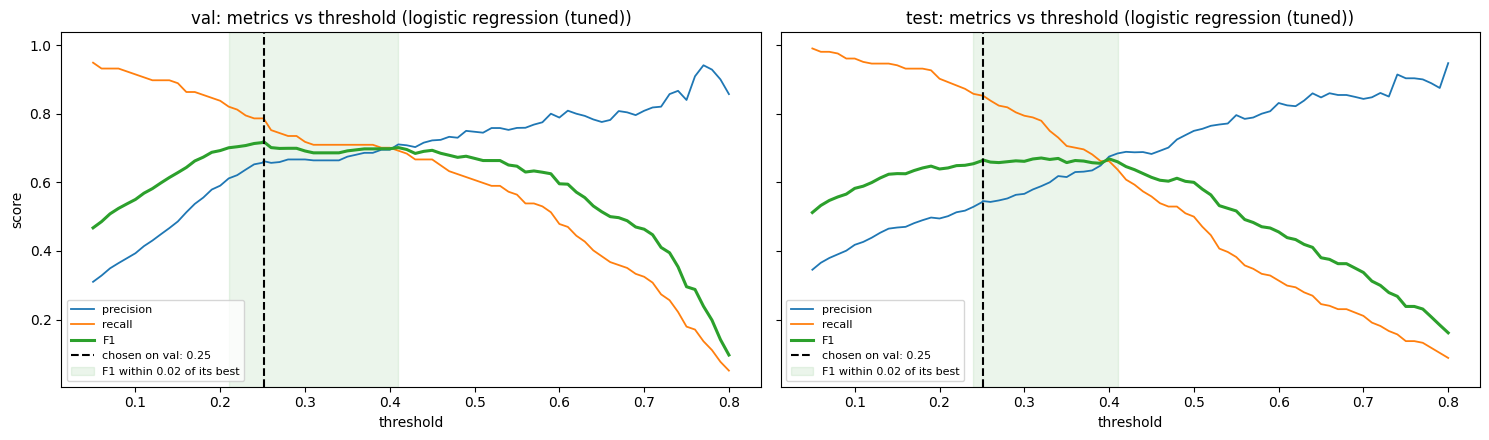

,F1 at chosen threshold,best possible F1 (any threshold),thresholds within 0.02 of best
split,,,
val,0.719,0.719,0.21–0.41
test,0.665,0.671,0.24–0.41


In [191]:
thresholds = np.unique(np.r_[np.linspace(0.05, 0.8, 76), final_threshold])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
sens = []
for ax, split in zip(axes, ["val", "test"]):
    p = final_model.predict_proba(X[split])[:, 1]
    curves = {"precision": [], "recall": [], "F1": []}
    for t in thresholds:
        pred = (p >= t).astype(int)
        curves["precision"].append(precision_score(y[split], pred, zero_division=0))
        curves["recall"].append(recall_score(y[split], pred))
        curves["F1"].append(f1_score(y[split], pred))
    for k, v in curves.items():
        ax.plot(thresholds, v, label=k, lw=2.2 if k == "F1" else 1.3)
    ax.axvline(final_threshold, color="black", ls="--", label=f"chosen on val: {final_threshold:.2f}")
    f1 = np.array(curves["F1"])
    best = f1.max()
    near = thresholds[f1 >= best - 0.02]
    ax.axvspan(near.min(), near.max(), color="green", alpha=0.08, label="F1 within 0.02 of its best")
    ax.set(title=f"{split}: metrics vs threshold ({FINAL})", xlabel="threshold")
    ax.legend(fontsize=8)
    sens.append({"split": split, "F1 at chosen threshold": f1_score(y[split], (p >= final_threshold).astype(int)),
                 "best possible F1 (any threshold)": best,
                 "thresholds within 0.02 of best": f"{near.min():.2f}–{near.max():.2f}"})
axes[0].set_ylabel("score")
plt.tight_layout()
plt.show()
pd.DataFrame(sens).set_index("split").round(3)

**Reading 6.8.4:**
- **The threshold choice is robust.** The chosen 0.25 is the exact F1 peak on validation, but it is not a knife-edge: F1 stays within 0.02 of that peak for any threshold from about 0.21 to 0.45. On test the same plateau runs from about 0.24 to 0.41 and contains 0.25, so the validation choice carries over.
- **Almost nothing was lost by choosing on validation.** Test F1 at the chosen threshold (0.667) is within about 0.005 of the best F1 any threshold could have reached on test, a cutoff we were not allowed to pick.
- **Precision–recall trade-off:** at 0.25 the model favours recall (about 0.85 on test): it flags most real podium finishers at the cost of more false alarms. Any cutoff up to about 0.4 gives about the same F1 with more precision and less recall. The inference function returns the probability, so a user who wants only confident picks can apply a higher cutoff.

# 7. Experiments
Each experiment changes **one thing** and keeps everything else fixed: the same training rows (unless the rows are the thing being tested), the same validation-chosen hyperparameters from section 6 and the same preprocessing pipeline. Every variant is scored on **validation**, the set all choices are made on. Test is shown next to it for information only.

**Decision rule, fixed before running:** a variant replaces the current setup only if it raises validation PR-AUC **and** the 95% race-bootstrap interval of the difference excludes 0 (the noise level found in 5.3 and 6.7). Otherwise the simpler, current setup stays.

Two models are used throughout:
- **logistic regression (tuned):** the selected model.
- **random forest:** statistically tied with it, and a tree model, so it can show effects that a linear model cannot use (e.g. interactions).

In [192]:
EXP_MODELS = {
    "logistic regression": (lambda: LogisticRegression(**lr_params), True),
    "random forest": (lambda: RandomForestClassifier(**rf_params), False),
}

def make_variant_preprocessor(features, scale):
    # Same steps as make_preprocessor (section 5), but each step only touches columns that are present,
    # so it also works when a feature group is removed. With all features it is identical to make_preprocessor.
    steps = []
    if {"quali_gap_pct", "grid_rank"} <= set(features):
        steps.append(("quali_gap", GridBandImputer()))
    steps.append(("median", SimpleImputer(strategy="median", keep_empty_features=True)))
    if scale:
        logs = [c for c in LOG_FEATURES if c in features]
        if logs:
            steps.append(("log", ColumnTransformer([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), logs)],
                                                   remainder="passthrough", verbose_feature_names_out=False)))
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps).set_output(transform="pandas")


def fit_variant(model_key, features, train_rows=None):
    # Train one model on the given features (and optionally a subset of the training rows);
    # return its validation and test probabilities.
    make_model, scale = EXP_MODELS[model_key]
    rows = X["train"].index if train_rows is None else train_rows
    pipe = Pipeline([("prep", make_variant_preprocessor(features, scale)), ("model", make_model())])
    pipe.fit(model_table.loc[rows, features], model_table.loc[rows, TARGET])
    return {split: pipe.predict_proba(SPLITS[split][features])[:, 1] for split in ["val", "test"]}

def compare(variants, reference, model_key):
    # PR-AUC of every variant on val/test, and the race-bootstrap interval of its difference to the reference.
    rows = []
    for name, p in variants.items():
        row = {"model": model_key, "variant": name}
        for split in ["val", "test"]:
            row[f"{split} PR-AUC"] = average_precision_score(y[split], p[split])
            row[f"{split} Δ"] = row[f"{split} PR-AUC"] - average_precision_score(y[split], variants[reference][split])
        lo, hi = race_bootstrap_diff(y["val"], p["val"], variants[reference]["val"], RACES["val"])
        row["val Δ 95% CI"] = "—" if name == reference else f"[{lo:+.3f}, {hi:+.3f}]"
        row["significant"] = "" if name == reference else ("yes" if lo > 0 or hi < 0 else "no")
        rows.append(row)
    return pd.DataFrame(rows).set_index(["model", "variant"])

## 7.1 Feature-group ablation
Section 4 justified each feature group *before* training, with plots and correlations on the training seasons. The ablation measures what each group actually contributes *after* training: remove one group at a time, retrain, and see how much validation PR-AUC drops.
- **A large drop** means the group carries information that no other group replaces.
- **A drop near 0** does not mean the group is useless on its own. It means the other groups already carry the same information (e.g. standings and form both describe how strong a car is, 4.3–4.4).

val PR-AUC   val Δ  \
model               variant                                                    
logistic regression all 27 features                           0.7280  0.0000   
                    without grid                              0.6838 -0.0441   
                    without qualifying                        0.7238 -0.0041   
                    without standings                         0.7285  0.0005   
                    without form                              0.7240 -0.0039   
                    without reliability                       0.7290  0.0010   
                    without circuit_history                   0.7259 -0.0021   
                    without driver                            0.7238 -0.0042   
                    without context                           0.7255 -0.0025   
                    grid only (all other groups removed)      0.6551 -0.0728   
random forest       all 27 features                           0.7262  0.0000   
                    without grid                              0.6961 -0.0301   
                    without qualifying                        0.7206 -0.0057   
                    without standings                         0.7236 -0.0027   
                    without form                              0.7349  0.0087   
                    without reliability                       0.7279  0.0017   
                    without circuit_history                   0.7183 -0.0079   
                    without driver                            0.7236 -0.0026   
                    without context                           0.7261 -0.0001   
                    grid only (all other groups removed)      0.6524 -0.0738   

                                                          test PR-AUC  test Δ  \
model               variant                                                     
logistic regression all 27 features                            0.7110  0.0000   
                    without grid                               0.6666 -0.0444   
                    without qualifying                         0.7087 -0.0023   
                    without standings                          0.7088 -0.0022   
                    without form                               0.7061 -0.0048   
                    without reliability                        0.7123  0.0013   
                    without circuit_history                    0.7099 -0.0011   
                    without driver                             0.7097 -0.0013   
                    without context                            0.7101 -0.0009   
                    grid only (all other groups removed)       0.6464 -0.0646   
random forest       all 27 features                            0.7202  0.0000   
                    without grid                               0.6485 -0.0718   
                    without qualifying                         0.7272  0.0070   
                    without standings                          0.7181 -0.0022   
                    without form                               0.7226  0.0024   
                    without reliability                        0.7248  0.0045   
                    without circuit_history                    0.7231  0.0029   
                    without driver                             0.7197 -0.0005   
                    without context                            0.7216  0.0014   
                    grid only (all other groups removed)       0.6651 -0.0551   

                                                              val Δ 95% CI  \
model               variant                                                  
logistic regression all 27 features                                      —   
                    without grid                          [-0.090, +0.014]   
                    without qualifying                    [-0.013, +0.002]   
                    without standings                     [-0.008, +0.008]   
                    without form              

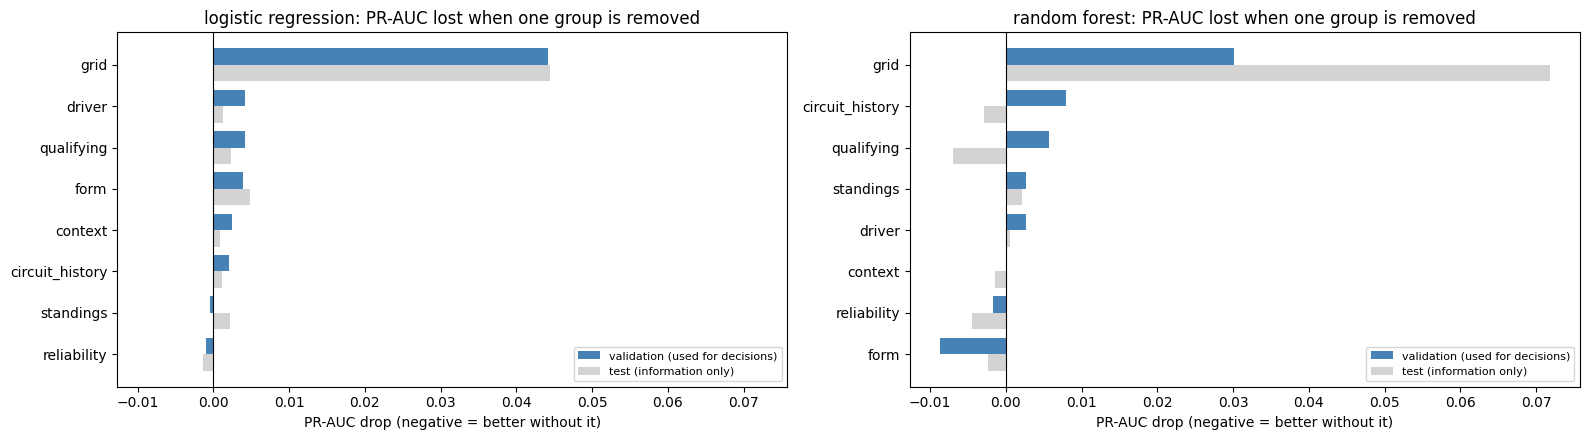

In [193]:
ablation_tables, ABL = [], {}
for model_key in EXP_MODELS:
    variants = {"all 27 features": fit_variant(model_key, FEATURES)}
    for group, cols in FEATURE_GROUPS.items():
        variants[f"without {group}"] = fit_variant(model_key, [f for f in FEATURES if f not in cols])
    variants["grid only (all other groups removed)"] = fit_variant(model_key, FEATURE_GROUPS["grid"])
    ABL[model_key] = variants
    ablation_tables.append(compare(variants, "all 27 features", model_key))
ablation = pd.concat(ablation_tables)
display(ablation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharex=True)
for ax, model_key in zip(axes, EXP_MODELS):
    d = ablation.loc[model_key].drop(["all 27 features", "grid only (all other groups removed)"])
    order = (-d["val Δ"]).sort_values().index
    pos = np.arange(len(order))
    ax.barh(pos + 0.2, -d.loc[order, "val Δ"], height=0.4, color="steelblue", label="validation (used for decisions)")
    ax.barh(pos - 0.2, -d.loc[order, "test Δ"], height=0.4, color="lightgray", label="test (information only)")
    ax.set_yticks(pos, [o.replace("without ", "") for o in order])
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=f"{model_key}: PR-AUC lost when one group is removed", xlabel="PR-AUC drop (negative = better without it)")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Ablation — findings**
- **Grid is the only group the models cannot do without.** Removing it costs logistic regression 0.045 PR-AUC on validation and 0.044 on test, and the random forest 0.017 and 0.079. Even here the validation interval just reaches 0 ([−0.091, +0.014] for logistic regression), which shows how little 39 races can resolve. The drop is large and in the same direction on both splits and both models, so it is real.
- **Every other group, removed on its own, changes PR-AUC by at most about 0.005 for logistic regression** (driver, form, qualifying, context, circuit history), with no interval excluding 0. For the random forest the changes go both ways and are noise: removing form even *raises* validation PR-AUC by 0.010 but changes test by only +0.001, and removing standings raises validation by 0.005 and lowers test by 0.001.
- **That does not make those groups useless. It means they overlap.** Standings, form, qualifying gap and reliability all describe how strong the car and driver are (4.3–4.4 found correlations of 0.6–0.9 between them), so removing one leaves the others to carry the same information. The **"grid only"** row shows what they are worth *together*: keeping only the 5 grid features drops logistic regression by 0.073 on validation (interval [−0.128, −0.013], which excludes 0) and 0.064 on test, and the random forest by 0.075 and 0.061. Grid gets a model to about 0.65; the other seven groups together add the rest, up to about 0.73.
- **Why we keep all groups instead of dropping the near-zero ones:** no single removal improves validation PR-AUC beyond noise, and the decision rule (section 7 intro) only accepts changes that do. The groups also keep the model robust: if one source is missing for a driver (e.g. no standings at a season opener), the overlapping groups still describe the car.

## 7.2 Qualifying handling
Qualifying data is missing for 63.6% of training rows (none before 1994, patchy until 2002) but present for about 99% of validation and test rows (4.2). Three ways to handle that gap:
- **A. Current:** all seasons from 1950; the missing gap is imputed by grid band, and `has_quali` flags the imputed rows (5.1).
- **B. No qualifying features:** drop `quali_gap_pct`, `grid_minus_quali` and `has_quali`, so nothing is imputed (this is the same as the ablation row "without qualifying").
- **C. Train only on seasons with qualifying data:** 2003–2019 (from 2003 every starter has a qualifying time, 4.2), so nothing needs imputing, but the model sees about 6,500 instead of 22,400 training rows.
- **D. Middle ground:** train on 1994–2019, where qualifying exists but is patchy before 2003.

The question is whether imputing 64% of the training gaps hurts the model, or whether the extra seasons are worth more than clean qualifying data.

In [194]:
QUALI_COLS = FEATURE_GROUPS["qualifying"]
train_years = model_table.loc[X["train"].index, "year"]
rows_2003 = X["train"].index[train_years >= 2003]
rows_1994 = X["train"].index[train_years >= 1994]
print("training rows: all", len(X["train"]), "| 1994+", len(rows_1994), "| 2003+", len(rows_2003))
print("share with qualifying data:", round(model_table.loc[X["train"].index, "has_quali"].mean(), 3),
      "|", round(model_table.loc[rows_1994, "has_quali"].mean(), 3), "|", round(model_table.loc[rows_2003, "has_quali"].mean(), 3))

quali_tables = []
for model_key in EXP_MODELS:
    variants = {
        "A. all seasons, grid-band imputation (current)": ABL[model_key]["all 27 features"],
        "B. no qualifying features": ABL[model_key]["without qualifying"],
        "C. train on 2003–2019 only": fit_variant(model_key, FEATURES, rows_2003),
        "D. train on 1994–2019 only": fit_variant(model_key, FEATURES, rows_1994),
    }
    quali_tables.append(compare(variants, "A. all seasons, grid-band imputation (current)", model_key))
quali_exp = pd.concat(quali_tables)
quali_exp.round(4)

training rows: all 22436 | 1994+ 10093 | 2003+ 6783
share with qualifying data: 0.37 | 0.822 | 0.997


val PR-AUC  \
model               variant                                                      
logistic regression A. all seasons, grid-band imputation (current)      0.7280   
                    B. no qualifying features                           0.7238   
                    C. train on 2003–2019 only                          0.7107   
                    D. train on 1994–2019 only                          0.7179   
random forest       A. all seasons, grid-band imputation (current)      0.7262   
                    B. no qualifying features                           0.7206   
                    C. train on 2003–2019 only                          0.7341   
                    D. train on 1994–2019 only                          0.7245   

                                                                     val Δ  \
model               variant                                                  
logistic regression A. all seasons, grid-band imputation (current)  0.0000   
                    B. no qualifying features                      -0.0041   
                    C. train on 2003–2019 only                     -0.0173   
                    D. train on 1994–2019 only                     -0.0101   
random forest       A. all seasons, grid-band imputation (current)  0.0000   
                    B. no qualifying features                      -0.0057   
                    C. train on 2003–2019 only                      0.0079   
                    D. train on 1994–2019 only                     -0.0017   

                                                                    test PR-AUC  \
model               variant                                                       
logistic regression A. all seasons, grid-band imputation (current)       0.7110   
                    B. no qualifying features                            0.7087   
                    C. train on 2003–2019 only                           0.7042   
                    D. train on 1994–2019 only                           0.7011   
random forest       A. all seasons, grid-band imputation (current)       0.7202   
                    B. no qualifying features                            0.7272   
                    C. train on 2003–2019 only                           0.7107   
                    D. train on 1994–2019 only                           0.7149   

                                                                    test Δ  \
model               variant                                                  
logistic regression A. all seasons, grid-band imputation (current)  0.0000   
                    B. no qualifying features                      -0.0023   
                    C. train on 2003–2019 only                     -0.0068   
                    D. train on 1994–2019 only                     -0.0099   
random forest       A. all seasons, grid-band imputation (current)  0.0000   
                    B. no qualifying features                       0.0070   
                    C. train on 2003–2019 only                     -0.0096   
                    D. train on 1994–2019 only                     -0.0053   

                                                                        val Δ 95% CI  \
model               variant                                                            
logistic regression A. all seasons, grid-band imputation (current)                 —   
                    B. no qualifying features                       [-0.013, +0.002]   
                    C. train on 2003–2019 only                      [-0.043, +0.007]   
                    D. train on 1994–2019 only                      [-0.030, +0.008]   
random forest       A. all seasons, grid-band imputation (current)                 —   
                    B. no qualifying features                       [-0.015, +0.004]   
                    C. train on 2003–2019 only                      [-0.011, +0.023]   
                    D. train on 1994–2019 only                

**Qualifying handling — findings**
- **For the selected model, the current setup (A) is the best.** Logistic regression scores lower with every alternative: no qualifying features −0.004, 1994+ training −0.010, 2003+ training −0.017 on validation (none significant), and also lower on test. A linear model gains more from 22,400 training rows (the extra seasons sharpen every weight) than it loses from imputing the qualifying gap, especially since `has_quali` tells it which gaps are imputed.
- **The random forest does better on 2003+ seasons only** (+0.016 on validation, interval [+0.000, +0.029], which only just excludes 0). On test the same variant is **worse** (−0.007). A gain that sits at the edge of the interval on 39 races and flips sign on 68 test races is most likely noise, not a real improvement.
- **Decision: keep A for every model.** The brief requires all models to be trained on the same rows, so the forest cannot use a different training period from the selected model, and the selected model prefers all seasons. Removing the qualifying features (B) loses a little on both models, which confirms the qualifying gap carries some information beyond the grid (4.2), even with 64% of training gaps imputed.

## 7.3 Penalty × grid interaction
Section 4.2 found that a driver who starts far back **because of a grid penalty** podiums 2–3× more often than a driver who qualified there (a fast car out of position), and 6.8.3 showed it in the test errors (Leclerc, Abu Dhabi 2024: P19 → P3). Logistic regression adds features up, so it only sees the weak *overall* effect of `grid_minus_quali` (ρ = +0.04) and cannot learn that a penalty matters more the further back it puts a driver.

Two ways to hand that interaction to the model as a feature:
- **`penalty_x_grid`** = places lost to a penalty × `grid_pct`: zero for unpenalised drivers, large for a fast car pushed to the back.
- **`quali_rank`** = `grid_rank − grid_minus_quali`: the qualifying slot itself, i.e. where the driver's pace put them before any penalty. (Section 4.2 left it out as almost the same as `grid_rank`; this tests whether that cost anything.)

Both are known before the race: qualifying and penalties are published before the start.

In [195]:
model_table["penalty_x_grid"] = model_table["grid_minus_quali"].clip(lower=0) * model_table["grid_pct"]
model_table["quali_rank"] = model_table["grid_rank"] - model_table["grid_minus_quali"]
for name in SPLITS:   # refresh the split views so they include the new columns
    SPLITS[name] = model_table.loc[SPLITS[name].index]

pen = model_table.loc[X["train"].index]
print("training rows with a penalty (lost places):", int((pen["grid_minus_quali"] > 0).sum()),
      "| with a penalty and grid_pct > 0.5:", int(((pen["grid_minus_quali"] > 0) & (pen["grid_pct"] > 0.5)).sum()))

inter_tables = []
for model_key in EXP_MODELS:
    variants = {
        "27 features (current)": ABL[model_key]["all 27 features"],
        "+ penalty_x_grid": fit_variant(model_key, FEATURES + ["penalty_x_grid"]),
        "+ quali_rank": fit_variant(model_key, FEATURES + ["quali_rank"]),
    }
    inter_tables.append(compare(variants, "27 features (current)", model_key))
inter_exp = pd.concat(inter_tables)
display(inter_exp.round(4))

# what the new feature does where it matters: penalised starters from the back half of the grid
p_base = ABL["logistic regression"]["all 27 features"]
lr_pen = fit_variant("logistic regression", FEATURES + ["penalty_x_grid"])
heldout = pd.concat([SPLITS["val"], SPLITS["test"]])
mask = ((heldout["grid_minus_quali"] > 0) & (heldout["grid_pct"] > 0.5)).to_numpy()
pb = np.r_[p_base["val"], p_base["test"]]
pp = np.r_[lr_pen["val"], lr_pen["test"]]
print(f"held-out penalised back-half starters: {mask.sum()} rows, {int(heldout.loc[mask, TARGET].sum())} podiums")
print(f"  mean predicted P(podium): current {pb[mask].mean():.3f} → with penalty_x_grid {pp[mask].mean():.3f}"
      f" | real podium rate {heldout.loc[mask, TARGET].mean():.3f}")

training rows with a penalty (lost places): 398 | with a penalty and grid_pct > 0.5: 339


val PR-AUC   val Δ  test PR-AUC  \
model               variant                                                  
logistic regression 27 features (current)      0.7280  0.0000       0.7110   
                    + penalty_x_grid           0.7270 -0.0010       0.7116   
                    + quali_rank               0.7277 -0.0002       0.7107   
random forest       27 features (current)      0.7262  0.0000       0.7202   
                    + penalty_x_grid           0.7250 -0.0012       0.7222   
                    + quali_rank               0.7265  0.0003       0.7248   

                                           test Δ      val Δ 95% CI  \
model               variant                                           
logistic regression 27 features (current)  0.0000                 —   
                    + penalty_x_grid       0.0006  [-0.005, +0.002]   
                    + quali_rank          -0.0003  [-0.001, +0.001]   
random forest       27 features (current)  0.0000                 —   
                    + penalty_x_grid       0.0019  [-0.009, +0.007]   
                    + quali_rank           0.0045  [-0.008, +0.010]   

                                          significant  
model               variant                            
logistic regression 27 features (current)              
                    + penalty_x_grid               no  
                    + quali_rank                   no  
random forest       27 features (current)              
                    + penalty_x_grid               no  
                    + quali_rank                   no

held-out penalised back-half starters: 135 rows, 5 podiums
  mean predicted P(podium): current 0.040 → with penalty_x_grid 0.041 | real podium rate 0.037


**Penalty × grid — findings**
- **Neither feature helps.** `penalty_x_grid` changes validation PR-AUC by −0.001 (logistic regression) and −0.005 (random forest), `quali_rank` by −0.000 and −0.002, all with intervals containing 0. Test changes are at most +0.001.
- **The reason is in the last line of the output: the model already gets these drivers right.** Held-out penalised drivers starting in the back half: 135 rows, 5 podiums, a real rate of 3.7%. The current model already predicts 4.0% for them on average, and adding the feature only moves it to 4.1%. The model does not need the interaction because **form and standings already tell it these are fast cars**: a front-running car with a penalty still has high recent podium rates and a high points share, which lifts its probability above that of an ordinary back-marker.
- **Why 4.2 still showed an effect:** 4.2 compared penalised drivers with drivers who qualified in the same slot *using grid alone*. The model compares them using all 27 features, and the other groups already separate the fast cars from the slow ones.
- **Rare cases stay hard.** Leclerc in Abu Dhabi 2024 (P19 → P3, 6.8.3) is one of only 5 podiums in 135 such starts. No feature makes such a rare event predictable with confidence. **Decision: keep the 27 features.**

## 7.4 Class weighting and the decision rule
The F1 threshold turns probabilities into yes/no. Two alternatives to the current setup (no class weighting, F1-maximising threshold chosen on validation):
- **Class weighting** (`class_weight="balanced"`): the rare podium rows count about 6× more in training. Section 6.3 showed it does not change validation PR-AUC; this shows what it *does* change.
- **Top-3 per race:** ignore the threshold and predict "podium" for the 3 highest probabilities in every race. It uses one fact known before every race, that there are exactly 3 podium places, and it needs no tuning at all.

In [196]:
from sklearn.metrics import brier_score_loss

def top3_pred(df, p):
    rank = pd.Series(p, index=df.index).groupby(df["raceId"].to_numpy()).rank(ascending=False, method="first")
    return (rank <= 3).astype(int).to_numpy()

lr_weighted = Pipeline([("prep", make_preprocessor(scale=True)),
                        ("model", LogisticRegression(**{**lr_params, "class_weight": "balanced"}))]).fit(X["train"], y["train"])
setups = {"no weighting (current)": final_model, "class_weight='balanced'": lr_weighted}
rows = []
for name, model in setups.items():
    p_val = model.predict_proba(X["val"])[:, 1]
    thr = best_f1_threshold(y["val"], p_val)
    for split in ["val", "test"]:
        p = model.predict_proba(X[split])[:, 1]
        for rule, pred in [(f"F1 threshold ({thr:.2f}, chosen on val)", (p >= thr).astype(int)),
                           ("top-3 per race", top3_pred(SPLITS[split], p))]:
            rows.append({"training": name, "decision rule": rule, "split": split,
                         "PR-AUC": average_precision_score(y[split], p), "Brier": brier_score_loss(y[split], p),
                         "mean P(podium)": p.mean(), "F1": f1_score(y[split], pred),
                         "precision": precision_score(y[split], pred), "recall": recall_score(y[split], pred),
                         "flagged per race": pred.sum() / SPLITS[split]["raceId"].nunique()})
decision = pd.DataFrame(rows).set_index(["training", "decision rule", "split"])
decision.round(3)

PR-AUC  \
training                decision rule                      split           
no weighting (current)  F1 threshold (0.25, chosen on val) val     0.728   
                        top-3 per race                     val     0.728   
                        F1 threshold (0.25, chosen on val) test    0.711   
                        top-3 per race                     test    0.711   
class_weight='balanced' F1 threshold (0.63, chosen on val) val     0.725   
                        top-3 per race                     val     0.725   
                        F1 threshold (0.63, chosen on val) test    0.706   
                        top-3 per race                     test    0.706   

                                                                  Brier  \
training                decision rule                      split          
no weighting (current)  F1 threshold (0.25, chosen on val) val    0.068   
                        top-3 per race                     val    0.068   
                        F1 threshold (0.25, chosen on val) test   0.071   
                        top-3 per race                     test   0.071   
class_weight='balanced' F1 threshold (0.63, chosen on val) val    0.111   
                        top-3 per race                     val    0.111   
                        F1 threshold (0.63, chosen on val) test   0.117   
                        top-3 per race                     test   0.117   

                                                                  mean P(podium)  \
training                decision rule                      split                   
no weighting (current)  F1 threshold (0.25, chosen on val) val             0.147   
                        top-3 per race                     val             0.147   
                        F1 threshold (0.25, chosen on val) test            0.147   
                        top-3 per race                     test            0.147   
class_weight='balanced' F1 threshold (0.63, chosen on val) val             0.310   
                        top-3 per race                     val             0.310   
                        F1 threshold (0.63, chosen on val) test            0.314   
                        top-3 per race                     test            0.314   

                                                                     F1  \
training                decision rule                      split          
no weighting (current)  F1 threshold (0.25, chosen on val) val    0.719   
                        top-3 per race                     val    0.701   
                        F1 threshold (0.25, chosen on val) test   0.665   
                        top-3 per race                     test   0.652   
class_weight='balanced' F1 threshold (0.63, chosen on val) val    0.718   
                        top-3 per race                     val    0.692   
                        F1 threshold (0.63, chosen on val) test   0.646   
                        top-3 per race                     test   0.637   

                                                                  precision  \
training                decision rule                      split              
no weighting (current)  F1 threshold (0.25, chosen on val) val        0.662   
                        top-3 per race                     val        0.701   
                        F1 threshold (0.25, chosen on val) test       0.545   
                        top-3 per race                     test       0.652   
class_weight='balanced' F1 threshold (0.63, chosen on val) val        0.648   
                        top-3 per race                     val        0.692   
                        F1 threshold (0.63, chosen on val) test       0.513   
                        top-3 per race                     test       0.637   

                                                                  recall  \
training                decision rule                      split           
no weighting (curre

**Class weighting and decision rule — findings**
- **Class weighting does not improve ranking but damages the probabilities.** PR-AUC barely moves (0.728 → 0.725 on validation, 0.711 → 0.705 on test). But the mean predicted probability doubles (0.147 → 0.310, against a real rate of 0.15), and the Brier score gets much worse (0.068 → 0.111). The F1 threshold just moves up to compensate (0.25 → 0.63), and test F1 is lower (0.667 → 0.647). **Decision: no weighting.** The imbalance is handled by the threshold, and the probabilities stay honest for the inference function.
- **Top-3 per race is a different trade-off, not a better one.** It flags exactly 3 drivers per race with no tuning, so precision rises (test 0.545 → 0.652) and recall falls (0.858 → 0.652). F1 is slightly lower (validation 0.716 → 0.701, test 0.667 → 0.652). The F1 threshold flags more drivers than 3 per race (3.6 on validation, 4.7 on test), so it catches more podiums at the cost of more false alarms.
- **Decision: keep the F1 threshold,** because F1 is the brief's metric and the threshold was chosen to maximise it. Top-3 is a sensible alternative for a user who wants exactly three names per race; the inference function returns the probability, so either rule can be applied.

### Section 7 summary
| Experiment | Result | Decision |
|---|---|---|
| Feature-group ablation | Grid is the only group that matters on its own (−0.045 PR-AUC). The other seven overlap, but together add about +0.07 over grid only. | Keep all 8 groups |
| Qualifying handling | All seasons with grid-band imputation is best for the selected model. Training on 2003+ only helps the forest on validation by a hair and is worse on test. | Keep the current setup |
| Penalty × grid feature | No gain. Form and standings already identify fast cars that start out of position. | Keep 27 features |
| Class weighting | Same ranking, much worse probabilities (Brier 0.068 → 0.111). | No weighting |
| Top-3 per race | Higher precision, lower recall, slightly lower F1. | Keep the F1 threshold |

**Overall:** no experiment beat the setup chosen in sections 4–6 beyond the noise of 39 validation races. That is the evidence that the current choices are justified. The final model stays **logistic regression (tuned) on all 27 features, no class weighting, threshold 0.25**.

# 8. Explainability (XAI)
This section asks **which inputs the final model relies on**, overall (global) and for single drivers (local):

| | Method | What it answers |
|---|---|---|
| Global | **Permutation importance** | How much does validation PR-AUC drop if one feature (or one feature group) is scrambled? |
| Global | **SHAP** (summary / beeswarm) | For every driver, how much did each feature push the prediction up or down? |
| Local | **SHAP waterfall** | For one driver, the step-by-step sum from the average prediction to this driver's prediction. |
| Local | **LIME** | For one driver, a simple linear model fitted around that single prediction. |

The model explained is the final one, **logistic regression (tuned)**, with the **random forest** (statistically tied, 6.7) as a check that the explanations are not specific to one model type.

> **Importance is not causation.** Everything in this section describes how the *model* uses its inputs. A feature being important means the model relies on it to predict podiums, **not** that the feature *causes* podiums. For example, a high championship points share does not make a driver finish on the podium; both are consequences of having a fast car and a strong driver, which the model can only see indirectly through these features.

In [197]:
# shap and lime are not preinstalled everywhere (on Kaggle: turn Internet on for lime)
import importlib.util, subprocess, sys
for pkg in ["shap", "lime"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance

rf_model = MODELS["random forest"][0]
lr_prep, lr_est = final_model.named_steps["prep"], final_model.named_steps["model"]
print("shap", shap.__version__, "| explaining:", FINAL, "and random forest")

shap 0.52.0 | explaining: logistic regression (tuned) and random forest


## 8.1 Global: permutation importance
**How it works:** take the validation rows, randomly shuffle one feature's column (breaking its link with the outcome while keeping its distribution), and measure how much PR-AUC drops. Repeated 20 times per feature. A large drop means the model depends on that feature. It is computed on **validation**, so it reflects what the model uses on unseen seasons, not what it memorised in training.

**Grouped version:** several features are near-duplicates (`grid_rank` and `grid_pct` correlate at 0.97, 4.1). Shuffling only one of them understates its importance, because the model still has the other. So each **feature group** is also shuffled as a whole, with the same row order for all its columns.

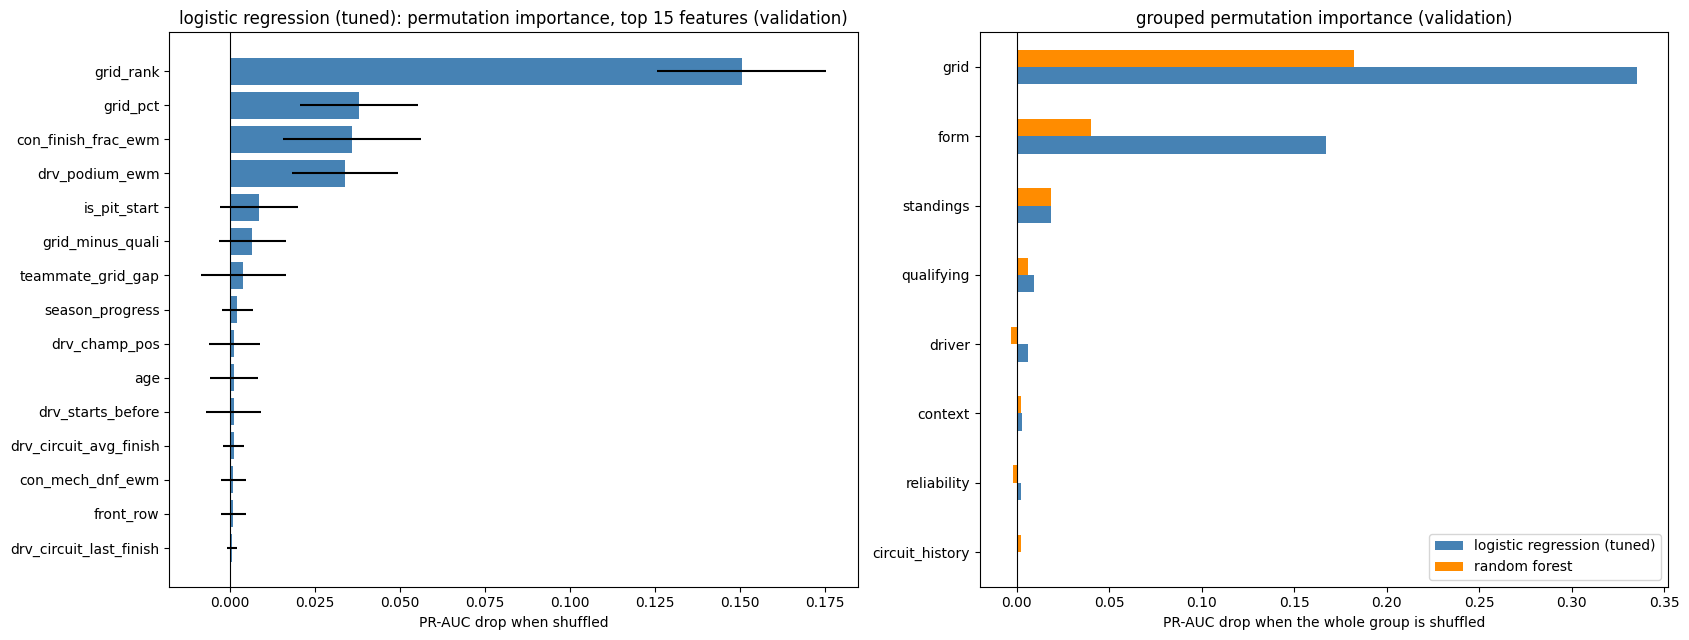

single features (final model):


,feature,mean drop,std,group
0,grid_rank,0.1506,0.0248,grid
1,grid_pct,0.0380,0.0174,grid
2,con_finish_frac_ewm,0.0360,0.0203,form
3,drv_podium_ewm,0.0339,0.0155,form
4,is_pit_start,0.0087,0.0114,grid
5,grid_minus_quali,0.0067,0.0098,qualifying
6,teammate_grid_gap,0.0040,0.0125,driver
7,season_progress,0.0023,0.0045,context
8,drv_champ_pos,0.0014,0.0075,standings
9,age,0.0013,0.0070,driver


feature groups:


logistic regression (tuned)         random forest        
                                  mean drop     std     mean drop     std
grid                                 0.3351  0.0431        0.1824  0.0413
form                                 0.1670  0.0271        0.0400  0.0244
standings                            0.0187  0.0172        0.0188  0.0201
qualifying                           0.0094  0.0109        0.0061  0.0162
driver                               0.0062  0.0097       -0.0031  0.0101
context                              0.0030  0.0050        0.0022  0.0027
reliability                          0.0022  0.0037       -0.0019  0.0077
circuit_history                      0.0005  0.0031        0.0022  0.0041

In [198]:
perm = permutation_importance(final_model, X["val"], y["val"], scoring="average_precision",
                              n_repeats=20, random_state=0)
perm_df = (pd.DataFrame({"feature": FEATURES, "mean drop": perm.importances_mean, "std": perm.importances_std})
           .assign(group=[g for g, cols in FEATURE_GROUPS.items() for _ in cols])
           .sort_values("mean drop", ascending=False).reset_index(drop=True))

def grouped_permutation(model, Xv, yv, groups, n_repeats=20, seed=0):
    # Shuffle all columns of a group together (same row permutation) and record the PR-AUC drop.
    rng = np.random.default_rng(seed)
    base_score = average_precision_score(yv, model.predict_proba(Xv)[:, 1])
    out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = Xv.copy()
            idx = rng.permutation(len(Xv))
            Xp[cols] = Xv[cols].to_numpy()[idx]
            drops.append(base_score - average_precision_score(yv, model.predict_proba(Xp)[:, 1]))
        out[g] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=["mean drop", "std"]).T.sort_values("mean drop", ascending=False)

group_perm = {name: grouped_permutation(m, X["val"], y["val"], FEATURE_GROUPS)
              for name, m in [(FINAL, final_model), ("random forest", rf_model)]}

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
top = perm_df.head(15).iloc[::-1]
axes[0].barh(top["feature"], top["mean drop"], xerr=top["std"], color="steelblue")
axes[0].set(title=f"{FINAL}: permutation importance, top 15 features (validation)", xlabel="PR-AUC drop when shuffled")
gp = pd.concat({k: v["mean drop"] for k, v in group_perm.items()}, axis=1).sort_values(FINAL)
gp.plot(kind="barh", ax=axes[1], color=["steelblue", "darkorange"])
axes[1].set(title="grouped permutation importance (validation)", xlabel="PR-AUC drop when the whole group is shuffled")
for ax in axes:
    ax.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

print("single features (final model):")
display(perm_df.head(12).round(4))
print("feature groups:")
display(pd.concat(group_perm, axis=1).round(4))

**Permutation importance — findings**
- **Grid position dominates.** Shuffling `grid_rank` alone costs 0.156 PR-AUC. The next three features cost 0.03–0.04 each: team finishing form (`con_finish_frac_ewm`), grid share (`grid_pct`) and driver podium form (`drv_podium_ewm`). Every other feature costs under 0.01, with error bars that cross 0.
- **By group** the picture is clearer: grid 0.34, form 0.17, standings 0.02, every other group 0.01 or less. The random forest ranks the groups in the same order (grid 0.17, form 0.04, standings 0.03), so the explanation is not specific to one model type.
- **Why form looks important here but not in the ablation (7.1):** permutation importance scrambles a feature in a model that is **already trained**, so the model cannot work around the damage. The ablation **retrains** without the group, so standings and qualifying take over the information form was carrying. Both are correct answers to different questions: *the trained model leans on form heavily* (permutation), but *form is replaceable by the other groups* (ablation).

## 8.2 Global: SHAP
**How it works:** SHAP splits each single prediction into one contribution per feature, so that *average prediction + sum of contributions = this driver's prediction*. The contributions come from game theory (Shapley values): each feature gets its fair share of the difference, averaged over all orders in which features could be added.
- For logistic regression, SHAP is exact and fast (`LinearExplainer`). Contributions are in **log-odds**, the scale the model adds things up on: positive pushes toward podium, negative away from it.
- For the random forest, `TreeExplainer` computes them exactly from the trees (in probability units), on a sample of 300 validation rows to keep the runtime short.

The **beeswarm** shows one dot per driver-race and feature: position = contribution, colour = the feature's value (red high, blue low). The **bar chart** is the mean absolute contribution, i.e. overall importance.

Background dataset has 22436 samples but max_samples=1000. Subsampling to 1000 samples for SHAP value computation. To use all samples, set max_samples=22436 when initializing the masker.


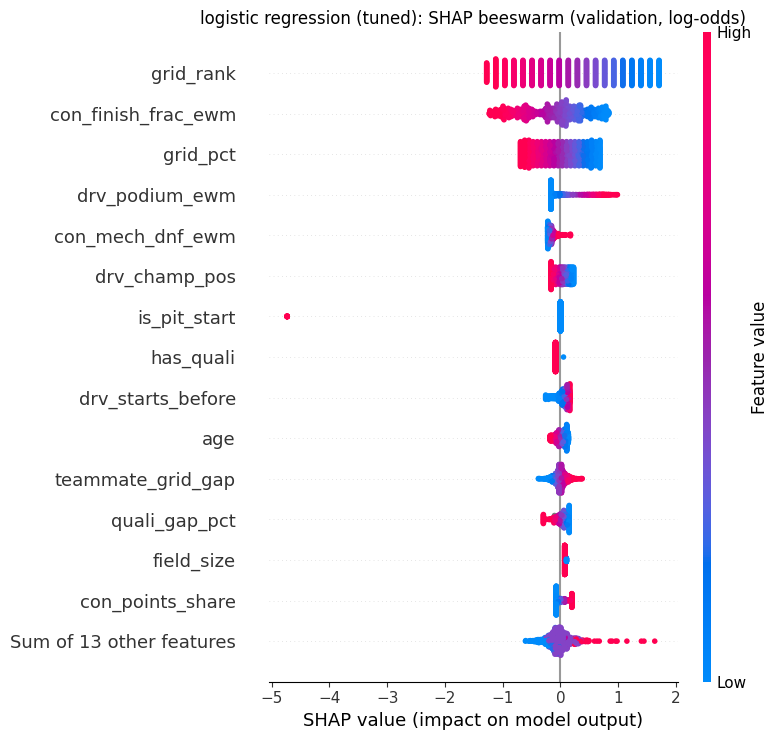

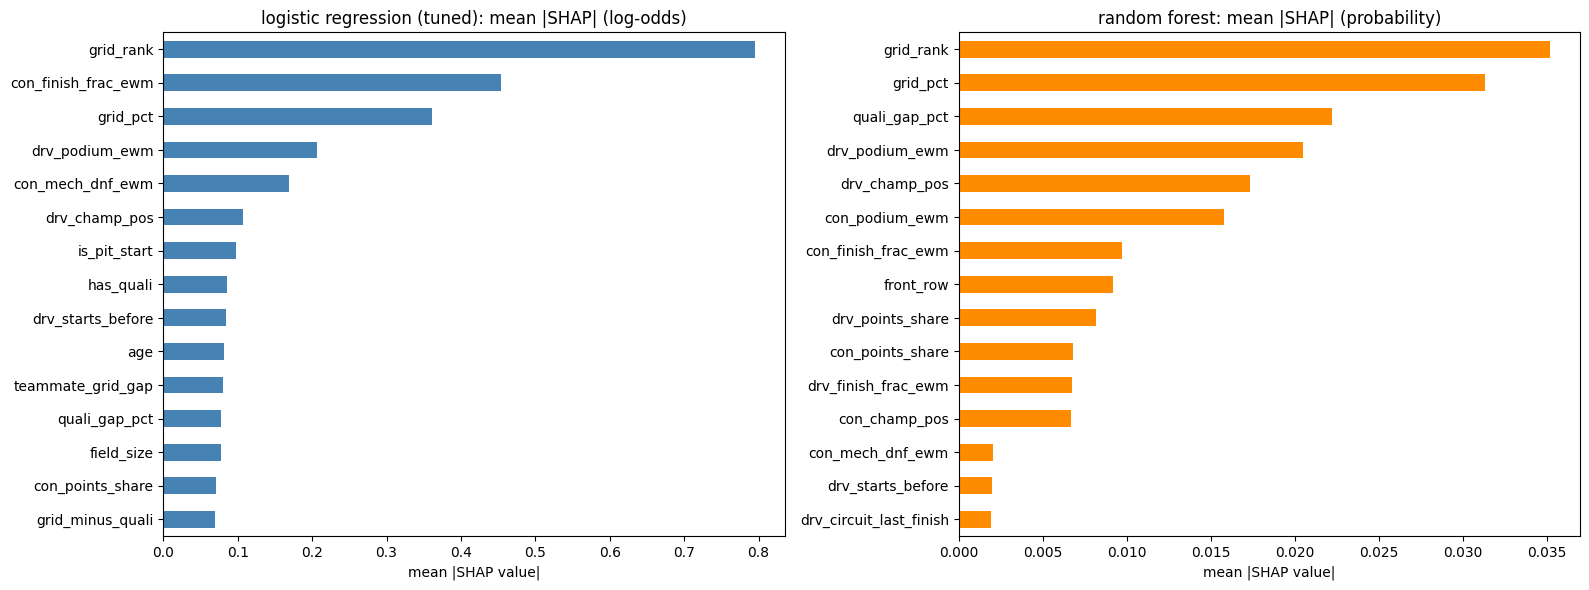

Spearman agreement of the feature rankings:


,logistic regression (tuned) rank,random forest rank,permutation rank (final)
logistic regression (tuned) rank,1.00,0.3,0.67
random forest rank,0.30,1.0,0.20
permutation rank (final),0.67,0.2,1.00


top 10 by SHAP (final model), with the other rankings:


,logistic regression (tuned) rank,random forest rank,permutation rank (final)
grid_rank,1,1,1
con_finish_frac_ewm,2,7,3
grid_pct,3,2,2
drv_podium_ewm,4,4,4
con_mech_dnf_ewm,5,13,13
drv_champ_pos,6,5,9
is_pit_start,7,26,5
has_quali,8,18,20
drv_starts_before,9,14,11
age,10,23,10


In [199]:
Xt_train = lr_prep.transform(X["train"])          # scaled features, in the order the model sees them
Xt_val = lr_prep.transform(X["val"])
lin_explainer = shap.LinearExplainer(lr_est, shap.maskers.Independent(Xt_train, max_samples=1000))
sv_lr = lin_explainer(Xt_val)
# show the features' real (unscaled) values in the plots instead of z-scores
sv_lr.data = X["val"][list(Xt_val.columns)].to_numpy()

plt.figure()
shap.plots.beeswarm(sv_lr, max_display=15, show=False)
plt.title(f"{FINAL}: SHAP beeswarm (validation, log-odds)")
plt.tight_layout()
plt.show()

shap_lr_imp = pd.Series(np.abs(sv_lr.values).mean(0), index=Xt_val.columns).sort_values(ascending=False)

rf_prep, rf_est = rf_model.named_steps["prep"], rf_model.named_steps["model"]
sample = X["val"].sample(300, random_state=0)
tree_explainer = shap.TreeExplainer(rf_est)
sv_rf_raw = tree_explainer(rf_prep.transform(sample))
sv_rf = sv_rf_raw[:, :, 1] if sv_rf_raw.values.ndim == 3 else sv_rf_raw   # contributions to P(podium)
shap_rf_imp = pd.Series(np.abs(sv_rf.values).mean(0), index=rf_prep.transform(sample).columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
shap_lr_imp.head(15).iloc[::-1].plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set(title=f"{FINAL}: mean |SHAP| (log-odds)", xlabel="mean |SHAP value|")
shap_rf_imp.head(15).iloc[::-1].plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set(title="random forest: mean |SHAP| (probability)", xlabel="mean |SHAP value|")
plt.tight_layout()
plt.show()

rank = pd.DataFrame({f"{FINAL} rank": shap_lr_imp.rank(ascending=False),
                     "random forest rank": shap_rf_imp.rank(ascending=False),
                     "permutation rank (final)": perm_df.set_index("feature")["mean drop"].rank(ascending=False)})
print("Spearman agreement of the feature rankings:")
display(rank.corr(method="spearman").round(2))
print("top 10 by SHAP (final model), with the other rankings:")
rank.sort_values(f"{FINAL} rank").head(10).astype(int)

**SHAP — findings**
- **The same top four as permutation importance:** `grid_rank`, `con_finish_frac_ewm`, `grid_pct`, `drv_podium_ewm`. The random forest's SHAP puts `grid_rank`, `grid_pct` and `drv_podium_ewm` in its top four too. Below the top features the rankings disagree (rank correlation 0.26 between the two models over all 27 features), which is expected: those features carry little and overlap heavily, so their order is noise.
- **Directions in the beeswarm make sense:** a better (lower) grid rank, a better recent team finish and a higher recent podium rate all push toward a podium; a pit-lane start pushes strongly away (the single dot at −4.8).
- **Two features look bigger in SHAP than in permutation importance: `con_mech_dnf_ewm` and `has_quali`.** SHAP measures each feature against an *average training row*, and training covers 1950–2019. Every 2020–21 car is far more reliable and every driver has qualifying data, so these features shift *every* validation driver by about the same amount. That changes the probability level but not *who ranks above whom*, which is why shuffling them barely changes PR-AUC. The same era shift was seen in the scaled distributions in 5.2.
- **A warning example for "importance ≠ cause":** the model gives a *higher* team mechanical-failure rate a slightly *positive* weight. That does not mean breakdowns help a team podium. The model already sees team finishing form, which counts a breakdown as a bad finish; given that form, a team whose poor results come from failures rather than slowness is a faster car than its form suggests, and the model adds that back. It is a statistical correction between correlated inputs, not a causal effect.

## 8.3 Local: explaining single predictions
Two drivers from the **test seasons**, chosen to be informative rather than easy:
- **Case A, a correct call from further back:** among test drivers who started **P6 or lower and did podium**, the one the model gave the highest probability. Why did the model believe in a driver the grid alone would have written off?
- **Case B, the most confident miss:** the test driver with the highest predicted probability who did **not** podium (6.8.3). What made the model so sure?

Each case gets a **SHAP waterfall** (exact contributions of the final model) and a **LIME** explanation (an independent method), so the two can be compared.

In [200]:
test_rows = SPLITS["test"].copy()
test_rows["p"] = final_model.predict_proba(X["test"])[:, 1]
case_a = test_rows[(test_rows["grid_rank"] >= 6) & (test_rows[TARGET] == 1)]["p"].idxmax()
case_b = test_rows[test_rows[TARGET] == 0]["p"].idxmax()

def describe(idx):
    r = model_table.loc[idx]
    who = drivers_clean.set_index("driverId").loc[r["driverId"], "full_name"]
    race = races_clean.set_index("raceId").loc[r["raceId"], "name"]
    fin = base.set_index(["raceId", "driverId"]).loc[(r["raceId"], r["driverId"]), "positionOrder"]
    return f"{who}, {int(r['year'])} {race}: started P{int(r['grid_rank'])}, finished P{int(fin)}, predicted P(podium) = {test_rows.loc[idx, 'p']:.2f}"

CASES = {"A": case_a, "B": case_b}
for k, idx in CASES.items():
    print(f"Case {k}:", describe(idx))

Case A: Max Verstappen, 2023 Belgian Grand Prix: started P6, finished P1, predicted P(podium) = 0.72
Case B: Max Verstappen, 2024 Australian Grand Prix: started P1, finished P19, predicted P(podium) = 0.85


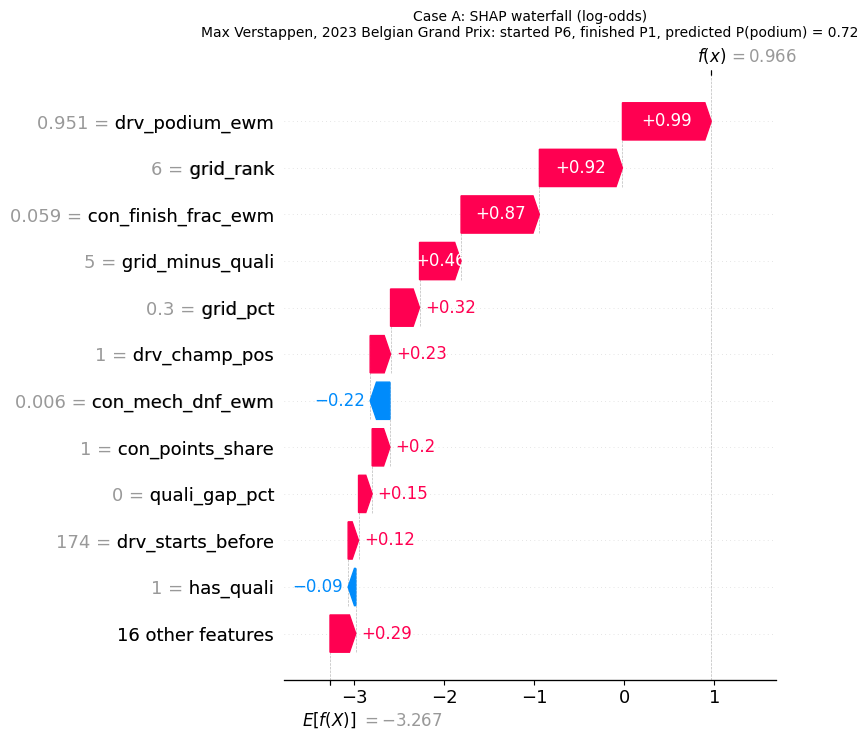

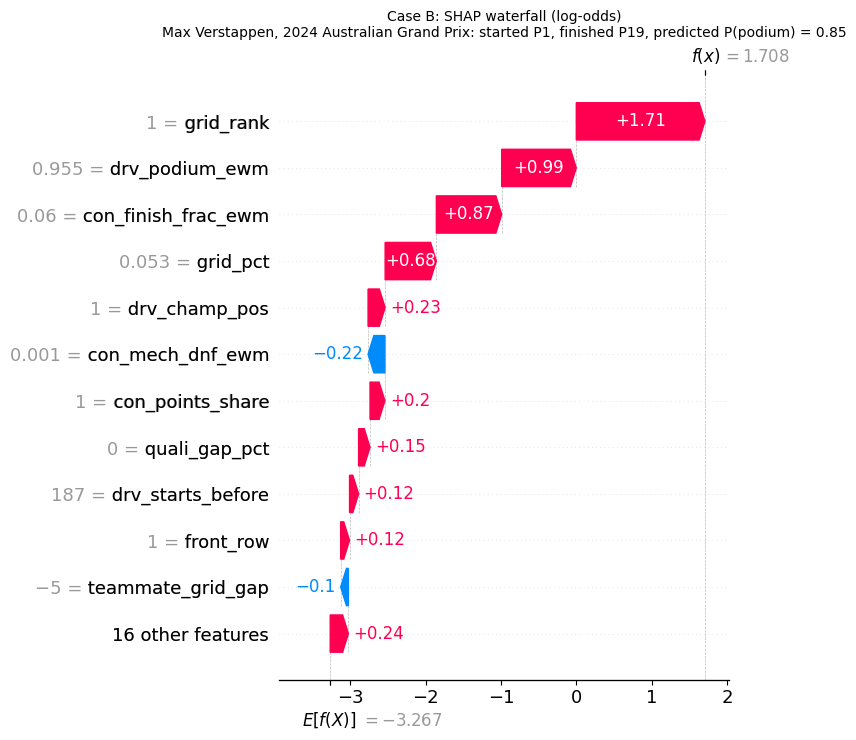

In [201]:
for k, idx in CASES.items():
    xt = lr_prep.transform(X["test"].loc[[idx]])
    e = lin_explainer(xt)[0]
    e.data = X["test"].loc[idx, list(xt.columns)].to_numpy()   # real feature values on the plot
    plt.figure()
    shap.plots.waterfall(e, max_display=12, show=False)
    plt.title(f"Case {k}: SHAP waterfall (log-odds)\n{describe(idx)}", fontsize=10)
    plt.tight_layout()
    plt.show()

**LIME setup.** LIME explains one prediction by generating thousands of slightly changed copies of the driver's row, asking the model to score them, and fitting a small weighted linear model to those answers. How the copies are generated matters a lot here, so two settings were compared on the two cases. The table shows how well LIME's small model reproduces the real model near the driver (**local R²**, and its prediction against the model's):
- **Binned (LIME default):** each feature is cut into quartiles of the training data, and copies are drawn from those bins over all eras.
- **Continuous, around the driver:** copies are drawn as small changes around the driver's own values, then clipped to the range seen in training (so no impossible values like negative career starts).

model P(podium)  \
LIME setting                         case                    
binned (LIME default)                A               0.724   
                                     B               0.847   
continuous, around the driver (used) A               0.724   
                                     B               0.847   

                                           LIME local prediction  local R²  \
LIME setting                         case                                    
binned (LIME default)                A                     0.300     0.523   
                                     B                     0.258     0.567   
continuous, around the driver (used) A                     0.602     0.858   
                                     B                     0.672     0.701   

                                                                              top 4 features  
LIME setting                         case                                                     
binned (LIME default)                A     grid_rank, is_pit_start, grid_minus_quali, con...  
                                     B     grid_rank, con_finish_frac_ewm, grid_pct, is_p...  
continuous, around the driver (used) A     grid_rank, grid_pct, con_finish_frac_ewm, drv_...  
                                     B     grid_rank, con_finish_frac_ewm, grid_pct, drv_...

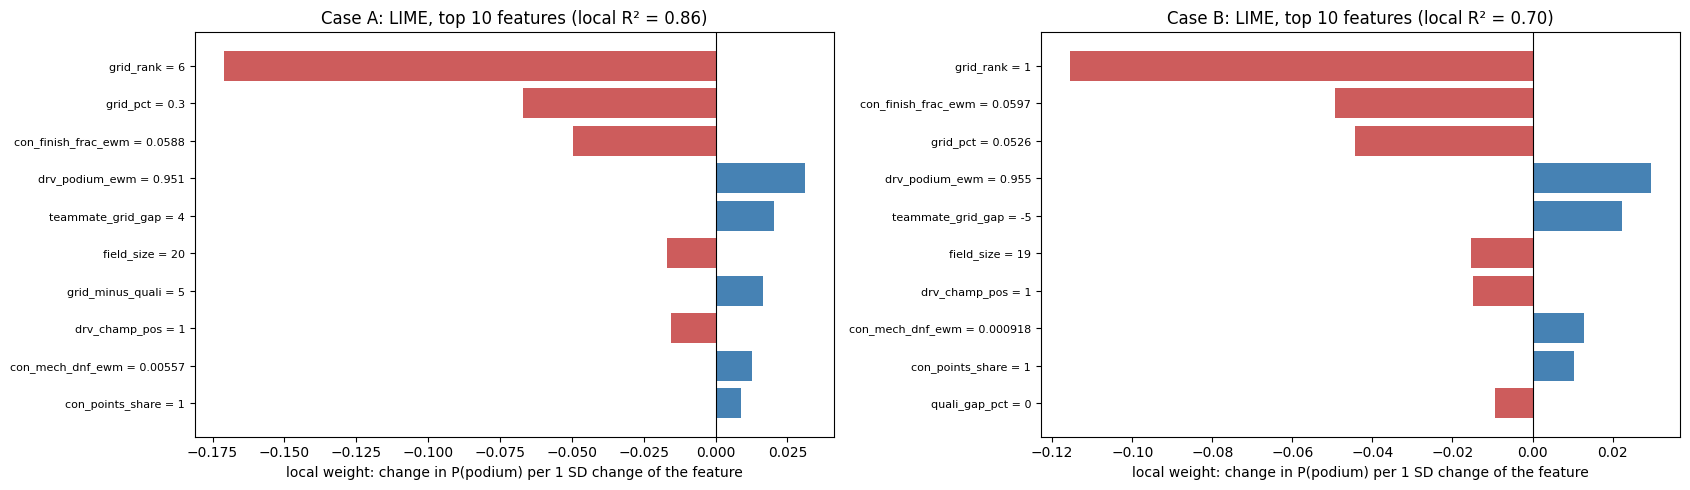

In [202]:
# LIME needs complete training data: the training rows after the pipeline's two imputers (unscaled)
lime_train = lr_prep[:2].transform(X["train"])[FEATURES]
lo, hi = lime_train.min().to_numpy(), lime_train.max().to_numpy()
# keep LIME's random copies inside the observed range of every feature
predict_fn = lambda arr: final_model.predict_proba(pd.DataFrame(np.clip(arr, lo, hi), columns=FEATURES))
case_rows = {k: lr_prep[:2].transform(X["test"].loc[[idx]])[FEATURES].iloc[0] for k, idx in CASES.items()}

settings = {"binned (LIME default)": dict(discretize_continuous=True),
            "continuous, around the driver (used)": dict(discretize_continuous=False, sample_around_instance=True)}
fidelity, LIME = [], {}
for name, cfg in settings.items():
    explainer = LimeTabularExplainer(lime_train.to_numpy(), feature_names=FEATURES, class_names=["no podium", "podium"],
                                     mode="classification", random_state=0, **cfg)
    for k, idx in CASES.items():
        exp = explainer.explain_instance(case_rows[k].to_numpy(), predict_fn, num_features=10, num_samples=5000)
        fidelity.append({"LIME setting": name, "case": k, "model P(podium)": test_rows.loc[idx, "p"],
                         "LIME local prediction": exp.local_pred[0], "local R²": exp.score,
                         "top 4 features": ", ".join(f.split(" ")[0] if "<" not in f.split(" ")[0] else f for f, _ in exp.as_list()[:4])})
        if "used" in name:
            LIME[k] = exp
display(pd.DataFrame(fidelity).set_index(["LIME setting", "case"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, (k, exp) in zip(axes, LIME.items()):
    w = pd.Series(dict(exp.as_list()))
    labels = [f"{f} = {case_rows[k][f]:.3g}" for f in w.index]
    w = pd.Series(w.values, index=labels).iloc[::-1]
    ax.barh(w.index, w.values, color=np.where(w.values > 0, "steelblue", "indianred"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=f"Case {k}: LIME, top 10 features (local R² = {exp.score:.2f})",
           xlabel="local weight: change in P(podium) per 1 SD change of the feature")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Local explanations — findings**

**Case A: Verstappen, Belgium 2023 (started P6, won; model 0.72).** He set the fastest qualifying time but took a 5-place gearbox penalty. The SHAP waterfall shows why the model still believed in him:
- **Driver form +0.98** (podium in 95% of recent races) and **team finishing form +0.89**.
- **Grid rank +0.94:** P6 is still well above the average starter.
- **`grid_minus_quali` = +5, contributing +0.47:** the model reads "lost 5 places to a penalty" as a sign of a fast car out of position, exactly the effect found in 4.2.

**Case B: Verstappen, Australia 2024 (pole, retired with a mechanical failure; model 0.85).** The explanation is almost all grid (+1.74 for pole) plus the same form features. Nothing before the race pointed to a failure: his team's recent mechanical-failure rate was 0.1%, among the lowest in the data. This is the "race-day chaos" limitation from 6.8.3.

**LIME vs SHAP:**
- **Fidelity:** with LIME's default (binned) setting, its small local model reproduced the real prediction badly (0.31 vs 0.72, local R² 0.53), so its explanation could not be trusted. Sampling around the driver raised the fit to R² 0.86 / 0.70, close enough to read.
- **They agree on which features matter:** grid rank, grid share, team finishing form and driver podium form are LIME's top four in both cases, the same as SHAP's.
- **They answer different questions, so the signs can differ.** SHAP says what each feature *contributed compared to an average driver* (P6 is better than average, so grid rank is positive). LIME says *what would happen if the feature changed a little* (starting further back than P6 lowers the chance, so its weight is negative). Both are consistent with the same model; they are just different questions.

### Section 8 summary
- **What the model relies on:** first the **starting position** (grid rank and grid share), then **recent form** of the team and the driver. Standings add a little; the other groups add almost nothing once those are known. Permutation importance, SHAP, the random forest and LIME all agree on this top group.
- **Global and local tell the same story:** Verstappen from P6 at Spa was predicted to podium because of form plus a penalty-shifted grid slot; Verstappen from pole in Melbourne was predicted to podium because of pole plus form, and lost it to a failure no pre-race feature could see.
- **What these explanations do not show: causes.** Each method describes how *this model* turns inputs into a prediction. Grid position, form and standings are all consequences of having a fast car and a good driver, so their importance says the model *uses* them, not that they *make* a driver finish on the podium. The positive weight on mechanical failures (8.2) shows how a feature can look important for purely statistical reasons. **Importance is not causation.**

# 9. Inference function
`predict_podium(record)` answers the project's question for **one driver before one race**: it takes the driver's pre-race information as a dictionary and returns the probability of a podium and a yes/no decision.

**How it works:**
1. **Check the input.** Unknown field names raise an error (a typo should not be silently ignored), and every value must be a number or missing.
2. **Derive what can be derived exactly.** If `grid_rank` and `field_size` are given, `grid_pct` (= rank / field size) and `front_row` (= rank ≤ 2) are computed, not guessed.
3. **Fill the rest with the fitted pipeline.** Any missing feature becomes NaN and goes through the same pipeline as in training: the qualifying gap is filled with the median of the driver's grid band, everything else with the training median (section 5). Nothing is refitted; all statistics come from the training seasons.
4. **Predict** with the final model (**logistic regression (tuned)**) and apply the threshold chosen on validation in 6.1.

The output also lists **which features were filled and with what value**, so a prediction from incomplete data is never mistaken for one from complete data.

In [203]:
def predict_podium(record, model=final_model, threshold=final_threshold, features=FEATURES):
    # Pre-race podium prediction for one driver in one race.
    #   record: dict {feature name: value}; any feature may be missing or None.
    # Returns: probability, yes/no at the validation-chosen threshold, and the features that had to be filled.
    unknown = set(record) - set(features)
    if unknown:
        raise ValueError(f"unknown feature(s): {sorted(unknown)}")
    row = {f: (np.nan if record.get(f) is None else record[f]) for f in features}
    bad = {f: v for f, v in row.items() if not isinstance(v, (int, float, np.integer, np.floating, bool, np.bool_))}
    if bad:
        raise TypeError(f"non-numeric value(s): {bad}")

    # exact derivations before any imputation
    derived = {}
    if not np.isnan(row["grid_rank"]) and not np.isnan(row["field_size"]):
        if np.isnan(row["grid_pct"]):
            row["grid_pct"] = derived["grid_pct"] = row["grid_rank"] / row["field_size"]
        if np.isnan(row["front_row"]):
            row["front_row"] = derived["front_row"] = int(row["grid_rank"] <= 2)

    x = pd.DataFrame([row], columns=features).astype(float)
    missing = [f for f in features if np.isnan(x.loc[0, f])]
    filled = model.named_steps["prep"][:2].transform(x)          # the pipeline's own imputers (fitted on train)
    p = float(model.predict_proba(x)[0, 1])
    return {"P(podium)": round(p, 4),
            "prediction": "podium" if p >= threshold else "no podium",
            "threshold": round(float(threshold), 4),
            "derived": {k: round(float(v), 4) for k, v in derived.items()},
            "imputed": {f: round(float(filled.loc[0, f]), 4) for f in missing}}

## 9.1 Demo 1: a complete record
A real test-season row with every feature present: Verstappen at the 2023 Belgian Grand Prix (case A in 8.3: fastest in qualifying, 5-place penalty, started P6, won). The function's output must equal the model's prediction for that row in the test set, which is checked with an assert.

In [204]:
complete = {f: model_table.loc[case_a, f] for f in FEATURES}
complete = {f: (None if pd.isna(v) else float(v)) for f, v in complete.items()}
print("input:", {k: round(v, 3) for k, v in complete.items() if v is not None})
out_complete = predict_podium(complete)
display(out_complete)

assert abs(out_complete["P(podium)"] - final_model.predict_proba(X["test"].loc[[case_a]])[0, 1]) < 1e-4
assert not out_complete["imputed"], "a complete record should need no imputation"
print("matches the model's test-set prediction for this row ✓")

input: {'grid_rank': 6.0, 'grid_pct': 0.3, 'field_size': 20.0, 'front_row': 0.0, 'is_pit_start': 0.0, 'quali_gap_pct': 0.0, 'grid_minus_quali': 5.0, 'has_quali': 1.0, 'drv_points_share': 1.0, 'con_points_share': 1.0, 'drv_champ_pos': 1.0, 'con_champ_pos': 1.0, 'drv_podium_ewm': 0.951, 'drv_finish_frac_ewm': 0.071, 'con_podium_ewm': 0.973, 'con_finish_frac_ewm': 0.059, 'con_mech_dnf_ewm': 0.006, 'drv_incident_ewm': 0.001, 'drv_circuit_visits': 8.0, 'drv_circuit_last_finish': 0.05, 'drv_circuit_avg_finish': 0.41, 'drv_starts_before': 174.0, 'age': 25.829, 'teammate_grid_gap': 4.0, 'has_teammate': 1.0, 'is_home_race': 0.0, 'season_progress': 0.545}


{'P(podium)': 0.7243,
 'prediction': 'podium',
 'threshold': 0.2511,
 'derived': {},
 'imputed': {}}

matches the model's test-set prediction for this row ✓


## 9.2 Demo 2: a partially-missing record
The same driver and race, but as a data feed might deliver it before the race: the **qualifying gap**, **all four championship-standings features** and `grid_pct` / `front_row` are missing. The function derives `grid_pct` and `front_row` exactly from the grid, and fills the qualifying gap and standings through the pipeline.

In [205]:
DROP = ["quali_gap_pct", "drv_points_share", "con_points_share", "drv_champ_pos", "con_champ_pos", "grid_pct", "front_row"]
partial = {f: v for f, v in complete.items() if f not in DROP}
print("missing fields:", DROP)
out_partial = predict_podium(partial)
display(out_partial)

compare_cols = [f for f in out_partial["imputed"]]
display(pd.DataFrame({"real value": {f: complete[f] for f in compare_cols},
                      "filled with": out_partial["imputed"]}).round(3))
print(f"P(podium): complete record {out_complete['P(podium)']:.3f} → partially-missing record {out_partial['P(podium)']:.3f}")

missing fields: ['quali_gap_pct', 'drv_points_share', 'con_points_share', 'drv_champ_pos', 'con_champ_pos', 'grid_pct', 'front_row']


{'P(podium)': 0.5897,
 'prediction': 'podium',
 'threshold': 0.2511,
 'derived': {'grid_pct': 0.3, 'front_row': 0.0},
 'imputed': {'quali_gap_pct': 0.9316,
  'drv_points_share': 0.0469,
  'con_points_share': 0.1153,
  'drv_champ_pos': 13.0,
  'con_champ_pos': 6.0}}

,real value,filled with
quali_gap_pct,0.0,0.932
drv_points_share,1.0,0.047
con_points_share,1.0,0.115
drv_champ_pos,1.0,13.000
con_champ_pos,1.0,6.000


P(podium): complete record 0.724 → partially-missing record 0.590


## 9.3 Demo 3: only the grid is known
The least information the function accepts in practice: grid slot and field size only. Every form, standings, reliability and history feature is filled with its training median, i.e. "an average driver in an average car". The prediction then rests almost entirely on the starting position, which shows how much of the answer in 9.1 came from the driver's form and car rather than from P6 itself.

{'P(podium)': 0.1142, 'prediction': 'no podium', 'threshold': 0.2511, 'derived': {'grid_pct': 0.3, 'front_row': 0.0}}
22 features imputed


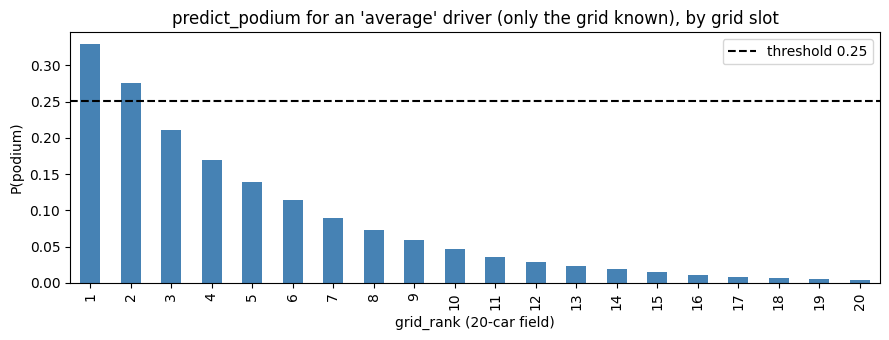

In [206]:
grid_only = {"grid_rank": 6, "field_size": 20, "is_pit_start": 0}
out_grid = predict_podium(grid_only)
print({k: v for k, v in out_grid.items() if k != "imputed"})
print(f"{len(out_grid['imputed'])} features imputed")

# the same 'average driver' from every grid slot
curve = pd.Series({g: predict_podium({"grid_rank": g, "field_size": 20, "is_pit_start": 0})["P(podium)"] for g in range(1, 21)})
fig, ax = plt.subplots(figsize=(9, 3.5))
curve.plot(kind="bar", ax=ax, color="steelblue")
ax.axhline(final_threshold, color="black", ls="--", label=f"threshold {final_threshold:.2f}")
ax.set(title="predict_podium for an 'average' driver (only the grid known), by grid slot",
       xlabel="grid_rank (20-car field)", ylabel="P(podium)")
ax.legend()
plt.tight_layout()
plt.show()

## 9.4 Input checks
A typo in a field name or a text value is rejected with a clear message instead of being silently treated as missing.

In [207]:
for bad in [{"grid_rnk": 3}, {"grid_rank": "P3"}]:
    try:
        predict_podium(bad)
    except (ValueError, TypeError) as err:
        print(f"{bad} → {type(err).__name__}: {err}")

{'grid_rnk': 3} → ValueError: unknown feature(s): ['grid_rnk']
{'grid_rank': 'P3'} → TypeError: non-numeric value(s): {'grid_rank': 'P3'}


**Inference — findings**
- **Complete record (9.1):** Verstappen at Spa 2023 gets **P(podium) = 0.72 → "podium"**. That is exactly the model's prediction for the same row in the test set (checked by assert), so the function and the evaluated model are the same thing. He won the race.
- **Partially-missing record (9.2):** with the qualifying gap and all standings missing, the function still returns a prediction: **0.59 → "podium"**.
  - `grid_pct` and `front_row` were **derived exactly** from the grid, not imputed.
  - The **qualifying gap** was filled with 0.93%, the median gap of a P4–6 starter (grid-band imputation, 5.1). His real gap was 0.00%, since he set pole time.
  - **Standings** were filled with training medians (13th place, about 5% of the leader's points). In reality he was leading the championship.
  - Because those fills describe a typical driver, the probability drops from 0.72 to 0.59. His recent form (podium in 95% of recent races) still carries the prediction over the threshold. The `imputed` list in the output shows exactly what was guessed and with what value.
- **Only the grid known (9.3):** 22 of 27 features are imputed, and P6 gives only 0.11. Even pole gives only 0.33, well below the real pole podium rate (about 63% in training, 4.1).
  - **This is a known limitation of median imputation:** the median training driver has almost no recent podiums and few points, so every missing feature is filled with "an average midfield car". With little real information the function is therefore **conservative**: it under-predicts front-runners rather than over-predicting back-markers.
  - **Practical rule:** the more of the form and standings features a record has, the more its probability can be trusted. The `imputed` field tells the user how much was guessed.
- **Input checks (9.4):** a misspelt field (`grid_rnk`) or a text value (`"P3"`) raises a clear error instead of being treated as missing.